In [3]:
import numpy as np
import time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from tabulate import tabulate
from matplotlib.ticker import MultipleLocator


import os
from Algoritmo_Gaussiano.cpd import CPD
from Algoritmo_Empiricas.Empirical_CPD import EmpiricalCPD
from Series_Prueba.periodical_data import generar_series_pc, next_prob, serie_pc
from Utils.detection import detect
from Utils.metrics_sup import metrics
from Utils.tools import best_params_sh
from Series_Prueba.experimentos import generar_experimento_ar1, generar_experimento_ar2, generar_experimento_senoidal, ar2_noise

# Funciones Auxiliares

## Suavizamiento Prueba

In [2]:
def triangular_smooth(distancias, window):
    y = np.asarray(distancias, dtype=np.float64)


    offsets = np.arange(
        -window,
        window + 1
    )

    kernel = np.maximum(
        1.0 - np.abs(offsets) / window,
        0.0
    )

    kernel = kernel / kernel.sum()

    padded = np.pad(
        y,
        pad_width=window,
        mode="reflect"
    )

    smoothed = np.convolve(
        padded,
        kernel,
        mode="valid"
    )

    return smoothed

## Gráficas y Tablas

In [28]:
def generar_tabla_desde_diccionarios(
    lista_dicts,
    lista_nombres,
    columnas_keys,
    nombre_columna_id="Method"
):
    """
    Genera una tabla con una fila por método.

    Cada elemento de lista_dicts debe ser una lista de diccionarios
    con las mismas llaves. Para cada columna se calcula el promedio
    de los valores encontrados en dichos diccionarios.
    """

    filas = []

    for nombre, diccionarios in zip(
        lista_nombres,
        lista_dicts
    ):
        fila = {
            nombre_columna_id: nombre
        }

        for columna in columnas_keys:
            valores = [
                diccionario.get(
                    columna,
                    np.nan
                )
                for diccionario in diccionarios
            ]

            valores = pd.to_numeric(
                pd.Series(valores),
                errors="coerce"
            )

            fila[columna] = (
                valores.mean()
                if valores.notna().any()
                else np.nan
            )

        filas.append(fila)

    return pd.DataFrame(filas)

In [2]:
def grafica_comparativa_wasserstein_serie(comparaciones, title):
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(16, 10)
    )

    axes = axes.flatten()

    for ax, (
        serie,
        wasserstein,
        window,
        titulo,
        cps_originales,
        cps_detectados
    ) in zip(axes, comparaciones):

        serie = np.asarray(
            serie,
            dtype=np.float64
        )

        wasserstein = np.asarray(
            wasserstein,
            dtype=np.float64
        )

        cps_originales = np.atleast_1d(
            cps_originales
        )

        cps_detectados = np.atleast_1d(
            cps_detectados
        )

        # Índices de la serie original
        x_serie = np.arange(len(serie))

        # Correspondencia de Wasserstein con la serie original
        x_wasserstein = (
            np.arange(len(wasserstein))
            + window
        )

        # Segundo eje vertical
        ax_wasserstein = ax.twinx()

        ax.plot(
            x_serie,
            serie,
            color="#2878B5",
            linewidth=1.2,
            alpha=0.75,
            label="Serie original"
        )

        ax_wasserstein.plot(
            x_wasserstein,
            wasserstein,
            color="#E87500",
            linewidth=2.2,
            alpha=0.9,
            label="Distancia de Wasserstein"
        )

        # Puntos de cambio originales
        for i, cp in enumerate(cps_originales):
            ax.axvline(
                x=cp,
                color="#C62828",
                linestyle="--",
                linewidth=2.2,
                alpha=0.85,
                label=(
                    "Punto de cambio real"
                    if i == 0
                    else None
                )
            )

        # Puntos de cambio detectados
        for i, cp in enumerate(cps_detectados):
            ax.axvline(
                x=cp,
                color="#2E7D32",
                linestyle=":",
                linewidth=2.4,
                alpha=0.95,
                label=(
                    "Punto de cambio detectado"
                    if i == 0
                    else None
                )
            )

        ax.set_title(
            titulo,
            fontsize=13,
            fontweight="bold"
        )

        ax.set_xlabel("Índice temporal")

        ax.set_ylabel(
            "Serie de tiempo",
            color="#2878B5"
        )

        ax_wasserstein.set_ylabel(
            "Distancia de Wasserstein",
            color="#E87500"
        )

        ax.tick_params(
            axis="y",
            labelcolor="#2878B5"
        )

        ax_wasserstein.tick_params(
            axis="y",
            labelcolor="#E87500"
        )

        ax.set_xlim(
            0,
            len(serie) - 1
        )

        ax.grid(
            alpha=0.25,
            linestyle="--"
        )

        # Combinar las leyendas de ambos ejes
        handles_serie, labels_serie = (
            ax.get_legend_handles_labels()
        )

        handles_wasserstein, labels_wasserstein = (
            ax_wasserstein.get_legend_handles_labels()
        )

        ax.legend(
            handles_serie + handles_wasserstein,
            labels_serie + labels_wasserstein,
            frameon=True,
            fontsize=9,
            loc="best"
        )

    # Ocultar cuadros sobrantes si se proporcionan menos de cuatro
    for ax in axes[len(comparaciones):]:
        ax.set_visible(False)

    fig.suptitle(
        title,
        fontsize=17,
        fontweight="bold",
        y=0.99
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.96]
    )

    plt.show()

In [3]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_boxplots(
    datos,
    nombres,
    titulo=None,
    ylabel="Value",
    xlabel="Method",
    figsize=(8.4, 4.8),
    palette=None,
    hatches=None,
    show_points=True,
    point_size=16,
    point_alpha=0.50,
    jitter=0.04,
    ylim=None,
    separator_after=2,
    save_path=None,
    dpi=300,
    show=True
):
    """
    Genera diagramas de caja con observaciones individuales y
    formato apropiado para un artículo académico.

    Parameters
    ----------
    datos : list of array-like
        Lista que contiene las observaciones de cada método.

    nombres : list of str
        Nombres que aparecerán en el eje horizontal.

    titulo : str or None
        Título de la figura. Para artículos puede dejarse en None
        y utilizar únicamente el caption de LaTeX.

    ylabel : str
        Etiqueta del eje vertical.

    xlabel : str or None
        Etiqueta del eje horizontal.

    figsize : tuple
        Tamaño de la figura en pulgadas.

    palette : list, dict or None
        Colores de las cajas. Si es una lista, debe contener un color
        por método. Si es un diccionario, las claves deben coincidir
        con los nombres suministrados.

    hatches : list or None
        Patrones opcionales para distinguir cajas en impresión
        monocromática.

    show_points : bool
        Indica si se muestran las observaciones individuales.

    point_size : float
        Tamaño de las observaciones individuales.

    point_alpha : float
        Transparencia de las observaciones individuales.

    jitter : float
        Desplazamiento horizontal aleatorio de los puntos.

    ylim : tuple or None
        Límites del eje vertical.

    separator_after : int or None
        Añade una separación visual después del método indicado.
        Con separator_after=2 se separan los métodos optimizados
        de los métodos evaluados con ventana fija.

    save_path : str or None
        Ruta para guardar la figura. Se recomienda usar PDF.

    dpi : int
        Resolución utilizada al guardar formatos ráster.

    show : bool
        Indica si la figura se muestra inmediatamente.

    Returns
    -------
    fig, ax
        Figura y eje de Matplotlib.
    """

    if len(datos) != len(nombres):
        raise ValueError(
            "The number of datasets must match the number of labels."
        )

    # ---------------------------------------------------------
    # Limpieza de los datos
    # ---------------------------------------------------------
    datos_limpios = []
    nombres_validos = []
    indices_validos = []

    for indice, (valores, nombre) in enumerate(
        zip(datos, nombres)
    ):
        arr = pd.to_numeric(
            pd.Series(valores),
            errors="coerce"
        ).to_numpy(dtype=float)

        arr = arr[np.isfinite(arr)]

        if arr.size == 0:
            warnings.warn(
                f"Dataset '{nombre}' contains no valid observations."
            )
            continue

        datos_limpios.append(arr)
        nombres_validos.append(nombre)
        indices_validos.append(indice)

    if not datos_limpios:
        raise ValueError(
            "No valid observations are available for plotting."
        )

    # ---------------------------------------------------------
    # Paleta recomendada
    # ---------------------------------------------------------
    default_colors = [
        "#2A9D8F",  # Gaussian optimizado
        "#4C72B0",  # Empirical optimizado
        "#9FD3C7",  # Gaussian con ventana fija
        "#AFC1DE",  # Empirical con ventana fija
        "#D9A441",  # Roerich-KL
        "#9E9E9E"   # Window-RBF
    ]

    if palette is None:
        colores = [
            default_colors[i % len(default_colors)]
            for i in indices_validos
        ]

    elif isinstance(palette, dict):
        colores = [
            palette.get(
                nombre,
                default_colors[j % len(default_colors)]
            )
            for j, nombre in enumerate(nombres_validos)
        ]

    else:
        if len(palette) < len(datos):
            raise ValueError(
                "The palette must contain one color "
                "for each dataset."
            )

        colores = [
            palette[i]
            for i in indices_validos
        ]

    # Patrones opcionales para impresión en escala de grises.
    if hatches is None:
        patrones = [""] * len(datos_limpios)
    else:
        if len(hatches) < len(datos):
            raise ValueError(
                "The hatches list must contain one value "
                "for each dataset."
            )

        patrones = [
            hatches[i]
            for i in indices_validos
        ]

    # ---------------------------------------------------------
    # Estilo general
    # ---------------------------------------------------------
    style = {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.labelsize": 10.5,
        "axes.titlesize": 11.5,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 9.5
    }

    with plt.rc_context(style):

        fig, ax = plt.subplots(
            figsize=figsize,
            constrained_layout=True
        )

        positions = np.arange(
            1,
            len(datos_limpios) + 1
        )

        # -----------------------------------------------------
        # Diagramas de caja
        # -----------------------------------------------------
        bp = ax.boxplot(
            datos_limpios,
            positions=positions,
            patch_artist=True,
            widths=0.52,
            whis=1.5,
            showfliers=not show_points,
            medianprops={
                "color": "#202020",
                "linewidth": 1.7
            },
            whiskerprops={
                "color": "#404040",
                "linewidth": 1.1
            },
            capprops={
                "color": "#404040",
                "linewidth": 1.1
            },
            boxprops={
                "edgecolor": "#404040",
                "linewidth": 1.1
            },
            flierprops={
                "marker": "o",
                "markersize": 3.5,
                "markerfacecolor": "#A0A0A0",
                "markeredgecolor": "#404040",
                "markeredgewidth": 0.4,
                "alpha": 0.55
            }
        )

        rng = np.random.default_rng(42)

        for i, (
            valores,
            color,
            patron
        ) in enumerate(
            zip(
                datos_limpios,
                colores,
                patrones
            ),
            start=1
        ):
            box = bp["boxes"][i - 1]

            box.set_facecolor(color)
            box.set_alpha(0.65)
            box.set_hatch(patron)
            box.set_zorder(2)

            if show_points:
                x = i + rng.uniform(
                    -jitter,
                    jitter,
                    size=valores.size
                )

                ax.scatter(
                    x,
                    valores,
                    s=point_size,
                    color=color,
                    alpha=point_alpha,
                    edgecolor="#303030",
                    linewidth=0.35,
                    zorder=3
                )

        # Las medianas quedan por encima de los puntos.
        for median in bp["medians"]:
            median.set_zorder(4)

        # -----------------------------------------------------
        # Ejes y etiquetas
        # -----------------------------------------------------
        ax.set_xticks(positions)
        ax.set_xticklabels(nombres_validos)

        if xlabel is not None:
            ax.set_xlabel(
                xlabel,
                labelpad=7
            )

        ax.set_ylabel(
            ylabel,
            labelpad=7
        )

        if titulo:
            ax.set_title(
                titulo,
                pad=10,
                fontweight="semibold"
            )

        if ylim is not None:
            ax.set_ylim(ylim)

        ax.set_xlim(
            0.5,
            len(datos_limpios) + 0.5
        )

        # Separación entre métodos optimizados y ventana fija.
        if (
            separator_after is not None
            and 0 < separator_after < len(datos_limpios)
        ):
            ax.axvline(
                x=separator_after + 0.5,
                color="#BDBDBD",
                linestyle=":",
                linewidth=0.9,
                alpha=0.85,
                zorder=0
            )

        # -----------------------------------------------------
        # Cuadrícula y bordes
        # -----------------------------------------------------
        ax.set_axisbelow(True)

        ax.grid(
            axis="y",
            color="#D8D8D8",
            linestyle="--",
            linewidth=0.7,
            alpha=0.65
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.spines["left"].set_color("#555555")
        ax.spines["bottom"].set_color("#555555")

        ax.spines["left"].set_linewidth(0.8)
        ax.spines["bottom"].set_linewidth(0.8)

        ax.tick_params(
            axis="both",
            width=0.8,
            color="#555555"
        )

        # -----------------------------------------------------
        # Guardado y visualización
        # -----------------------------------------------------
        if save_path is not None:
            fig.savefig(
                save_path,
                dpi=dpi,
                bbox_inches="tight",
                facecolor="white"
            )

        if show:
            plt.show()

    return fig, ax

## Algoritmos de Comparación

In [4]:
import numpy as np
import ruptures as rpt

from scipy.signal import find_peaks


def detectar_window_rbf(
    serie,
    window=50,
    prominence_ratio=0.05
):
    """
    Window-RBF sobre la serie original, sin retardos
    y sin suavizamiento.

    La selección final utiliza prominencia estándar y
    una separación mínima determinada por window.
    """

    serie = np.asarray(
        serie,
        dtype=np.float64
    ).ravel()

    window = int(window)

    if window < 1:
        raise ValueError(
            "window debe ser un entero positivo."
        )

    if serie.size <= 2 * window:
        raise ValueError(
            "La longitud de la serie debe ser mayor "
            "que dos veces el tamaño de ventana."
        )

    if not np.all(np.isfinite(serie)):
        raise ValueError(
            "La serie contiene valores NaN o infinitos."
        )

    algorithm = rpt.Window(
        width=2 * window,
        model="rbf",
        min_size=2,
        jump=1
    ).fit(serie)

    score = np.asarray(
        algorithm.score,
        dtype=np.float64
    )

    q05, q95 = np.quantile(
        score,
        [0.05, 0.95]
    )

    robust_range = float(
        q95 - q05
    )

    if robust_range <= 0:
        return []

    prominence_threshold = (
        prominence_ratio
        * robust_range
    )

    peak_indices, _ = find_peaks(
        score,
        prominence=prominence_threshold,
        distance=window
    )

    # algorithm.inds contiene los índices originales
    # de la serie asociados con cada elemento del score.
    change_points = np.asarray(
        algorithm.inds,
        dtype=int
    )[peak_indices]

    return change_points.tolist()

In [5]:
from sklearn.linear_model import LogisticRegression
from roerich.change_point import ChangePointDetectionClassifier

def detectar_cambios_roerich(
    serie,
    window_size=None,
    seed=42,
    periods=3
):
    serie = np.asarray(
        serie,
        dtype=np.float64
    ).ravel()


    N = serie.size

    # Regla fija del 5 % utilizada en el artículo
    # comparativo. El mínimo de 5 garantiza que el
    # posprocesamiento interno sea numéricamente factible.
    if window_size is None:
        window_size = max(
            5,
            int(round(0.05 * N))
        )
    else:
        window_size = int(window_size)


    X = serie.reshape(-1, 1)

    np.random.seed(seed)

    clasificador = LogisticRegression(
        solver="lbfgs",
        max_iter=1000,
        random_state=seed
    )

    detector = ChangePointDetectionClassifier(
        base_classifier=clasificador,
        metric="klsym",
        periods=periods,
        window_size=window_size,
        step=1,
        n_runs=1
        )

    _, puntos_cambio = detector.predict(X)

    return np.asarray(
        puntos_cambio,
        dtype=int
    ).tolist()

# 1. Suavizamiento

## 1.1. Múltiples puntos de cambio

In [3]:
ar1_1, cps_ar1_1, segmentos_ar1_1 = generar_experimento_ar1(
            N=1500,
            n_segmentos=15,
            min_sep=50,
            max_sep=150,
            seed=1234
        )

ar1_2, cps_ar1_2, segmentos_ar1_2 = generar_experimento_ar1(
            N=1500,
            n_segmentos=15,
            min_sep=50,
            max_sep=150,
            seed=1235
        )


ar2_1, cps_ar2_1, segmentos_ar2_1 = generar_experimento_ar2(
            N=1500,
            n_segmentos=15,
            min_sep=50,
            max_sep=150,
            seed=1234
        )

ar2_2, cps_ar2_2, segmentos_ar2_2 = generar_experimento_ar2(
            N=1500,
            n_segmentos=15,
            min_sep=50,
            max_sep=150,
            seed=1235
        )

In [4]:
cpd_ar1_1 = CPD(ar1_1, window=50, t=1, smooth=True, temporal_comp=True)
cpd_ar1_2 = CPD(ar1_2, window=50, t=1, smooth=True, temporal_comp=True)
cpd_ar2_1 = CPD(ar2_1, window=50, t=1, smooth=True, temporal_comp=True)
cpd_ar2_2 = CPD(ar2_2, window=50, t=1, smooth=True, temporal_comp=True)

distancias_ar1_1_bspline = cpd_ar1_1.distancias()
distancias_ar1_2_bspline = cpd_ar1_2.distancias()
distancias_ar2_1_bspline = cpd_ar2_1.distancias()
distancias_ar2_2_bspline = cpd_ar2_2.distancias()

distancias_ar1_1 = cpd_ar1_1.distancias_raw_
distancias_ar1_2 = cpd_ar1_2.distancias_raw_
distancias_ar2_1 = cpd_ar2_1.distancias_raw_
distancias_ar2_2 = cpd_ar2_2.distancias_raw_

distancias_ar_1_1_filter_25 = triangular_smooth(distancias_ar1_1, 25)
distancias_ar_1_2_filter_25 = triangular_smooth(distancias_ar1_2, 25)
distancias_ar_2_1_filter_25 = triangular_smooth(distancias_ar2_1, 25)
distancias_ar_2_2_filter_25 = triangular_smooth(distancias_ar2_2, 25)

distancias_ar_1_1_filter_50 = triangular_smooth(distancias_ar1_1, 50)
distancias_ar_1_2_filter_50 = triangular_smooth(distancias_ar1_2, 50)
distancias_ar_2_1_filter_50 = triangular_smooth(distancias_ar2_1, 50)
distancias_ar_2_2_filter_50 = triangular_smooth(distancias_ar2_2, 50)


In [5]:
np.array_equal(distancias_ar1_2_bspline, distancias_ar_1_2_filter_25)

True

In [6]:
def grafica_comparativa_wasserstein(comparaciones, title):
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(16, 10)
    )

    axes = axes.flatten()

    for ax, (original, suavizada, window, titulo, cps) in zip(
        axes,
        comparaciones
    ):
        original = np.asarray(original)
        suavizada = np.asarray(suavizada)
        cps = np.atleast_1d(cps)

        # Posiciones correspondientes en la serie original
        x = np.arange(len(original)) + window

        ax.plot(
            x,
            original,
            color="#2878B5",
            linewidth=1.3,
            alpha=0.65,
            label="Distancia original"
        )

        ax.plot(
            x,
            suavizada,
            color="#E87500",
            linewidth=2.4,
            label="Suavizamiento triangular"
        )

        for i, cp in enumerate(cps):
            ax.axvline(
                x=cp,
                color="#C62828",
                linestyle="--",
                linewidth=1.8,
                alpha=0.85,
                label="Punto de cambio real" if i == 0 else None
            )

        ax.set_title(
            titulo,
            fontsize=13,
            fontweight="bold"
        )

        ax.set_xlabel("Índice temporal")
        ax.set_ylabel("Distancia de Wasserstein")

        ax.grid(
            alpha=0.25,
            linestyle="--"
        )

        ax.legend(
            frameon=True,
            fontsize=10
        )


    fig.suptitle(
        title,
        fontsize=17,
        fontweight="bold",
        y=1.01
    )

    plt.tight_layout()
    plt.show()

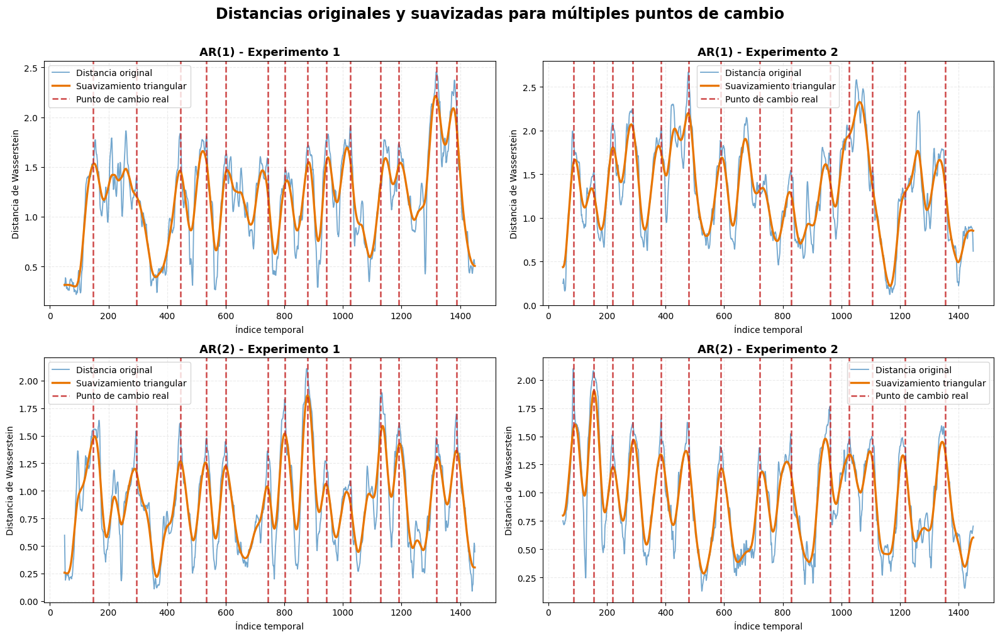

In [7]:
comparaciones = [
    (
        distancias_ar1_1,
        distancias_ar_1_1_filter_25,
        cpd_ar1_1.window,
        "AR(1) - Experimento 1",
        cps_ar1_1
    ),
    (
        distancias_ar1_2,
        distancias_ar_1_2_filter_25,
        cpd_ar1_2.window,
        "AR(1) - Experimento 2",
        cps_ar1_2
    ),
    (
        distancias_ar2_1,
        distancias_ar_2_1_filter_25,
        cpd_ar2_1.window,
        "AR(2) - Experimento 1",
        cps_ar2_1
    ),
    (
        distancias_ar2_2,
        distancias_ar_2_2_filter_25,
        cpd_ar2_2.window,
        "AR(2) - Experimento 2",
        cps_ar2_2
    )
]


grafica_comparativa_wasserstein(comparaciones, "Distancias originales y suavizadas para múltiples puntos de cambio")

## 1.2. Un punto de cambio

In [8]:
ar1_1_1cp, cps_ar1_1_1cp, segmentos_ar1_1_1cp = generar_experimento_ar1(
            N=500,
            n_segmentos=2,
            min_sep=100,
            max_sep=100,
            punto_cambio=250,
            seed=1234
        )

ar1_2_1cp, cps_ar1_2_1cp, segmentos_ar1_2_1cp = generar_experimento_ar1(
            N=500,
            n_segmentos=2,
            min_sep=100,
            max_sep=100,
            punto_cambio=250,
            seed=1235
        )


ar2_1_1cp, cps_ar2_1_1cp, segmentos_ar2_1_1cp = generar_experimento_ar2(
            N=500,
            n_segmentos=2,
            min_sep=100,
            max_sep=100,
            punto_cambio=250,
            seed=1234
        )

ar2_2_1cp, cps_ar2_2_1cp, segmentos_ar2_2_1cp = generar_experimento_ar2(
            N=500,
            n_segmentos=2,
            min_sep=100,
            max_sep=100,
            punto_cambio=250,
            seed=1235
        )

In [9]:
cpd_ar1_1_1cp = CPD(ar1_1_1cp, window=100, t=1, smooth=True, temporal_comp=True)
cpd_ar1_2_1cp = CPD(ar1_2_1cp, window=100, t=1, smooth=True, temporal_comp=True)
cpd_ar2_1_1cp = CPD(ar2_1_1cp, window=100, t=1, smooth=True, temporal_comp=True)
cpd_ar2_2_1cp = CPD(ar2_2_1cp, window=100, t=1, smooth=True, temporal_comp=True)

distancias_ar1_1_bspline_1cp = cpd_ar1_1_1cp.distancias()
distancias_ar1_2_bspline_1cp = cpd_ar1_2_1cp.distancias()
distancias_ar2_1_bspline_1cp = cpd_ar2_1_1cp.distancias()
distancias_ar2_2_bspline_1cp = cpd_ar2_2_1cp.distancias()

distancias_ar1_1_1cp = cpd_ar1_1_1cp.distancias_raw_
distancias_ar1_2_1cp = cpd_ar1_2_1cp.distancias_raw_
distancias_ar2_1_1cp = cpd_ar2_1_1cp.distancias_raw_
distancias_ar2_2_1cp = cpd_ar2_2_1cp.distancias_raw_



distancias_ar_1_1_filter_50_1cp = triangular_smooth(distancias_ar1_1_1cp, 50)
distancias_ar_1_2_filter_50_1cp = triangular_smooth(distancias_ar1_2_1cp, 50)
distancias_ar_2_1_filter_50_1cp = triangular_smooth(distancias_ar2_1_1cp, 50)
distancias_ar_2_2_filter_50_1cp = triangular_smooth(distancias_ar2_2_1cp, 50)


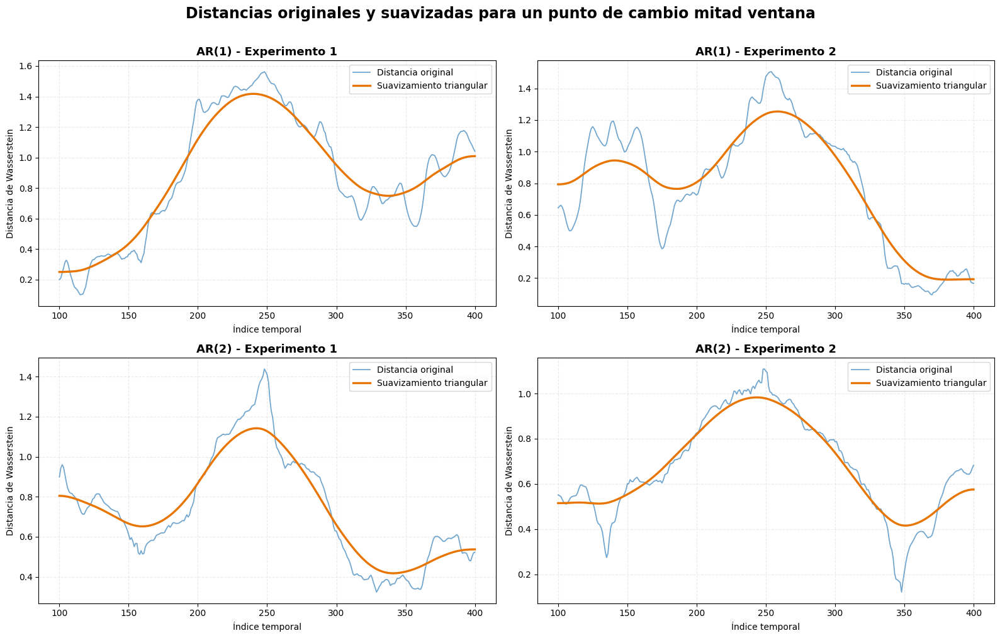

In [10]:
comparaciones = [
    (
        distancias_ar1_1_1cp,
        distancias_ar_1_1_filter_50_1cp,
        cpd_ar1_1_1cp.window,
        "AR(1) - Experimento 1"
    ),
    (
        distancias_ar1_2_1cp,
        distancias_ar_1_2_filter_50_1cp,
        cpd_ar1_2_1cp.window,
        "AR(1) - Experimento 2"
    ),
    (
        distancias_ar2_1_1cp,
        distancias_ar_2_1_filter_50_1cp,
        cpd_ar2_1_1cp.window,
        "AR(2) - Experimento 1"
    ),
    (
        distancias_ar2_2_1cp,
        distancias_ar_2_2_filter_50_1cp,
        cpd_ar2_2_1cp.window,
        "AR(2) - Experimento 2"
    )
]


fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10)
)

axes = axes.flatten()

for ax, (original, suavizada, window, titulo) in zip(
    axes,
    comparaciones
):
    original = np.asarray(original)
    suavizada = np.asarray(suavizada)

    # Posiciones correspondientes en la serie original
    x = np.arange(len(original)) + window

    ax.plot(
        x,
        original,
        color="#2878B5",
        linewidth=1.3,
        alpha=0.65,
        label="Distancia original"
    )

    ax.plot(
        x,
        suavizada,
        color="#E87500",
        linewidth=2.4,
        label="Suavizamiento triangular"
    )

    ax.set_title(
        titulo,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Índice temporal")
    ax.set_ylabel("Distancia de Wasserstein")

    ax.grid(
        alpha=0.25,
        linestyle="--"
    )

    ax.legend(
        frameon=True,
        fontsize=10
    )


fig.suptitle(
    "Distancias originales y suavizadas para un punto de cambio mitad ventana",
    fontsize=17,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# 2. Experimentos con Ventana Fija

## Funciones Auxiliares

In [6]:
import pandas as pd
from pathlib import Path

def exportar_excel(listas, ruta_archivo, hojas=["Hoja1", "Hoja2", "Hoja3", "Hoja4"]):

    ruta = Path(ruta_archivo)
    ruta.parent.mkdir(parents=True, exist_ok=True)

    with pd.ExcelWriter(ruta, engine="openpyxl") as writer:

        for i, lista in enumerate(listas):
            pd.DataFrame(lista).to_excel(
                writer, sheet_name=hojas[i], index=False
            )
        

## 2.1 AR(1)

### 2.1.1 Múltiples puntos de cambio

In [38]:
def experiment_ar1_temporal_dependence(w=50, delta=20):
    metricas_ar1_gauss_fw = []
    metricas_ar1_emp_fw = []
    metricas_ar1_roerich = []
    metricas_ar1_window_rbf = []

    for i in range(200):
        print(i)
        ar1, cps_ar1, segmentos_ar1 = generar_experimento_ar1(
                    N=2000,
                    n_segmentos=20,
                    min_sep=50,
                    max_sep=150,
                    seed=1234+i
                )
        
        #Gaussiano
        cpd_ar1 = CPD(ar1, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
        distancias_ar1 = cpd_ar1.distancias()
        cps_detect = detect(distancias_ar1, w)
        metricas_ar1_gauss_fw.append(metrics(cps_ar1, cps_detect, delta, 2000)[0])

        #Empírico
        cpd_ar1_emp = EmpiricalCPD(ar1, window=w, smooth=True)
        distancias_ar1_emp = cpd_ar1_emp.distancias()
        cps_detect_emp = detect(distancias_ar1_emp, w)
        metricas_ar1_emp_fw.append(metrics(cps_ar1, cps_detect_emp, delta, 2000)[0])

        #Roerich KL
        puntos_cambio = detectar_cambios_roerich(
                                        ar1,
                                        window_size=w,
                                        seed=42,
                                        periods=3
                                    )
        
        metricas_ar1_roerich.append(metrics(cps_ar1, puntos_cambio, delta, len(ar1))[0])

        #Window RBF
        puntos_cambio = detectar_window_rbf(
                                        ar1,
                                        window=w
                                    )
        
        metricas_ar1_window_rbf.append(metrics(cps_ar1, puntos_cambio, delta, len(ar1))[0])
        
    return metricas_ar1_gauss_fw, metricas_ar1_emp_fw, metricas_ar1_roerich, metricas_ar1_window_rbf

In [39]:
lists_metrics_ar1 = []
windows = [25, 30, 40, 50]
for w in windows:
    print(f'WINDOW SIZE: {w}')
    lists_metrics_ar1.append(experiment_ar1_temporal_dependence(w=w, delta=20))

WINDOW SIZE: 25
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
WINDOW SIZE: 30
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95


In [40]:
for metricas, w in zip(lists_metrics_ar1, windows):
    exportar_excel(metricas, f"Resultados_Series_Simuladas/AR(1)_Temporal_Dependency/Tables/ar1_metrics_window_{w}.xlsx", ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"])

WINDOW SIZE: 25


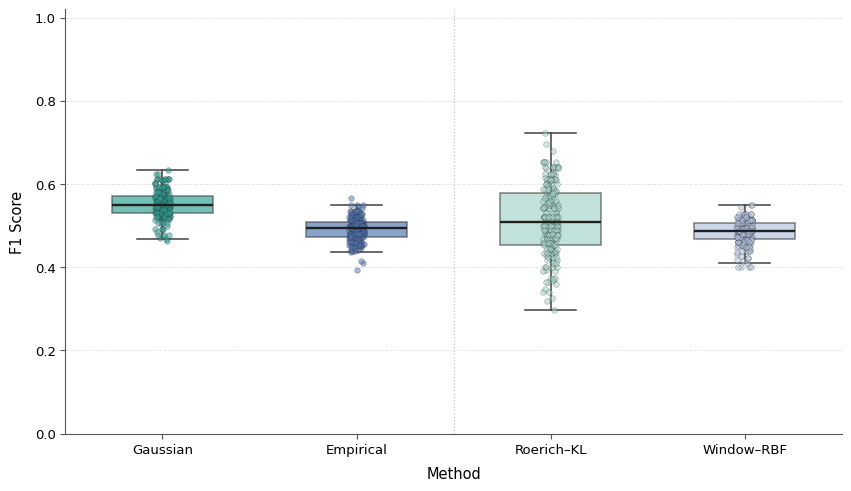

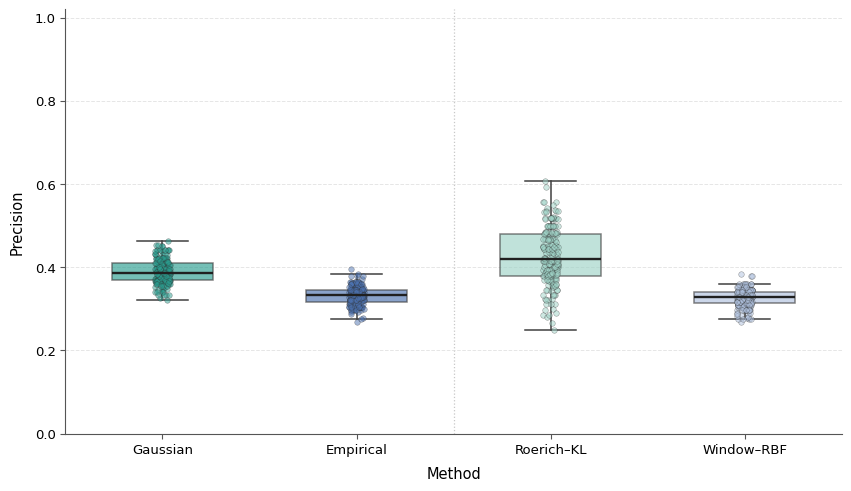

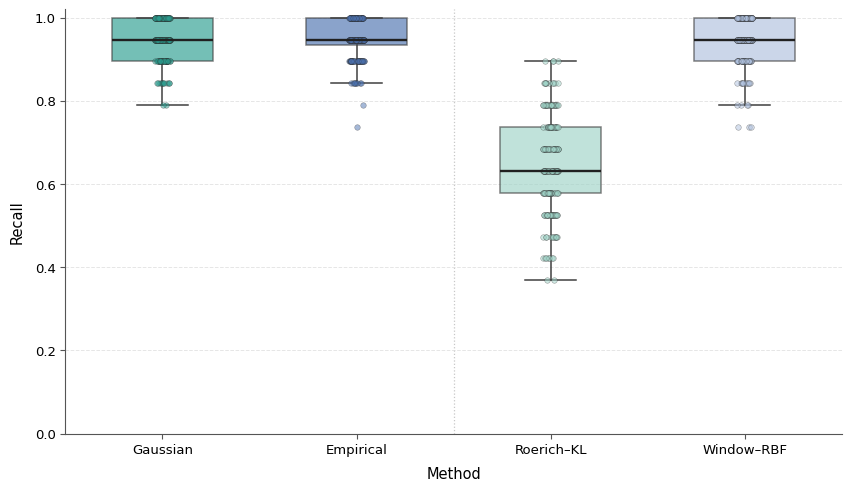

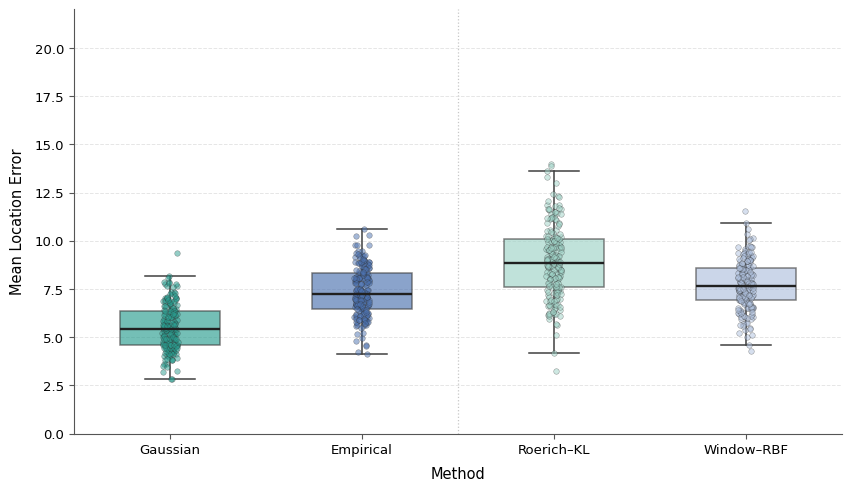

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.388860,0.948158,0.551098,5.496387
1,Empirical,0.331850,0.947895,0.491326,7.358144
2,Roerich-KL,0.425252,0.648421,0.512834,8.913747
3,Window-RBF,0.325518,0.945526,0.484134,7.707229


WINDOW SIZE: 30


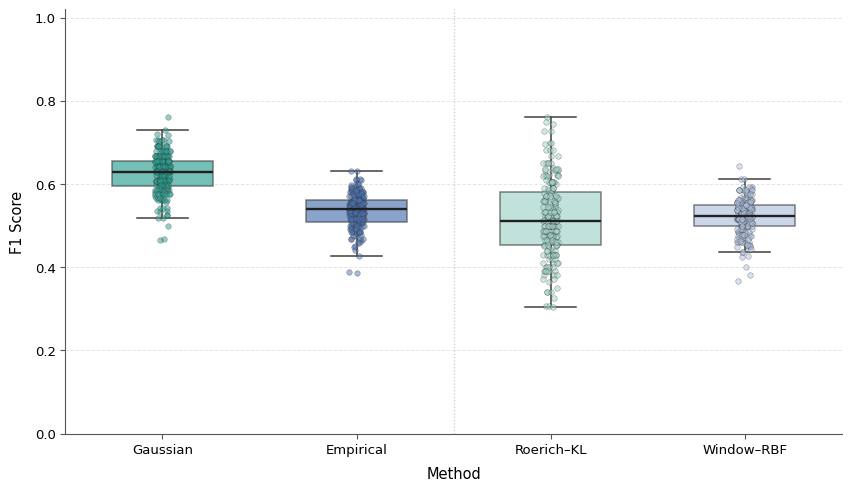

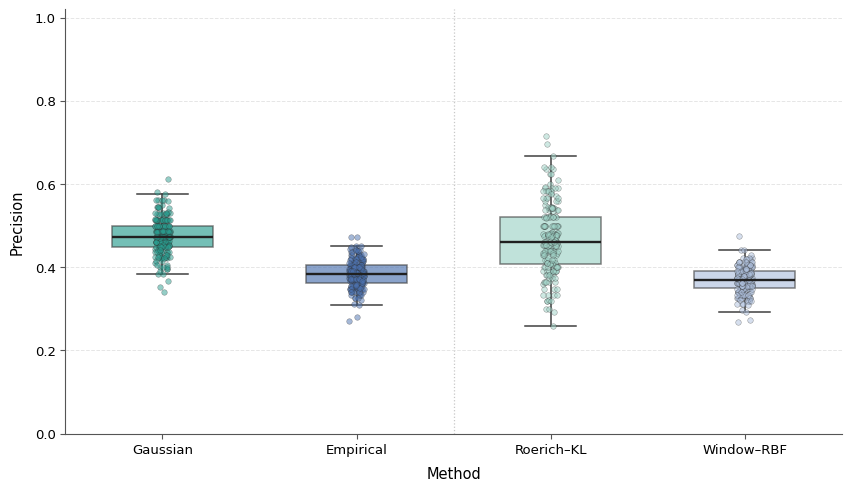

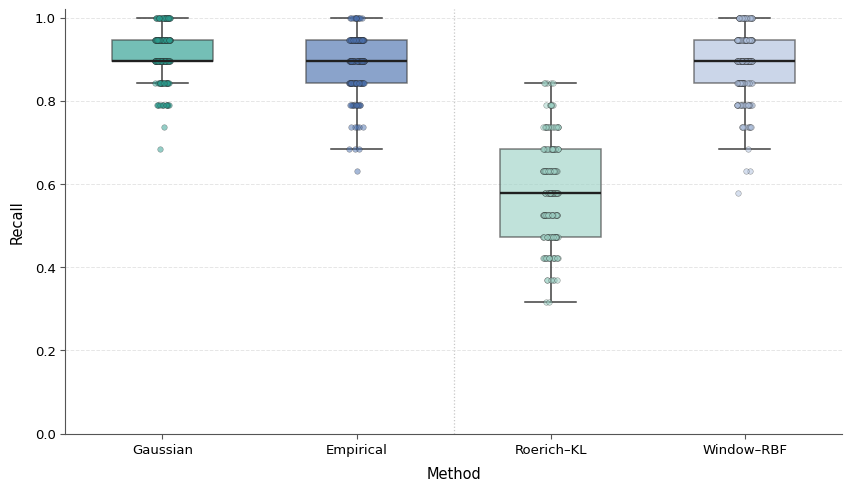

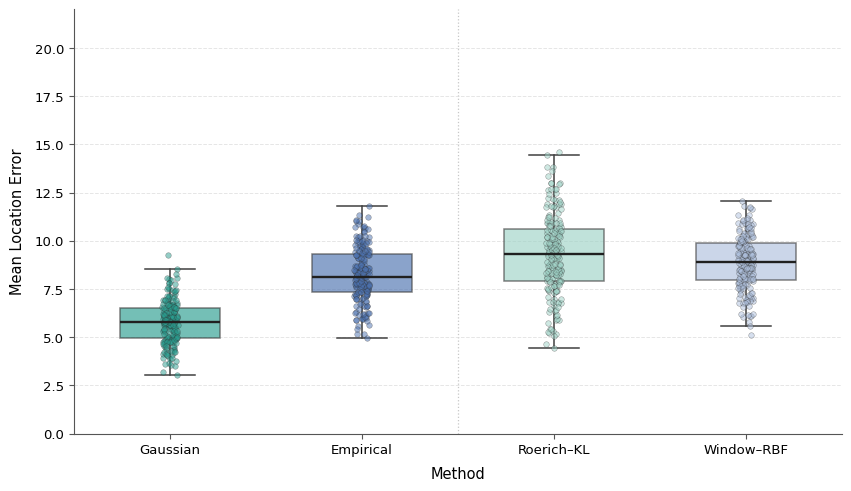

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.475406,0.914211,0.624849,5.768687
1,Empirical,0.384018,0.891316,0.536236,8.248883
2,Roerich-KL,0.468121,0.580789,0.517294,9.308375
3,Window-RBF,0.369606,0.887632,0.521645,8.865753


WINDOW SIZE: 40


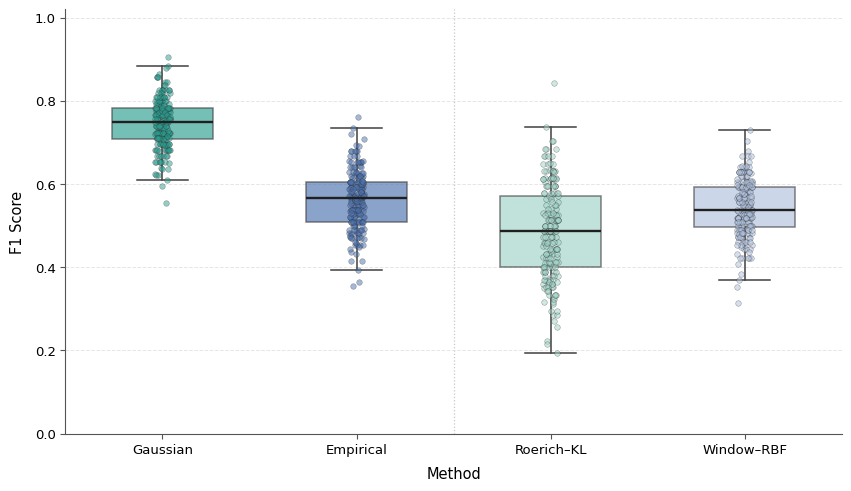

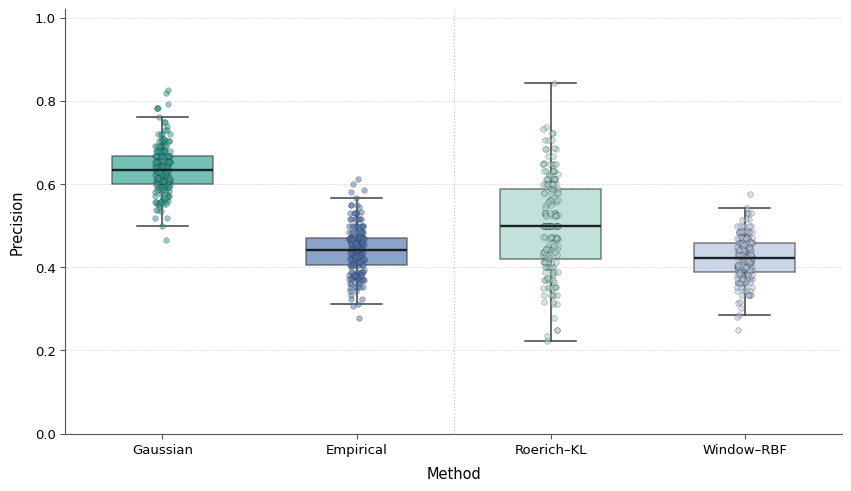

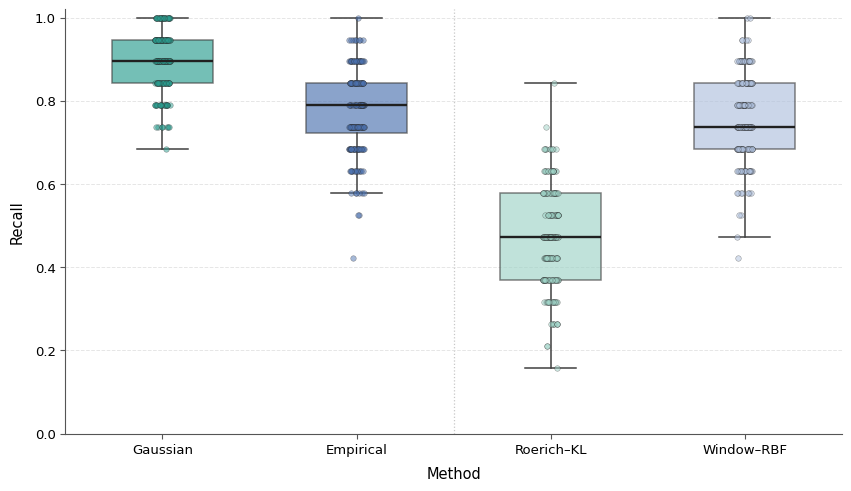

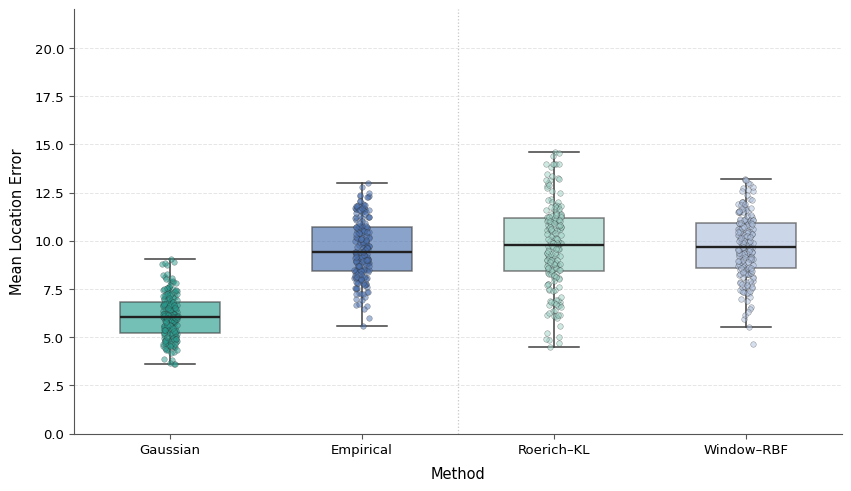

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.636859,0.900263,0.745099,6.065887
1,Empirical,0.440724,0.773684,0.560971,9.552905
2,Roerich-KL,0.499298,0.471842,0.483908,9.719585
3,Window-RBF,0.421546,0.760789,0.542163,9.712820


WINDOW SIZE: 50


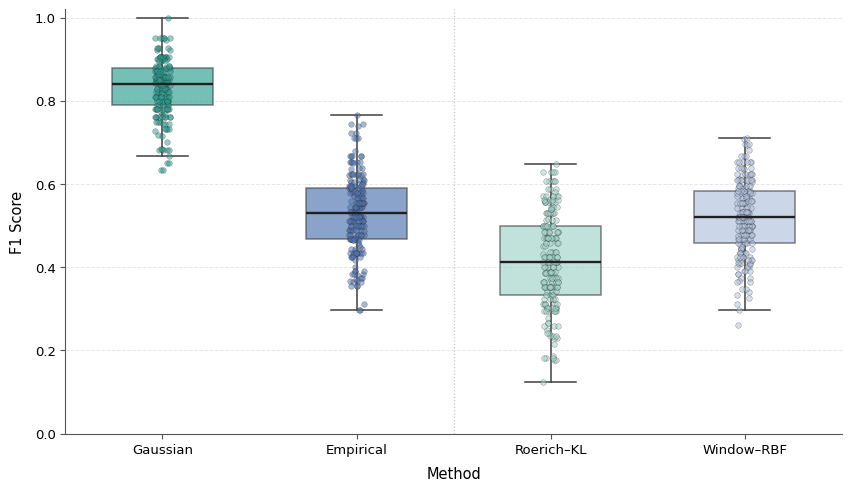

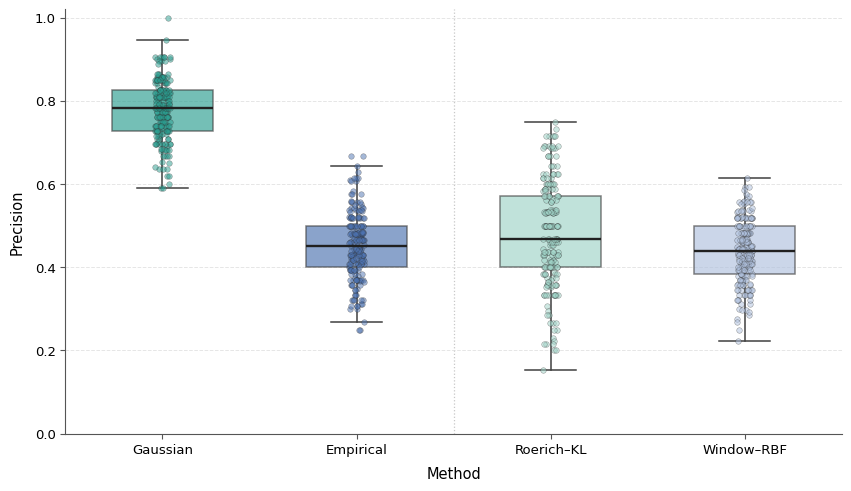

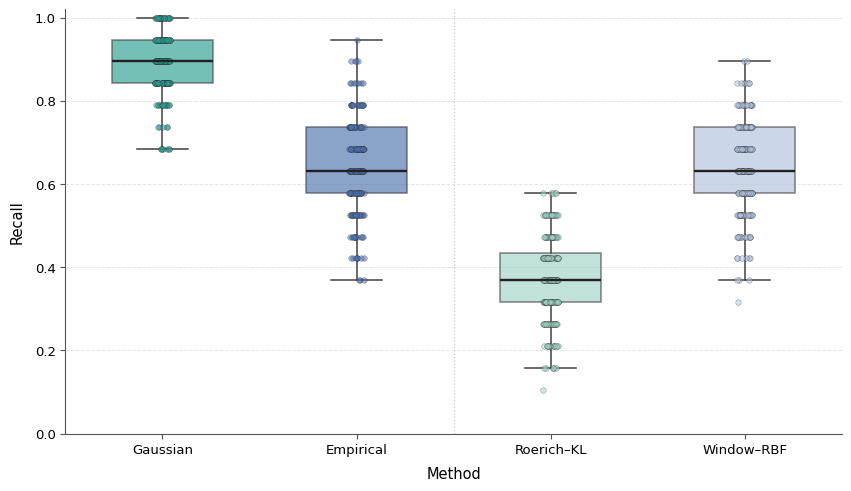

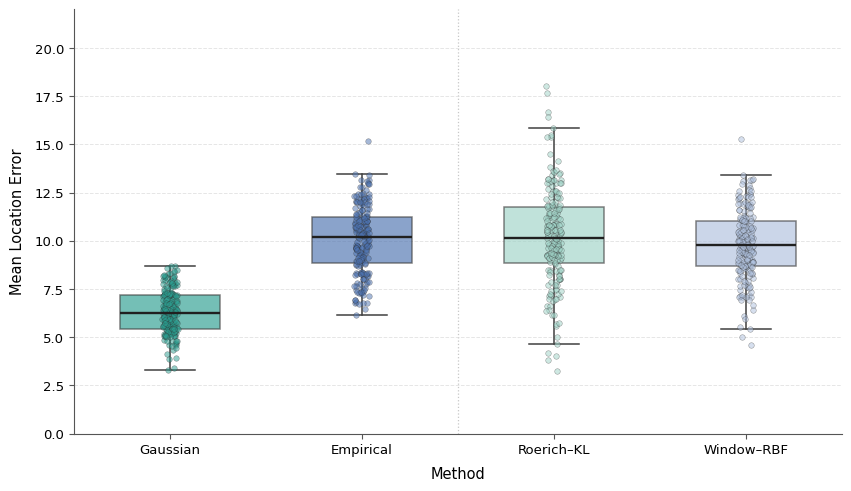

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.778205,0.890263,0.829363,6.310890
1,Empirical,0.451595,0.640263,0.528893,10.034853
2,Roerich-KL,0.479969,0.368421,0.415631,10.208170
3,Window-RBF,0.436830,0.633947,0.516827,9.798227


In [43]:
for w in [25, 30, 40, 50]:
    print("=" * 60)
    print(f"WINDOW SIZE: {w}")
    print("=" * 60)
    ruta_ar1 = f"Resultados_Series_Simuladas/AR(1)_Temporal_Dependency/Tables/ar1_metrics_window_{w}.xlsx"

    hojas = pd.read_excel(ruta_ar1, sheet_name=None)

    listas = [df.to_dict(orient="records") for df in hojas.values()]

    lista_gauss, lista_emp, lista_roerich, lista_window_rbf = listas

    nombres_boxplot = [
                        "Gaussian",
                        "Empirical",
                        "Roerich–KL",
                        "Window–RBF"
                    ]

    metrics_names = ['F1 Score', 'Precision', 'Recall', 'Mean Location Error']
    for n in metrics_names:
        ylim = (0, 1.02)
        name = n
        if n == 'Mean Location Error':
            ylim = (0, 22)
            name = 'MLE'
        path_fig = f"Resultados_Series_Simuladas/AR(1)_Temporal_Dependency/Graphics/Window {w}/{name}_AR1_TD_w{w}.png"
        fig, ax = plot_boxplots(
                                datos=[
                                    [m[n] for m in lista_gauss],
                                    [m[n] for m in lista_emp],
                                    [m[n] for m in lista_roerich],
                                    [m[n] for m in lista_window_rbf]
                                ],
                                nombres=nombres_boxplot,
                                ylabel=n,
                                xlabel="Method",
                                ylim=ylim,
                                save_path = path_fig
                            )

    ruta_avg_ar1 = f"Resultados_Series_Simuladas/AR(1)_Temporal_Dependency/Tables/ar1_metrics_avg_window_{w}.xlsx"
    average_table = generar_tabla_desde_diccionarios(
                                                        [lista_gauss, lista_emp, lista_roerich, lista_window_rbf],
                                                        ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                        ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                        )
    display(average_table)
    average_table.to_excel(ruta_avg_ar1, index=False)

### 2.1.2. Un punto de cambio

In [18]:
metricas_ar1_gauss_1cp = []
metricas_ar1_emp_1cp = []

experimentos_gauss_1cp = []
experimentos_emp_1cp = []
for i in range(200):
    print(i)
    ar1, cps_ar1, segmentos_ar1 = generar_experimento_ar1(
                N=500,
                n_segmentos=2,
                min_sep=250,
                max_sep=250,
                punto_cambio=250,
                seed=1234+i
            )

    cpd_ar1 = CPD(ar1, window=100, t=1, medias=True, smooth=True, temporal_comp=True)
    distancias_ar1 = cpd_ar1.distancias()
    cps_detect = detect(distancias_ar1, 100)
    metricas_ar1_gauss_1cp.append(metrics(cps_ar1, cps_detect, 20, 500)[0])
    experimentos_gauss_1cp.append((ar1, distancias_ar1, cpd_ar1.window, f"AR(1) - Experimento {i}", cps_ar1, cps_detect))

    cpd_ar1_emp = EmpiricalCPD(ar1, window=100, smooth=True)
    distancias_ar1_emp = cpd_ar1_emp.distancias()
    cps_detect_emp = detect(distancias_ar1_emp, 100, emp=emp)
    metricas_ar1_emp_1cp.append(metrics(cps_ar1, cps_detect_emp, 20, 500)[0])
    experimentos_emp_1cp.append((ar1, distancias_ar1, cpd_ar1_emp.window, f"AR(1) - Experimento {i}", cps_ar1, cps_detect_emp))





0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199


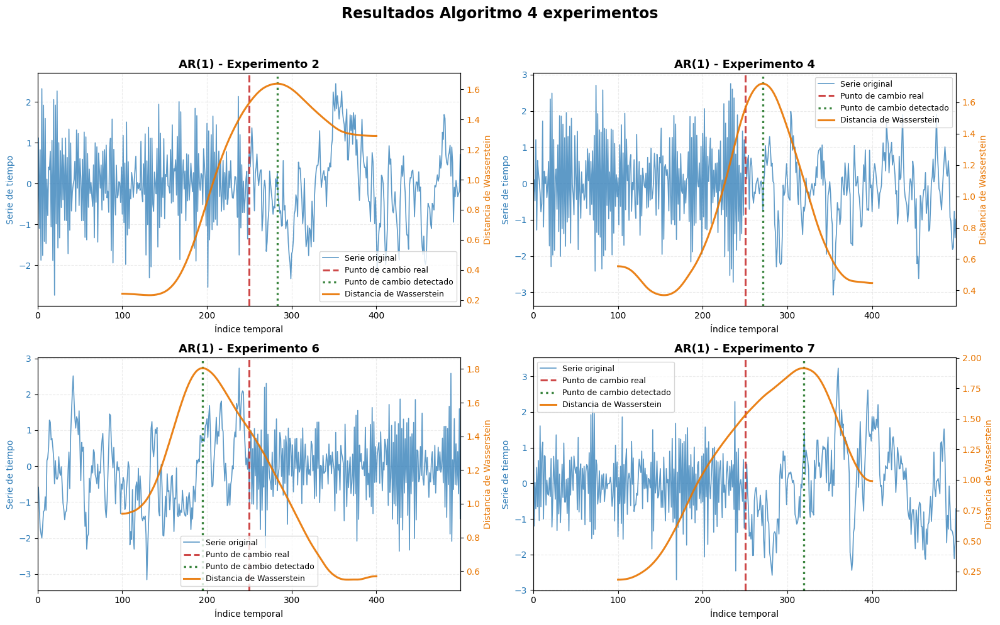

In [ ]:
grafica_comparativa_wasserstein_serie(experimentos_analisis, 'Resultados Algoritmo 4 experimentos')

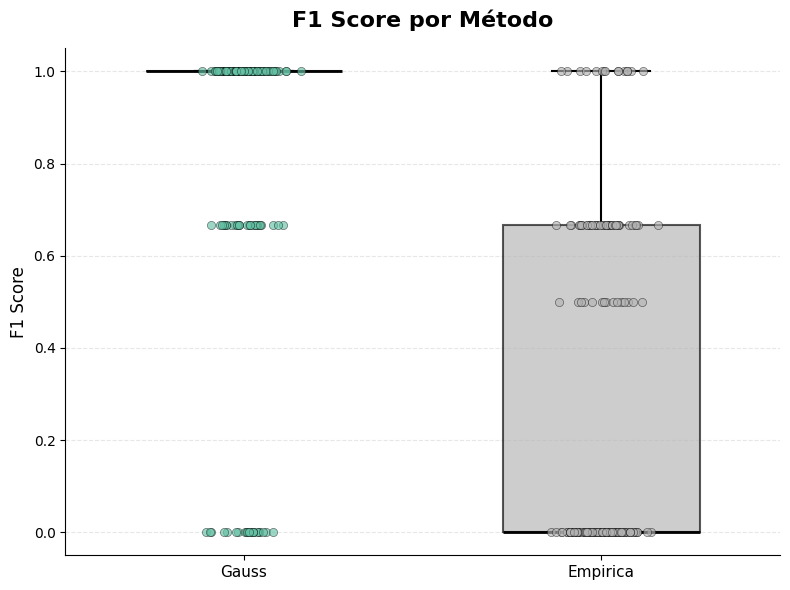

In [22]:
F1_scores_ar1_mpc = [[m['F1 Score'] for m in metricas_ar1_gauss_1cp], [m['F1 Score'] for m in metricas_ar1_emp_1cp]]


plot_boxplots(F1_scores_ar1_mpc, ["Gauss", "Empirica"], "F1 Score por Método", ylabel="F1 Score", figsize=(8, 6))

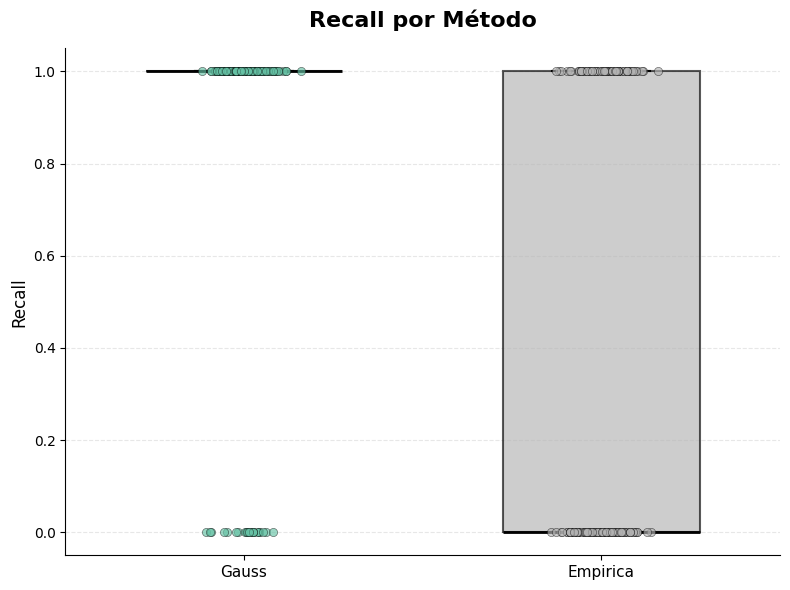

In [23]:
Recalls_ar1_mpc = [[m['Recall'] for m in metricas_ar1_gauss_1cp], [m['Recall'] for m in metricas_ar1_emp_1cp]]


plot_boxplots(Recalls_ar1_mpc, ["Gauss", "Empirica"], "Recall por Método", ylabel="Recall", figsize=(8, 6))

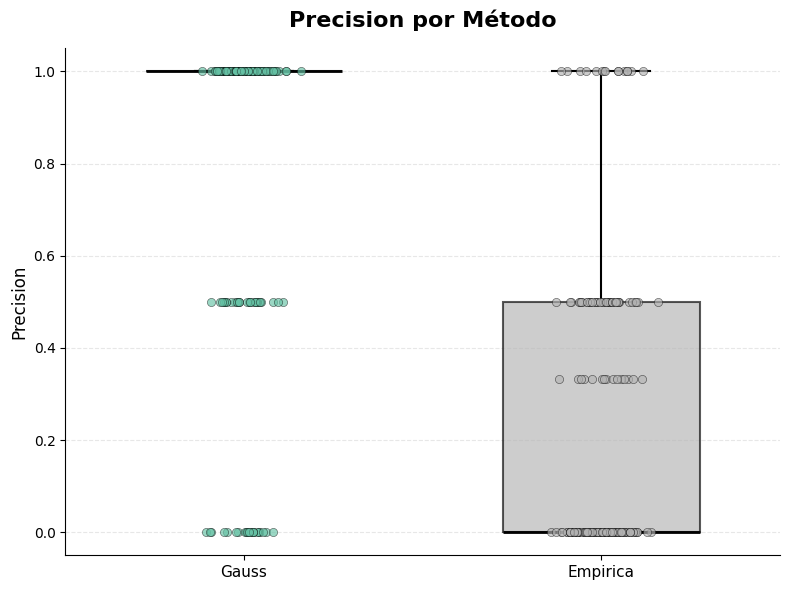

In [24]:
Precisions_ar1_mpc = [[m['Precision'] for m in metricas_ar1_gauss_1cp], [m['Precision'] for m in metricas_ar1_emp_1cp]]


plot_boxplots(Precisions_ar1_mpc, ["Gauss", "Empirica"], "Precision por Método", ylabel="Precision", figsize=(8, 6))

## 2.2. AR(2)

### 2.2.1. Múltiples puntos de cambio

In [86]:
def experiment_ar2_temporal_dependence(w=50, delta=20):
    metricas_ar2_gauss_fw = []
    metricas_ar2_emp_fw = []
    metricas_ar2_roerich = []
    metricas_ar2_window_rbf = []

    for i in range(200):
        print(i)
        ar2, cps_ar2, segmentos_ar2 = generar_experimento_ar2(
                    N=2000,
                    n_segmentos=20,
                    min_sep=50,
                    max_sep=150,
                    seed=1234+i
                )
        
        #Gaussiano
        cpd_ar2 = CPD(ar2, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
        distancias_ar2 = cpd_ar2.distancias()
        cps_detect = detect(distancias_ar2, w)
        metricas_ar2_gauss_fw.append(metrics(cps_ar2, cps_detect, delta, 2000)[0])

        #Empírico
        cpd_ar2_emp = EmpiricalCPD(ar2, window=w, smooth=True)
        distancias_ar2_emp = cpd_ar2_emp.distancias()
        cps_detect_emp = detect(distancias_ar2_emp, w)
        metricas_ar2_emp_fw.append(metrics(cps_ar2, cps_detect_emp, delta, 2000)[0])

        #Roerich KL
        puntos_cambio = detectar_cambios_roerich(
                                        ar2,
                                        window_size=w,
                                        seed=42,
                                        periods=3
                                    )
        
        metricas_ar2_roerich.append(metrics(cps_ar2, puntos_cambio, delta, len(ar2))[0])

        #Window RBF
        puntos_cambio = detectar_window_rbf(
                                        ar2,
                                        window=w
                                    )
        
        metricas_ar2_window_rbf.append(metrics(cps_ar2, puntos_cambio, delta, len(ar2))[0])
        
    return metricas_ar2_gauss_fw, metricas_ar2_emp_fw, metricas_ar2_roerich, metricas_ar2_window_rbf

In [87]:
lists_metrics_ar2 = []
windows = [25, 30, 40, 50]
for w in windows:
    print(f'WINDOW SIZE: {w}')
    lists_metrics_ar2.append(experiment_ar2_temporal_dependence(w=w, delta=20))

WINDOW SIZE: 25
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
WINDOW SIZE: 30
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95


In [ ]:
for metricas, w in zip(lists_metrics_ar2, windows):
    exportar_excel(metricas, f"Resultados_Series_Simuladas/AR(2)_Temporal_Dependency/Tables/ar2_metrics_window_{w}.xlsx", ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"])

WINDOW SIZE: 25


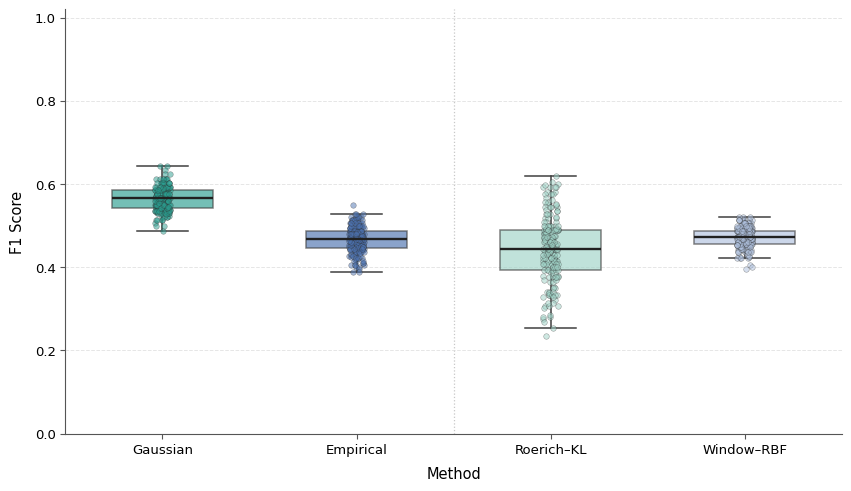

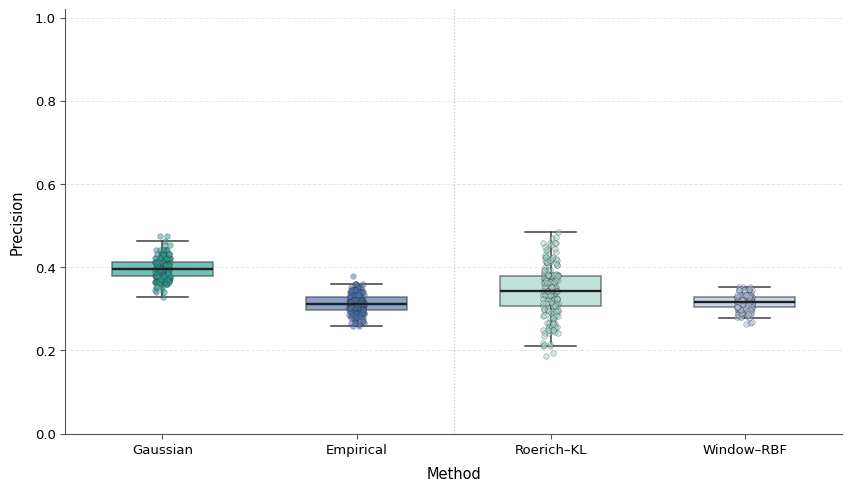

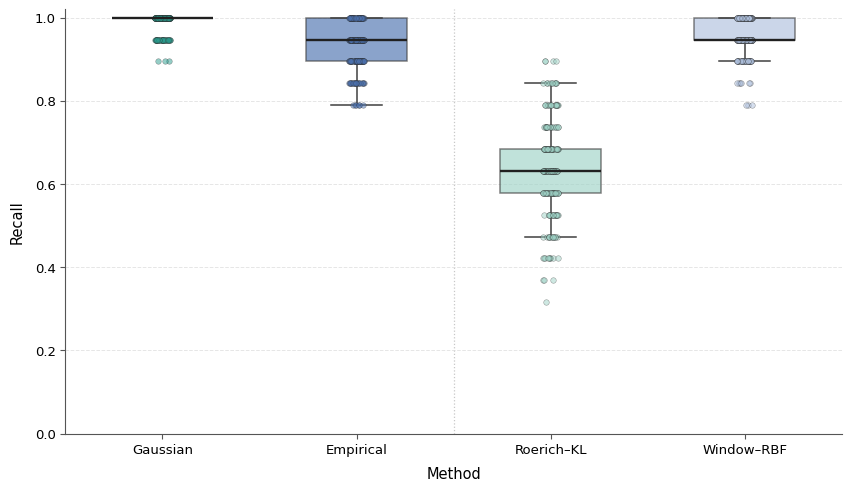

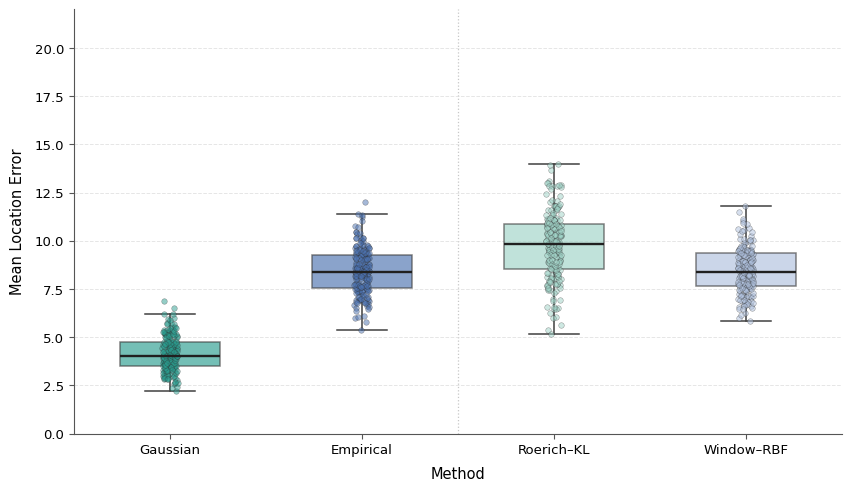

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.395411,0.988947,0.564523,4.145353
1,Empirical,0.311550,0.934211,0.467033,8.422718
2,Roerich-KL,0.341553,0.635789,0.443896,9.725414
3,Window-RBF,0.314149,0.950789,0.472137,8.462669


WINDOW SIZE: 30


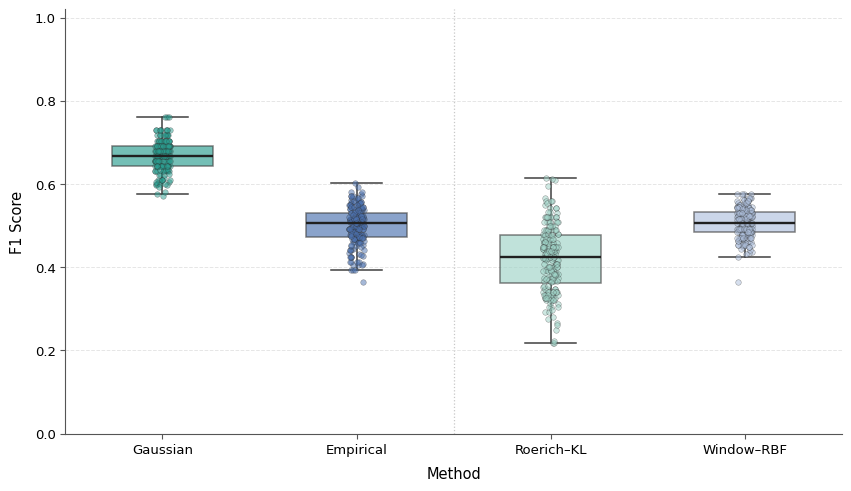

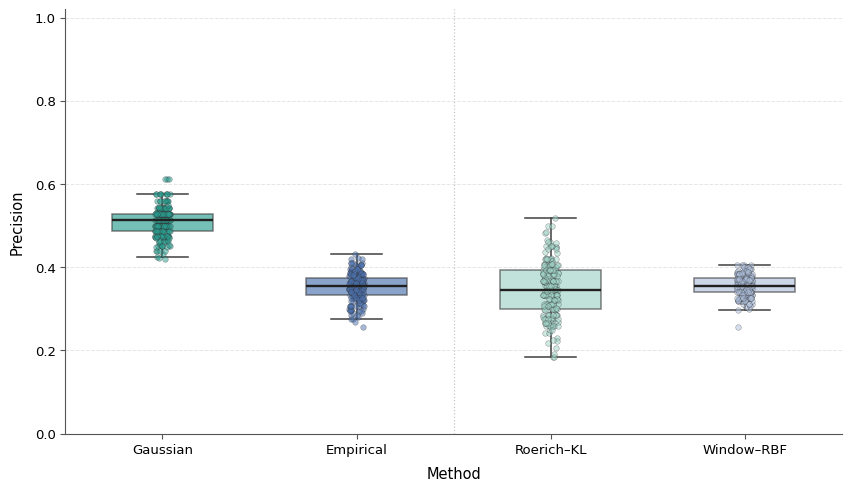

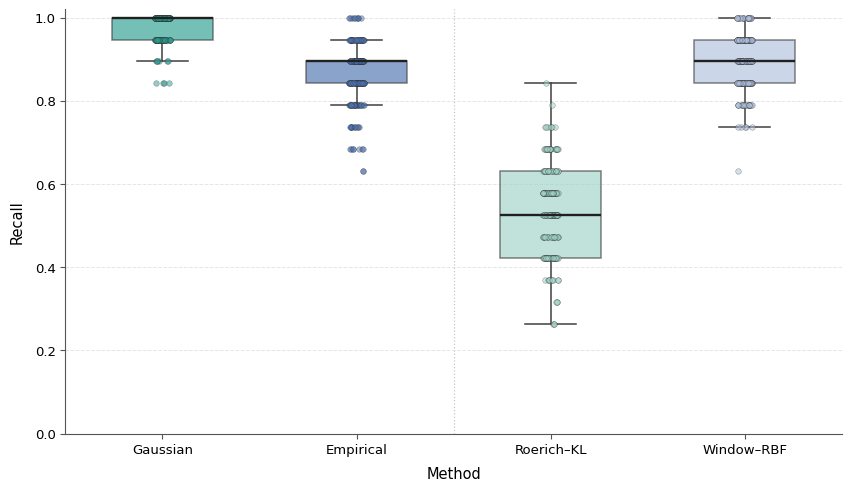

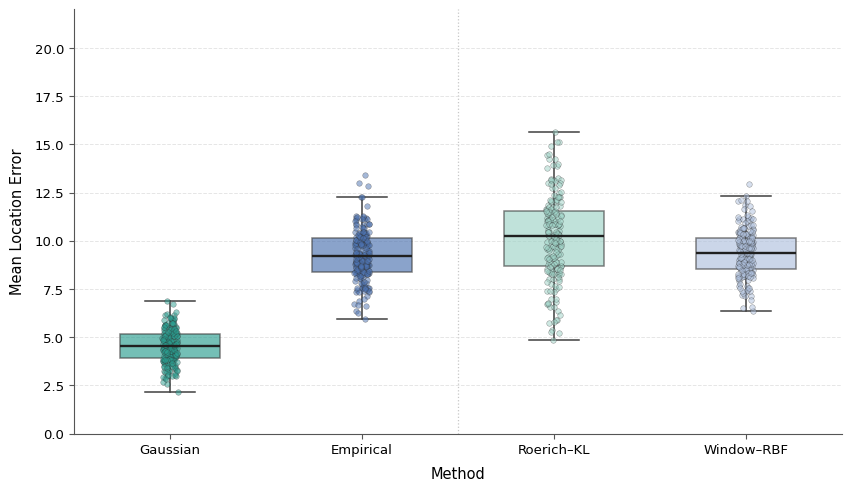

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.508253,0.980789,0.668902,4.527366
1,Empirical,0.352112,0.864211,0.500027,9.256256
2,Roerich-KL,0.346205,0.537105,0.420404,10.173458
3,Window-RBF,0.354727,0.891316,0.507318,9.381011


WINDOW SIZE: 40


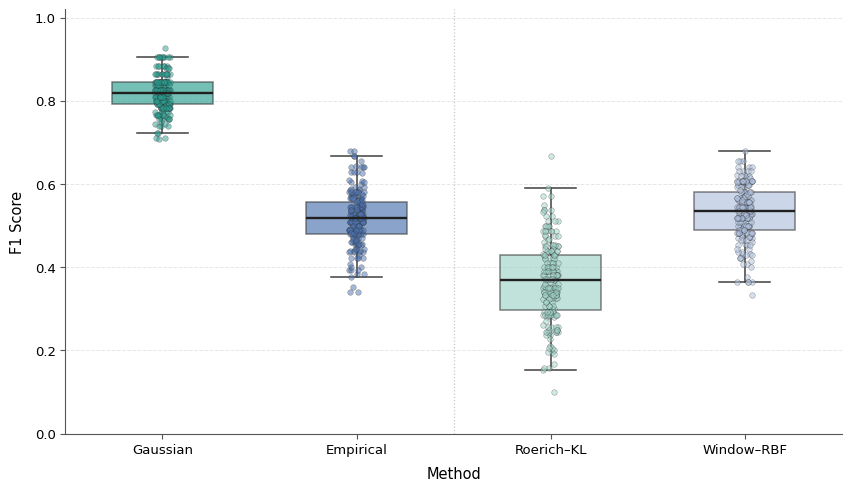

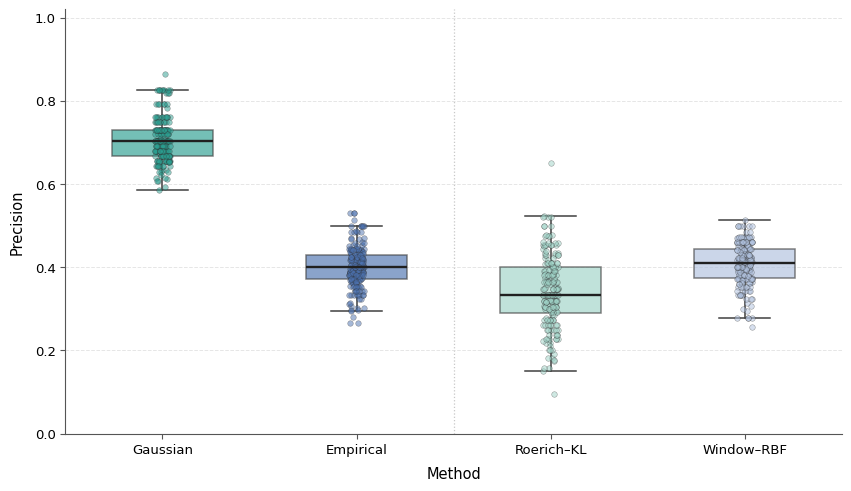

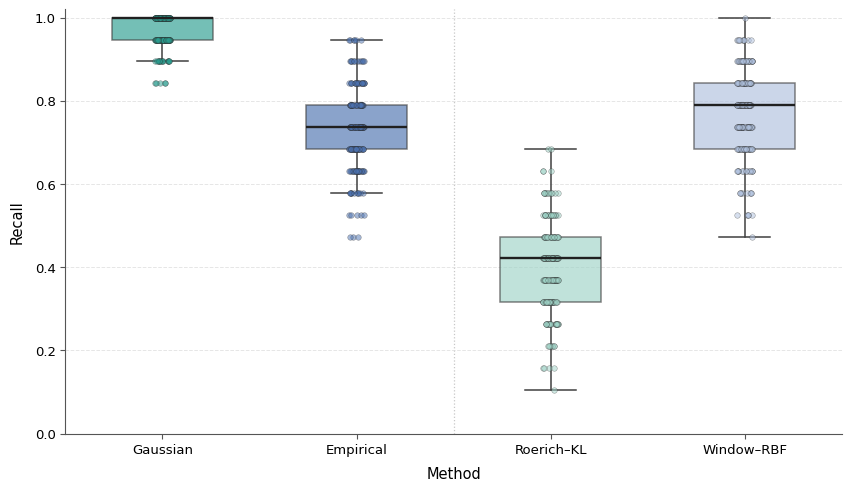

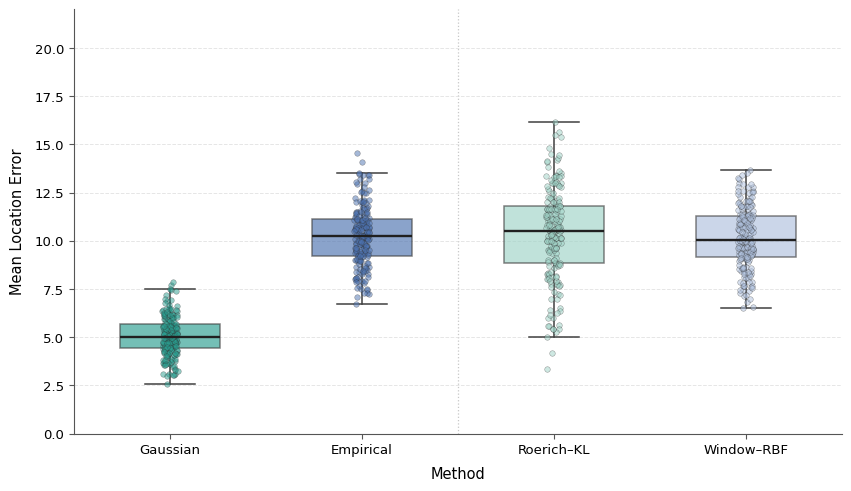

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.705463,0.971316,0.816348,5.051931
1,Empirical,0.399769,0.730000,0.516150,10.227311
2,Roerich-KL,0.341973,0.396842,0.366678,10.328993
3,Window-RBF,0.407364,0.768947,0.532324,10.122028


WINDOW SIZE: 50


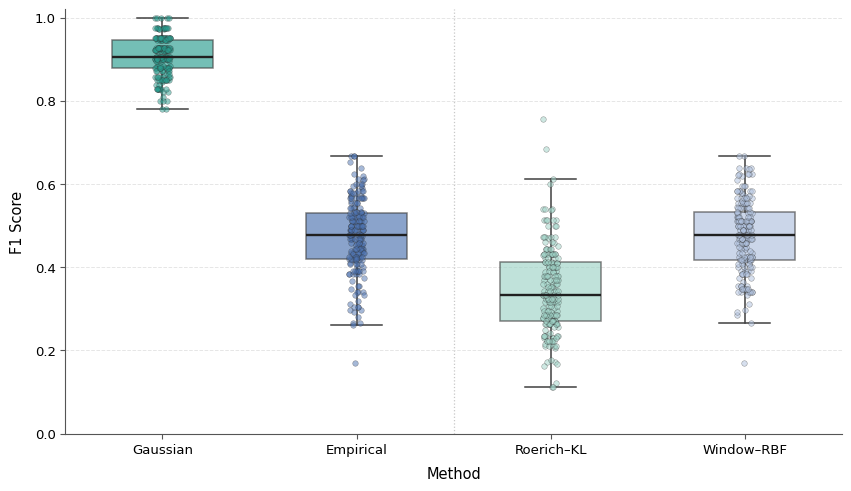

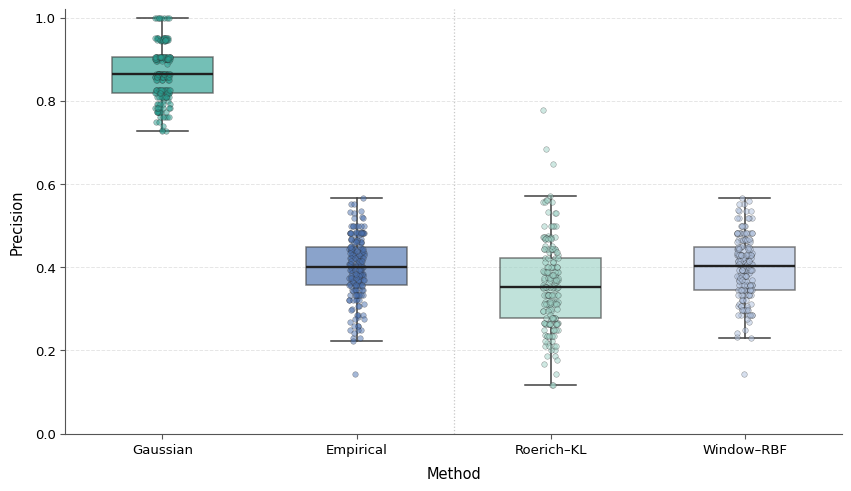

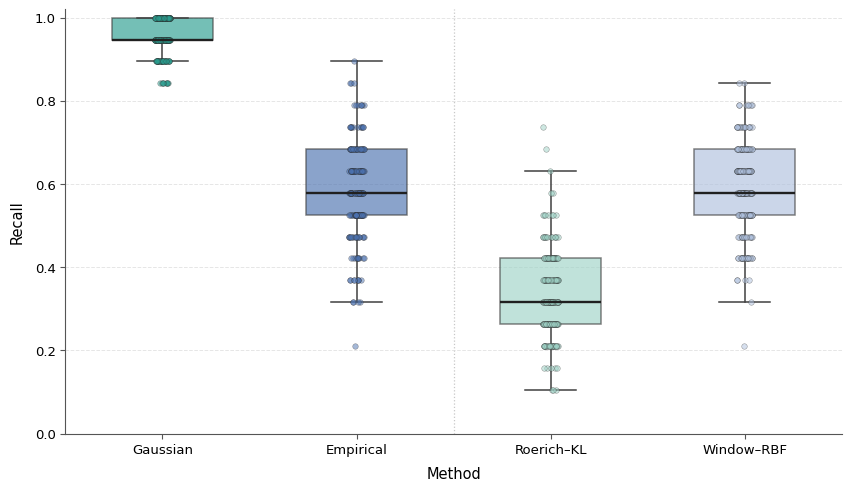

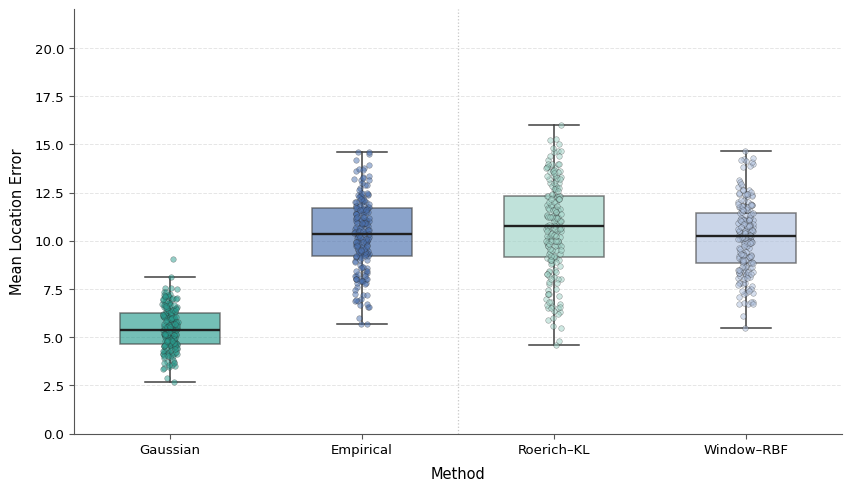

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.863768,0.956842,0.906835,5.429831
1,Empirical,0.399031,0.582632,0.473082,10.317305
2,Roerich-KL,0.356455,0.336842,0.345432,10.656683
3,Window-RBF,0.398424,0.587632,0.474572,10.179409


In [44]:
for w in [25, 30, 40, 50]:
    print("=" * 60)
    print(f"WINDOW SIZE: {w}")
    print("=" * 60)
    ruta_ar2 = f"Resultados_Series_Simuladas/AR(2)_Temporal_Dependency/Tables/ar2_metrics_window_{w}.xlsx"

    hojas = pd.read_excel(ruta_ar2, sheet_name=None)

    listas = [df.to_dict(orient="records") for df in hojas.values()]

    lista_gauss, lista_emp, lista_roerich, lista_window_rbf = listas

    nombres_boxplot = [
                        "Gaussian",
                        "Empirical",
                        "Roerich–KL",
                        "Window–RBF"
                    ]

    metrics_names = ['F1 Score', 'Precision', 'Recall', 'Mean Location Error']
    for n in metrics_names:
        ylim = (0, 1.02)
        name = n
        if n == 'Mean Location Error':
            ylim = (0, 22)
            nmae = 'MLE'
        path_fig = f"Resultados_Series_Simuladas/AR(2)_Temporal_Dependency/Graphics/Window {w}/{name}_AR2_TD_w{w}.png"
        fig, ax = plot_boxplots(
                                datos=[
                                    [m[n] for m in lista_gauss],
                                    [m[n] for m in lista_emp],
                                    [m[n] for m in lista_roerich],
                                    [m[n] for m in lista_window_rbf]
                                ],
                                nombres=nombres_boxplot,
                                ylabel=n,
                                xlabel="Method",
                                ylim=ylim,
                                save_path = path_fig
                            )
    ruta_avg_ar2 = f"Resultados_Series_Simuladas/AR(2)_Temporal_Dependency/Tables/ar2_metrics_avg_window_{w}.xlsx"
    average_table = generar_tabla_desde_diccionarios(
                                                        [lista_gauss, lista_emp, lista_roerich, lista_window_rbf],
                                                        ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                        ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                        )
    display(average_table)
    average_table.to_excel(ruta_avg_ar2, index=False)

### 2.2.2 Un punto de cambio

In [30]:
metricas_ar2_gauss_1cp = []
metricas_ar2_emp_1cp = []

experimentos_gauss_1cp = []
experimentos_emp_1cp = []
for i in range(200):
    print(i)
    ar2, cps_ar2, segmentos_ar2 = generar_experimento_ar2(
                N=500,
                n_segmentos=2,
                min_sep=250,
                max_sep=250,
                punto_cambio=250,
                seed=1234+i
            )

    cpd_ar2 = CPD(ar2, window=100, t=1, medias=True, smooth=True, temporal_comp=True)
    distancias_ar2 = cpd_ar1.distancias()
    cps_detect = detect(distancias_ar2, 100)
    metricas_ar2_gauss_1cp.append(metrics(cps_ar2, cps_detect, 20, 500)[0])
    experimentos_gauss_1cp.append((ar2, distancias_ar2, cpd_ar2.window, f"AR(2) - Experimento {i}", cps_ar2, cps_detect))

    cpd_ar2_emp = EmpiricalCPD(ar2, window=100, smooth=True)
    distancias_ar2_emp = cpd_ar2_emp.distancias()
    cps_detect_emp = detect(distancias_ar2_emp, 100, emp=emp)
    metricas_ar2_emp_1cp.append(metrics(cps_ar2, cps_detect_emp, 20, 500)[0])
    experimentos_emp_1cp.append((ar2, distancias_ar2_emp, cpd_ar2_emp.window, f"AR(2) - Experimento {i}", cps_ar2, cps_detect_emp))

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199


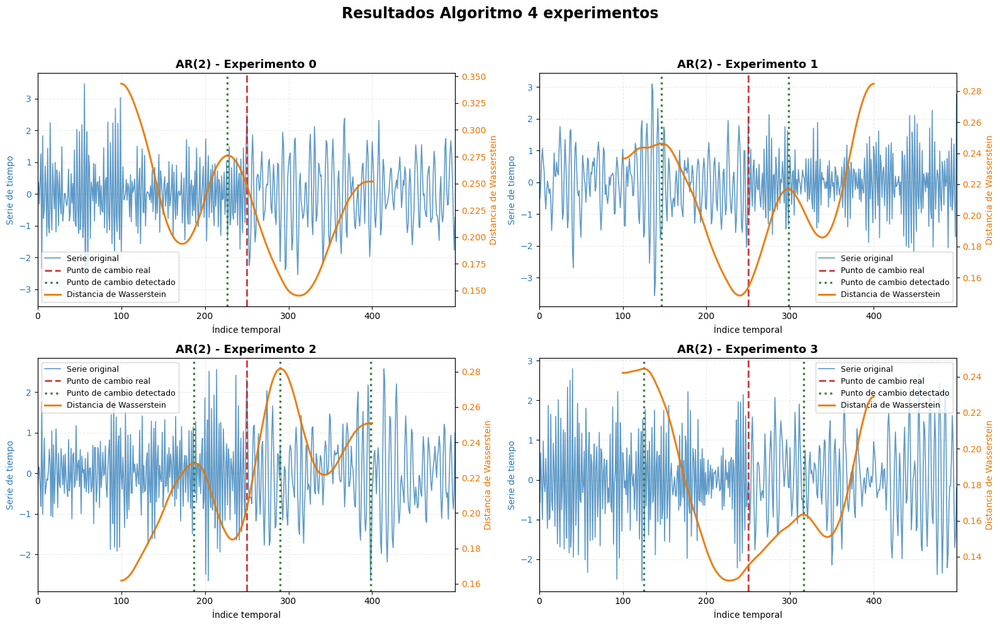

In [31]:
grafica_comparativa_wasserstein_serie(experimentos_emp_1cp[:4], 'Resultados Algoritmo 4 experimentos')

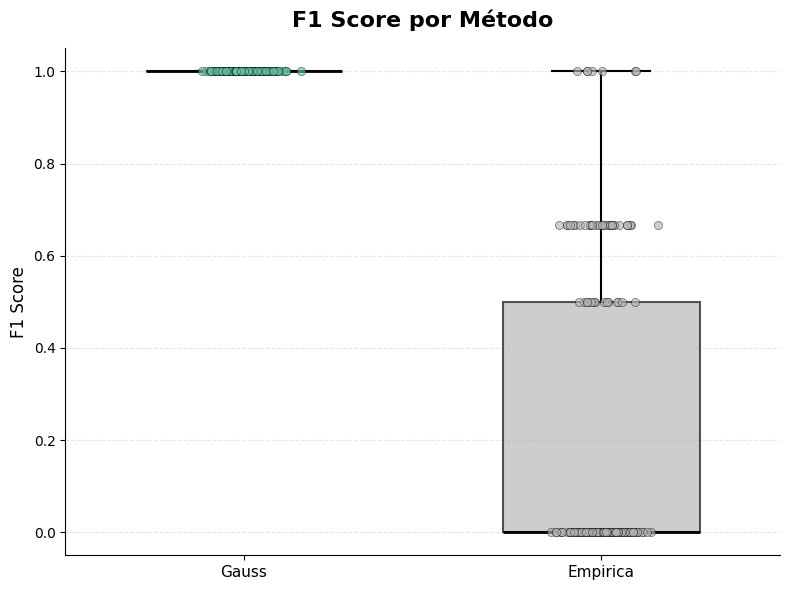

In [32]:
F1_scores_ar2_mpc = [[m['F1 Score'] for m in metricas_ar2_gauss_1cp], [m['F1 Score'] for m in metricas_ar2_emp_1cp]]


plot_boxplots(F1_scores_ar2_mpc, ["Gauss", "Empirica"], "F1 Score por Método", ylabel="F1 Score", figsize=(8, 6))

## 2.3. Senoidal

In [90]:
def experiment_sen_temporal_dependence(w=50, delta=20):
    metricas_sen_gauss_fw = []
    metricas_sen_emp_fw = []
    metricas_sen_roerich = []
    metricas_sen_window_rbf = []

    for i in range(200):
        print(i)
        sen, cps_sen, segmentos_sen = generar_experimento_senoidal(
                    N=2000,
                    n_segmentos=20,
                    min_sep=50,
                    max_sep=150,
                    seed=1234+i
                )
        
        #Gaussiano
        cpd_sen = CPD(sen, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
        distancias_sen = cpd_sen.distancias()
        cps_detect = detect(distancias_sen, w)
        metricas_sen_gauss_fw.append(metrics(cps_sen, cps_detect, delta, 2000)[0])

        #Empírico
        cpd_sen_emp = EmpiricalCPD(sen, window=w, smooth=True)
        distancias_sen_emp = cpd_sen_emp.distancias()
        cps_detect_emp = detect(distancias_sen_emp, w)
        metricas_sen_emp_fw.append(metrics(cps_sen, cps_detect_emp, delta, 2000)[0])

        #Roerich KL
        puntos_cambio = detectar_cambios_roerich(
                                        sen,
                                        window_size=w,
                                        seed=42,
                                        periods=3
                                    )
        
        metricas_sen_roerich.append(metrics(cps_sen, puntos_cambio, delta, len(sen))[0])

        #Window RBF
        puntos_cambio = detectar_window_rbf(
                                        sen,
                                        window=w
                                    )
        
        metricas_sen_window_rbf.append(metrics(cps_sen, puntos_cambio, delta, len(sen))[0])
        
    return metricas_sen_gauss_fw, metricas_sen_emp_fw, metricas_sen_roerich, metricas_sen_window_rbf

In [91]:
lists_metrics_sen = []
windows = [25, 30, 40, 50]
for w in windows:
    print(f'WINDOW SIZE: {w}')
    lists_metrics_sen.append(experiment_sen_temporal_dependence(w=w, delta=20))

WINDOW SIZE: 25
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
WINDOW SIZE: 30
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95


In [ ]:
for metricas, w in zip(lists_metrics_sen, windows):
    exportar_excel(metricas, f"Resultados_Series_Simuladas/Sen_Temporal_Dependency/Tables/sen_metrics_window_{w}.xlsx", ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"])

WINDOW SIZE: 25


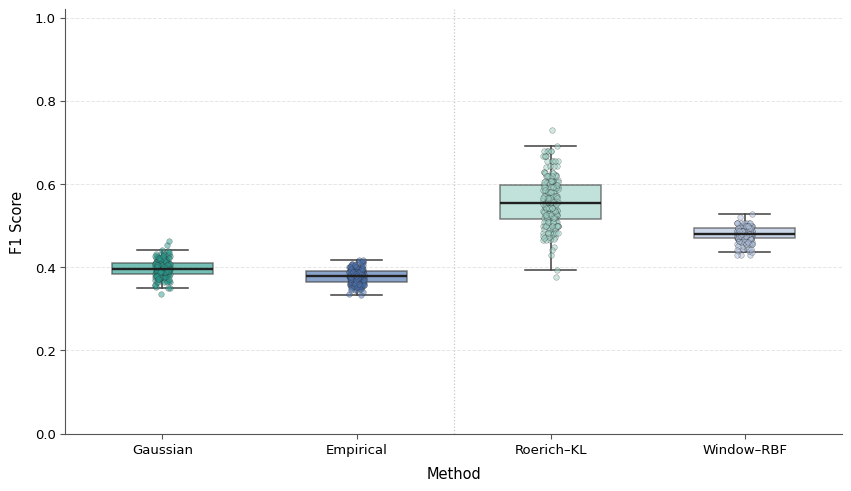

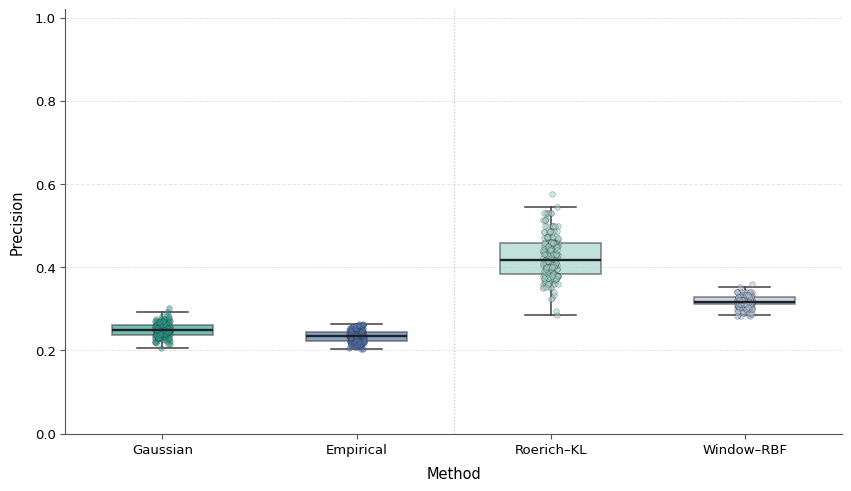

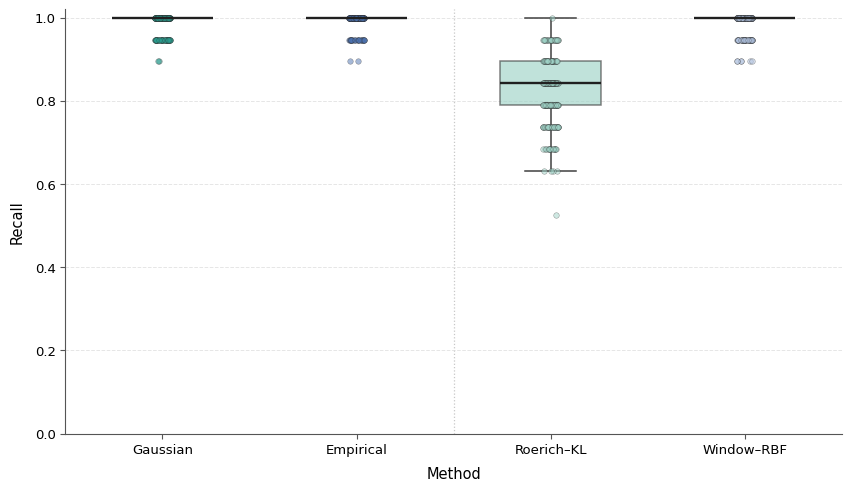

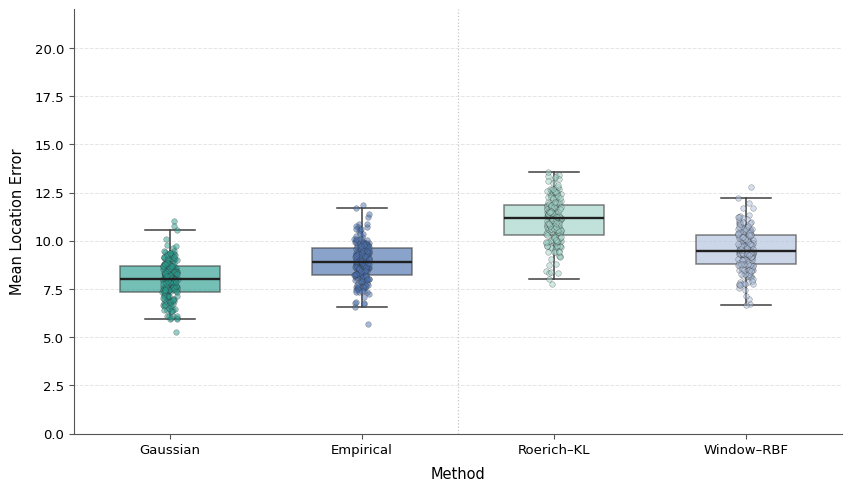

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.249122,0.987895,0.397676,7.969842
1,Empirical,0.233863,0.992895,0.378384,8.891945
2,Roerich-KL,0.423559,0.819474,0.557873,11.064550
3,Window-RBF,0.316682,0.986053,0.479300,9.507603


WINDOW SIZE: 30


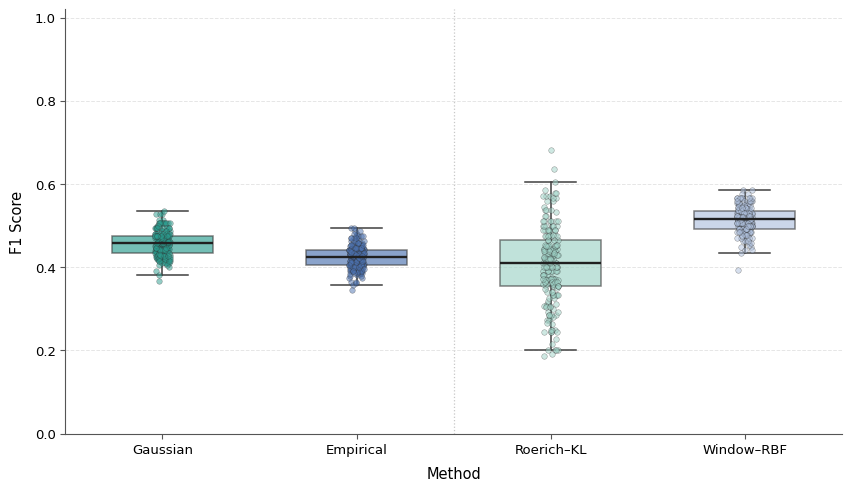

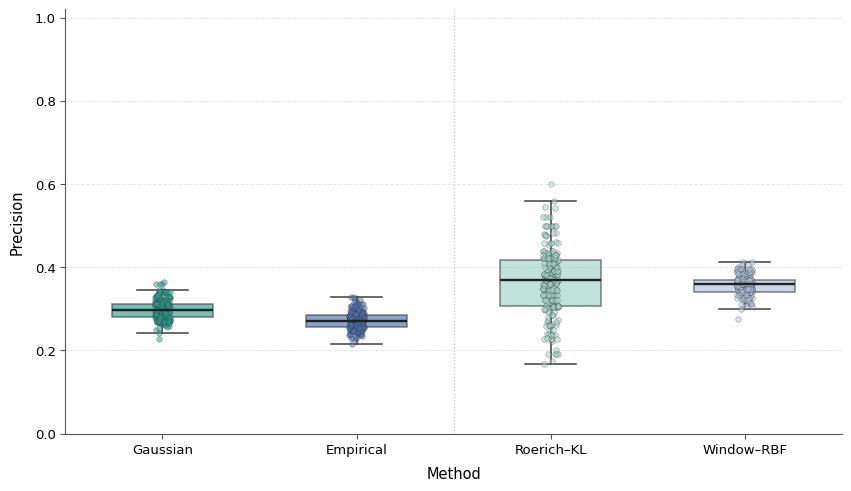

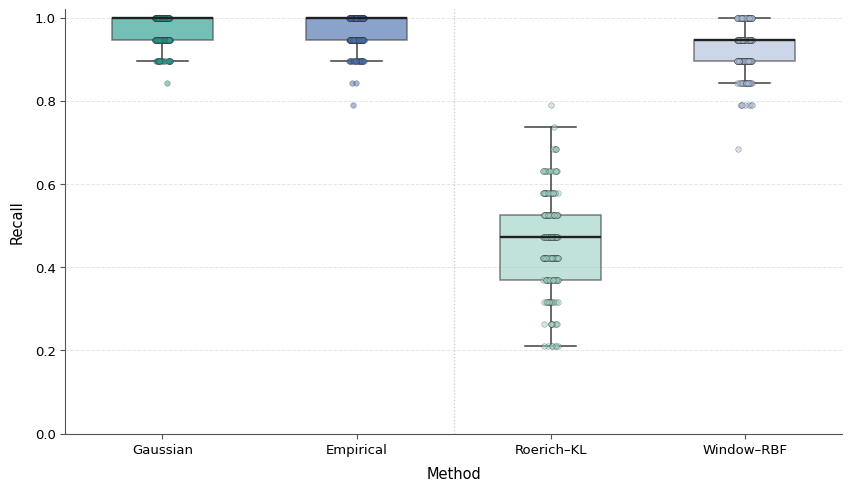

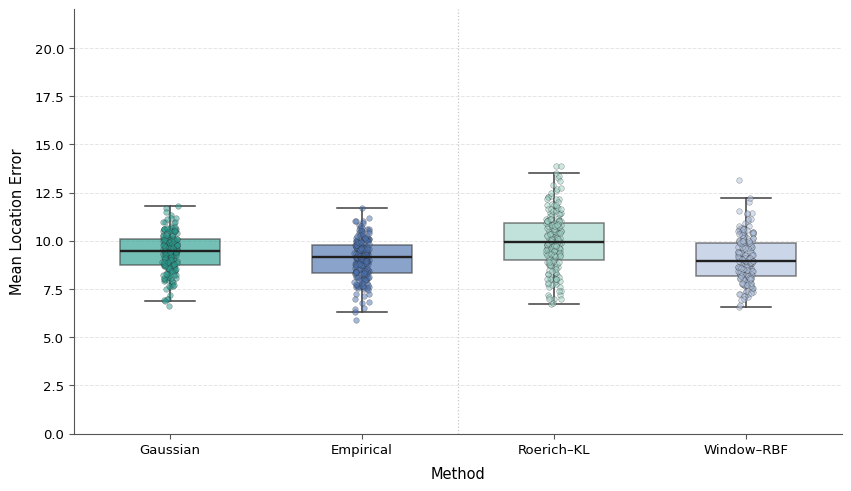

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.298412,0.970263,0.455987,9.394058
1,Empirical,0.271443,0.966316,0.423513,9.059931
2,Roerich-KL,0.364424,0.459211,0.405346,9.986490
3,Window-RBF,0.357321,0.923947,0.515181,9.058121


WINDOW SIZE: 40


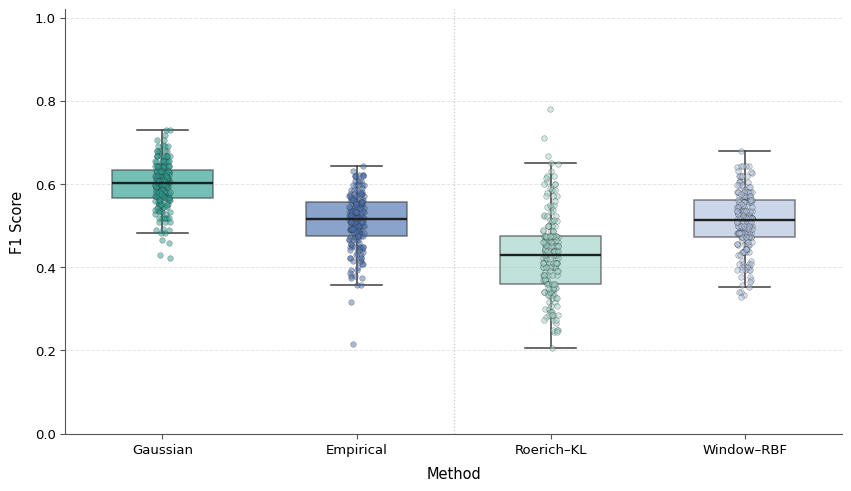

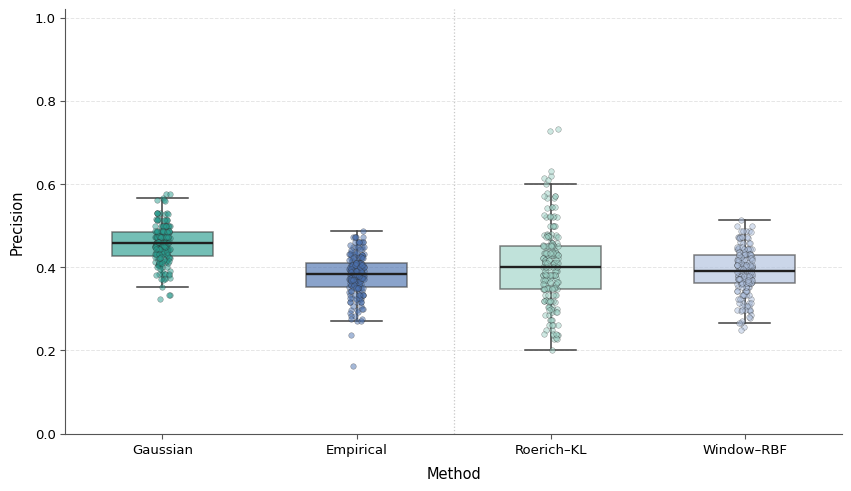

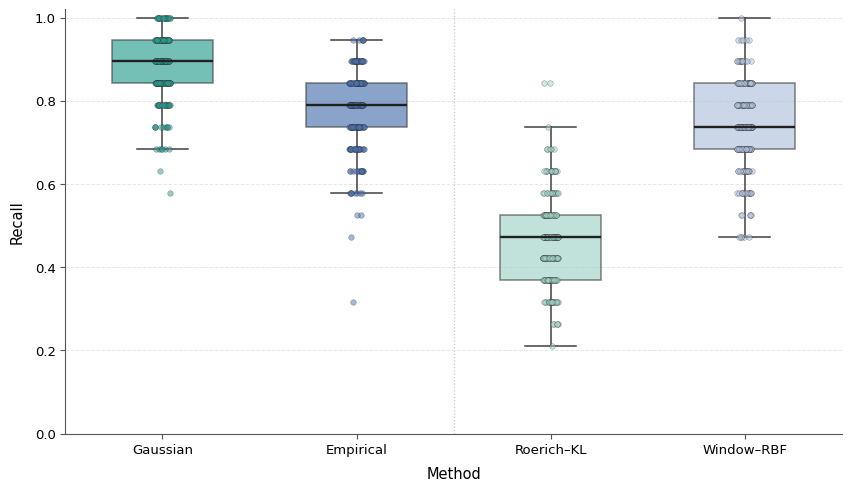

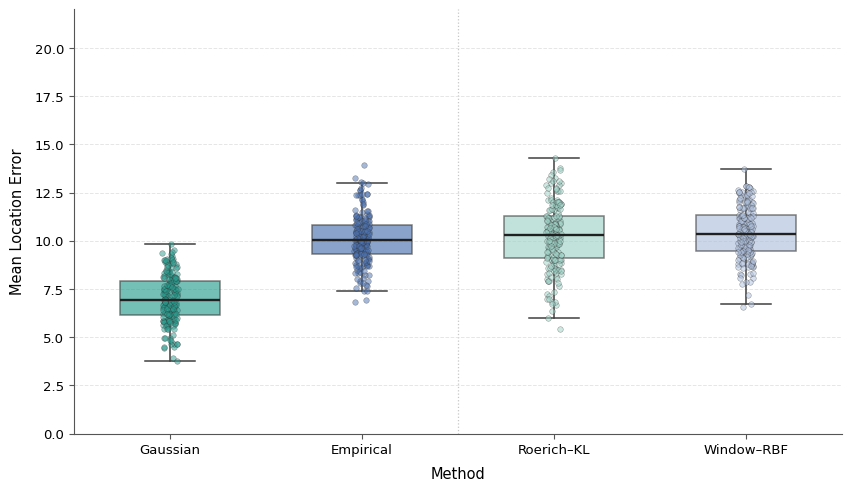

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.456013,0.874737,0.598739,6.999920
1,Empirical,0.381460,0.772368,0.510313,10.073668
2,Roerich-KL,0.402188,0.464211,0.429995,10.245420
3,Window-RBF,0.388805,0.736842,0.508827,10.405876


WINDOW SIZE: 50


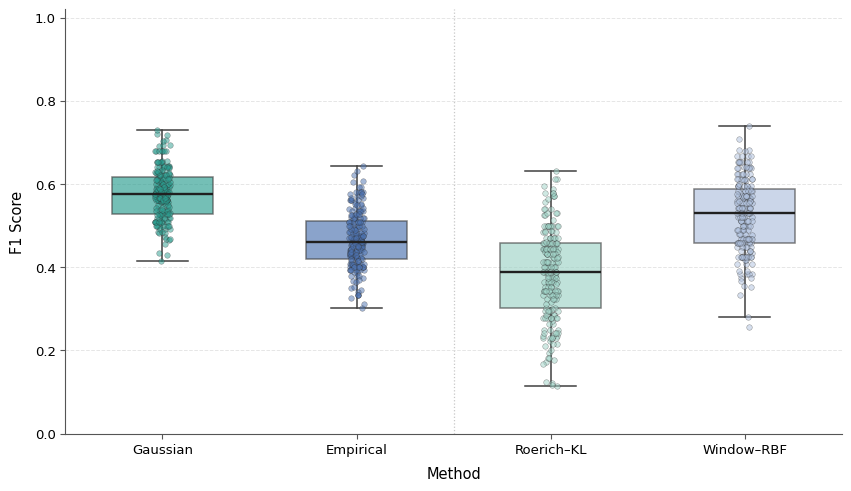

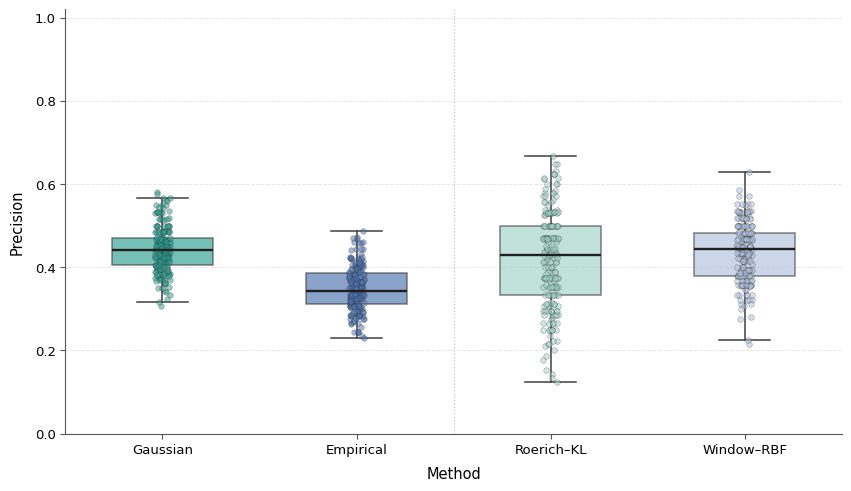

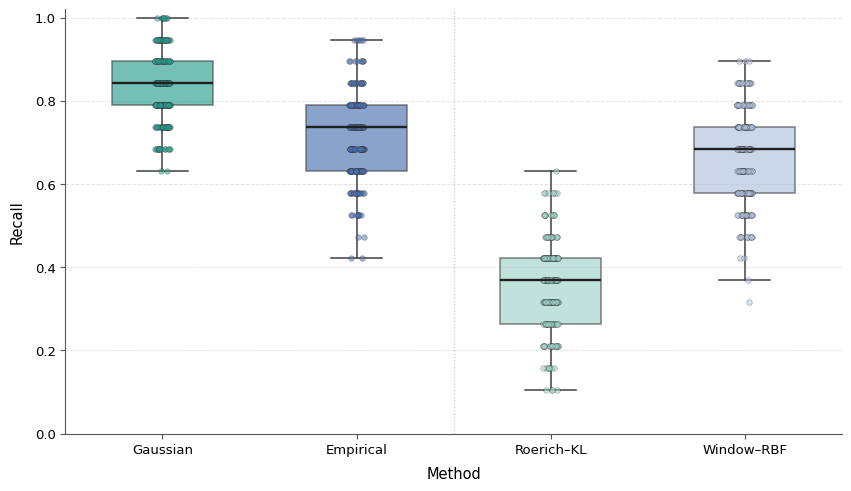

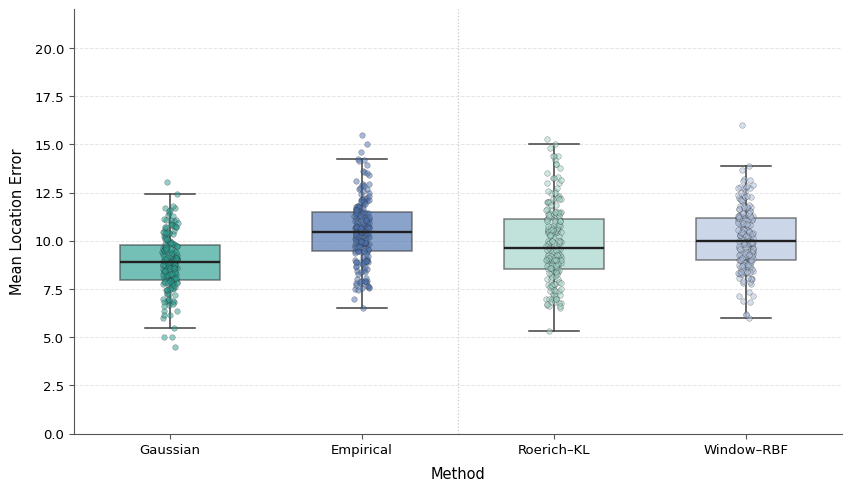

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.442247,0.832105,0.576134,8.885027
1,Empirical,0.348574,0.709474,0.466482,10.462453
2,Roerich-KL,0.417826,0.355526,0.382937,9.881035
3,Window-RBF,0.435389,0.664737,0.525897,10.109337


In [45]:
for w in [25, 30, 40, 50]:
    print("=" * 60)
    print(f"WINDOW SIZE: {w}")
    print("=" * 60)
    ruta_sen = f"Resultados_Series_Simuladas/Sen_Temporal_Dependency/Tables/sen_metrics_window_{w}.xlsx"

    hojas = pd.read_excel(ruta_sen, sheet_name=None)

    listas = [df.to_dict(orient="records") for df in hojas.values()]

    lista_gauss, lista_emp, lista_roerich, lista_window_rbf = listas

    nombres_boxplot = [
                        "Gaussian",
                        "Empirical",
                        "Roerich–KL",
                        "Window–RBF"
                    ]

    metrics_names = ['F1 Score', 'Precision', 'Recall', 'Mean Location Error']
    for n in metrics_names:
        ylim = (0, 1.02)
        name = n
        if n == 'Mean Location Error':
            ylim = (0, 22)
            name = 'MLE'
        path_fig = f"Resultados_Series_Simuladas/Sen_Temporal_Dependency/Graphics/Window {w}/{name}_Sen_w{w}.png"
        fig, ax = plot_boxplots(
                                datos=[
                                    [m[n] for m in lista_gauss],
                                    [m[n] for m in lista_emp],
                                    [m[n] for m in lista_roerich],
                                    [m[n] for m in lista_window_rbf]
                                ],
                                nombres=nombres_boxplot,
                                ylabel=n,
                                xlabel="Method",
                                ylim=ylim,
                                save_path = path_fig
                            )

    ruta_avg_sen = f"Resultados_Series_Simuladas/Sen_Temporal_Dependency/Tables/sen_metrics_avg_window_{w}.xlsx"
    average_table = generar_tabla_desde_diccionarios(
                                                        [lista_gauss, lista_emp, lista_roerich, lista_window_rbf],
                                                        ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                        ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                        )
    display(average_table)
    average_table.to_excel(ruta_avg_sen, index=False)

# 3. Optimización Hiperparámetros

## 3.1. AR(1)

In [ ]:
metricas_ar1_gauss_opt = []
metricas_ar1_emp_opt = []

experimentos_gauss_opt = []
experimentos_emp_opt = []
for i in range(200):
    print(i)
    ar1, cps_ar1, segmentos_ar1 = generar_experimento_ar1(
                N=2000,
                n_segmentos=20,
                min_sep=50,
                max_sep=150,
                seed=1234+i
            )

    
    metricas_ar1_gauss_opt.append(
                                            best_params_sh(
                                                                ar1,
                                                                cps_ar1,
                                                                penal=True,
                                                                path='',
                                                                name=f"AR1_{i+1}",
                                                                modo="Gaussiano",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 30,
                                                                max_w = 200,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                
                                                                save_fig=False,
                                                                temporal_comp=True)[0])

    metricas_ar1_emp_opt.append(
                                        best_params_sh(
                                                            ar1,
                                                            cps_ar1,
                                                            penal=True,
                                                            path='',
                                                            name=f"AR1_{i+1}",
                                                            modo="Empírico",
                                                            given=False,
                                                            thr_dist=20,
                                                            min_w = 30,
                                                            max_w = 200,
                                                            smooth_distances=True,
                                                            save_fig=False,
                                                            temporal_comp=True)[0]
        )

0

════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 34.0000

Selección final
───────────────
    Ventana óptima              : 39
    Penalización mínima         : 0.0026
    Gamma final                 : 0.0053
    Tiempo de búsqueda          : 11.0740
    [OK] Optimización finalizada
1

════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización

In [49]:
exportar_excel(metricas_ar1_gauss_opt, metricas_ar1_emp_opt, "Experimentos/I/ar1_metricas.xlsx", "Gauss", "Empírica")

## 3.2. AR(2)

0

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 20.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 20.0000

Dispersion of Cost
──────────────────
    Execution Time              : 13.6892 s
    Best Window                 : 54

Dispersion of Cost
──────────────────
    Execution Time              : 13.6892 s
    Best Window                 : 54

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 54

Selección final
────

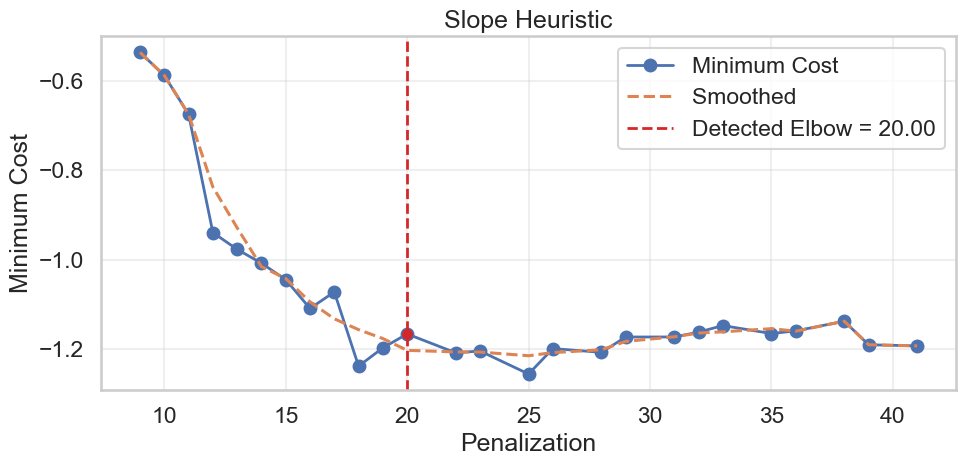

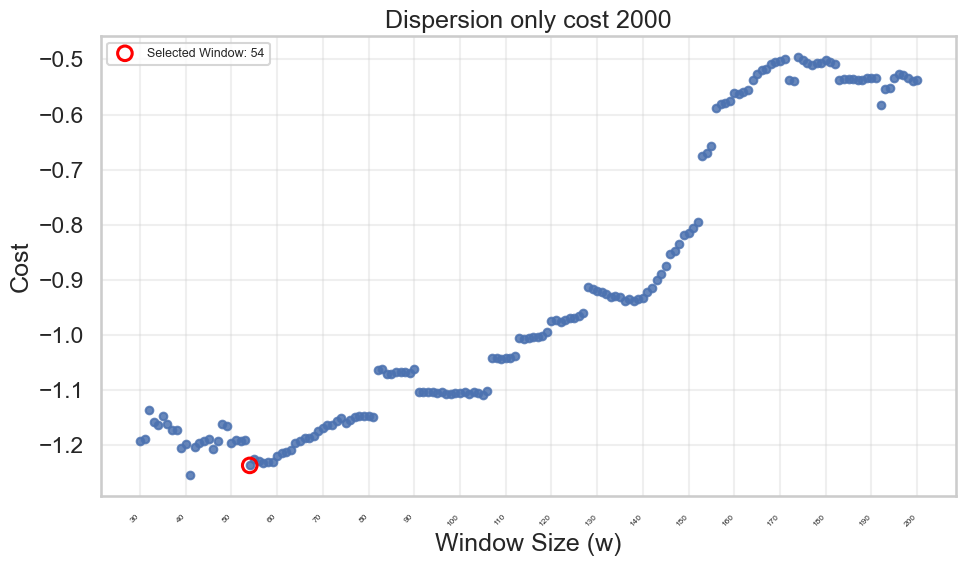

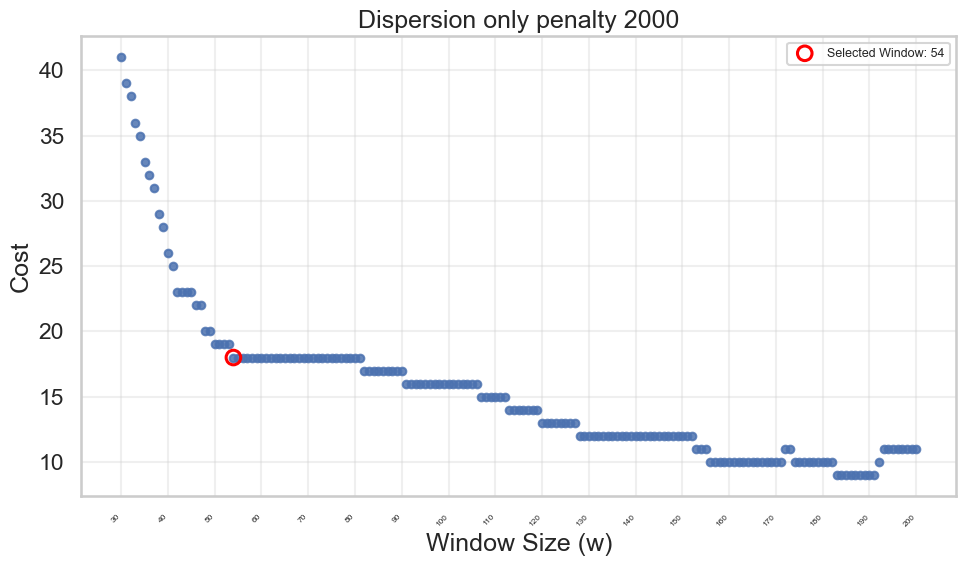

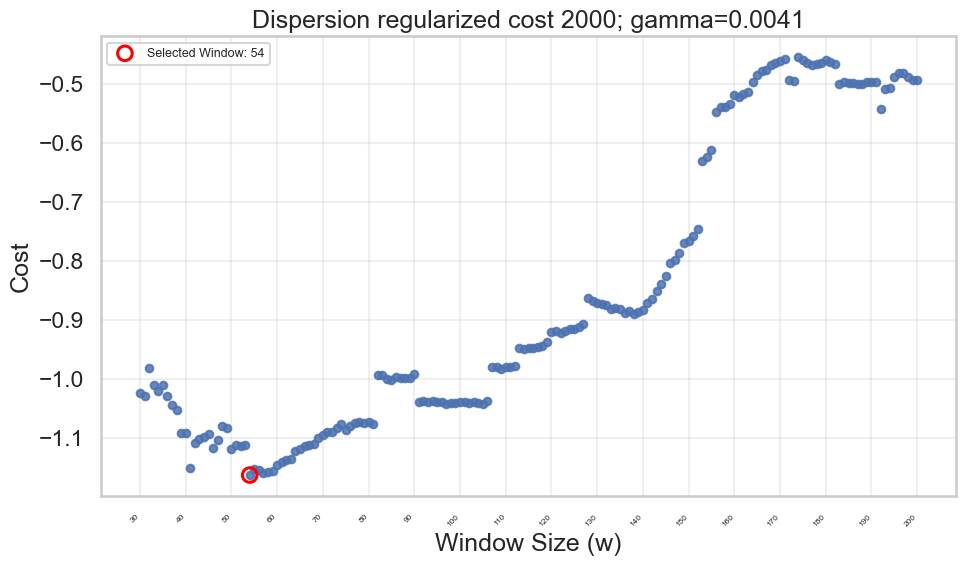

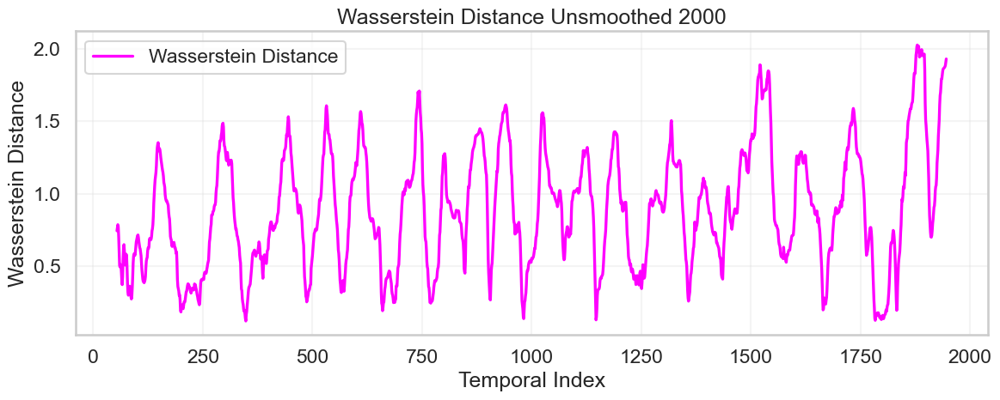

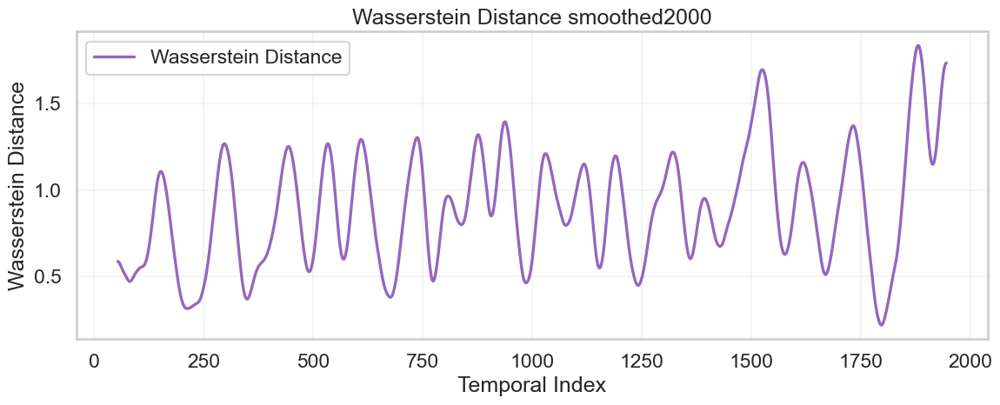

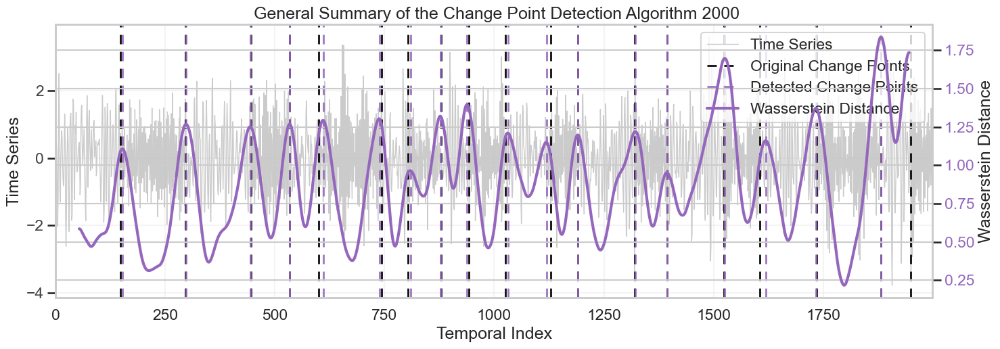


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 28.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 28.0000

Dispersion of Cost
──────────────────
    Execution Time              : 10.3589 s
    Best Window                 : 46

Dispersion of Cost
──────────────────
    Execution Time              : 10.3589 s
    Best Window                 : 46

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 46

Selección final
──────

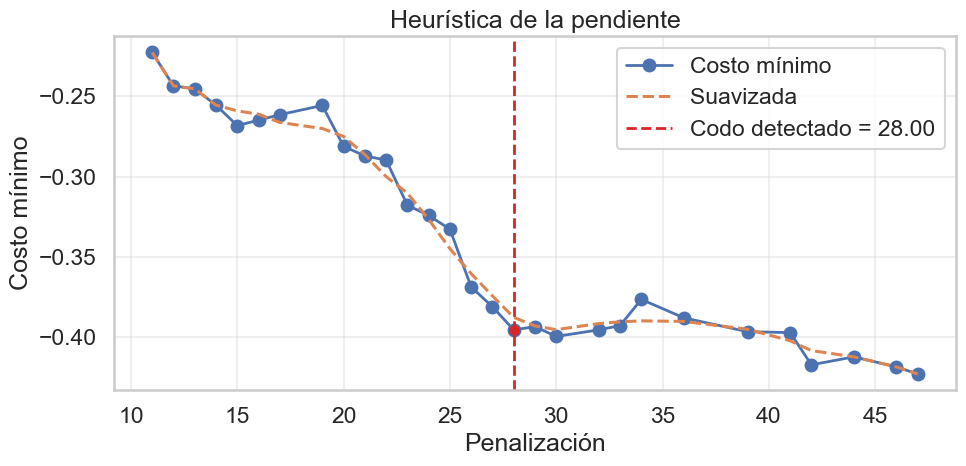

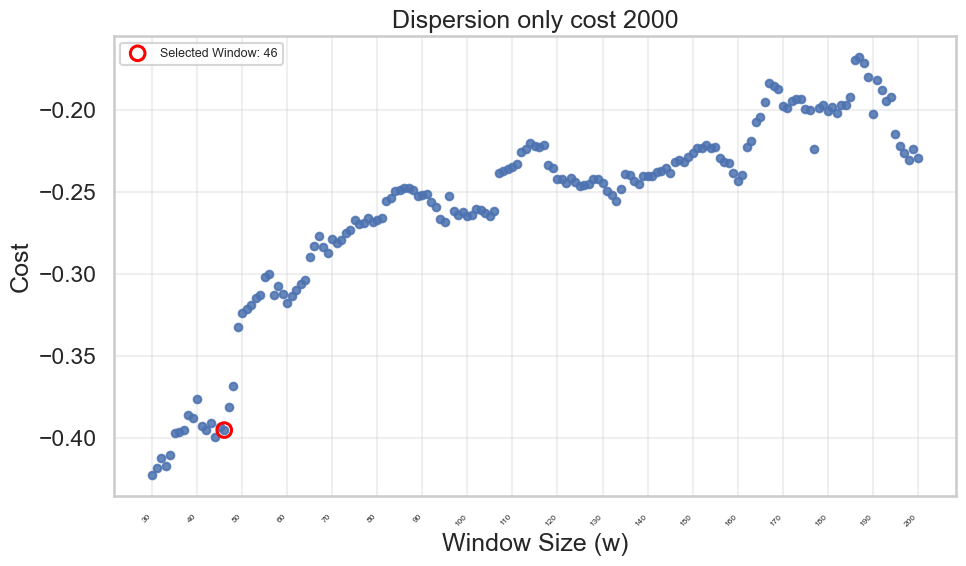

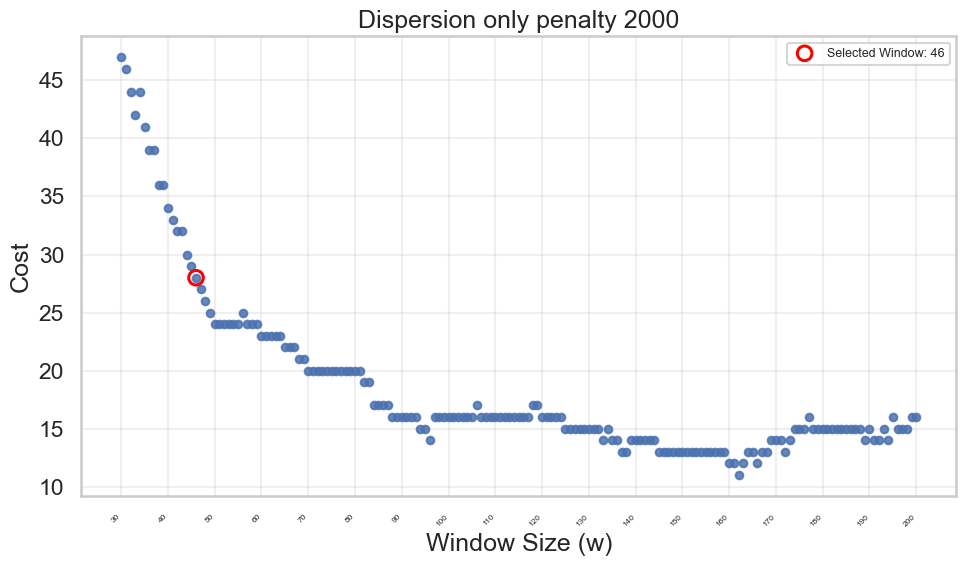

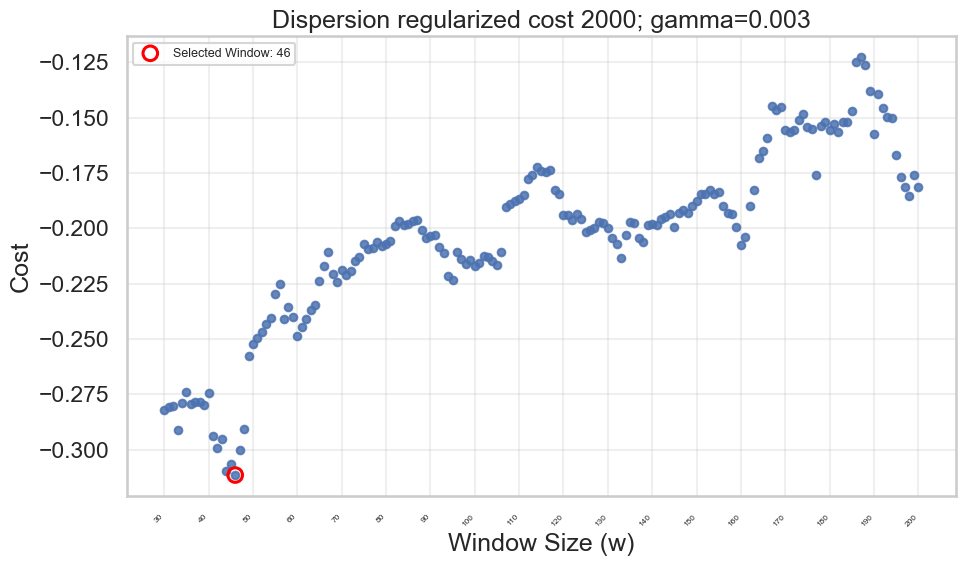

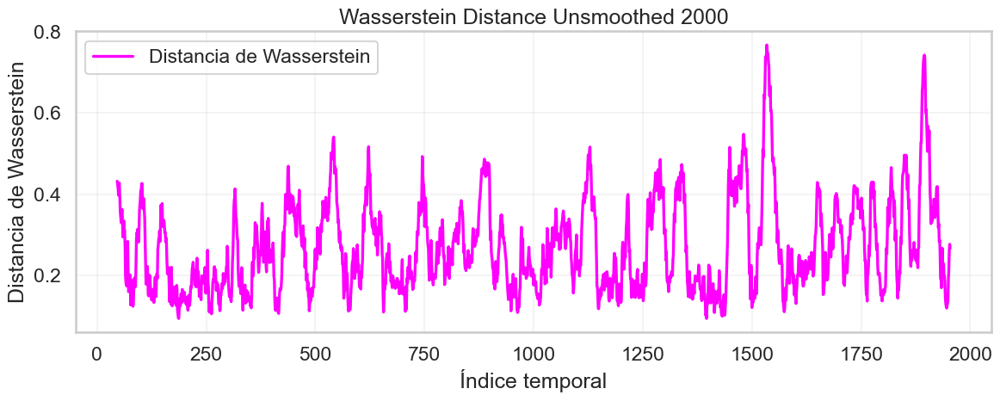

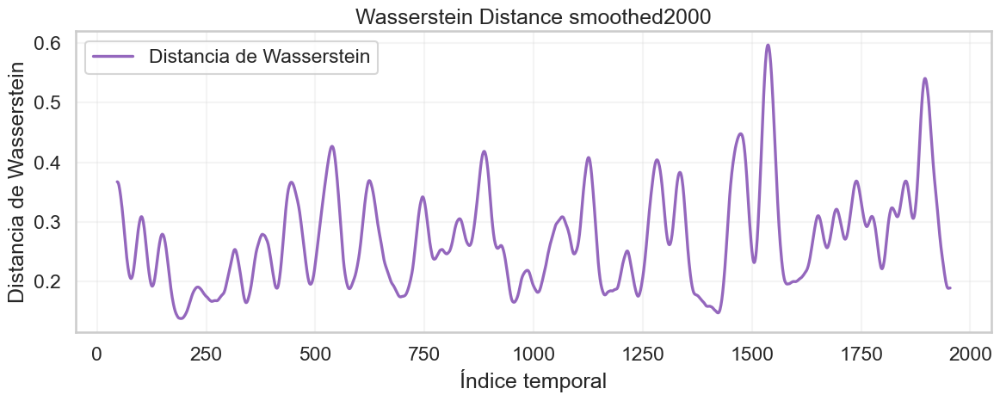

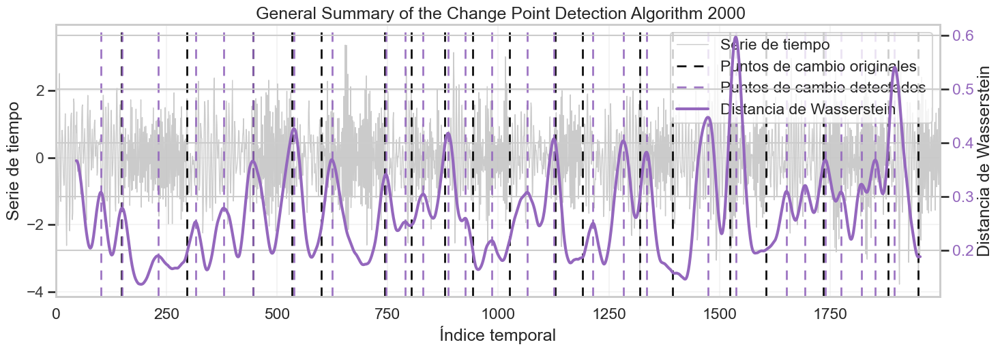

1

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.4354 s
    Best Window                 : 71

Dispersion of Cost
──────────────────
    Execution Time              : 14.4354 s
    Best Window                 : 71

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 71

Selección final
────

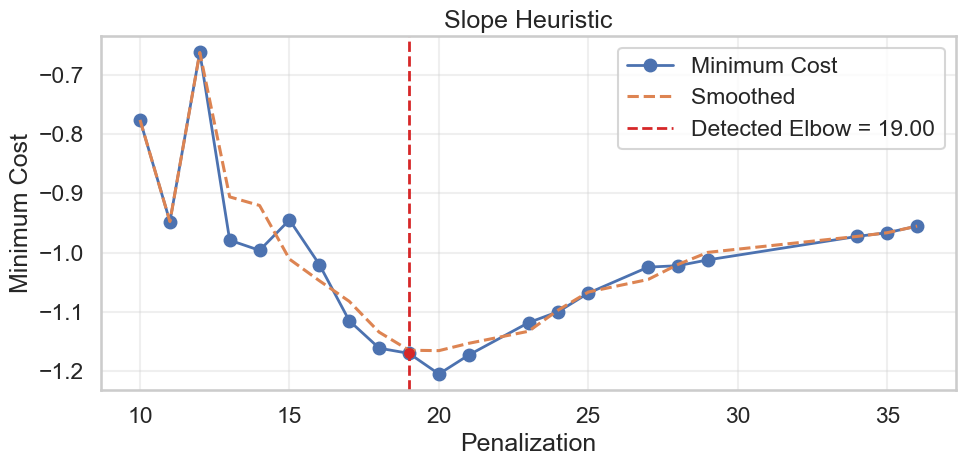

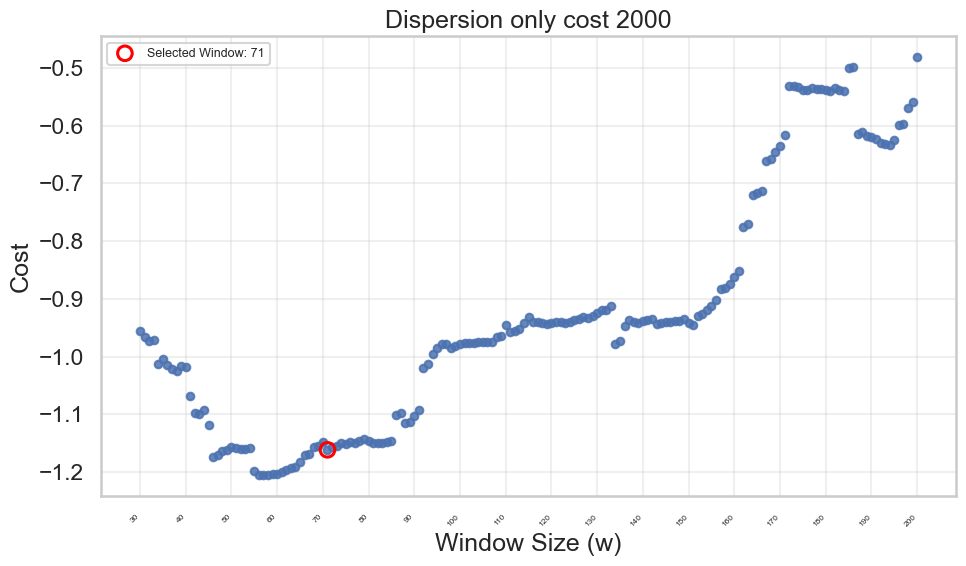

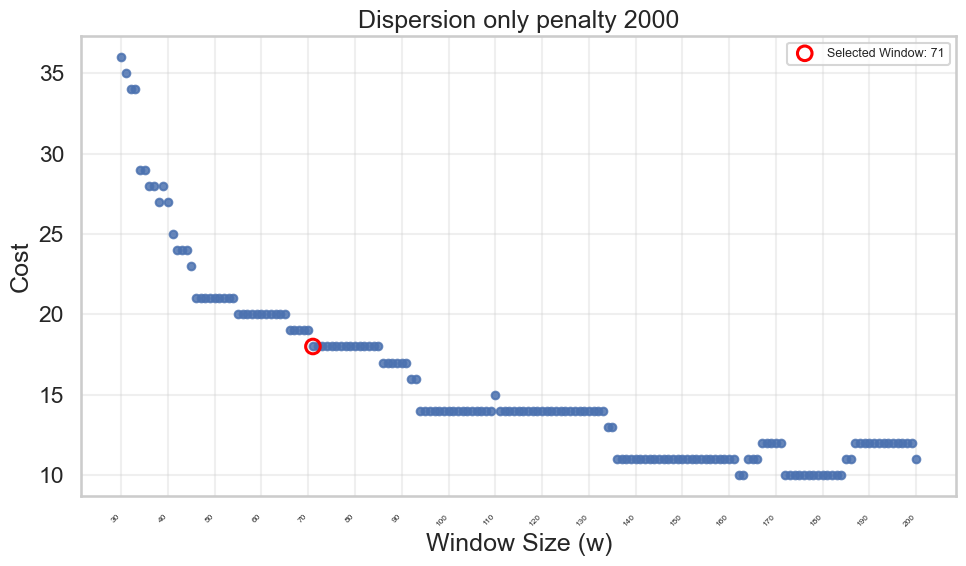

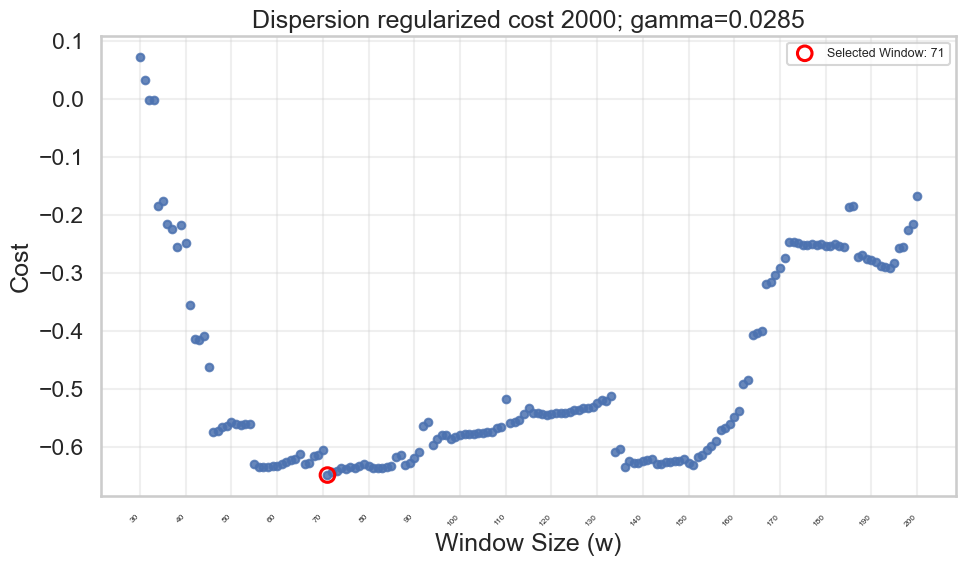

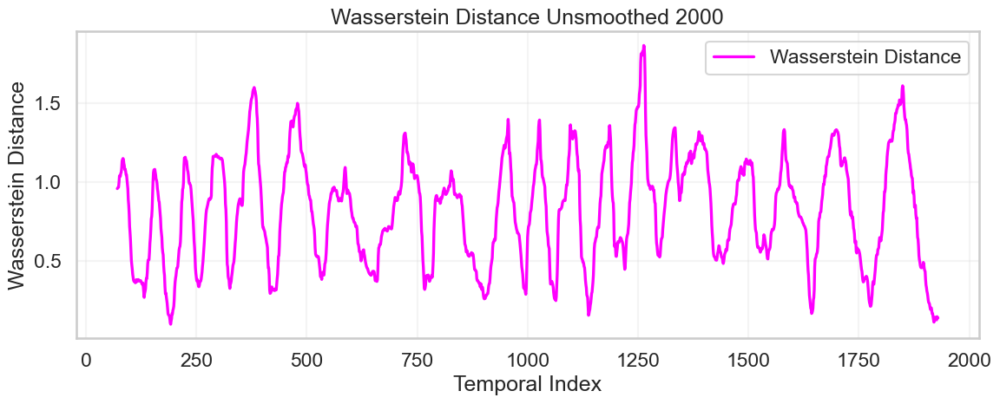

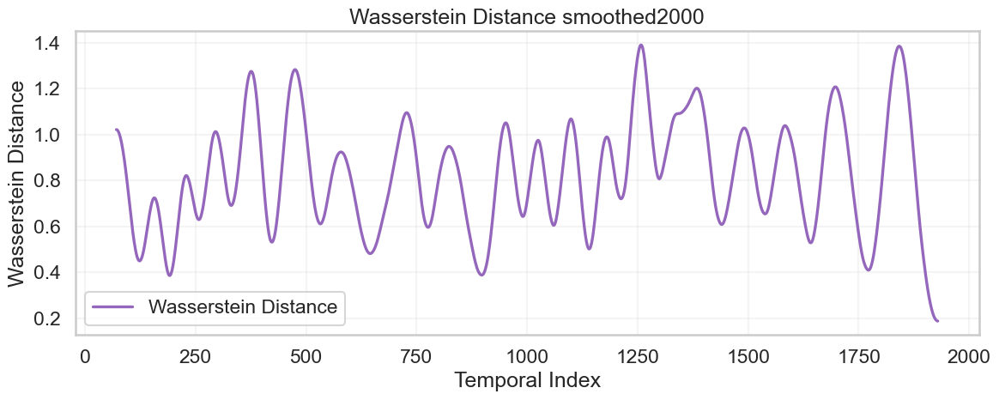

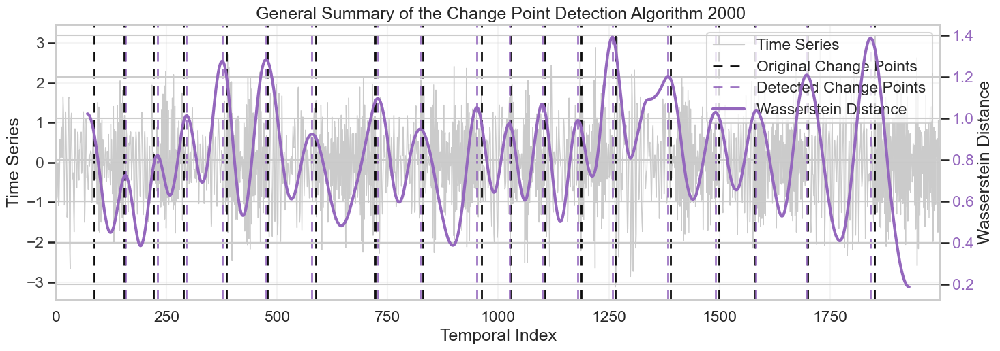


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 11.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 11.0000

Dispersion of Cost
──────────────────
    Execution Time              : 11.0095 s
    Best Window                 : 144

Dispersion of Cost
──────────────────
    Execution Time              : 11.0095 s
    Best Window                 : 144

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 144

Selección final
───

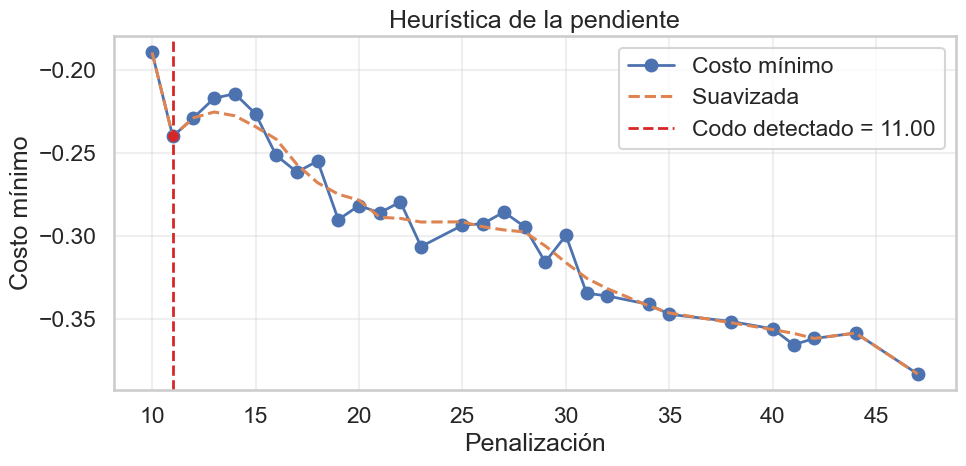

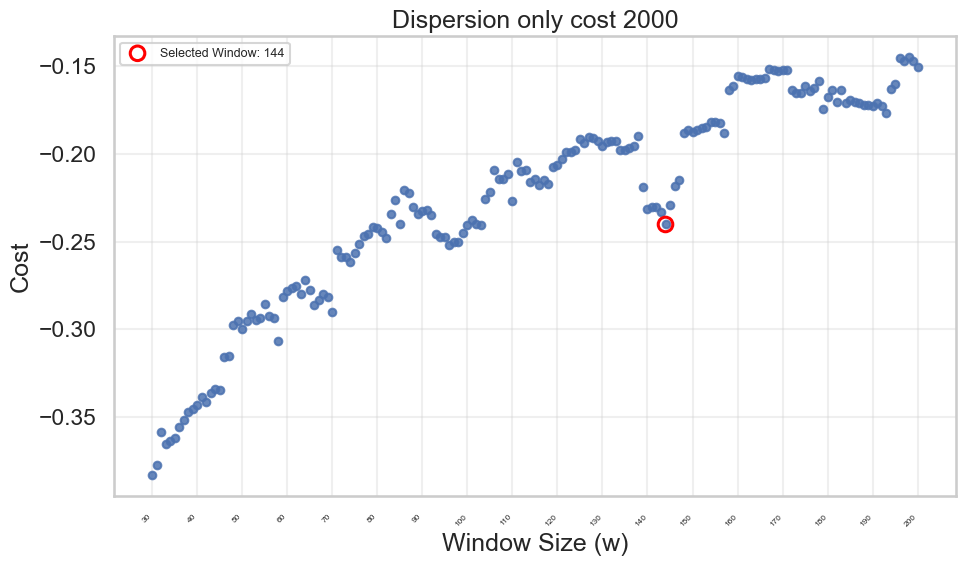

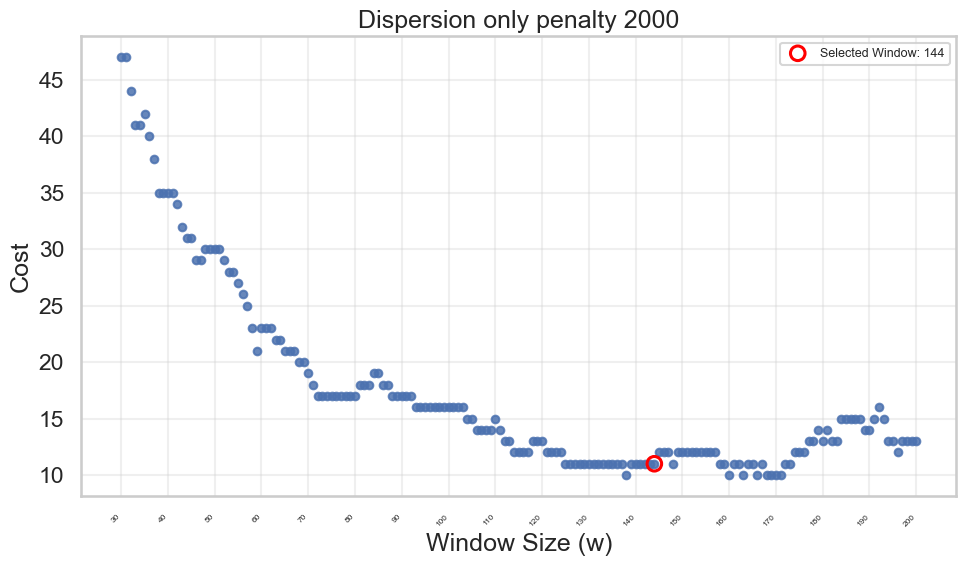

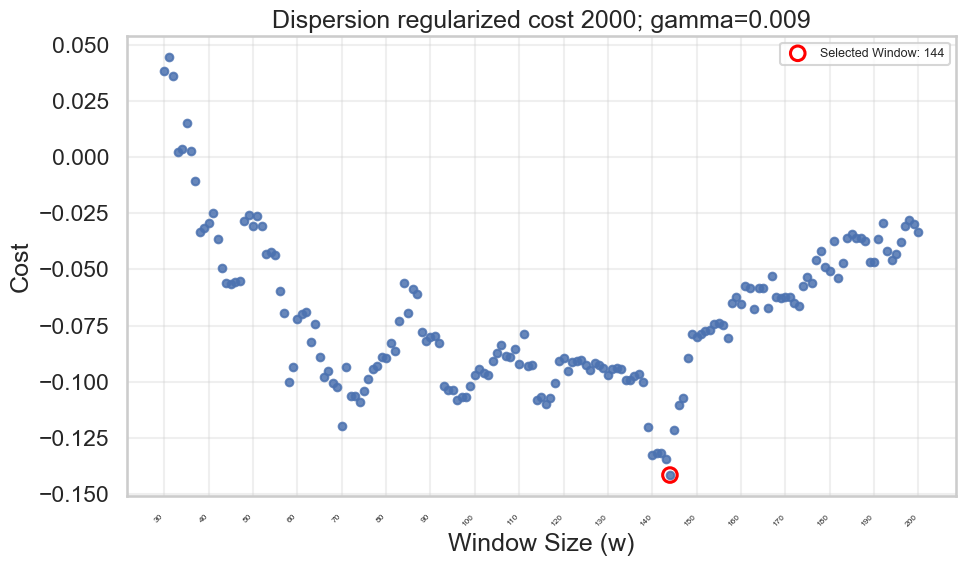

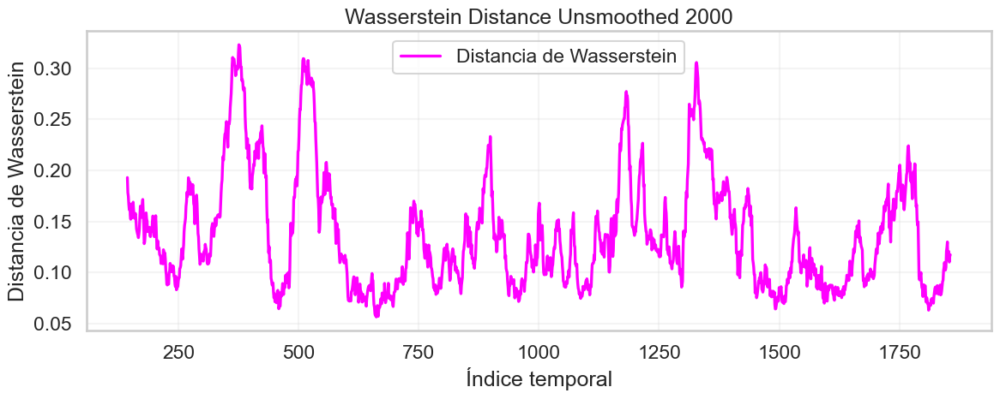

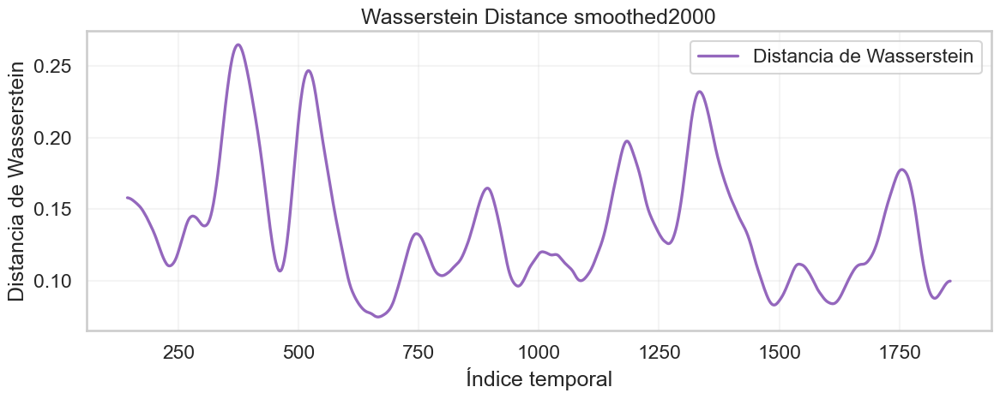

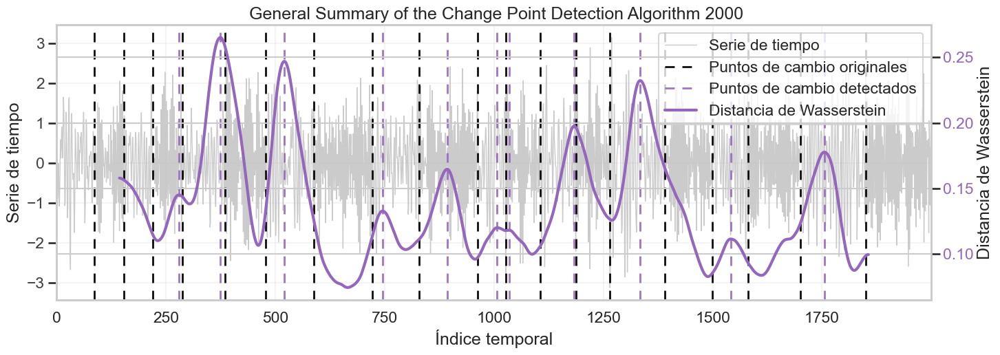

2

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.8969 s
    Best Window                 : 54

Dispersion of Cost
──────────────────
    Execution Time              : 14.8969 s
    Best Window                 : 54

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 54

Selección final
────

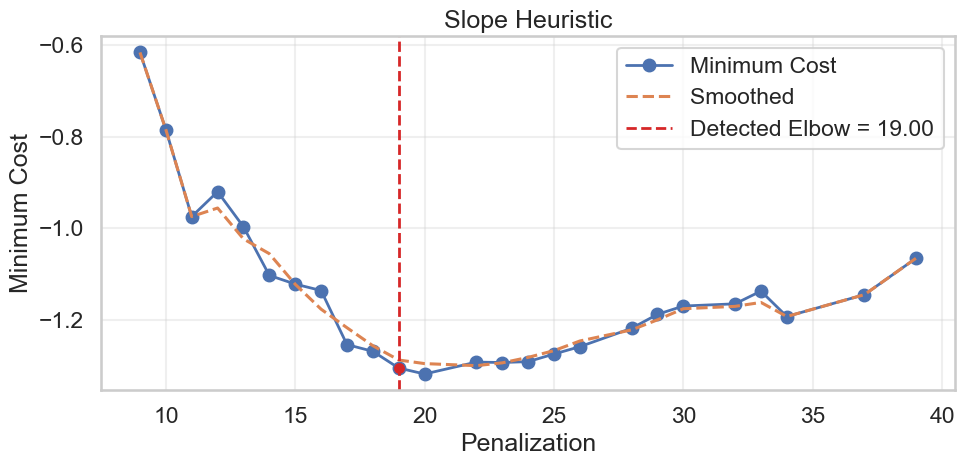

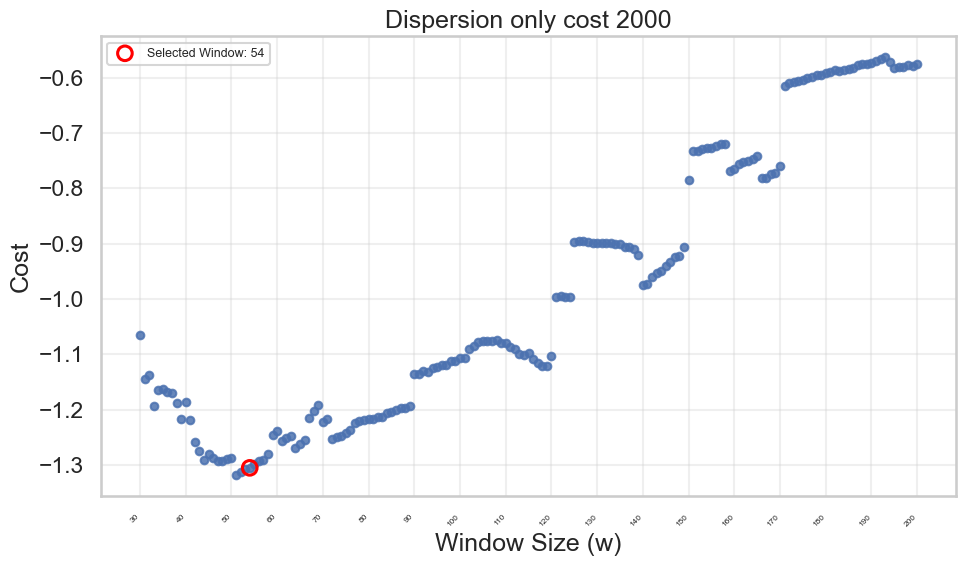

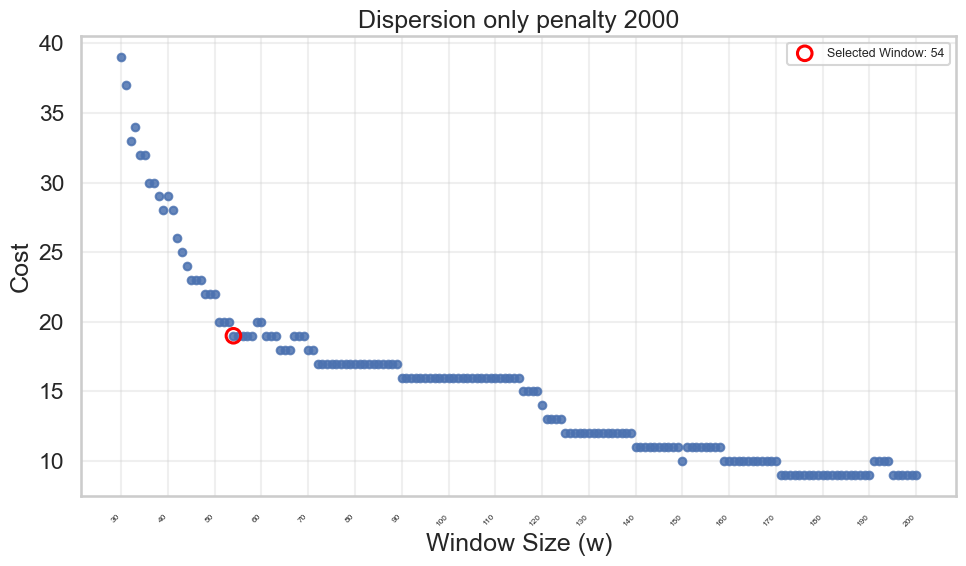

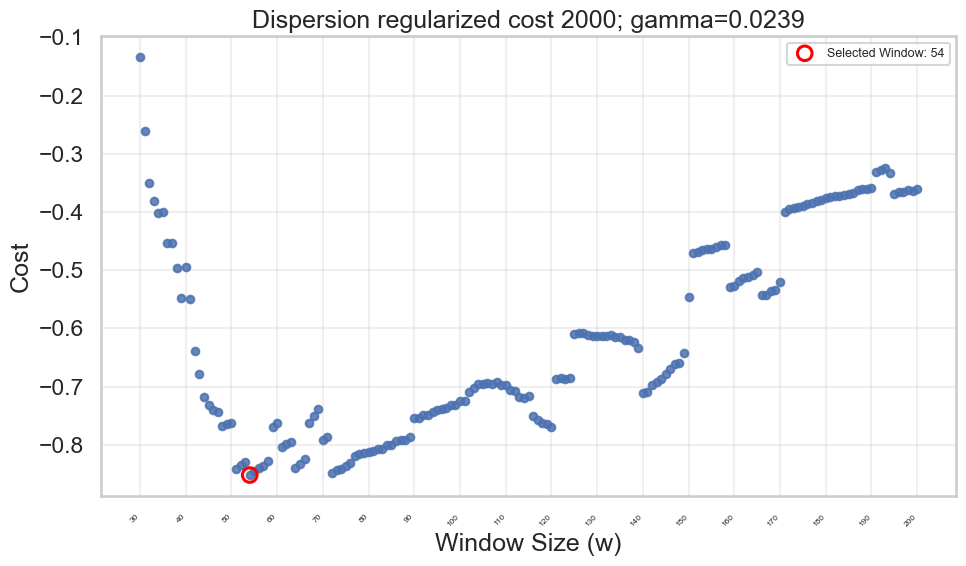

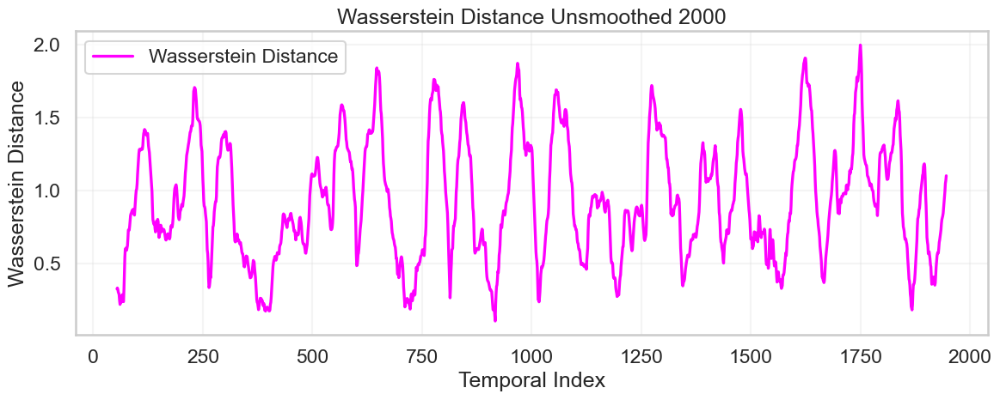

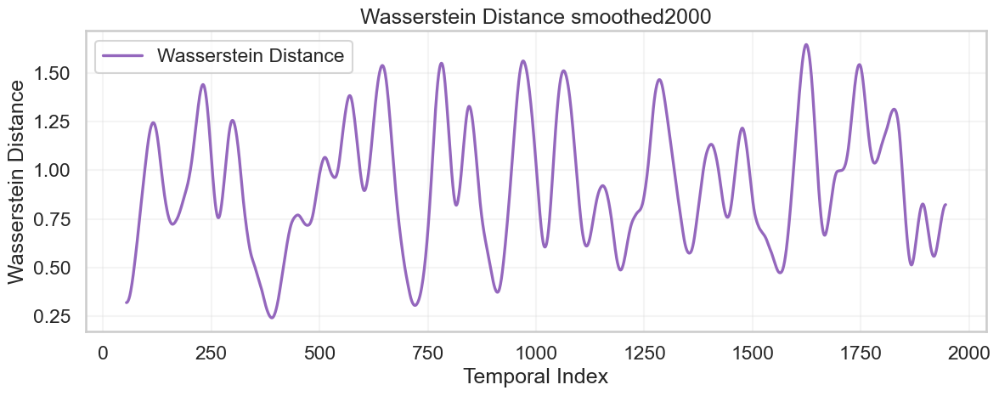

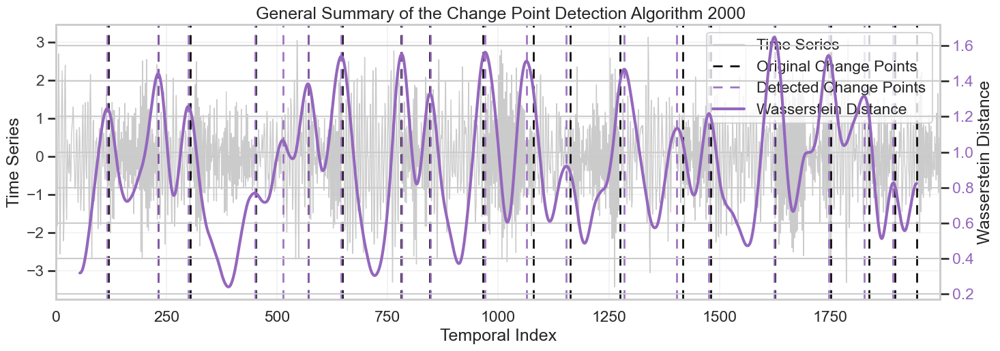


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 20.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 20.0000

Dispersion of Cost
──────────────────
    Execution Time              : 11.2876 s
    Best Window                 : 58

Dispersion of Cost
──────────────────
    Execution Time              : 11.2876 s
    Best Window                 : 58

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 58

Selección final
──────

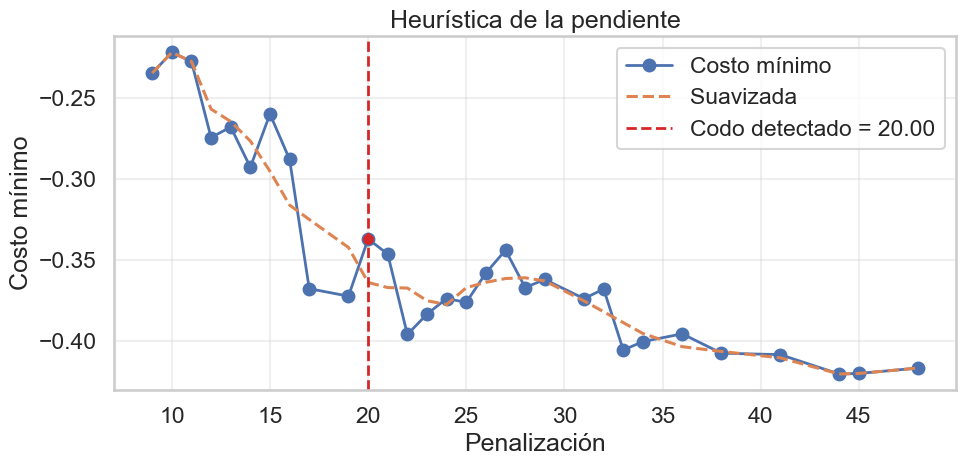

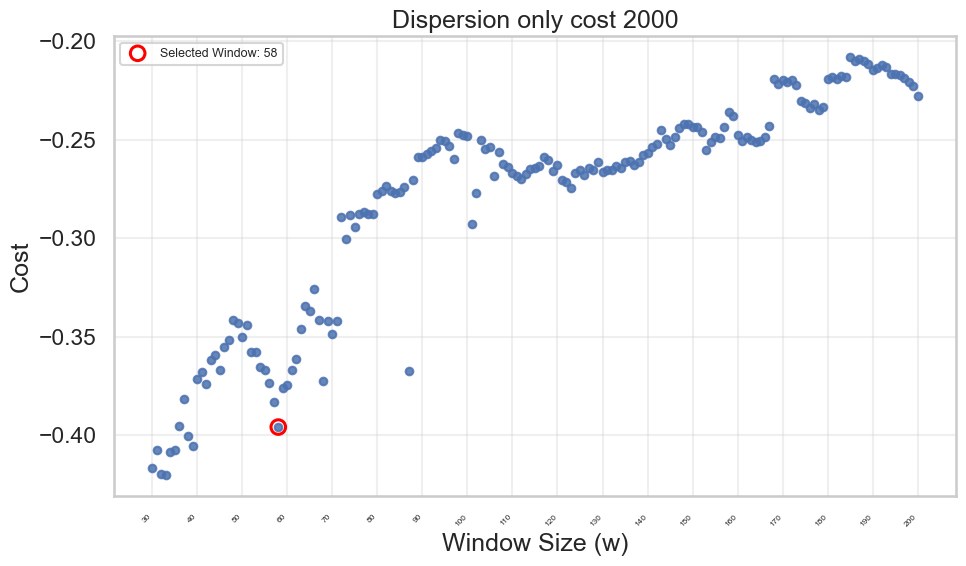

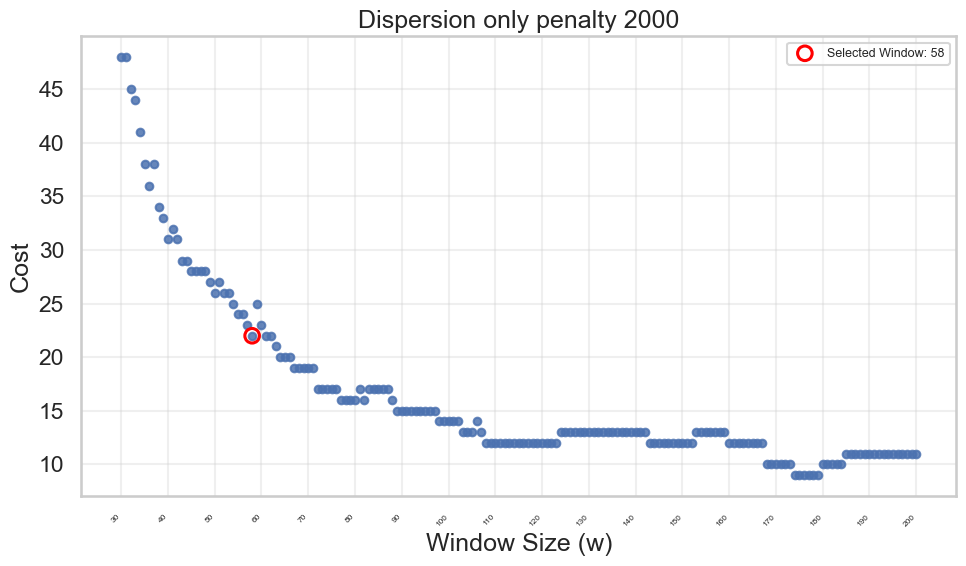

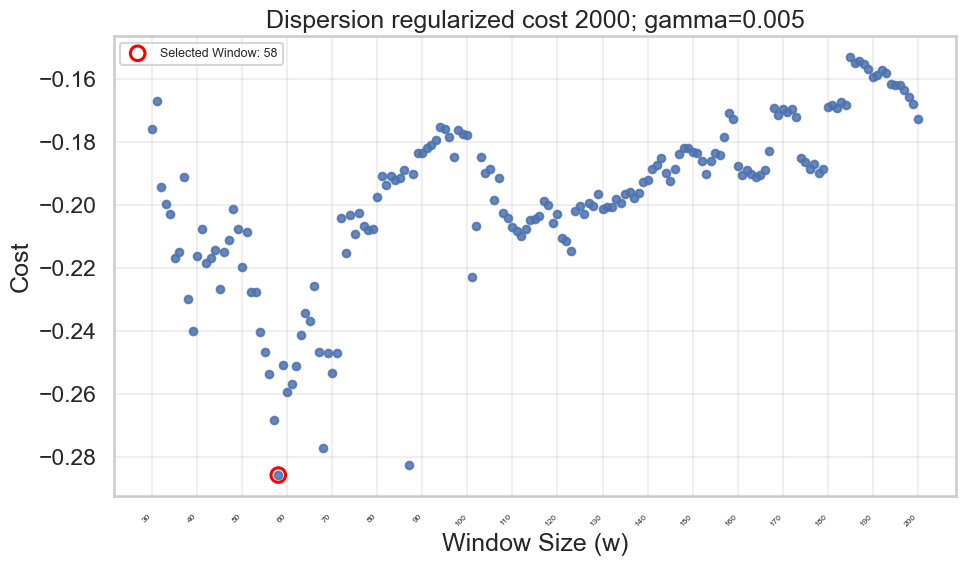

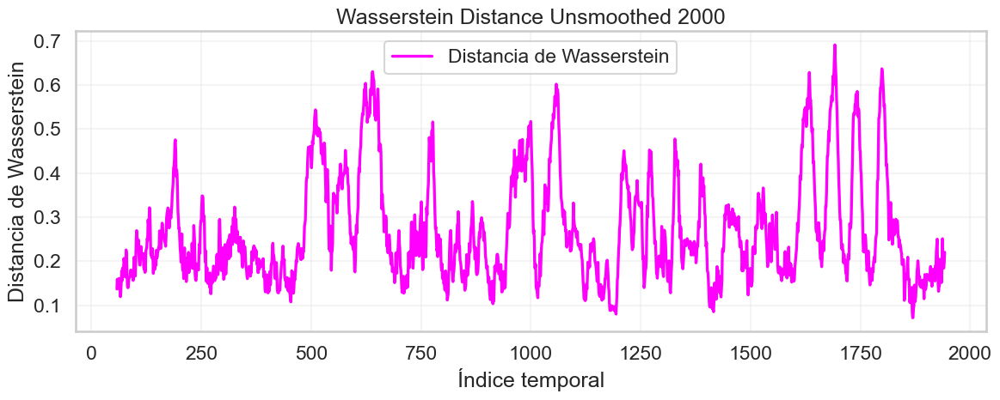

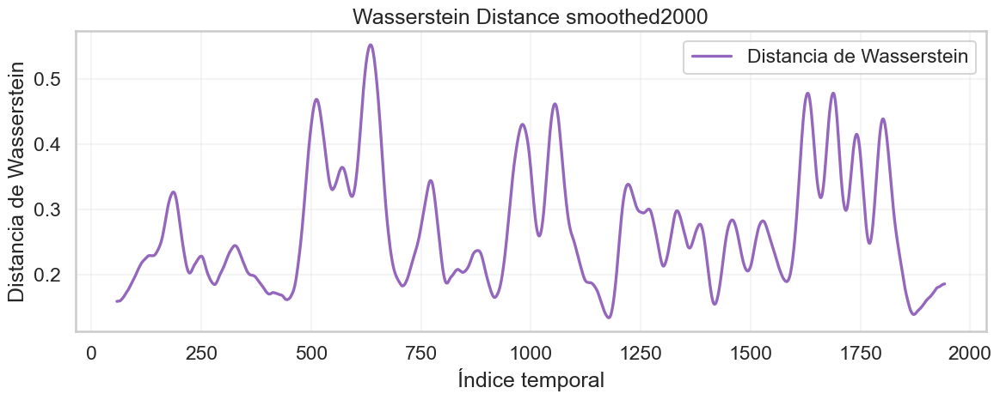

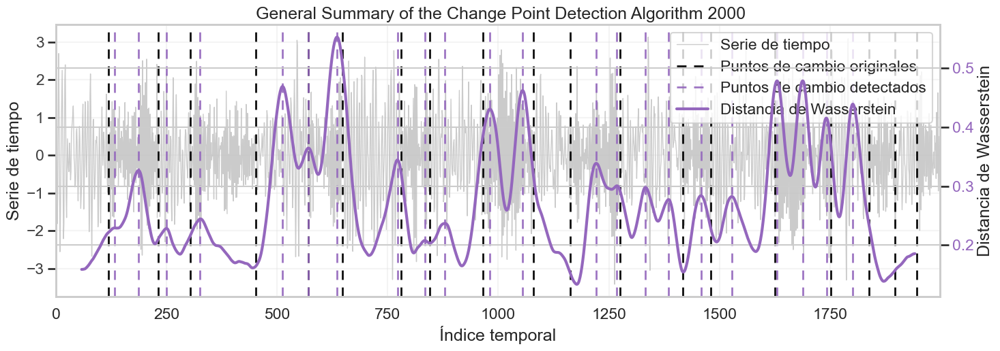

In [3]:
metricas_ar2_gauss_opt = []
metricas_ar2_emp_opt = []

experimentos_gauss_opt = []
experimentos_emp_opt = []
for i in range(3):
    print(i)
    ar2, cps_ar2, segmentos_ar2 = generar_experimento_ar2(
                N=2000,
                n_segmentos=20,
                min_sep=50,
                max_sep=150,
                seed=1234+i
            )

    metricas_ar2_gauss_opt.append(
                                    best_params_sh(
                                                        ar2,
                                                        cps_ar2,
                                                        penal=True,
                                                        path='',
                                                        name=f"AR2_{i+1}",
                                                        modo="Gaussiano",
                                                        given=False,
                                                        thr_dist=20,
                                                        min_w = 30,
                                                        max_w = 200,
                                                        t_given=1,
                                                        smooth_distances=True,
                                                        visualization={
                                                            "summary": True,
                                                            "raw_distance": True,
                                                            "smooth_distance": True,
                                                            "cost": True,
                                                            "slope": True,
                                                        },
                                                        save_fig=False,
                                                        temporal_comp=True)[0]
    )

    metricas_ar2_emp_opt.append(
                                            best_params_sh(
                                                                ar2,
                                                                cps_ar2,
                                                                penal=True,
                                                                path='',
                                                                name=f"AR2_{i+1}",
                                                                modo="Empírico",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 30,
                                                                max_w = 200,
                                                                smooth_distances=True,
                                                                visualization={
                                                                    "summary": True,
                                                                    "raw_distance": True,
                                                                    "smooth_distance": True,
                                                                    "cost": True,
                                                                    "slope": True,
                                                                },
                                                                save_fig=False,
                                                                temporal_comp=True)[0]
    )

In [ ]:
metricas_ar2_gauss_opt = []
metricas_ar2_emp_opt = []

experimentos_gauss_opt = []
experimentos_emp_opt = []
for i in range(200):
    print(i)
    ar2, cps_ar2, segmentos_ar2 = generar_experimento_ar2(
                N=2000,
                n_segmentos=20,
                min_sep=50,
                max_sep=150,
                seed=1234+i
            )

    metricas_ar2_gauss_opt.append(
                                    best_params_sh(
                                                        ar2,
                                                        cps_ar2,
                                                        penal=True,
                                                        path='',
                                                        name=f"AR2_{i+1}",
                                                        modo="Gaussiano",
                                                        given=False,
                                                        thr_dist=20,
                                                        min_w = 30,
                                                        max_w = 200,
                                                        t_given=1,
                                                        smooth_distances=True,
                                                        visualization={
                                                            "summary": True,
                                                            "raw_distance": True,
                                                            "smooth_distance": True,
                                                            "cost": True,
                                                            "slope": True,
                                                        },
                                                        save_fig=False,
                                                        temporal_comp=True)[0]
    )

    metricas_ar2_emp_opt.append(
                                            best_params_sh(
                                                                ar2,
                                                                cps_ar2,
                                                                penal=True,
                                                                path='',
                                                                name=f"AR2_{i+1}",
                                                                modo="Empírico",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 30,
                                                                max_w = 200,
                                                                smooth_distances=True,
                                                            
                                                                save_fig=False,
                                                                temporal_comp=True)[0]
    )

In [54]:
exportar_excel(metricas_ar2_gauss_opt, metricas_ar2_emp_opt, "Experimentos/II/ar2_metricas.xlsx", "Gauss", "Empírica")

## 3.3. Senoidal

In [ ]:
metricas_sen_gauss_opt = []
metricas_sen_emp_opt = []

experimentos_gauss_opt = []
experimentos_emp_opt = []
for i in range(200):
    print(i)
    sen, cps_sen, segmentos_sen = generar_experimento_senoidal(
                N=2000,
                n_segmentos=20,
                min_sep=50,
                max_sep=150,
                seed=1234+i
            )

    metricas_sen_gauss_opt.append(
                                    best_params_sh(
                                                        sen,
                                                        cps_sen,
                                                        penal=True,
                                                        path='',
                                                        name=f"SEN_{i+1}",
                                                        modo="Gaussiano",
                                                        given=False,
                                                        thr_dist=20,
                                                        min_w = 30,
                                                        max_w = 200,
                                                        t_given=1,
                                                        smooth_distances=True,
                                                        save_fig=False,
                                                        temporal_comp=True)[0]
    )

    metricas_sen_emp_opt.append(
                                            best_params_sh(
                                                                sen,
                                                                cps_sen,
                                                                penal=True,
                                                                path='',
                                                                name=f"SEN_{i+1}",
                                                                modo="Empírico",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 30,
                                                                max_w = 200,
                                                                smooth_distances=True,
                                                            
                                                                save_fig=False,
                                                                temporal_comp=True)[0]
    )

0

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 7.0000

Selección final
───────────────
    Ventana óptima              : 196
    Retardo óptimo              : 1
    Penalización mínima         : 0.0084
    Gamma final                 : 0.0167
    Tiempo de búsqueda          : 16.2380
    [OK] Optimización finalizada

════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie  

In [55]:
exportar_excel(metricas_sen_gauss_opt, metricas_sen_emp_opt, "Experimentos/III/sen_metricas.xlsx", "Gauss", "Empírica")

# 4. Boxplots y Resultados por Método (Benchmark)

## 4.1. AR(1)

In [ ]:
import pandas as pd

ruta_ar1 = "Resultados_Series_Simuladas/AR(1)_Temporal_Dependency/ar1_metricas.xlsx"

hojas = pd.read_excel(ruta_ar1, sheet_name=None)

# Convertir cada hoja en una lista de diccionarios
listas = [df.to_dict(orient="records") for df in hojas.values()]

# Extraer las 4 listas
lista_gauss, lista_emp, lista_roerich, lista_window_rbf, metricas_ar1_gauss_fw, metricas_ar1_emp_fw = listas

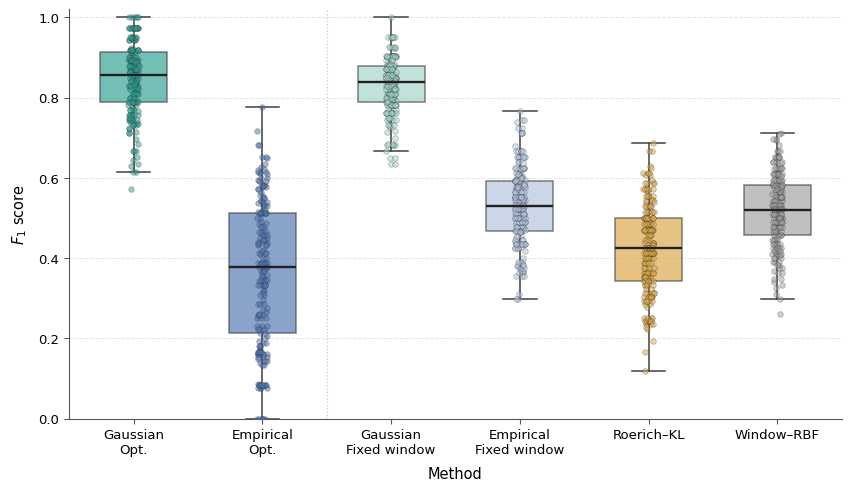

In [8]:
nombres_boxplot = [
    "Gaussian\nOpt.",
    "Empirical\nOpt.",
    "Gaussian\nFixed window",
    "Empirical\nFixed window",
    "Roerich–KL",
    "Window–RBF"
]

fig, ax = plot_boxplots(
    datos=[
        [m['F1 Score'] for m in lista_gauss],
        [m['F1 Score'] for m in lista_emp],
        [m['F1 Score'] for m in metricas_ar1_gauss_fw],
        [m['F1 Score'] for m in metricas_ar1_emp_fw],
        [m['F1 Score'] for m in lista_roerich],
        [m['F1 Score'] for m in lista_window_rbf]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"$F_1$ score",
    xlabel="Method",
    ylim=(0, 1.02)
)

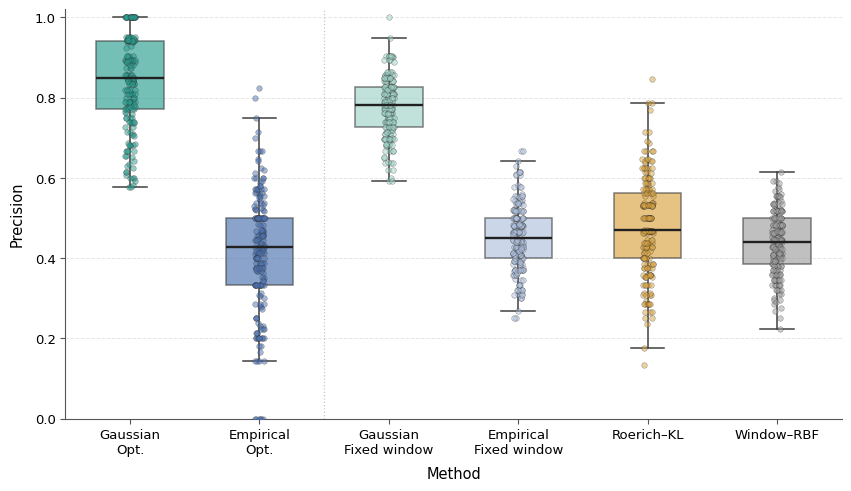

In [9]:
fig, ax = plot_boxplots(
    datos=[
        [m['Precision'] for m in lista_gauss],
        [m['Precision'] for m in lista_emp],
        [m['Precision'] for m in metricas_ar1_gauss_fw],
        [m['Precision'] for m in metricas_ar1_emp_fw],
        [m['Precision'] for m in lista_roerich],
        [m['Precision'] for m in lista_window_rbf]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"Precision",
    xlabel="Method",
    ylim=(0, 1.02)
)

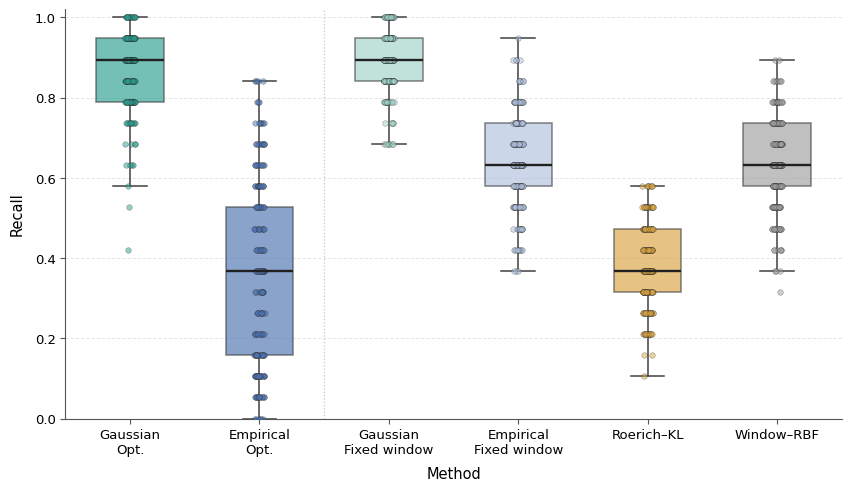

In [10]:
fig, ax = plot_boxplots(
    datos=[
        [m['Recall'] for m in lista_gauss],
        [m['Recall'] for m in lista_emp],
        [m['Recall'] for m in metricas_ar1_gauss_fw],
        [m['Recall'] for m in metricas_ar1_emp_fw],
        [m['Recall'] for m in lista_roerich],
        [m['Recall'] for m in lista_window_rbf]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"Recall",
    xlabel="Method",
    ylim=(0, 1.02)
)

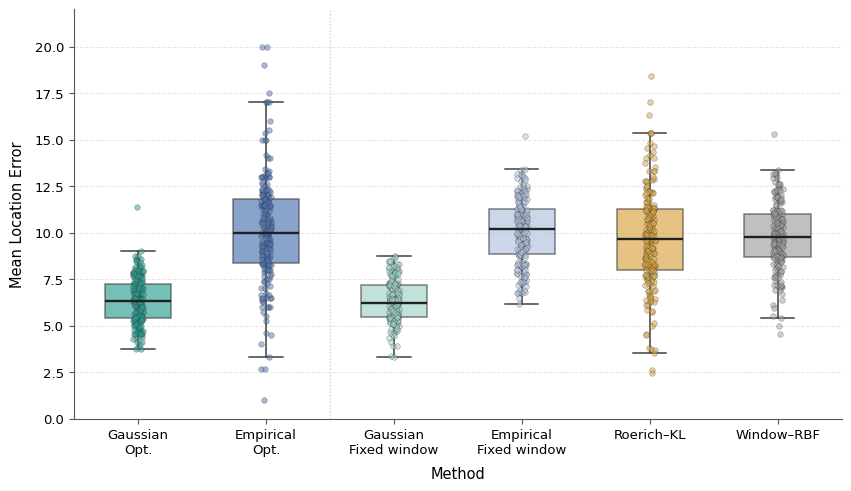

In [13]:
fig, ax = plot_boxplots(
    datos=[
        [m['Mean Location Error'] for m in lista_gauss],
        [m['Mean Location Error'] for m in lista_emp],
        [m['Mean Location Error'] for m in metricas_ar1_gauss_fw],
        [m['Mean Location Error'] for m in metricas_ar1_emp_fw],
        [m['Mean Location Error'] for m in lista_roerich],
        [m['Mean Location Error'] for m in lista_window_rbf]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"Mean Location Error",
    xlabel="Method",
    ylim=(0, 22)
)

In [14]:
generar_tabla_desde_diccionarios(
    [lista_gauss, lista_emp, metricas_ar1_gauss_fw, metricas_ar1_emp_fw, lista_roerich, lista_window_rbf],
    ["Gauss Opt.", "Empirical Opt.", "Gauss-FW", "Empirical-FW", "Roerich-KL", "Window-RBF"],
    ["Precision", "Recall", "F1 Score", "Mean Location Error"]
)

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss Opt.,0.839210,0.864474,0.847328,6.333800
1,Empirical Opt.,0.413130,0.362105,0.363968,10.140555
2,Gauss-FW,0.778205,0.890263,0.829363,6.310890
3,Empirical-FW,0.451595,0.640263,0.528893,10.034853
4,Roerich-KL,0.479285,0.378158,0.421769,9.652348
5,Window-RBF,0.436830,0.633947,0.516827,9.798227


## 4.2. AR(2)

In [ ]:
import pandas as pd

ruta_ar2 = "Resultados_Series_Simuladas/AR(2)_Temporal_Dependency/ar2_metricas.xlsx"

hojas = pd.read_excel(ruta_ar2, sheet_name=None)

# Convertir cada hoja en una lista de diccionarios
listas = [df.to_dict(orient="records") for df in hojas.values()]

# Extraer las 4 listas
lista_gauss_ar2, lista_emp_ar2, lista_roerich_ar2, lista_window_rbf_ar2, metricas_ar2_gauss_fw, metricas_ar2_emp_fw = listas

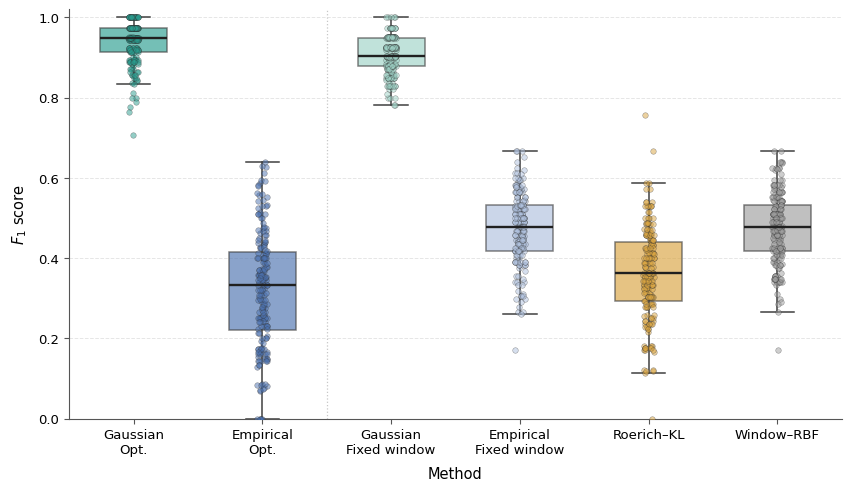

In [17]:
nombres_boxplot = [
    "Gaussian\nOpt.",
    "Empirical\nOpt.",
    "Gaussian\nFixed window",
    "Empirical\nFixed window",
    "Roerich–KL",
    "Window–RBF"
]

fig, ax = plot_boxplots(
    datos=[
        [m['F1 Score'] for m in lista_gauss_ar2],
        [m['F1 Score'] for m in lista_emp_ar2],
        [m['F1 Score'] for m in metricas_ar2_gauss_fw],
        [m['F1 Score'] for m in metricas_ar2_emp_fw],
        [m['F1 Score'] for m in lista_roerich_ar2],
        [m['F1 Score'] for m in lista_window_rbf_ar2]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"$F_1$ score",
    xlabel="Method",
    ylim=(0, 1.02)
)

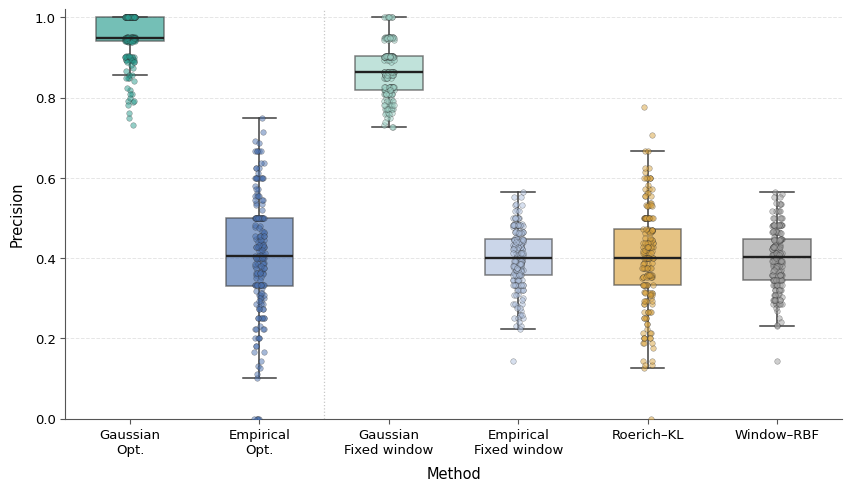

In [18]:
fig, ax = plot_boxplots(
    datos=[
        [m['Precision'] for m in lista_gauss_ar2],
        [m['Precision'] for m in lista_emp_ar2],
        [m['Precision'] for m in metricas_ar2_gauss_fw],
        [m['Precision'] for m in metricas_ar2_emp_fw],
        [m['Precision'] for m in lista_roerich_ar2],
        [m['Precision'] for m in lista_window_rbf_ar2]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"Precision",
    xlabel="Method",
    ylim=(0, 1.02)
)

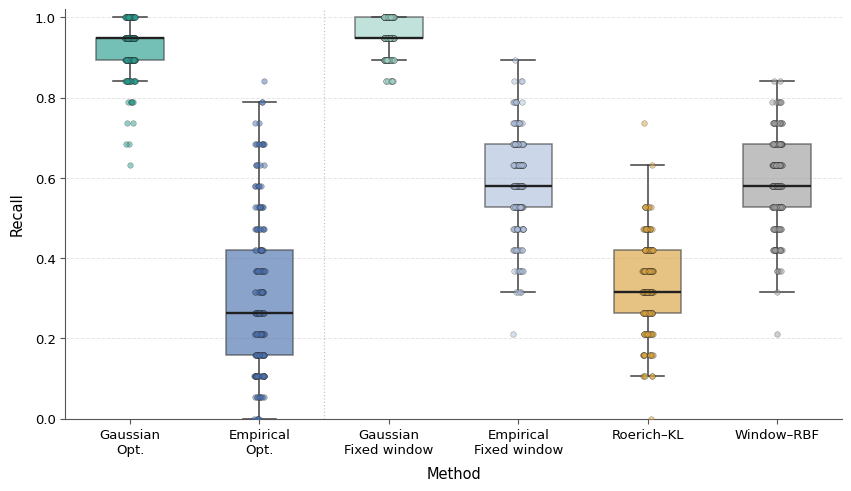

In [ ]:
fig, ax = plot_boxplots(
    datos=[
        [m['Recall'] for m in lista_gauss_ar2],
        [m['Recall'] for m in lista_emp_ar2],
        [m['Recall'] for m in metricas_ar2_gauss_fw],
        [m['Recall'] for m in metricas_ar2_emp_fw],
        [m['Recall'] for m in lista_roerich_ar2],
        [m['Recall'] for m in lista_window_rbf_ar2]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"Recall",
    xlabel="Method",
    ylim=(0, 1.02)
)

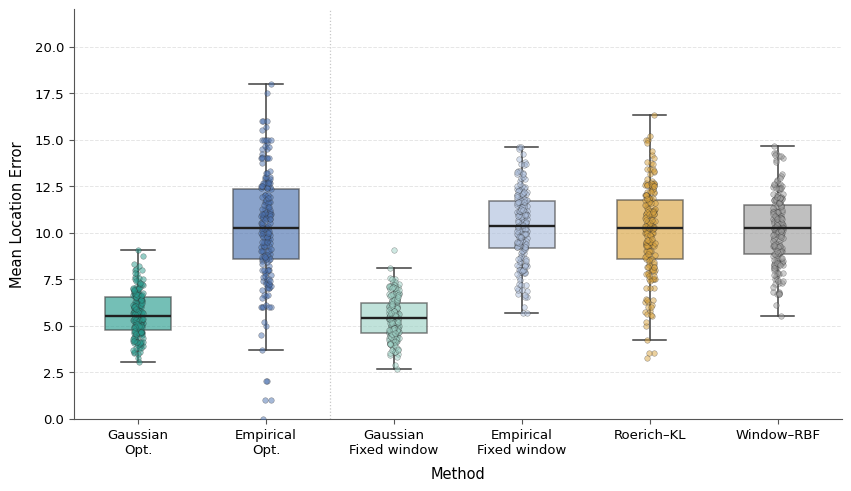

In [21]:
fig, ax = plot_boxplots(
    datos=[
        [m['Mean Location Error'] for m in lista_gauss_ar2],
        [m['Mean Location Error'] for m in lista_emp_ar2],
        [m['Mean Location Error'] for m in metricas_ar2_gauss_fw],
        [m['Mean Location Error'] for m in metricas_ar2_emp_fw],
        [m['Mean Location Error'] for m in lista_roerich_ar2],
        [m['Mean Location Error'] for m in lista_window_rbf_ar2]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"Mean Location Error",
    xlabel="Method",
    ylim=(0, 22)
)

In [22]:
generar_tabla_desde_diccionarios(
    [lista_gauss_ar2, lista_emp_ar2, metricas_ar2_gauss_fw, metricas_ar2_emp_fw, lista_roerich_ar2, lista_window_rbf_ar2],
    ["Gauss-Opt", "Empirical-Opt", "Gauss-FW", "Empirical-FW", "Roerich-KL", "Window-RBF"],
    ["Precision", "Recall", "F1 Score", "Mean Location Error"]
)

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss-Opt,0.950207,0.925789,0.936329,5.632980
1,Empirical-Opt,0.405640,0.301316,0.320329,10.234414
2,Gauss-FW,0.863768,0.956842,0.906835,5.429831
3,Empirical-FW,0.399031,0.582632,0.473082,10.317305
4,Roerich-KL,0.400600,0.332368,0.362107,10.062784
5,Window-RBF,0.398424,0.587632,0.474572,10.179409


## 4.3. Senoidal

In [ ]:
import pandas as pd

ruta_sen = "Resultados_Series_Simuladas/Sen_Temporal_Dependency/sen_metricas.xlsx"

hojas = pd.read_excel(ruta_sen, sheet_name=None)

# Convertir cada hoja en una lista de diccionarios
listas = [df.to_dict(orient="records") for df in hojas.values()]

# Extraer las 4 listas
lista_gauss_sen, lista_emp_sen, lista_roerich_sen, lista_window_rbf_sen, metricas_sen_gauss_fw, metricas_sen_emp_fw = listas

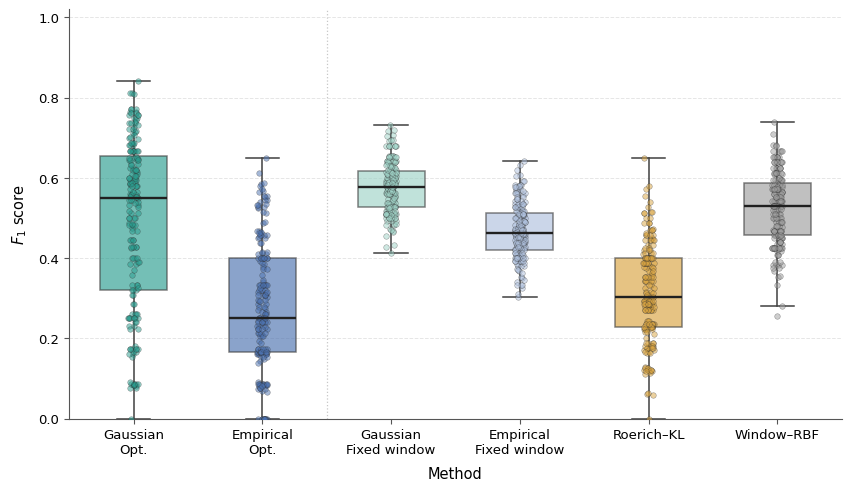

In [24]:
nombres_boxplot = [
    "Gaussian\nOpt.",
    "Empirical\nOpt.",
    "Gaussian\nFixed window",
    "Empirical\nFixed window",
    "Roerich–KL",
    "Window–RBF"
]

fig, ax = plot_boxplots(
    datos=[
        [m['F1 Score'] for m in lista_gauss_sen],
        [m['F1 Score'] for m in lista_emp_sen],
        [m['F1 Score'] for m in metricas_sen_gauss_fw],
        [m['F1 Score'] for m in metricas_sen_emp_fw],
        [m['F1 Score'] for m in lista_roerich_sen],
        [m['F1 Score'] for m in lista_window_rbf_sen]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"$F_1$ score",
    xlabel="Method",
    ylim=(0, 1.02)
)

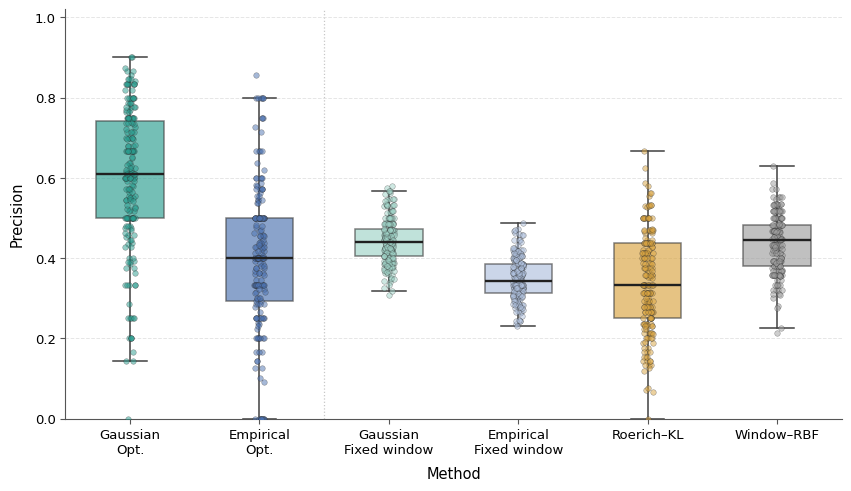

In [25]:
fig, ax = plot_boxplots(
    datos=[
        [m['Precision'] for m in lista_gauss_sen],
        [m['Precision'] for m in lista_emp_sen],
        [m['Precision'] for m in metricas_sen_gauss_fw],
        [m['Precision'] for m in metricas_sen_emp_fw],
        [m['Precision'] for m in lista_roerich_sen],
        [m['Precision'] for m in lista_window_rbf_sen]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"Precision",
    xlabel="Method",
    ylim=(0, 1.02)
)

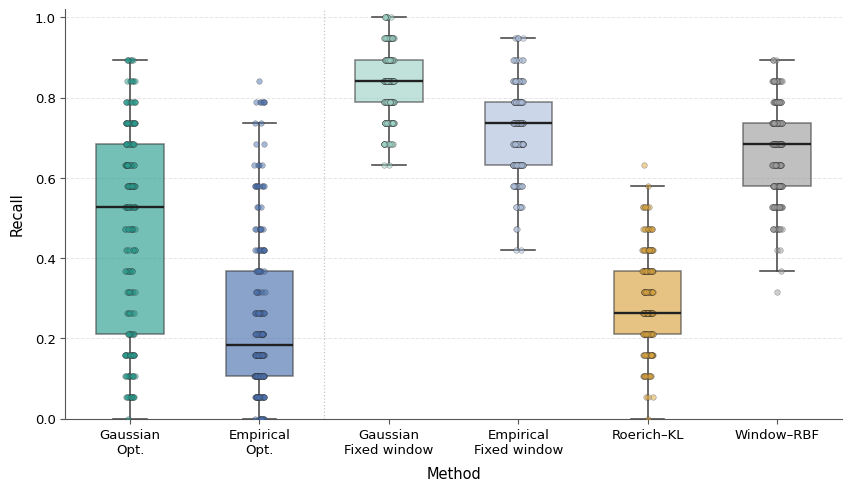

In [27]:
fig, ax = plot_boxplots(
    datos=[
        [m['Recall'] for m in lista_gauss_sen],
        [m['Recall'] for m in lista_emp_sen],
        [m['Recall'] for m in metricas_sen_gauss_fw],
        [m['Recall'] for m in metricas_sen_emp_fw],
        [m['Recall'] for m in lista_roerich_sen],
        [m['Recall'] for m in lista_window_rbf_sen]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"Recall",
    xlabel="Method",
    ylim=(0, 1.02)
)

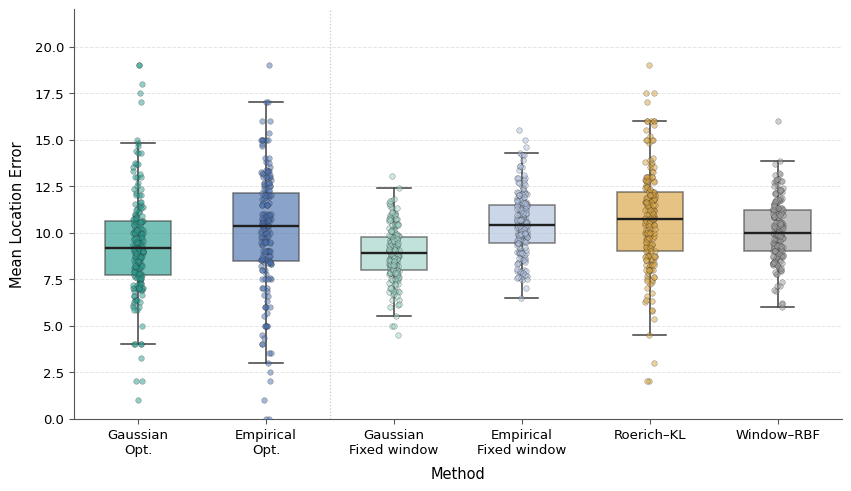

In [28]:
fig, ax = plot_boxplots(
    datos=[
        [m['Mean Location Error'] for m in lista_gauss_sen],
        [m['Mean Location Error'] for m in lista_emp_sen],
        [m['Mean Location Error'] for m in metricas_sen_gauss_fw],
        [m['Mean Location Error'] for m in metricas_sen_emp_fw],
        [m['Mean Location Error'] for m in lista_roerich_sen],
        [m['Mean Location Error'] for m in lista_window_rbf_sen]
    ],
    nombres=nombres_boxplot,
    titulo=None,
    ylabel=r"Mean Location Error",
    xlabel="Method",
    ylim=(0, 22)
)

In [29]:
generar_tabla_desde_diccionarios(
    [lista_gauss_sen, lista_emp_sen, metricas_sen_gauss_fw, metricas_sen_emp_fw, lista_roerich_sen, lista_window_rbf_sen],
    ["Gauss-Opt", "Empirical-Opt", "Gauss-FW", "Empirical-FW", "Roerich-KL", "Window-RBF"],
    ["Precision", "Recall", "F1 Score", "Mean Location Error"]
)

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss-Opt,0.599551,0.466053,0.490671,9.360192
1,Empirical-Opt,0.394530,0.249211,0.273675,10.022569
2,Gauss-FW,0.442247,0.832105,0.576134,8.885027
3,Empirical-FW,0.348574,0.709474,0.466482,10.462453
4,Roerich-KL,0.338198,0.290789,0.311820,10.697660
5,Window-RBF,0.435389,0.664737,0.525897,10.109337


# 6. Experimentos AR(2) - Fluctuación de Medias y Rezagos

## 6.1. EXPERIMENTO AR(2) CON MEDIA Y DISPERSIÓN FLUCTUANTES

### 6.1.1. Simulaciones

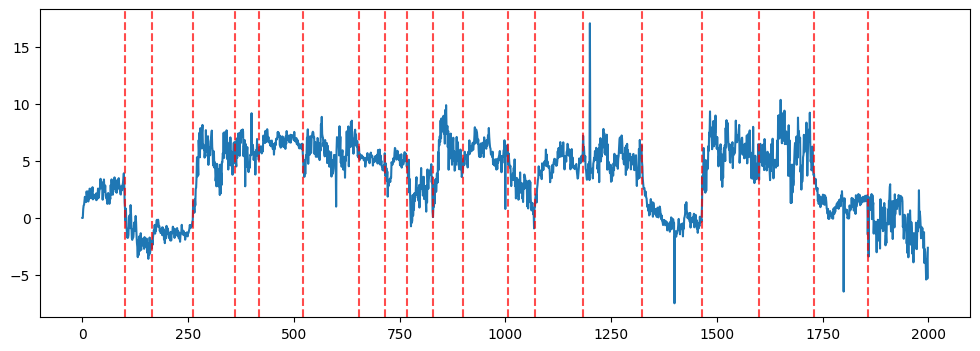

In [7]:
ar2_mdf, cps_ar2_mdf, outliers_ar2_mdf = ar2_noise(
            T = 2000,
            n_segmentos = 20,
            min_mean_diff = 0.05,
            min_seg = 50,
            max_seg = 150,
            base_mean = 0.3,
            std_range = (0.3, 1.2)
        )

plt.figure(figsize=(12, 4))
plt.plot(ar2_mdf)
for i in cps_ar2_mdf:
    plt.axvline(i, color='red', linestyle='--', alpha=0.7)

plt.show()


0

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Dispersion of Cost
──────────────────
    Execution Time              : 18.6303 s
    Best Window                 : 142

Dispersion of Cost
──────────────────
    Execution Time              : 18.6303 s
    Best Window                 : 142

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 142

Selección final
───

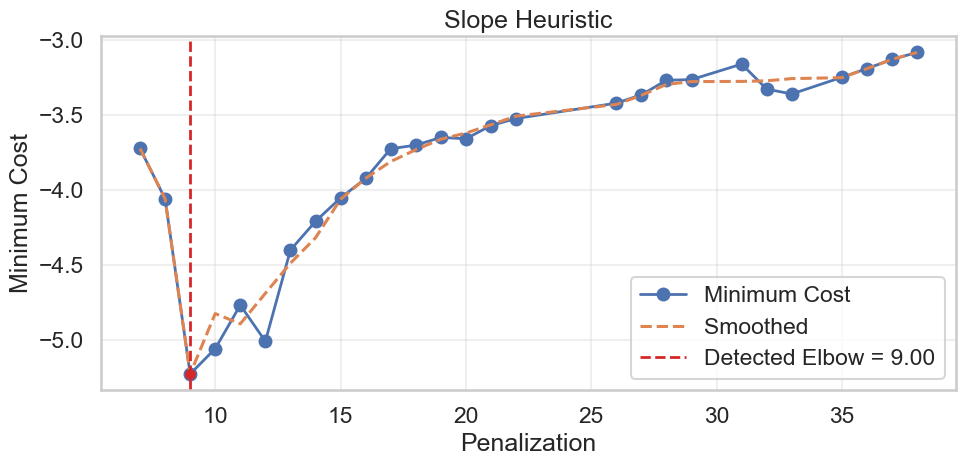

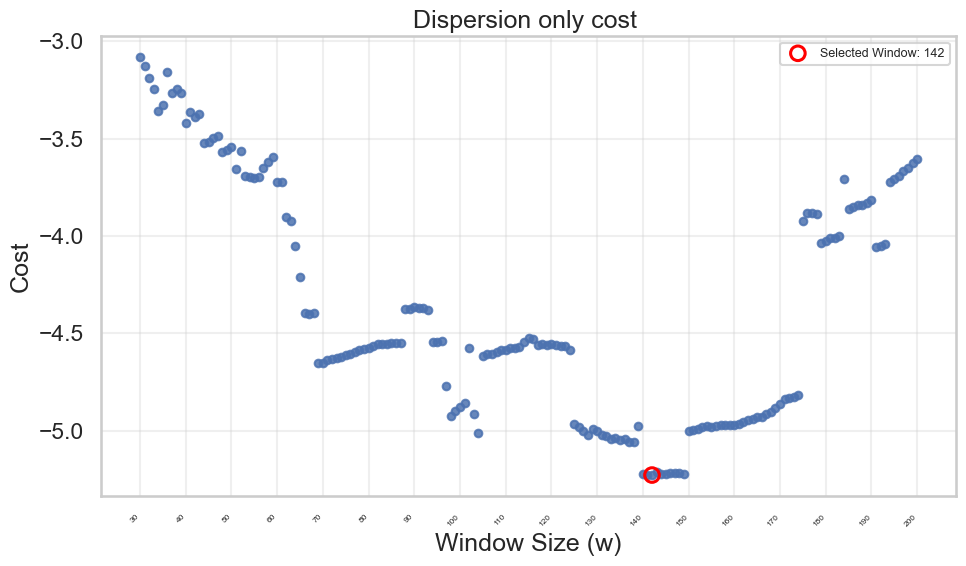

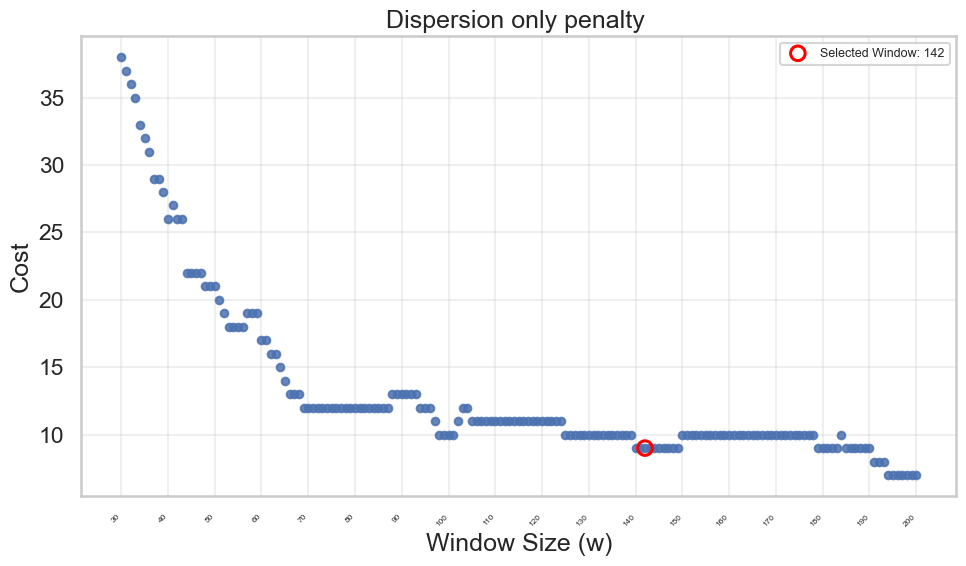

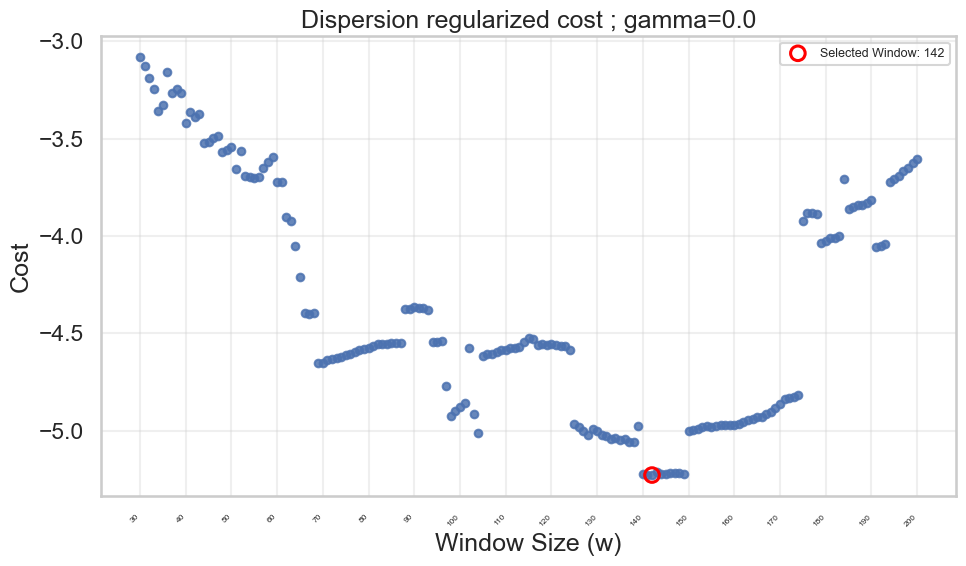

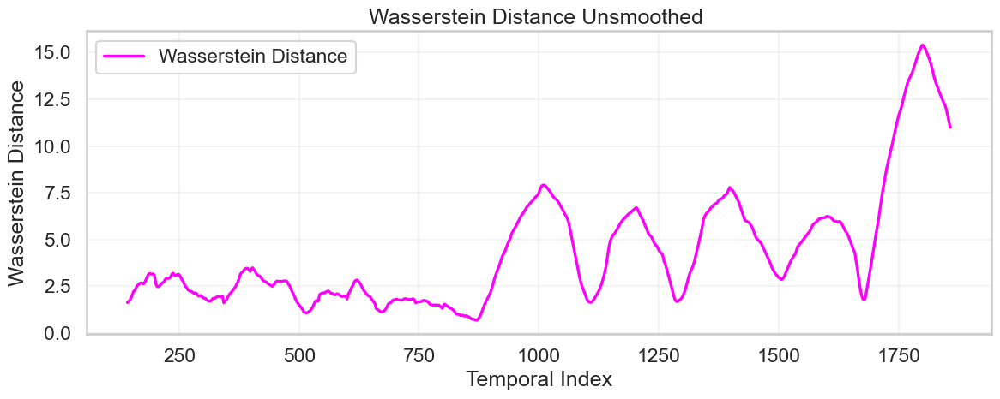

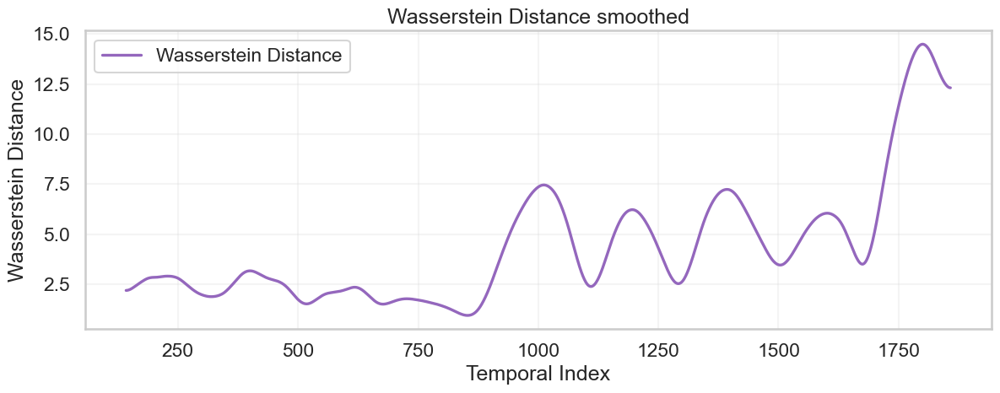

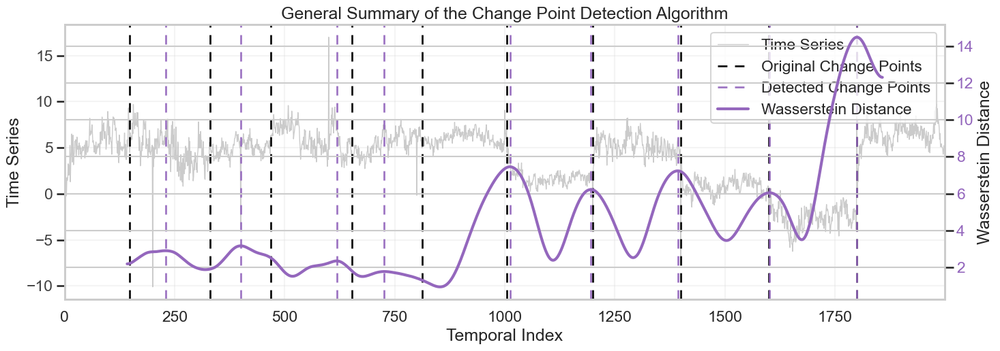


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Dispersion of Cost
──────────────────
    Execution Time              : 13.0171 s
    Best Window                 : 128

Dispersion of Cost
──────────────────
    Execution Time              : 13.0171 s
    Best Window                 : 128

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 128

Selección final
─────

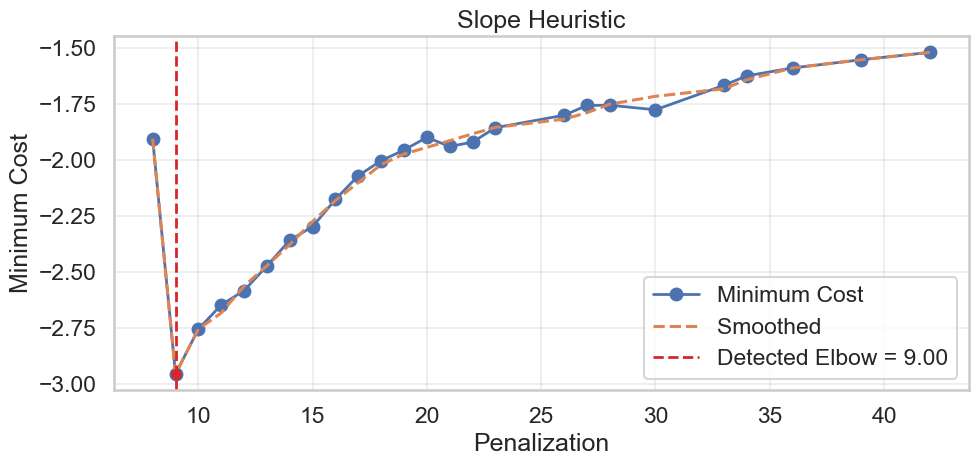

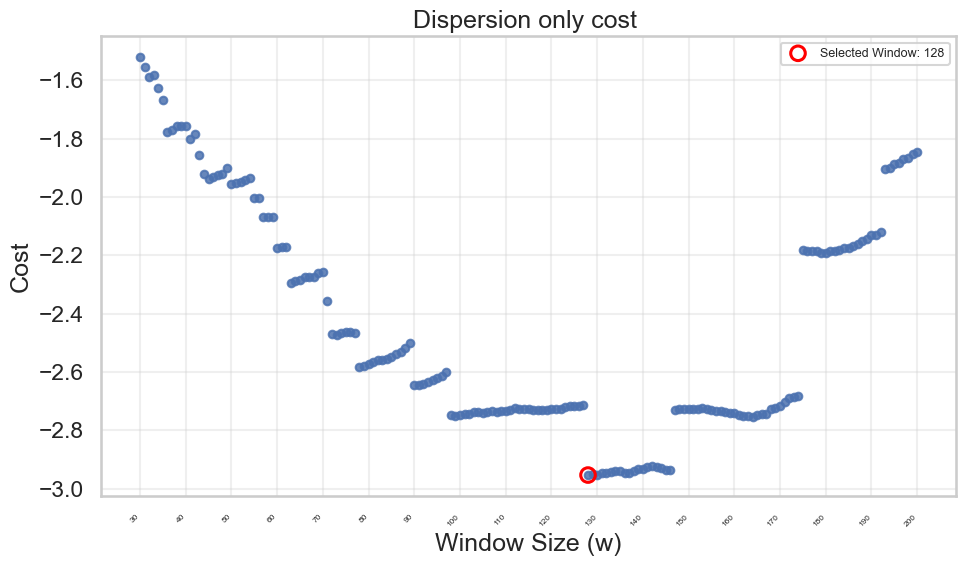

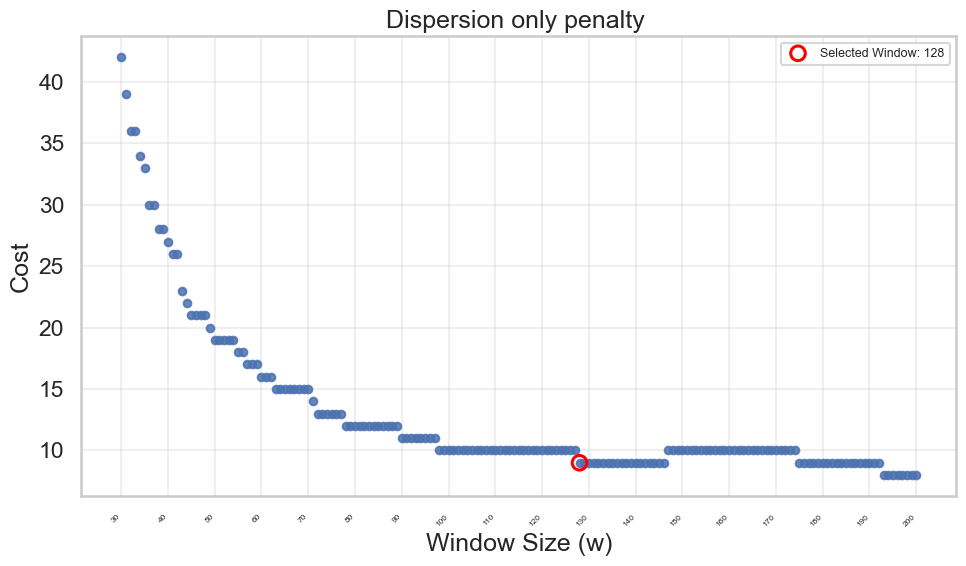

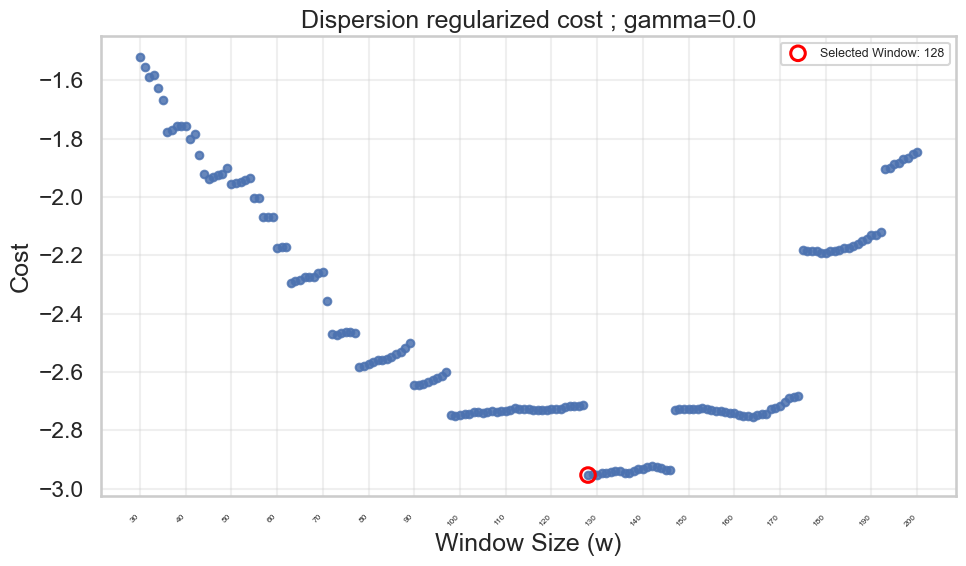

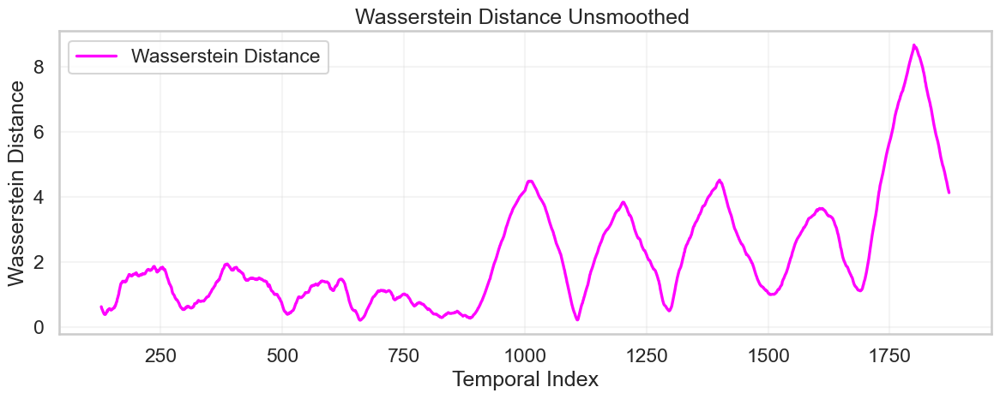

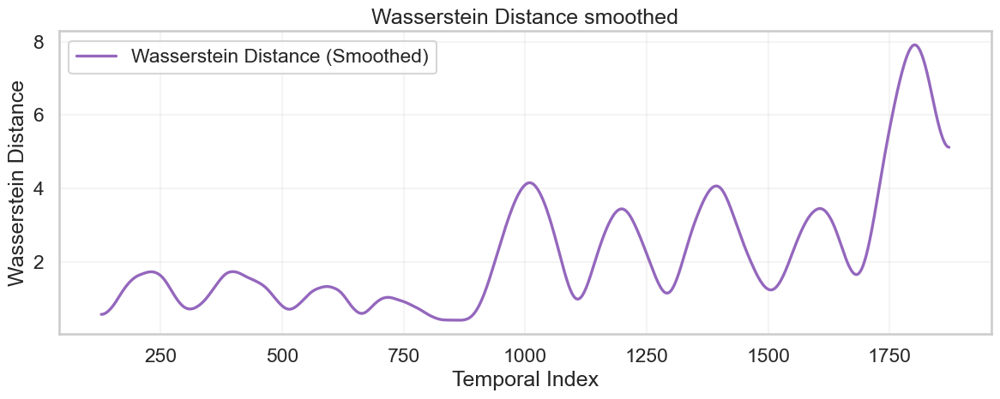

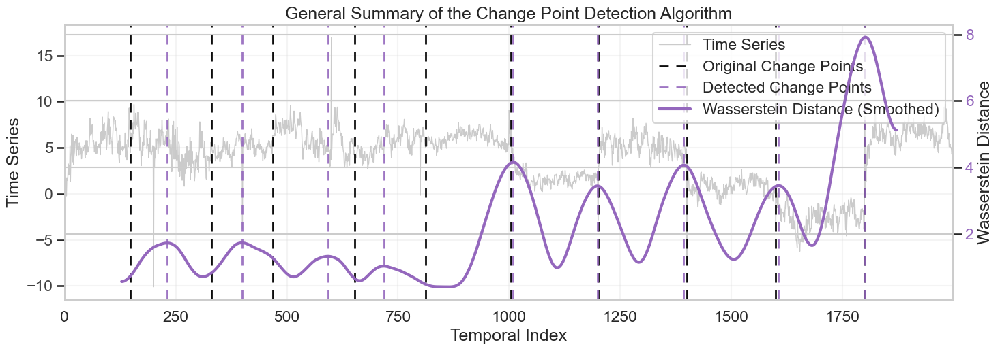

1

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Dispersion of Cost
──────────────────
    Execution Time              : 18.5506 s
    Best Window                 : 151

Dispersion of Cost
──────────────────
    Execution Time              : 18.5506 s
    Best Window                 : 151

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 151

Selección final
───

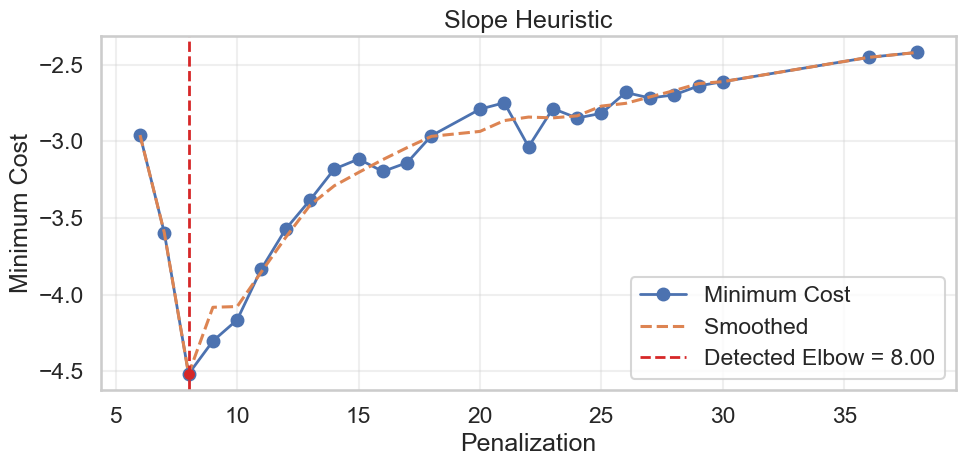

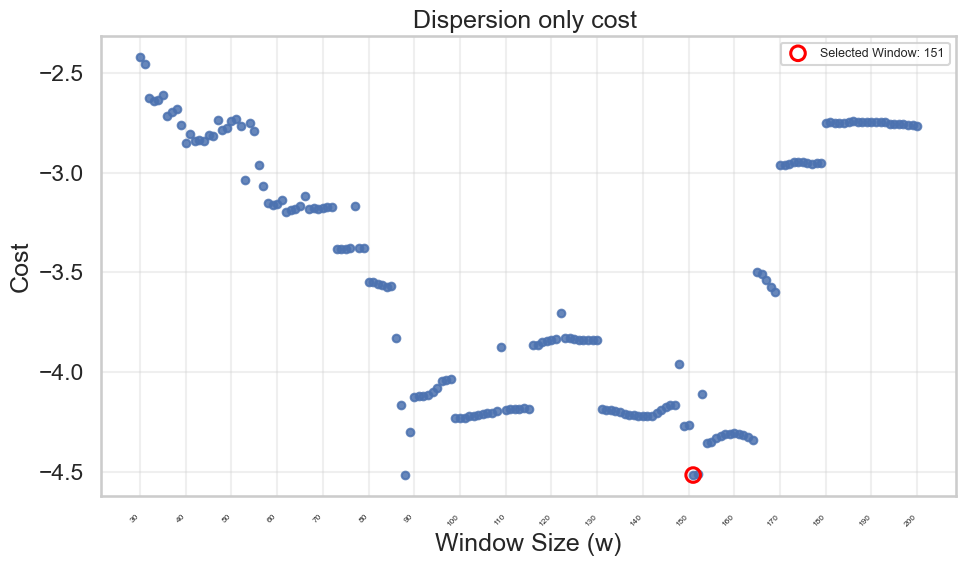

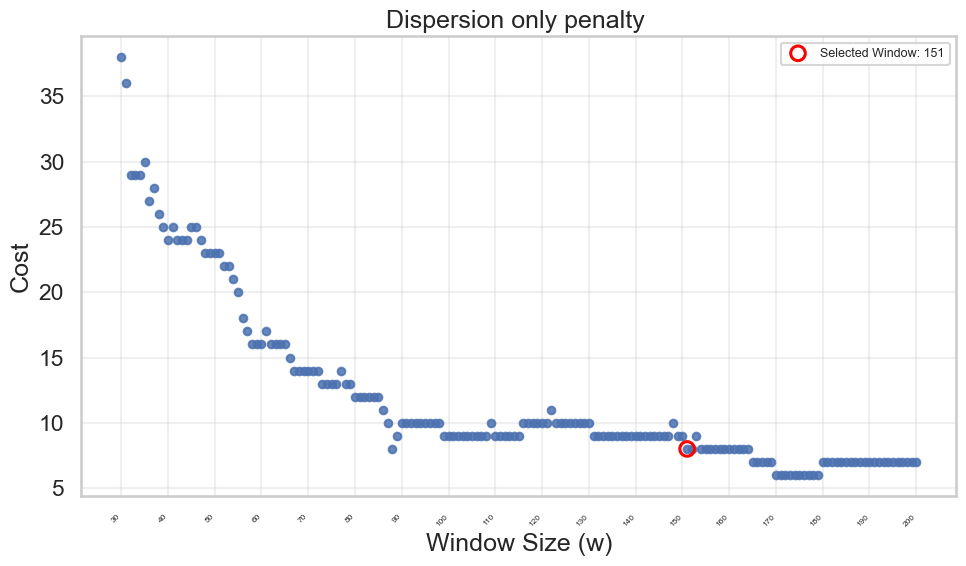

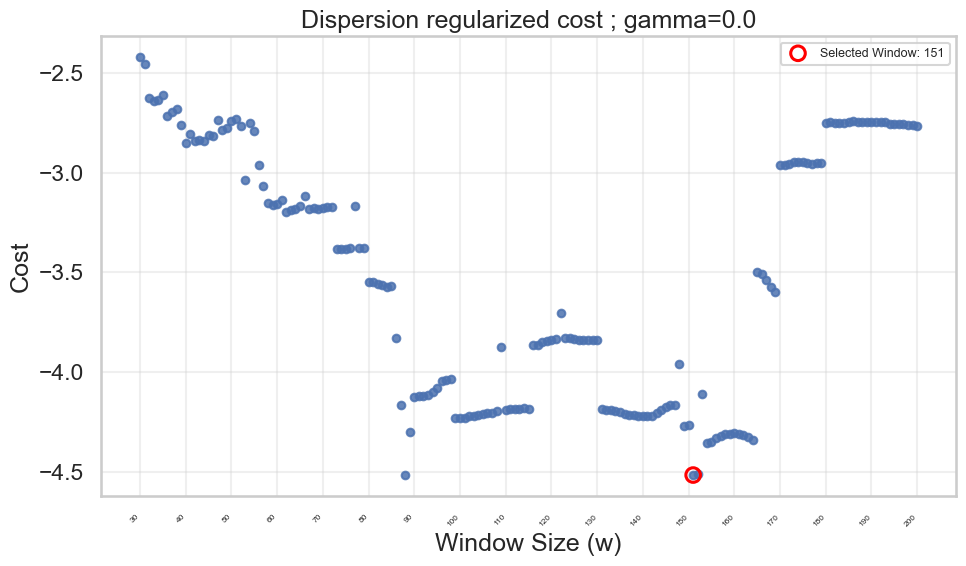

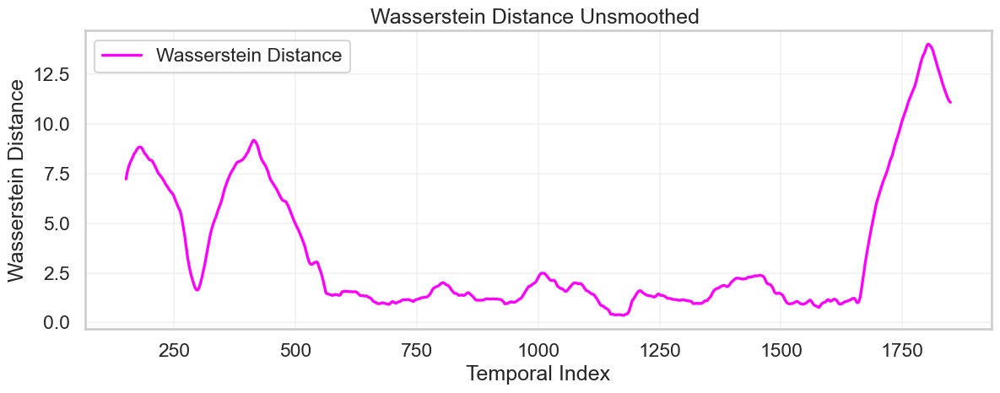

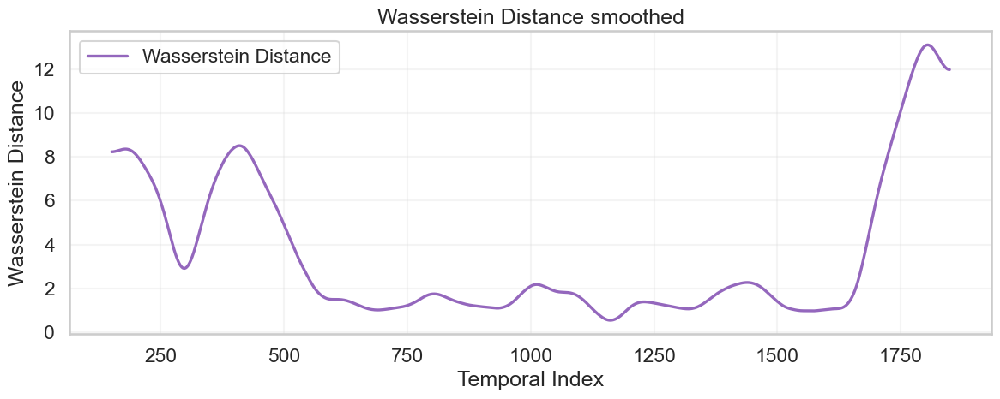

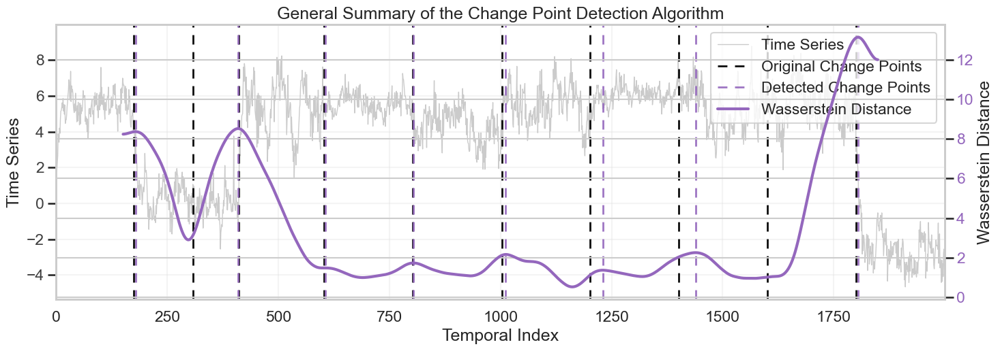


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Dispersion of Cost
──────────────────
    Execution Time              : 13.4583 s
    Best Window                 : 140

Dispersion of Cost
──────────────────
    Execution Time              : 13.4583 s
    Best Window                 : 140

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 140

Selección final
─────

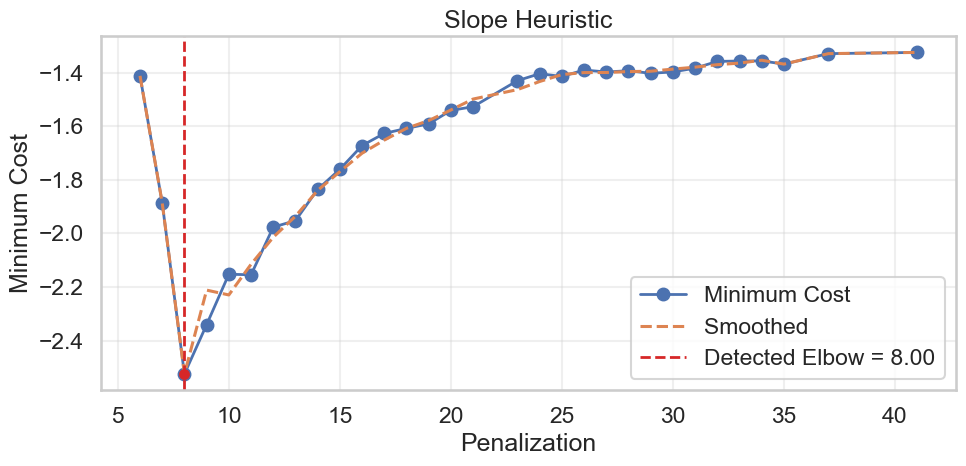

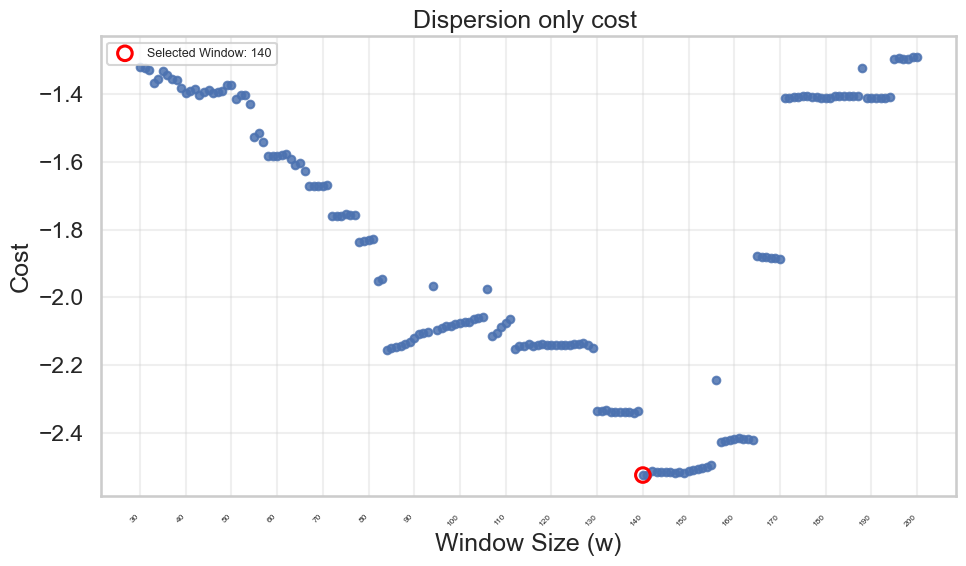

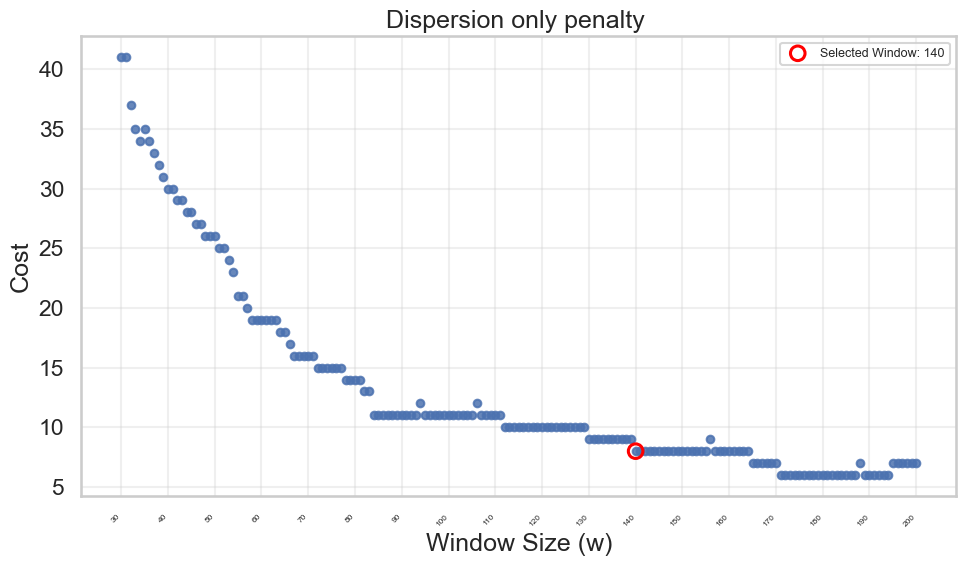

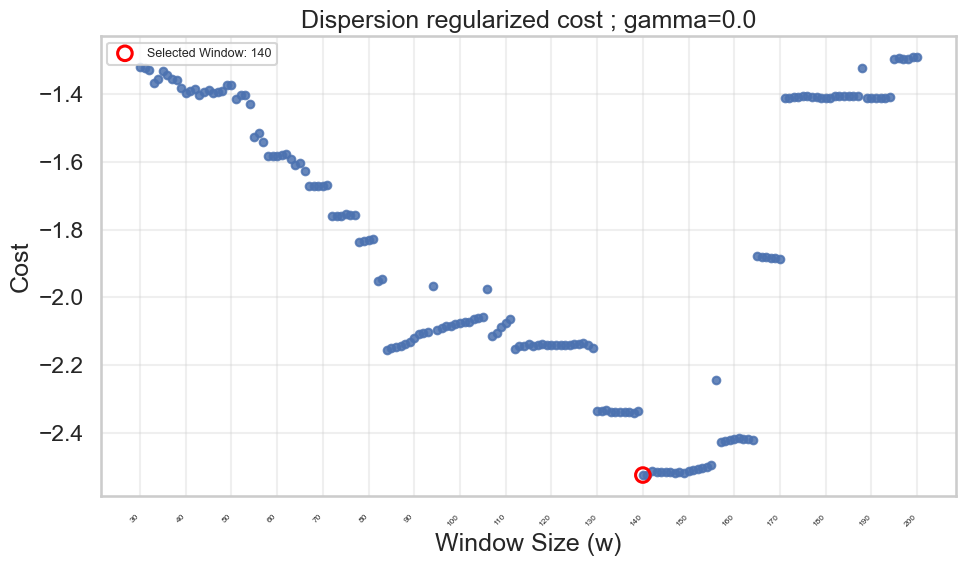

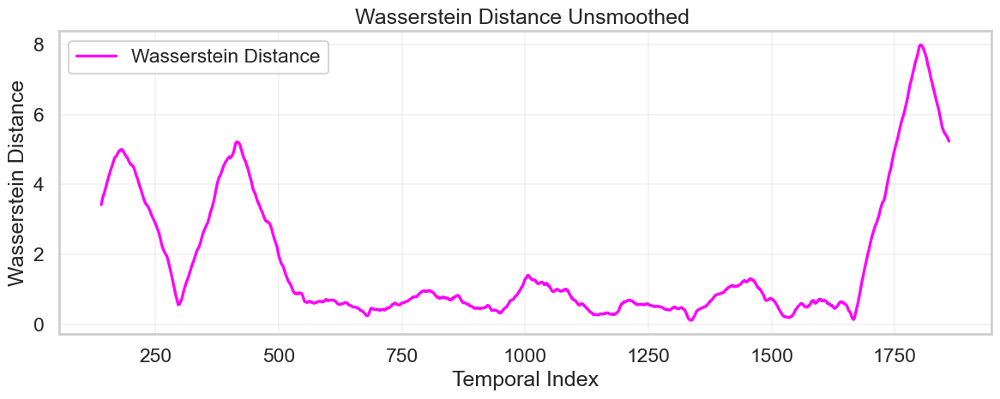

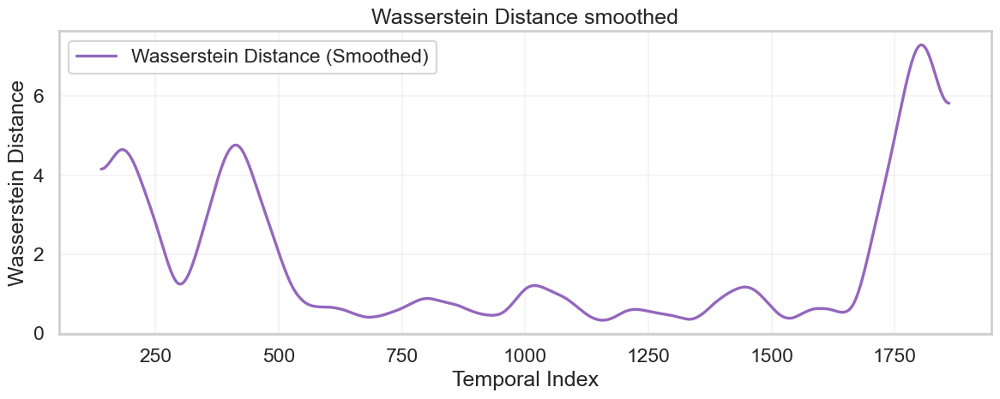

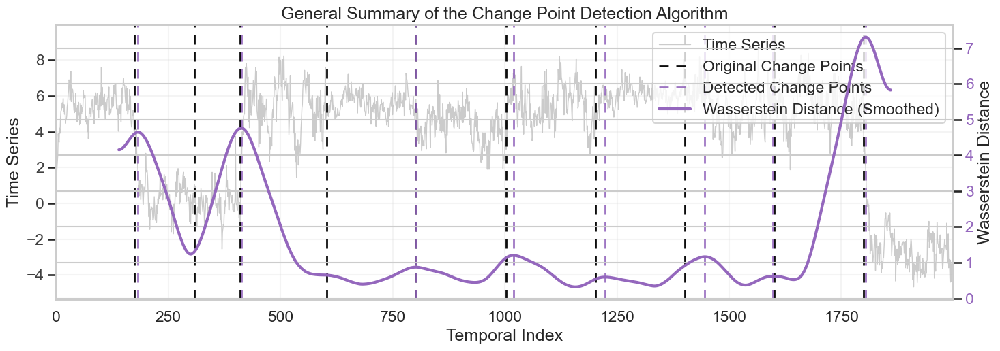

2

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Dispersion of Cost
──────────────────
    Execution Time              : 18.2469 s
    Best Window                 : 118

Dispersion of Cost
──────────────────
    Execution Time              : 18.2469 s
    Best Window                 : 118

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 118

Selección final
───

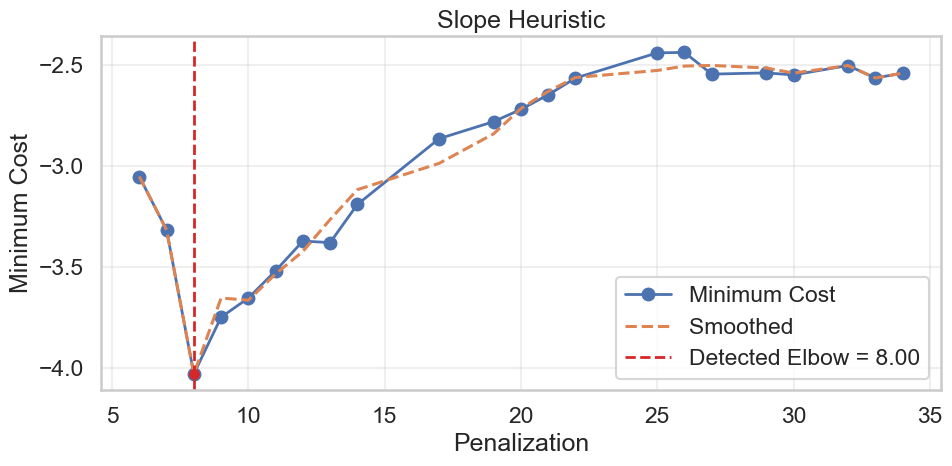

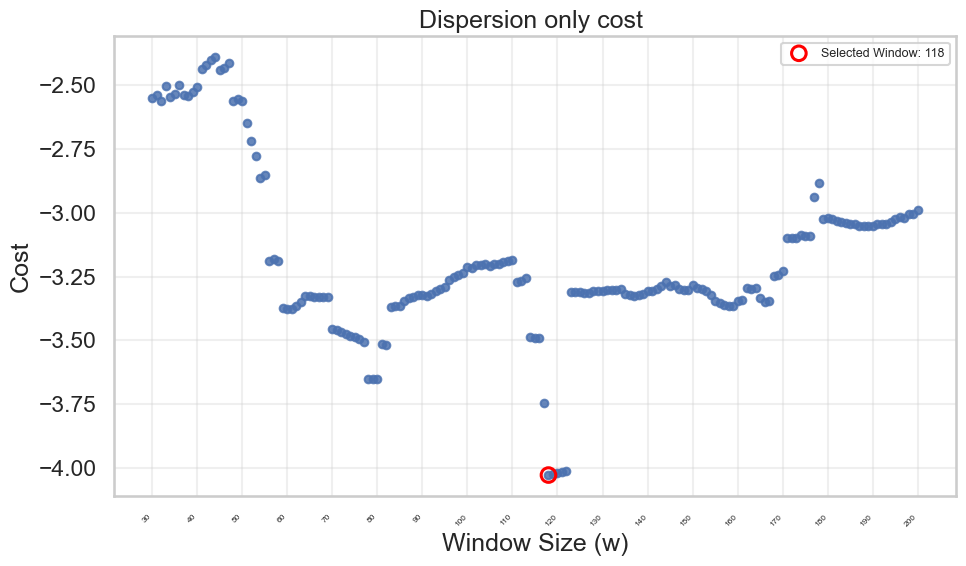

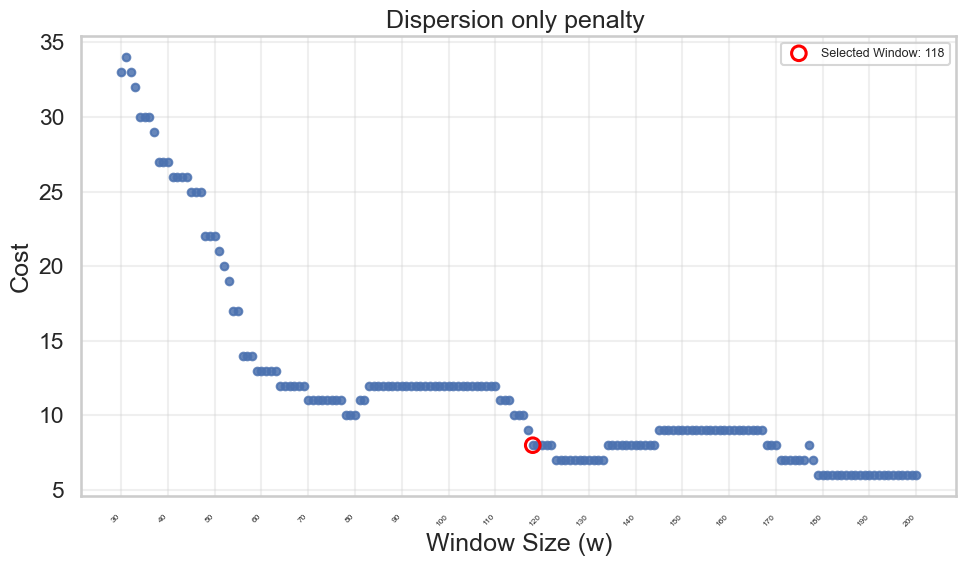

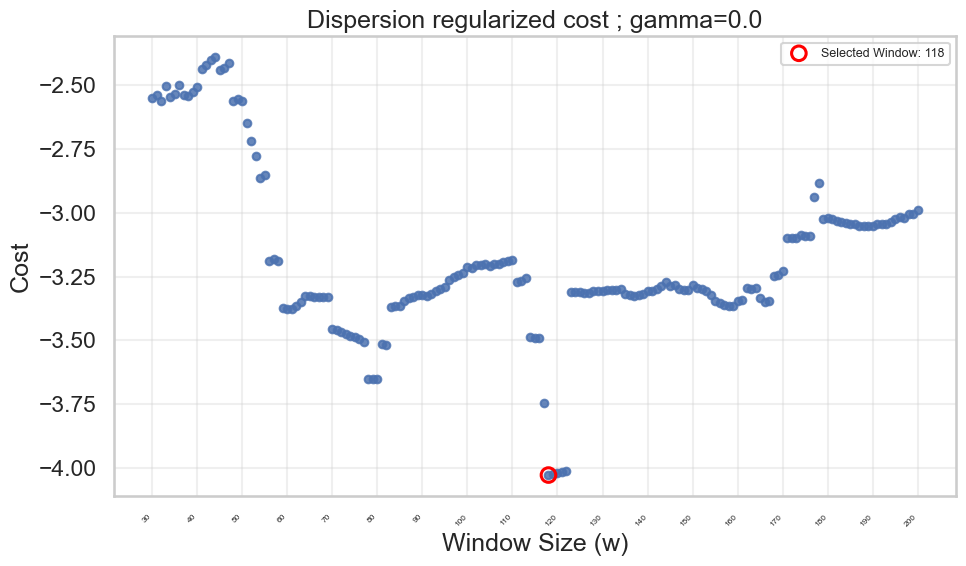

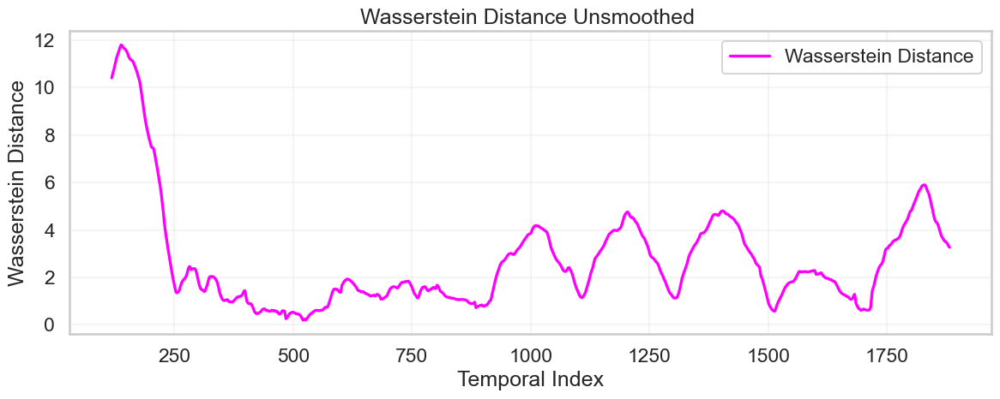

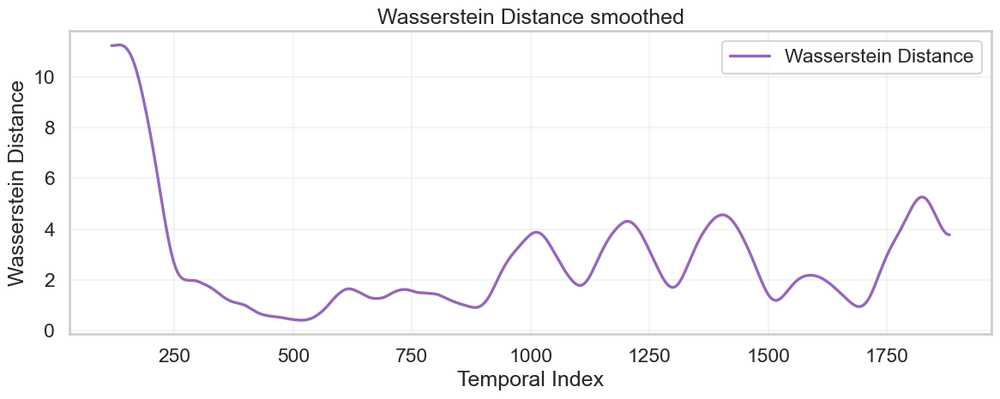

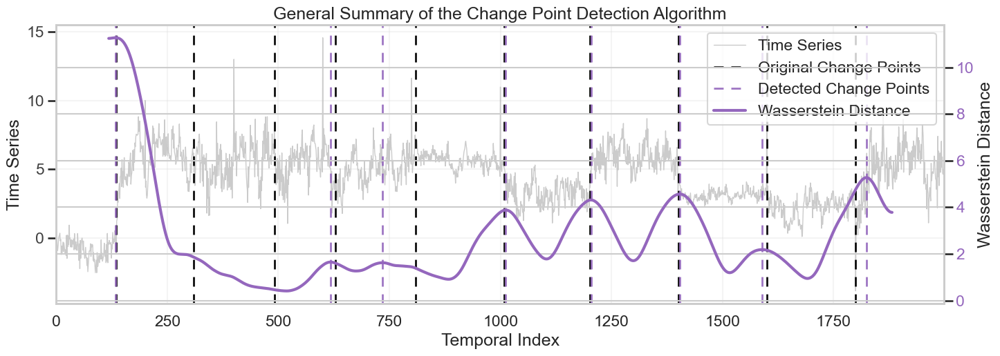


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 12.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 12.0000

Dispersion of Cost
──────────────────
    Execution Time              : 12.4878 s
    Best Window                 : 108

Dispersion of Cost
──────────────────
    Execution Time              : 12.4878 s
    Best Window                 : 108

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 108

Selección final
───

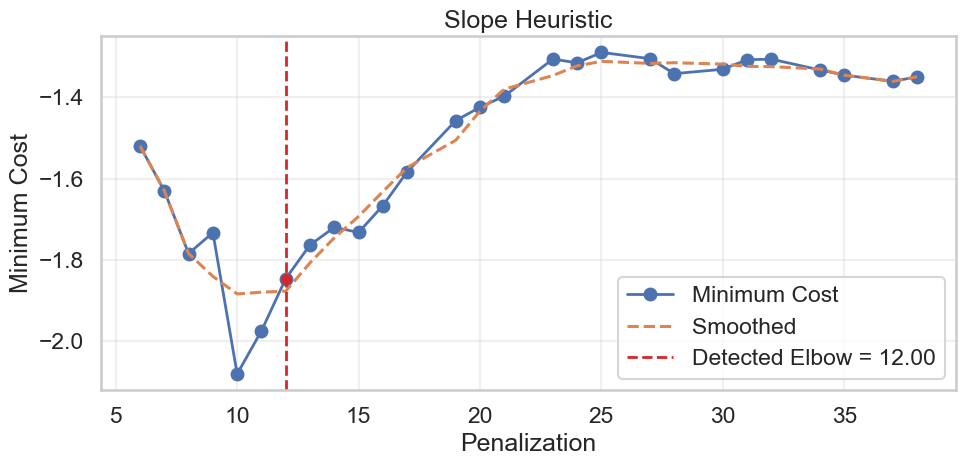

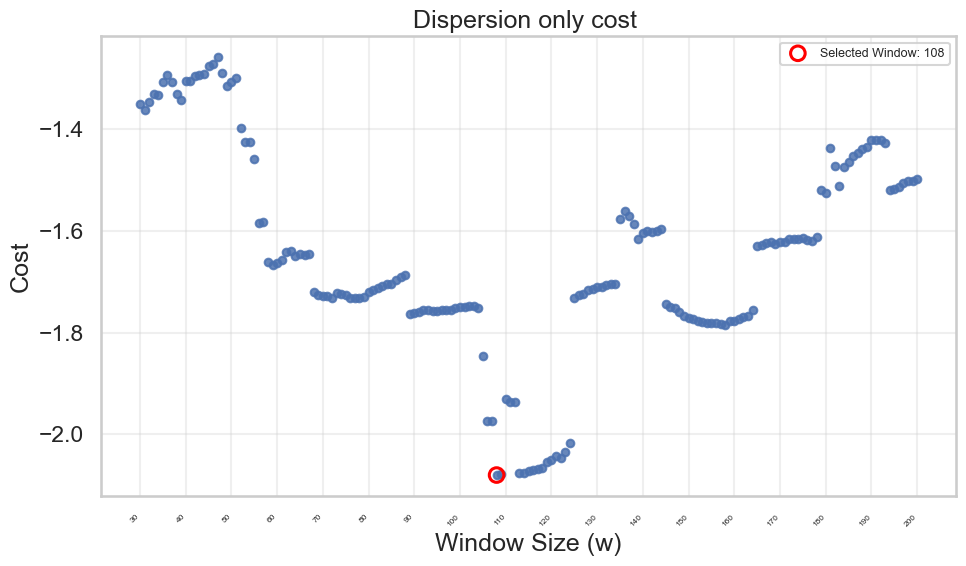

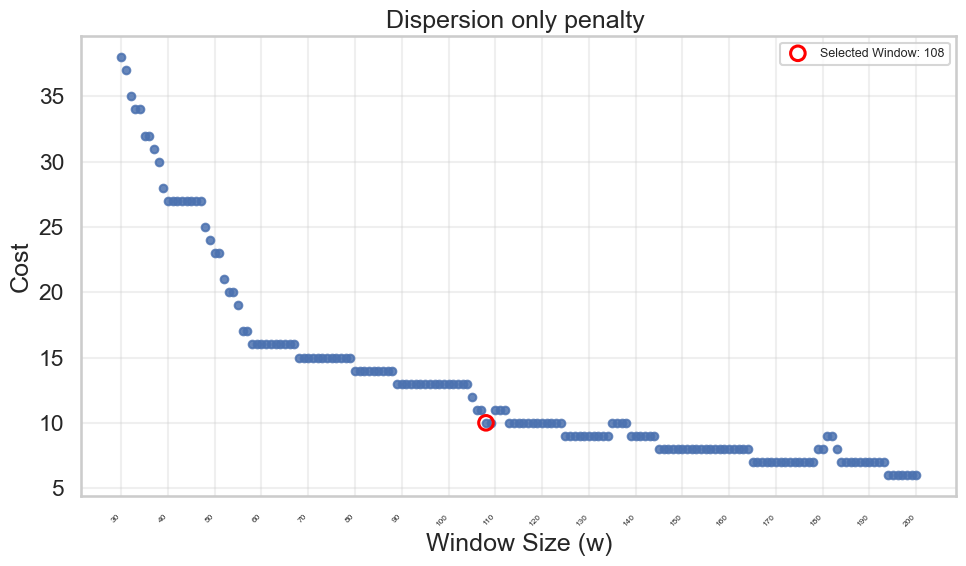

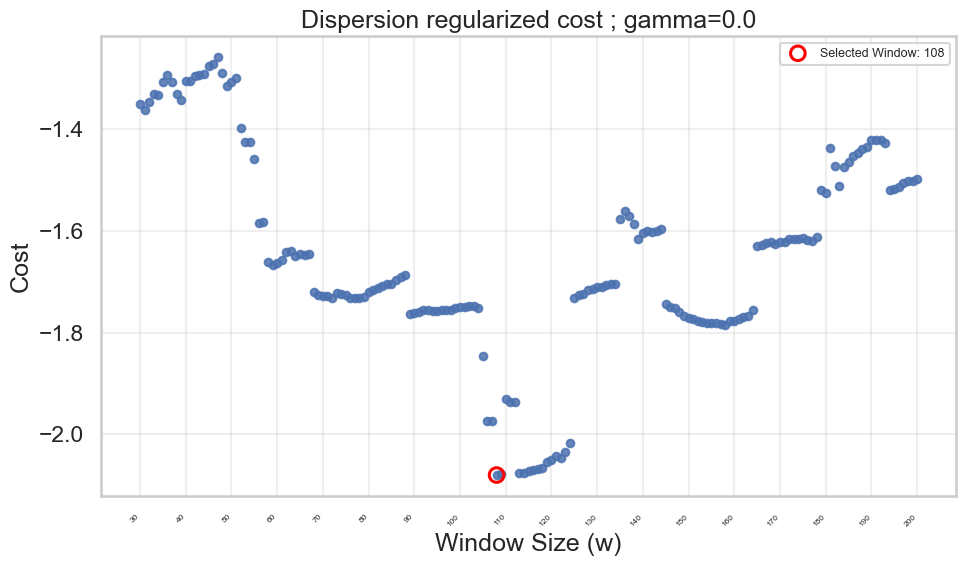

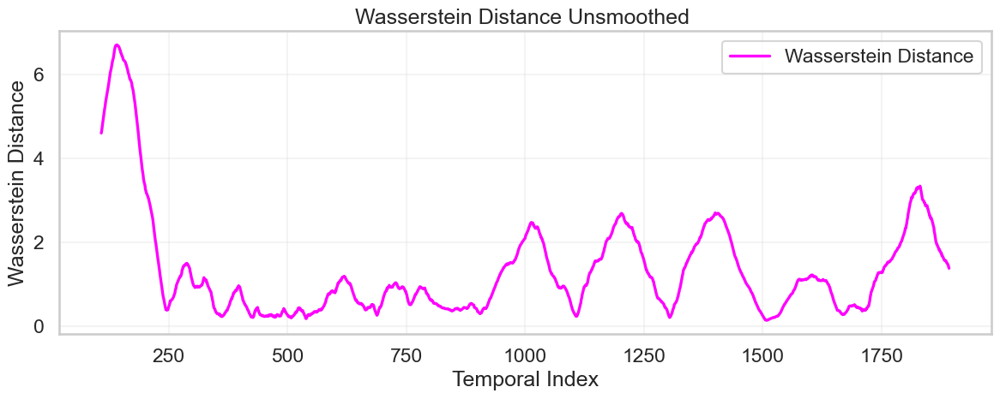

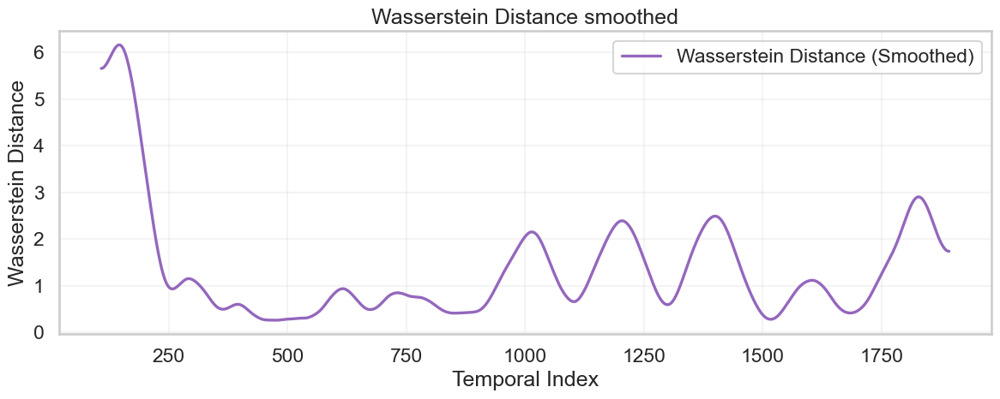

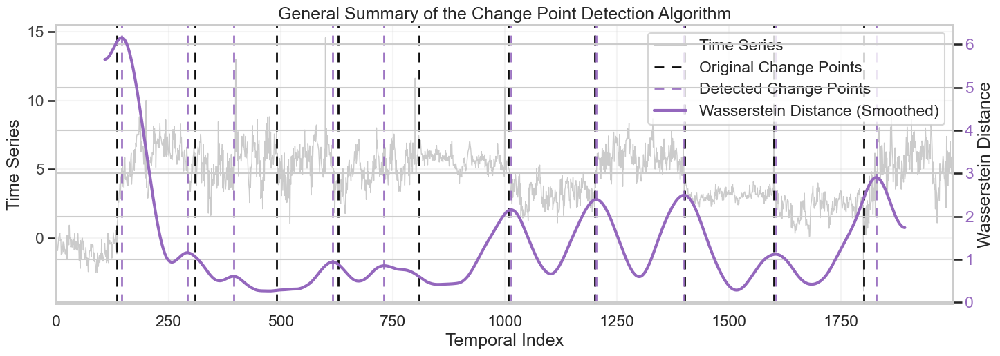

3

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Dispersion of Cost
──────────────────
    Execution Time              : 18.3711 s
    Best Window                 : 144

Dispersion of Cost
──────────────────
    Execution Time              : 18.3711 s
    Best Window                 : 144

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 144

Selección final
───

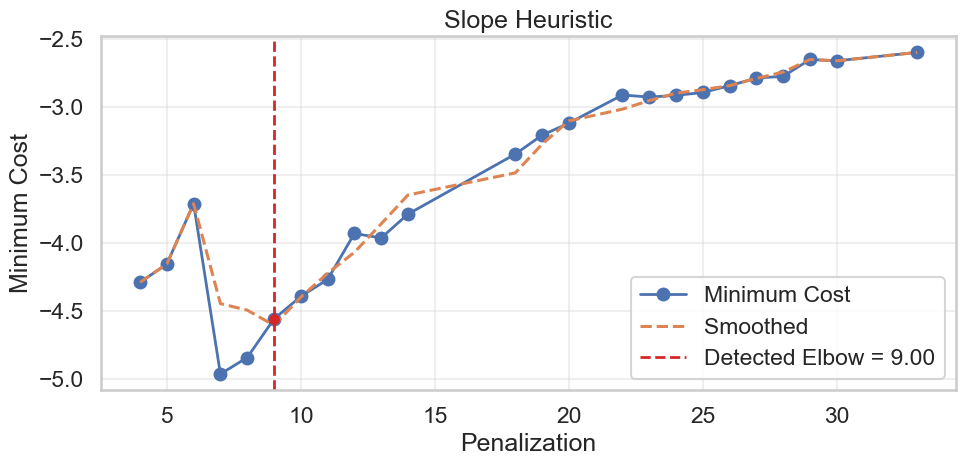

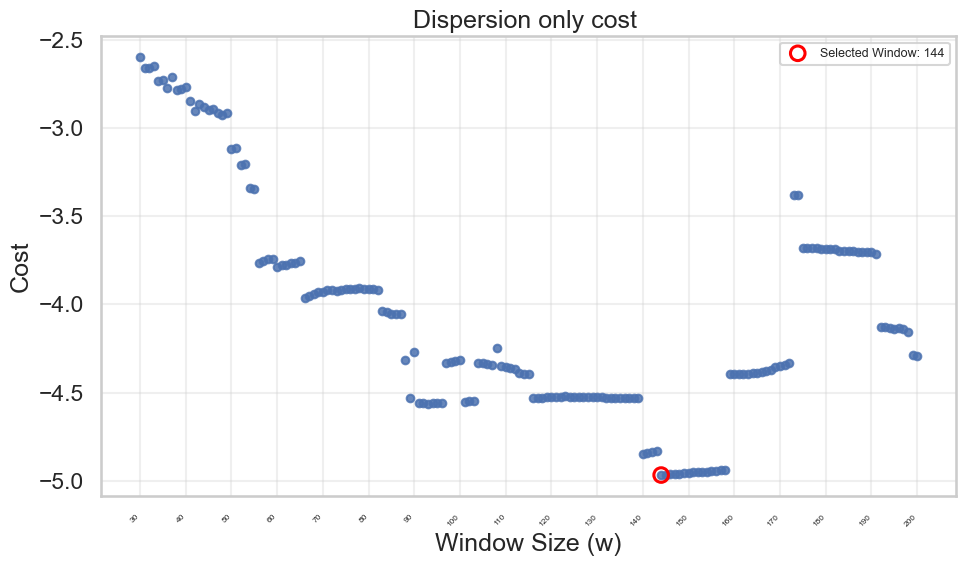

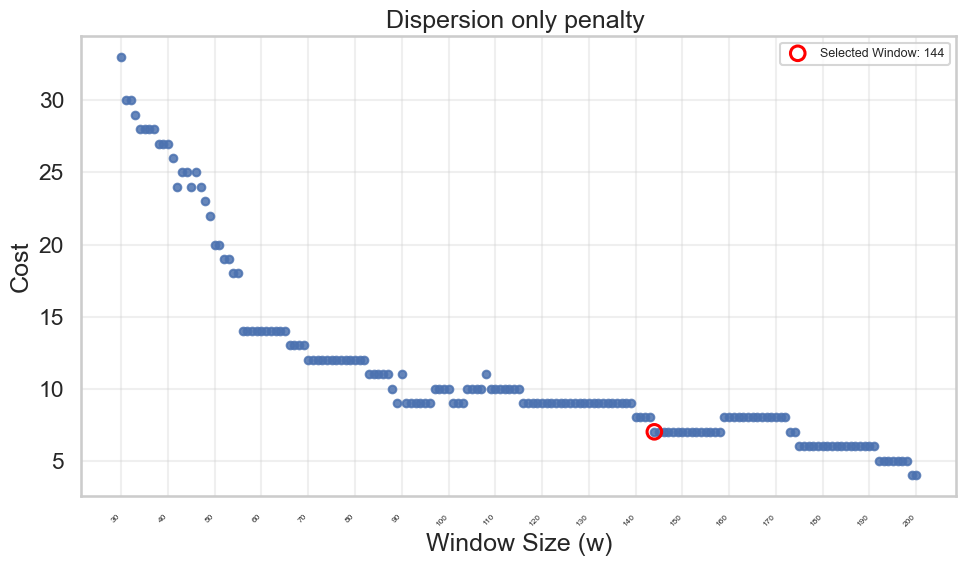

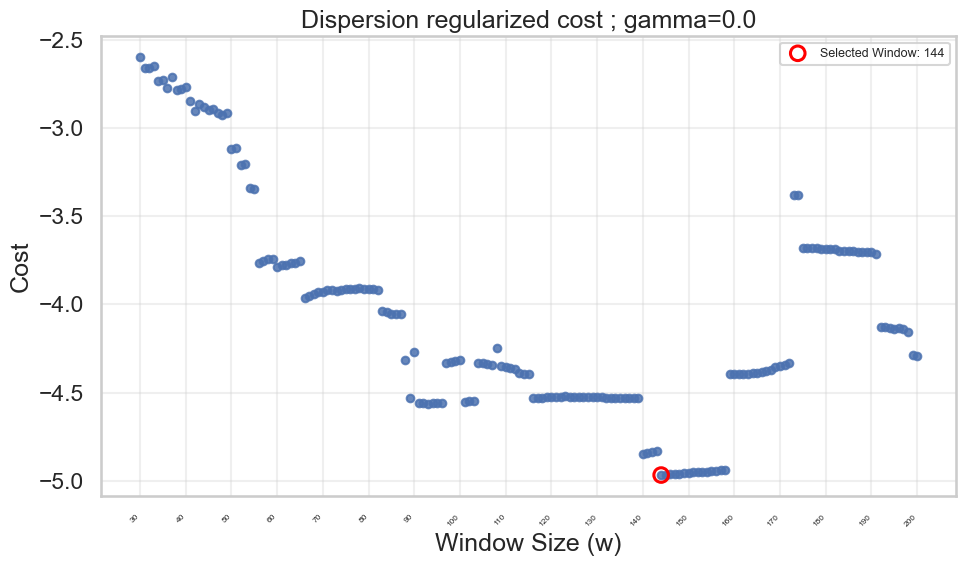

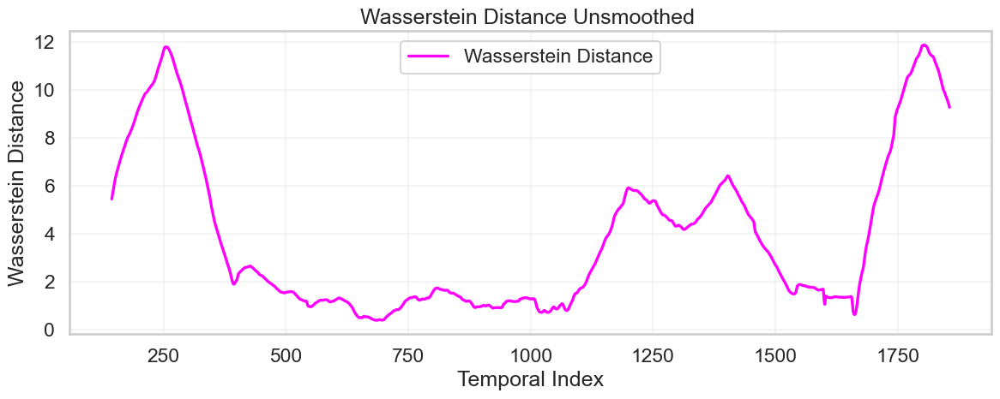

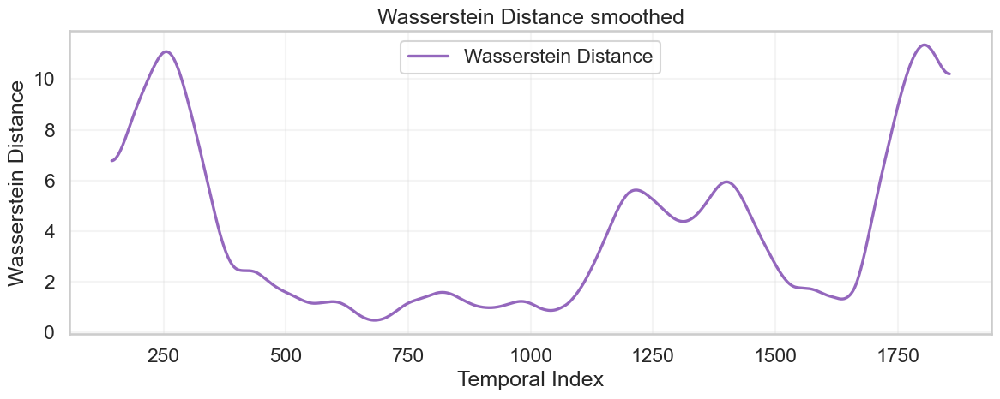

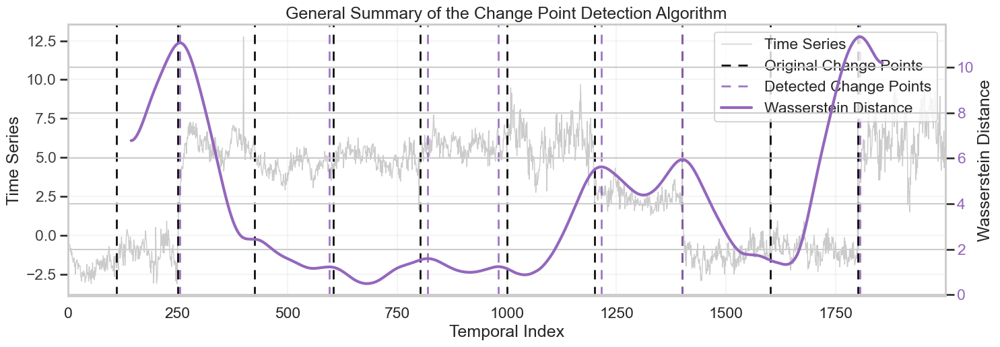


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 10.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 10.0000

Dispersion of Cost
──────────────────
    Execution Time              : 13.0198 s
    Best Window                 : 141

Dispersion of Cost
──────────────────
    Execution Time              : 13.0198 s
    Best Window                 : 141

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 141

Selección final
───

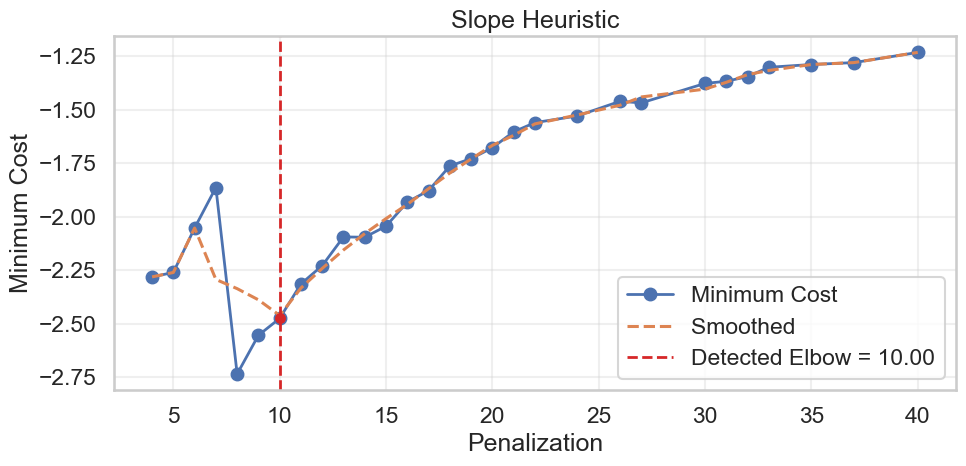

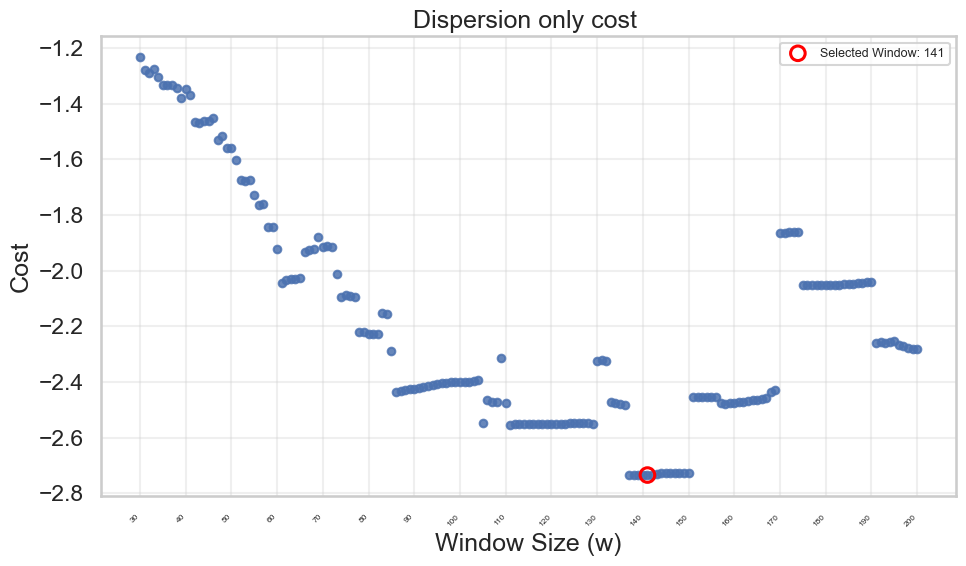

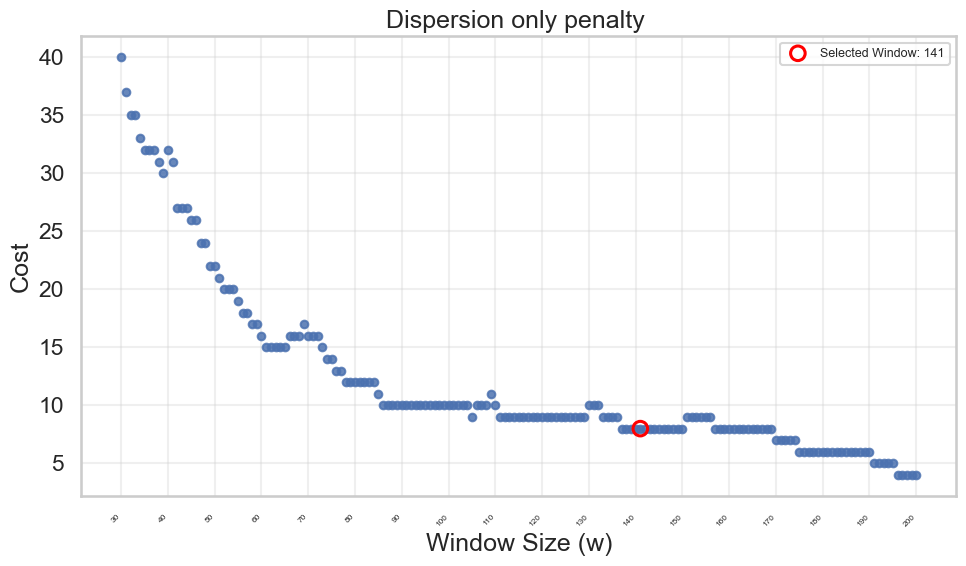

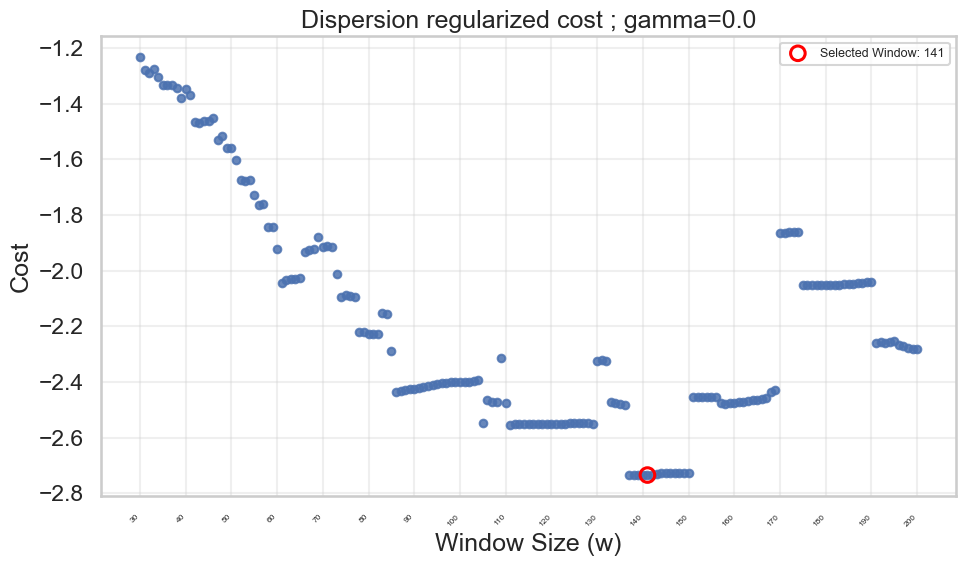

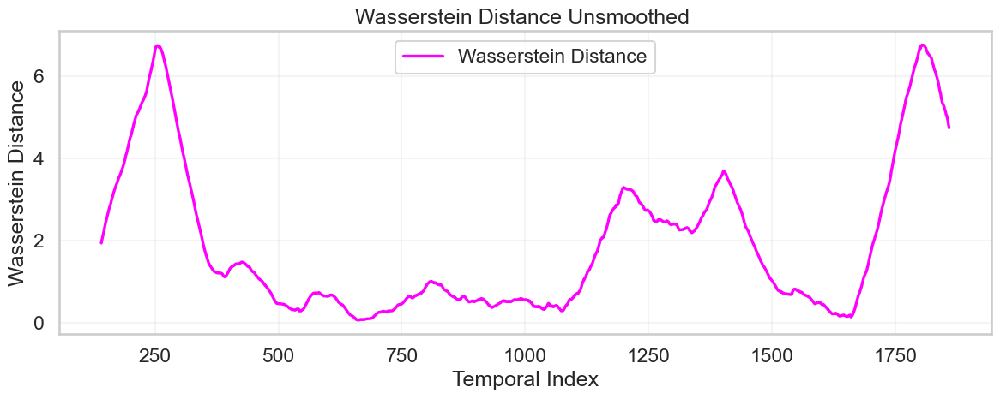

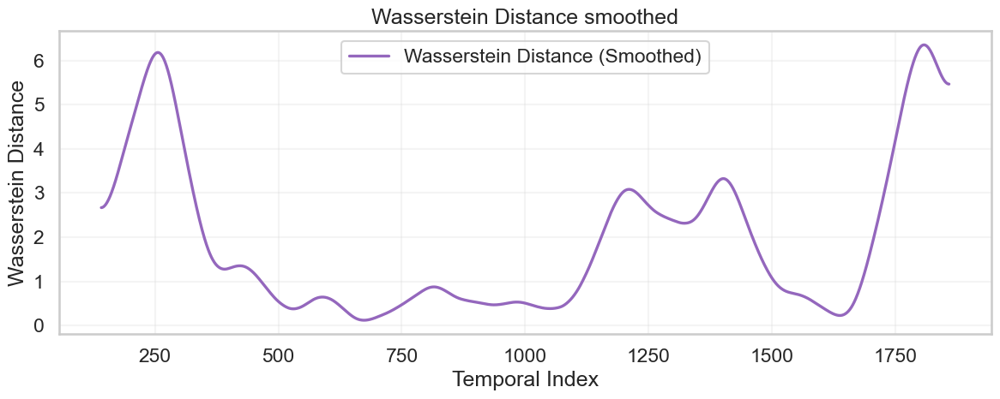

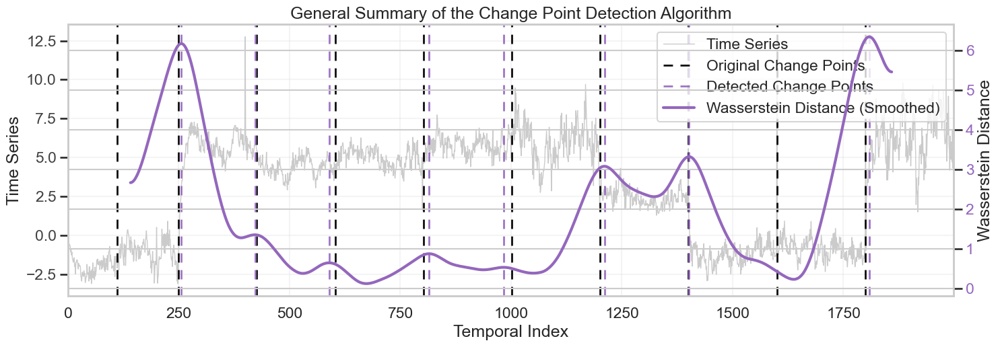

4

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 26.0000

Selección final
───────────────
    Ventana óptima              : 77
    Retardo óptimo              : 1
    Penalización mínima         : 0
    Gamma final                 : 0.0000
    Tiempo de búsqueda          : 18.4730
    [OK] Optimización finalizada

════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie       

In [7]:
metricas_ar2_mdf_gauss_opt = []
metricas_ar2_mdf_emp_opt = []


experimentos_gauss_opt = []
experimentos_emp_opt = []
for i in range(200):
    print(i)
    ar2_mdf, cps_ar2_mdf, outliers_ar2_mdf = ar2_noise(
            T = 2000,
            n_segmentos = 11,
            min_mean_diff = 0.05,
            min_seg = 100,
            max_seg = 200,
            base_mean = 0.3,
            std_range = (0.3, 1.2),
            seed = 1234+i
        )

    if i <= 3:
        visualization={
                                                                            "summary": True,
                                                                            "raw_distance": True,
                                                                            "smooth_distance": True,
                                                                            "cost": True,
                                                                            "slope": True,
                                                                        }
    else:
        visualization={
                                                                            "summary": False,
                                                                            "raw_distance": False,
                                                                            "smooth_distance": False,
                                                                            "cost": False,
                                                                            "slope": False,
                                                                        }

    metricas_ar2_mdf_gauss_opt.append(
                                            best_params_sh(
                                                                ar2_mdf,
                                                                cps_ar2_mdf,
                                                                penal=True,
                                                                path='',
                                                                mean_gauss=True,
                                                                name=f"AR2_{i+1} Media y Dispersión Fluctuantes",
                                                                modo="Gaussiano",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 30,
                                                                max_w = 200,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                visualization=visualization,
                                                                save_fig=False,
                                                                temporal_comp=True,
                                                                max_bandwidth=True,
                                                                prominence_ratio=0)[0]
                                        )
    

    metricas_ar2_mdf_emp_opt.append(
                                        best_params_sh(
                                                            ar2_mdf,
                                                            cps_ar2_mdf,
                                                            penal=True,
                                                            path='',
                                                            name=f"AR2_{i+1} Media y Dispersión Fluctuantes",
                                                            modo="Empírico",
                                                            given=False,
                                                            thr_dist=20,
                                                            min_w = 30,
                                                            max_w = 200,
                                                            smooth_distances=True,
                                                            visualization=visualization,
                                                            save_fig=False,
                                                            temporal_comp=True,
                                                            max_bandwidth=True, 
                                                            prominence_ratio=0)[0]
        )


In [10]:
def experiment_ar2_mdf_temporal_dependence(w=100, delta=20, prominence_ratio=0.05):
    metricas_ar2_mdf_gauss_fw = []
    metricas_ar2_mdf_emp_fw = []
    metricas_ar2_mdf_roerich = []
    metricas_ar2_mdf_window_rbf = []

    for i in range(200):
        print(i)
        ar2_mdf, cps_ar2_mdf, outliers_ar2_mdf = ar2_noise(
            T = 2000,
            n_segmentos = 11,
            min_mean_diff = 0.01,
            min_seg = 100,
            max_seg = 200,
            base_mean = 0.3,
            std_range = (0.3, 1.2),
            seed = 1234+i
        )
        
        #Gaussiano
        cpd_ar2_mdf = CPD(ar2_mdf, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
        distancias_ar2_mdf = cpd_ar2_mdf.distancias()
        cps_detect = detect(distancias_ar2_mdf, w, prominence_ratio=prominence_ratio)
        metricas_ar2_mdf_gauss_fw.append(metrics(cps_ar2_mdf, cps_detect, delta, 2000)[0])

        #Empírico
        cpd_ar2_mdf_emp = EmpiricalCPD(ar2_mdf, window=w, smooth=True)
        distancias_ar2_mdf_emp = cpd_ar2_mdf_emp.distancias()
        cps_detect_emp = detect(distancias_ar2_mdf_emp, w, prominence_ratio=prominence_ratio)
        metricas_ar2_mdf_emp_fw.append(metrics(cps_ar2_mdf, cps_detect_emp, delta, 2000)[0])

        #Roerich KL
        puntos_cambio_roerich_ar2_mdf = detectar_cambios_roerich(
                                        ar2_mdf,
                                        window_size=w,
                                        seed=42,
                                        periods=3
                                    )
        
        metricas_ar2_mdf_roerich.append(metrics(cps_ar2_mdf, puntos_cambio_roerich_ar2_mdf, delta, len(ar2_mdf))[0])

        #Window RBF
        puntos_cambio_ar2_mdf_window_rbf = detectar_window_rbf(
                                                ar2_mdf,
                                                window=w
                                            )
        
        metricas_ar2_mdf_window_rbf.append(metrics(cps_ar2_mdf, puntos_cambio_ar2_mdf_window_rbf, delta, len(ar2_mdf))[0])
        
    return metricas_ar2_mdf_gauss_fw, metricas_ar2_mdf_emp_fw, metricas_ar2_mdf_roerich, metricas_ar2_mdf_window_rbf

### 6.1.2. Gráficas y Resultados Promedio

In [11]:
lists_metrics_ar2_mdf = []
windows = [30, 50, 80, 100]
for w in windows:
    print(f'WINDOW SIZE: {w}')
    prominence_ratio=0.05
    if w>=80:
        prominence_ratio=0
    lists_metrics_ar2_mdf.append(experiment_ar2_mdf_temporal_dependence(w=w, delta=20, prominence_ratio=prominence_ratio))

WINDOW SIZE: 30
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
WINDOW SIZE: 50
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95


In [ ]:
for metricas, w in zip(lists_metrics_ar2_mdf, windows):
    exportar_excel(metricas, f"Resultados_Series_Simuladas/AR(2)_Fluctuating_average/Tables/ar2_mdf_metrics_window_{w}.xlsx", ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"])

WINDOW SIZE: 30


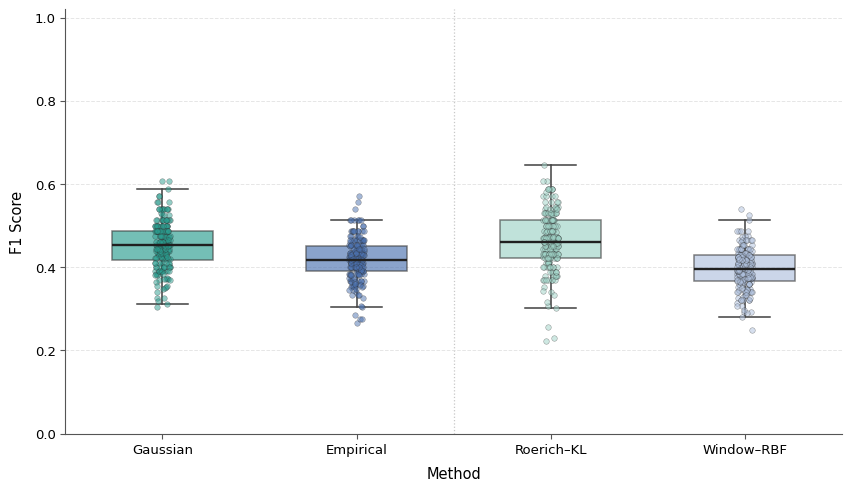

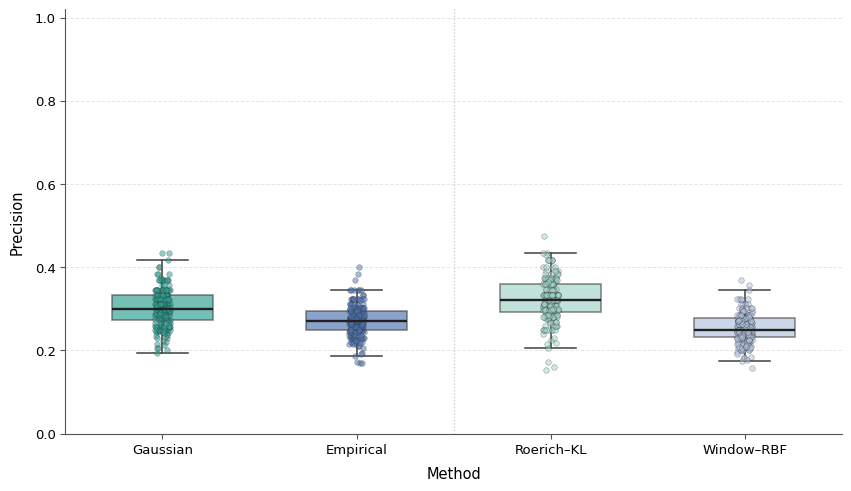

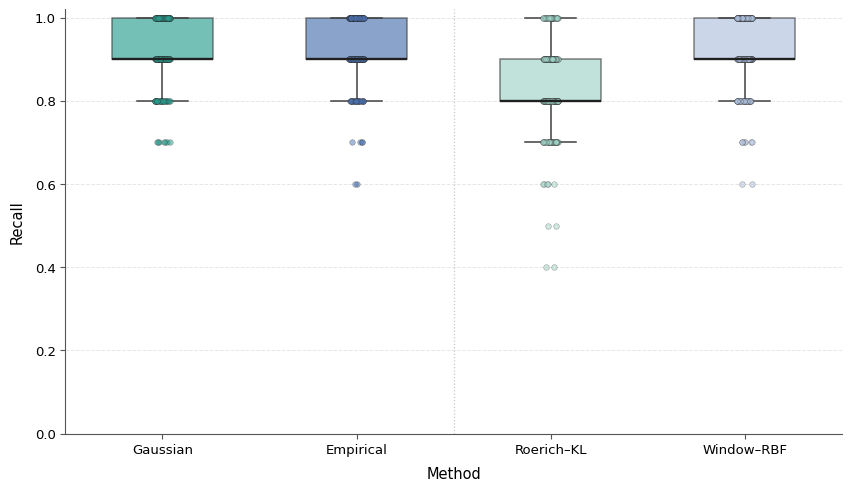

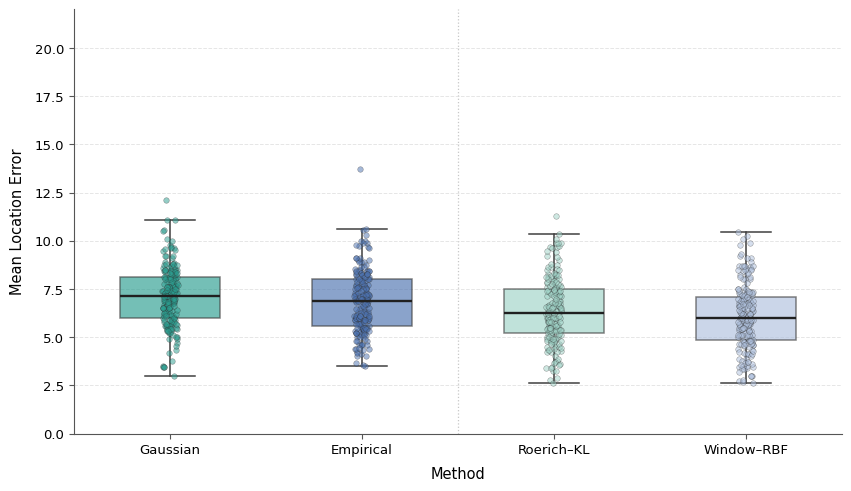

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.301380,0.9240,0.453448,7.114014
1,Empirical,0.270560,0.9270,0.418061,6.831748
2,Roerich-KL,0.320521,0.8355,0.462640,6.374480
3,Window-RBF,0.253355,0.9225,0.396777,6.069562


WINDOW SIZE: 50


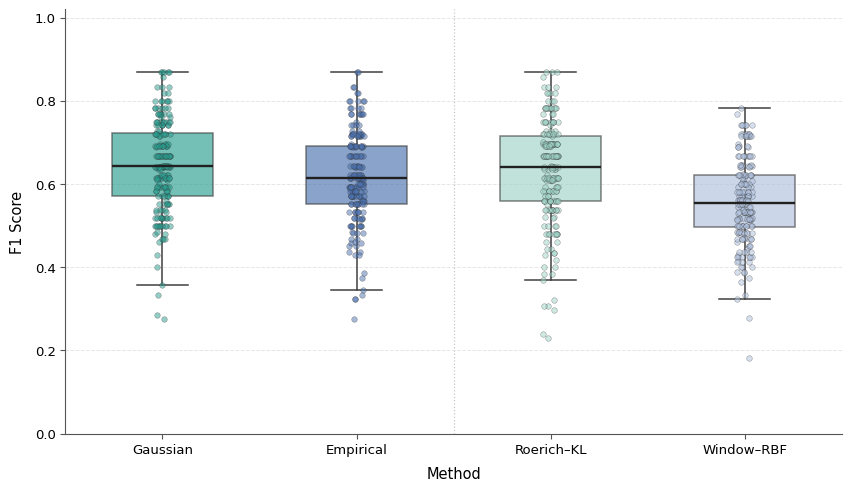

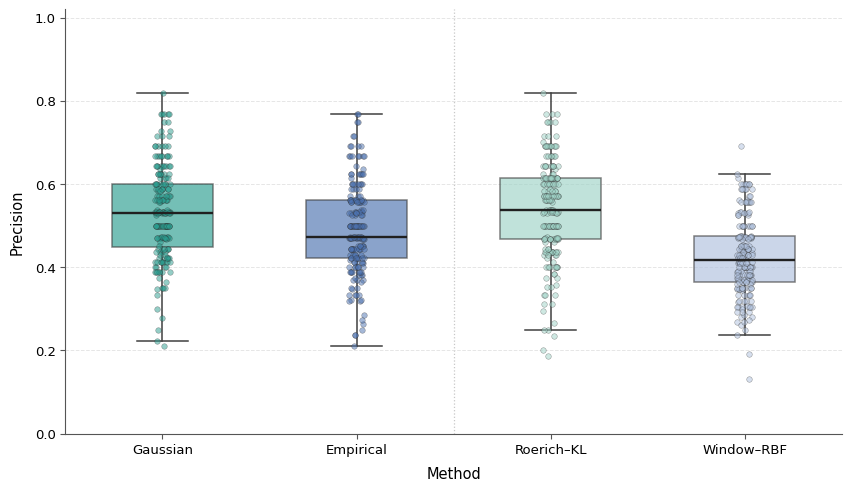

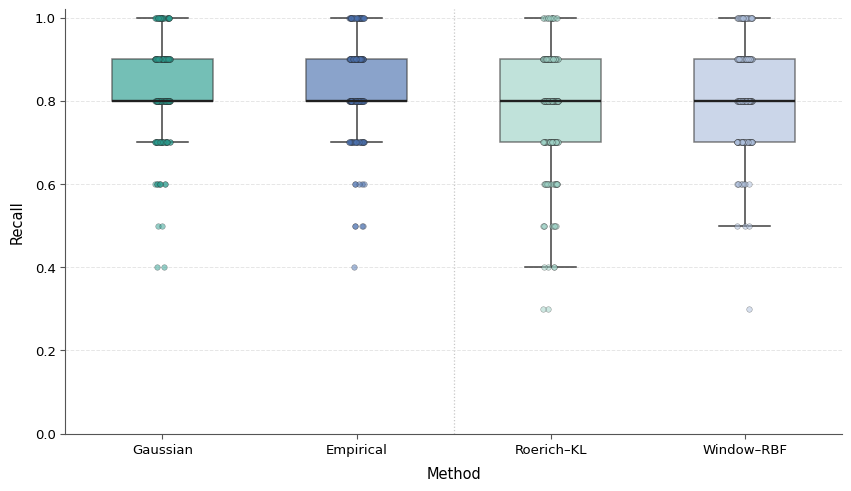

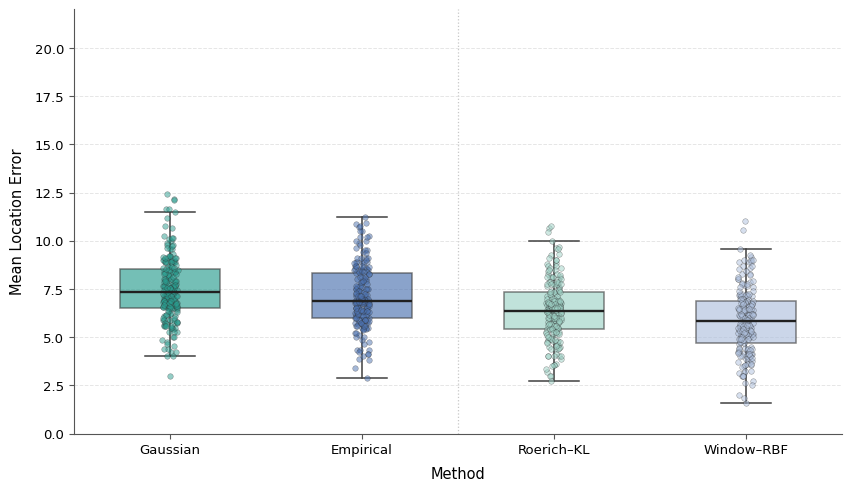

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.531035,0.8295,0.644514,7.458018
1,Empirical,0.491398,0.8370,0.615948,7.101266
2,Roerich-KL,0.535863,0.7710,0.630344,6.391835
3,Window-RBF,0.425688,0.8210,0.557784,5.824079


WINDOW SIZE: 80


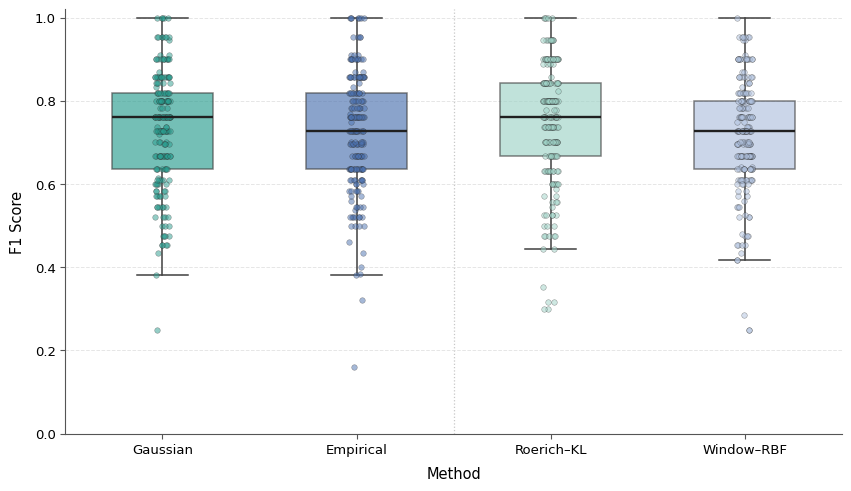

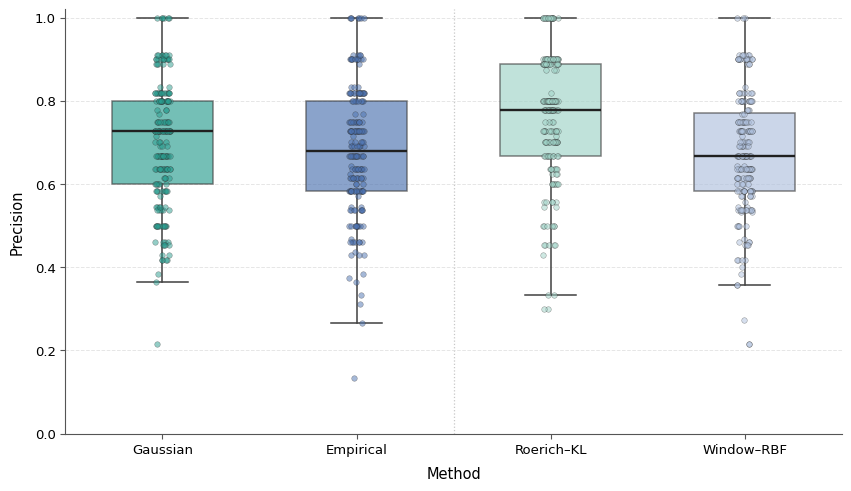

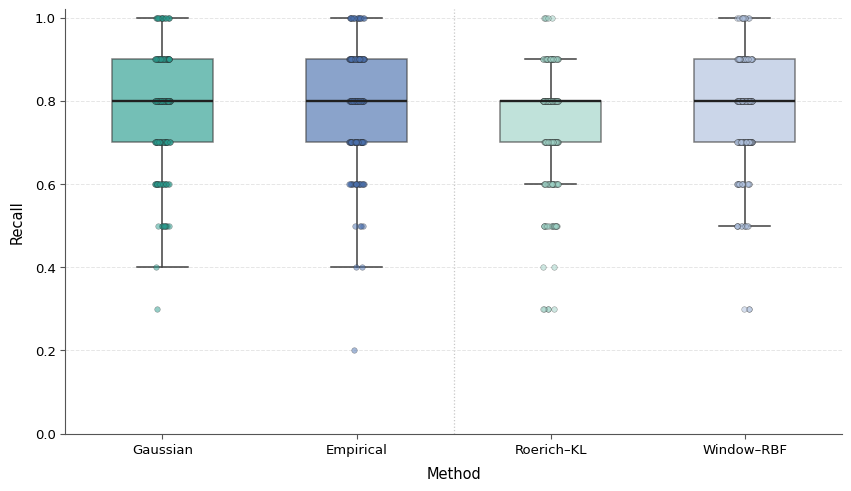

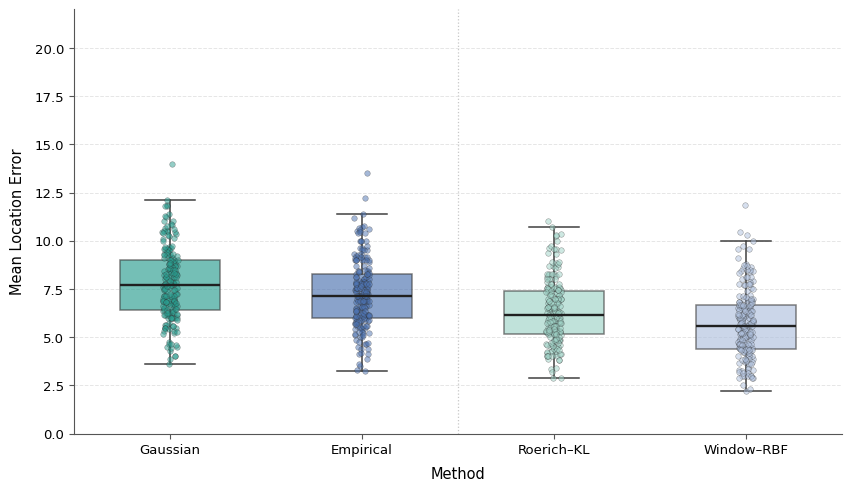

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.697033,0.7760,0.732359,7.758419
1,Empirical,0.679271,0.7855,0.726373,7.252946
2,Roerich-KL,0.762502,0.7310,0.744868,6.317454
3,Window-RBF,0.674440,0.7670,0.715064,5.709760


WINDOW SIZE: 100


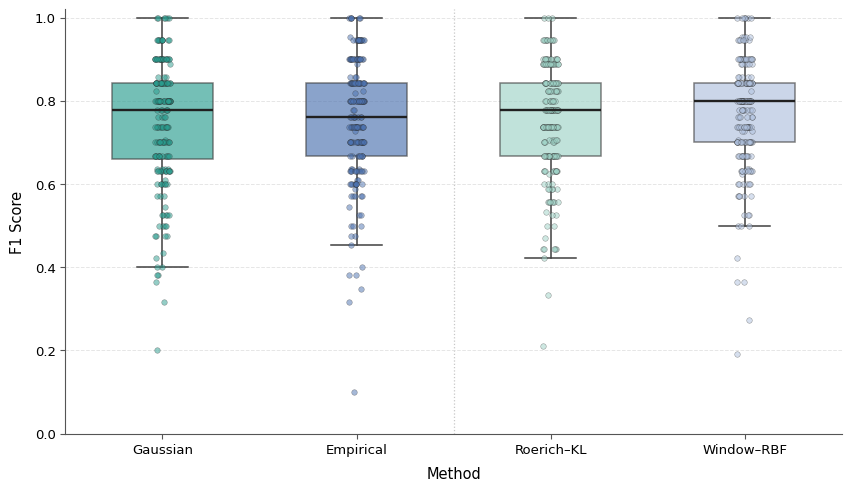

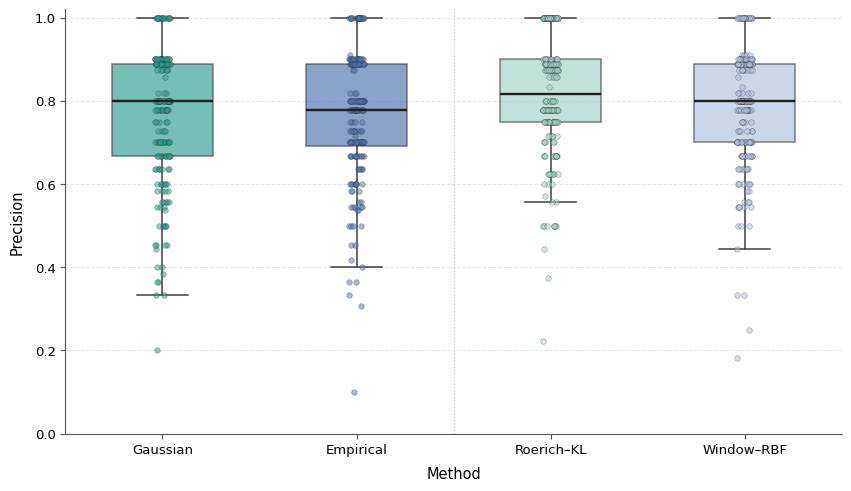

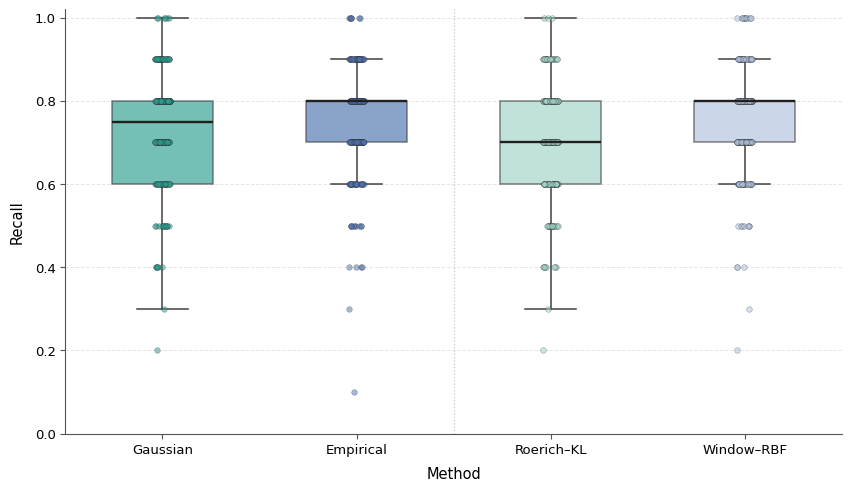

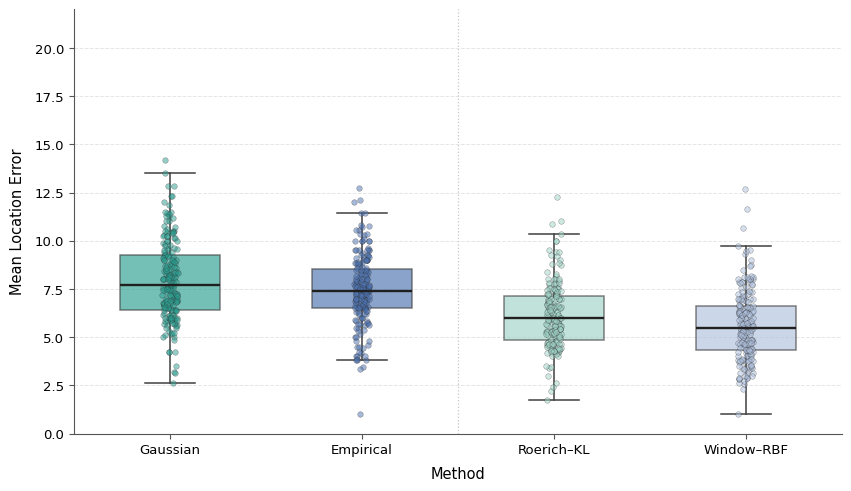

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.760805,0.7325,0.744722,7.917849
1,Empirical,0.765795,0.7440,0.753098,7.442762
2,Roerich-KL,0.816351,0.6965,0.749349,6.104357
3,Window-RBF,0.784392,0.7525,0.765999,5.594177


In [46]:
for w in [30, 50, 80, 100]:
    print("=" * 60)
    print(f"WINDOW SIZE: {w}")
    print("=" * 60)
    ruta_ar2_mdf = f"Resultados_Series_Simuladas/AR(2)_Fluctuating_average/Tables/ar2_mdf_metrics_window_{w}.xlsx"

    hojas = pd.read_excel(ruta_ar2_mdf, sheet_name=None)

    listas = [df.to_dict(orient="records") for df in hojas.values()]

    lista_gauss, lista_emp, lista_roerich, lista_window_rbf = listas

    nombres_boxplot = [
                        "Gaussian",
                        "Empirical",
                        "Roerich–KL",
                        "Window–RBF"
                    ]

    metrics_names = ['F1 Score', 'Precision', 'Recall', 'Mean Location Error']
    for n in metrics_names:
        ylim = (0, 1.02)
        name = n
        if n == 'Mean Location Error':
            ylim = (0, 22)
            name = "MLE"
        
        path_fig = f"Resultados_Series_Simuladas/AR(2)_Fluctuating_average/Graphics/Window {w}/{name}_AR2_mdf_w{w}.png"
        fig, ax = plot_boxplots(
                                datos=[
                                    [m[n] for m in lista_gauss],
                                    [m[n] for m in lista_emp],
                                    [m[n] for m in lista_roerich],
                                    [m[n] for m in lista_window_rbf]
                                ],
                                nombres=nombres_boxplot,
                                ylabel=n,
                                xlabel="Method",
                                ylim=ylim,
                                save_path = path_fig
                            )
    ruta_avg_ar2_mdf = f"Resultados_Series_Simuladas/AR(2)_Fluctuating_average/Tables/ar2_mdf_metrics_avg_window_{w}.xlsx"
    average_table = generar_tabla_desde_diccionarios(
                                                        [lista_gauss, lista_emp, lista_roerich, lista_window_rbf],
                                                        ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                        ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                        )
    display(average_table)
    average_table.to_excel(ruta_avg_ar2_mdf, index=False)

### 6.2. EXPERIMENTO AR(2) CON REZAGOS FLUCTUANTES

### 6.2.1. Simulaciones

In [17]:
def experiment_ar2_rf_temporal_dependence(w=100, delta=20, prominence_ratio=0.05):
    metricas_ar2_rf_gauss_fw = []
    metricas_ar2_rf_emp_fw = []
    metricas_ar2_rf_roerich = []
    metricas_ar2_rf_window_rbf = []

    for i in range(200):
        print(i)
        ar2_rf, cps_ar2_rf, outliers_ar2_rf = ar2_noise(
                        T = 2000,
                        n_segmentos = 11,
                        min_seg = 100,
                        max_seg = 200,
                        random_phi = True,
                        base_mean = 0.5,
                        random_mean = False,
                        base_std = 0.5,
                        random_std = True,
                        std_range = (0.3, 1.2),
                        seed = 1234+i
        )
        
        #Gaussiano
        cpd_ar2_rf = CPD(ar2_rf, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
        distancias_ar2_rf = cpd_ar2_rf.distancias()
        cps_detect = detect(distancias_ar2_rf, w, prominence_ratio=prominence_ratio)
        metricas_ar2_rf_gauss_fw.append(metrics(cps_ar2_rf, cps_detect, delta, 2000)[0])

        #Empírico
        cpd_ar2_rf_emp = EmpiricalCPD(ar2_rf, window=w, smooth=True)
        distancias_ar2_rf_emp = cpd_ar2_rf_emp.distancias()
        cps_detect_emp = detect(distancias_ar2_rf_emp, w, prominence_ratio=prominence_ratio)
        metricas_ar2_rf_emp_fw.append(metrics(cps_ar2_rf, cps_detect_emp, delta, 2000)[0])

        #Roerich KL
        puntos_cambio_roerich_ar2_rf = detectar_cambios_roerich(
                                        ar2_rf,
                                        window_size=w,
                                        seed=42,
                                        periods=3
                                    )
        
        metricas_ar2_rf_roerich.append(metrics(cps_ar2_rf, puntos_cambio_roerich_ar2_rf, delta, len(ar2_rf))[0])

        #Window RBF
        puntos_cambio_ar2_rf_window_rbf = detectar_window_rbf(
                                                ar2_rf,
                                                window=w
                                            )
        
        metricas_ar2_rf_window_rbf.append(metrics(cps_ar2_rf, puntos_cambio_ar2_rf_window_rbf, delta, len(ar2_rf))[0])
        
    return metricas_ar2_rf_gauss_fw, metricas_ar2_rf_emp_fw, metricas_ar2_rf_roerich, metricas_ar2_rf_window_rbf

0

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 6.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 6.0000

Dispersion of Cost
──────────────────
    Execution Time              : 21.5822 s
    Best Window                 : 199

Dispersion of Cost
──────────────────
    Execution Time              : 21.5822 s
    Best Window                 : 199

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 199

Selección final
───

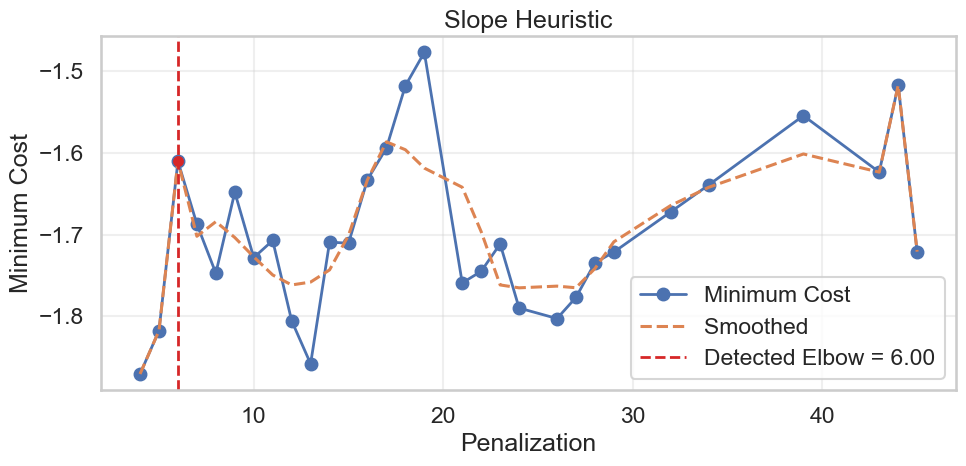

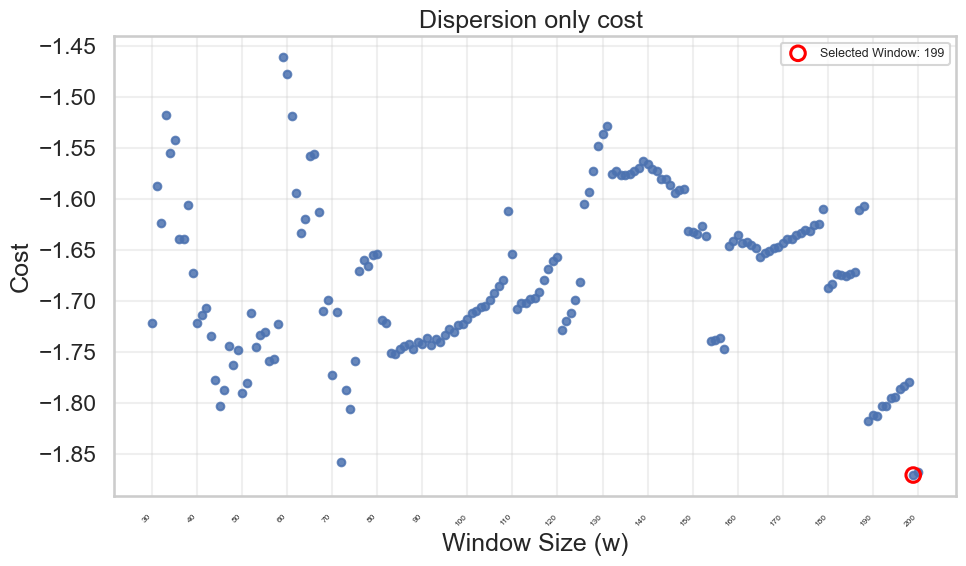

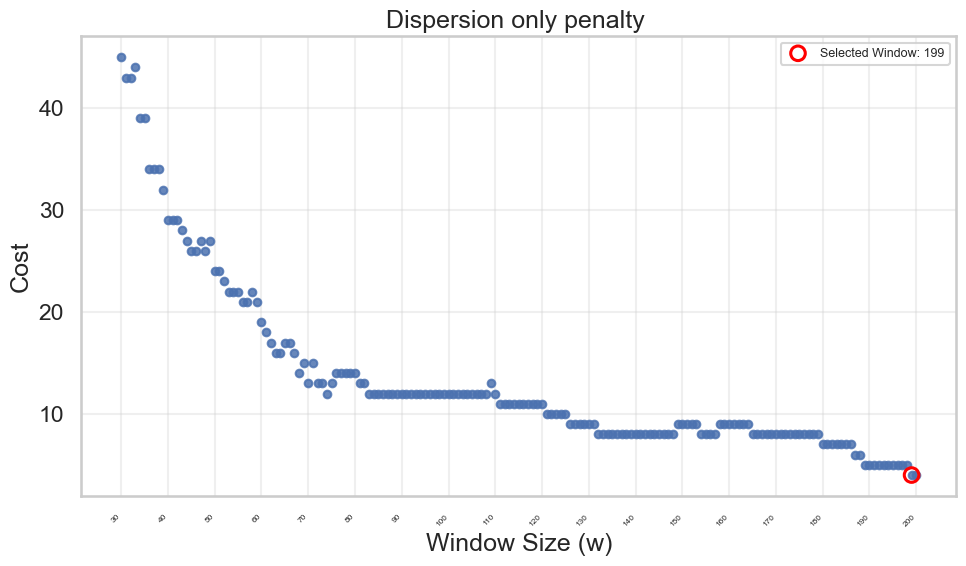

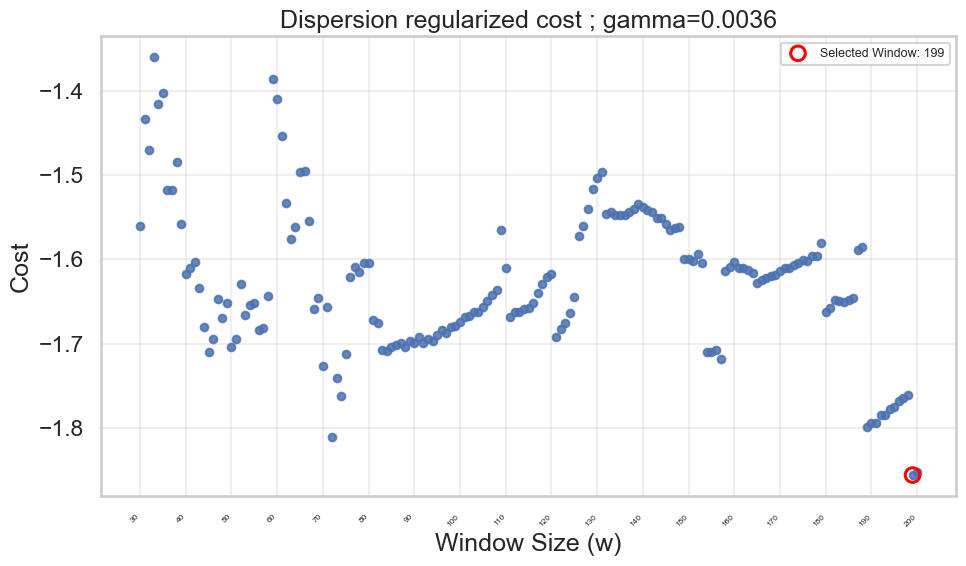

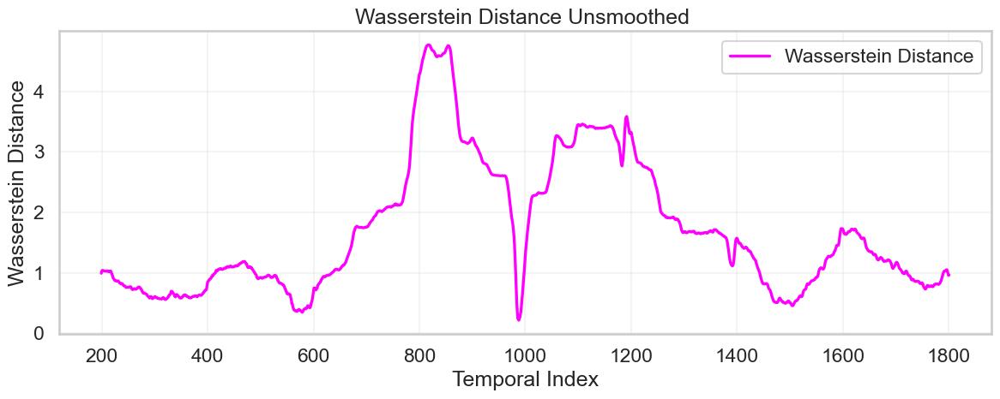

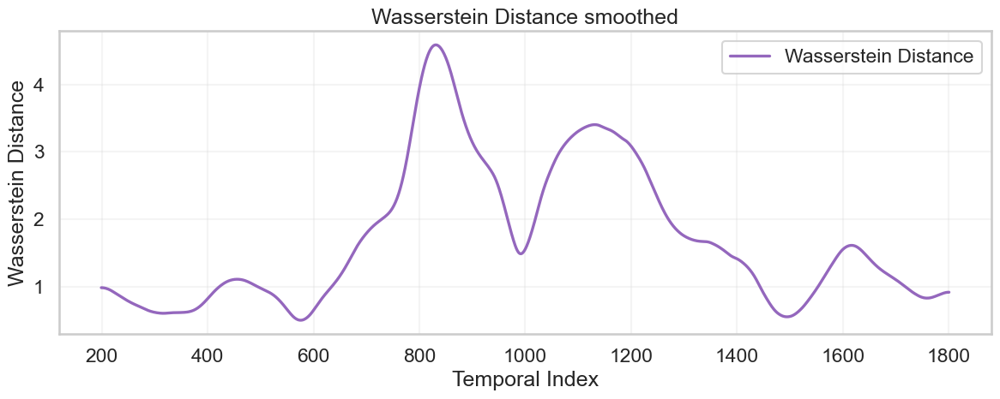

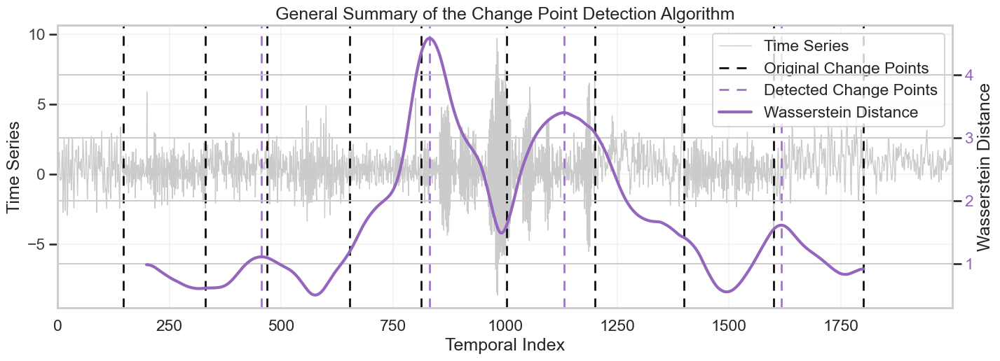


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 12.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 12.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.4417 s
    Best Window                 : 94

Dispersion of Cost
──────────────────
    Execution Time              : 14.4417 s
    Best Window                 : 94

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 94

Selección final
──────

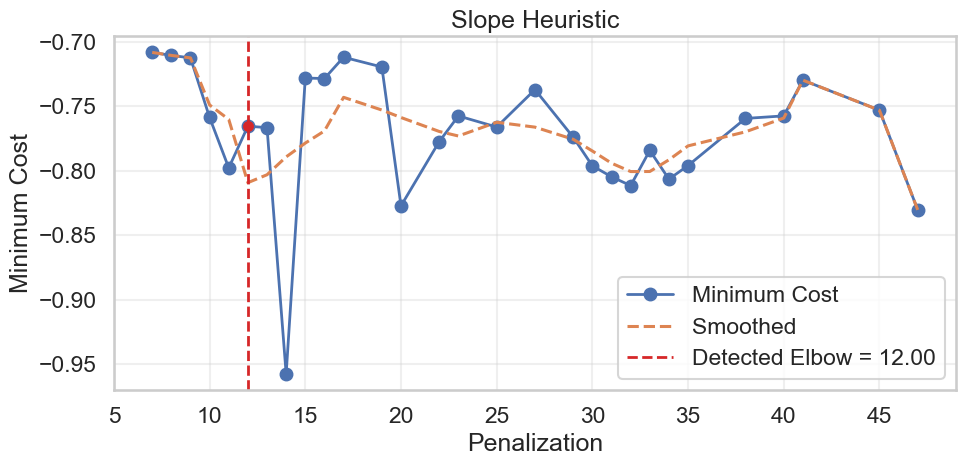

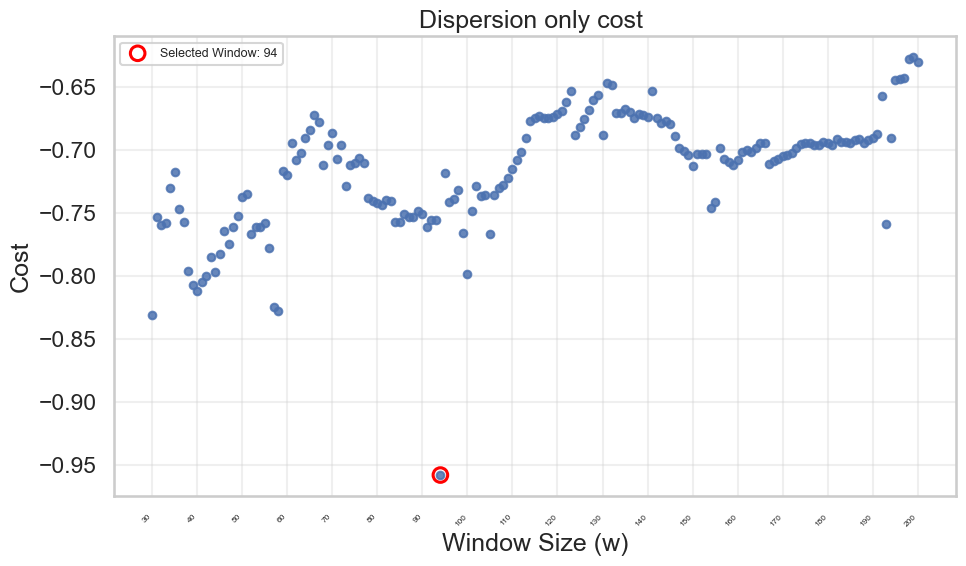

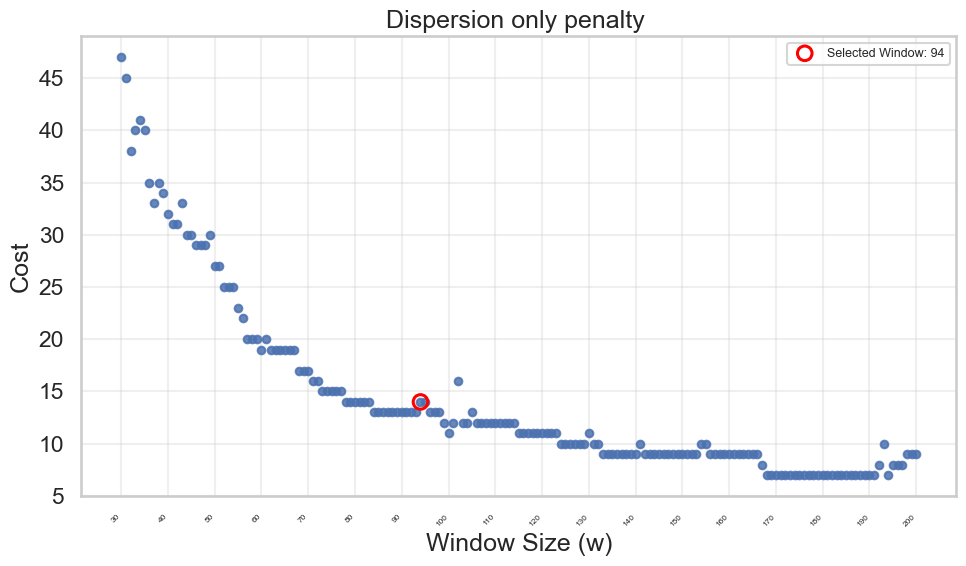

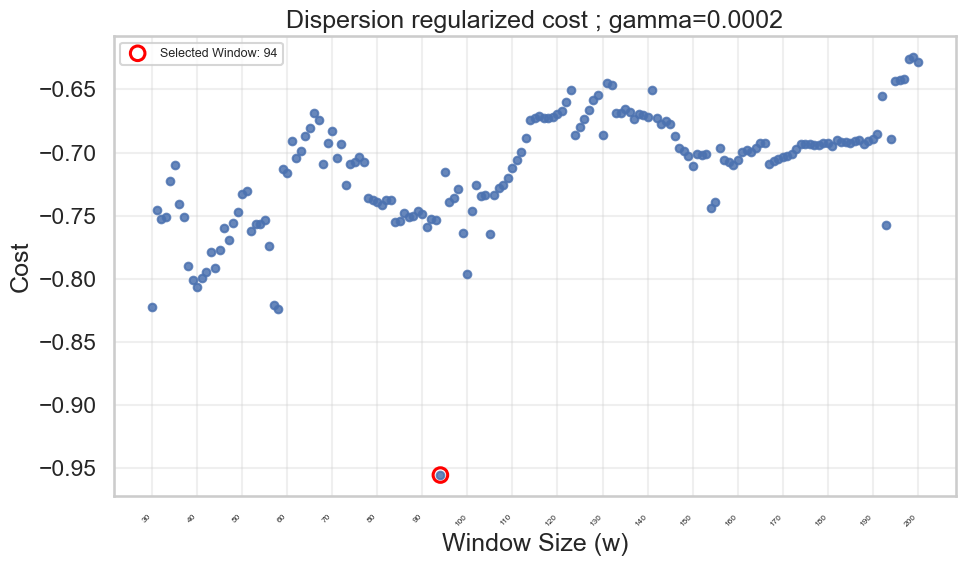

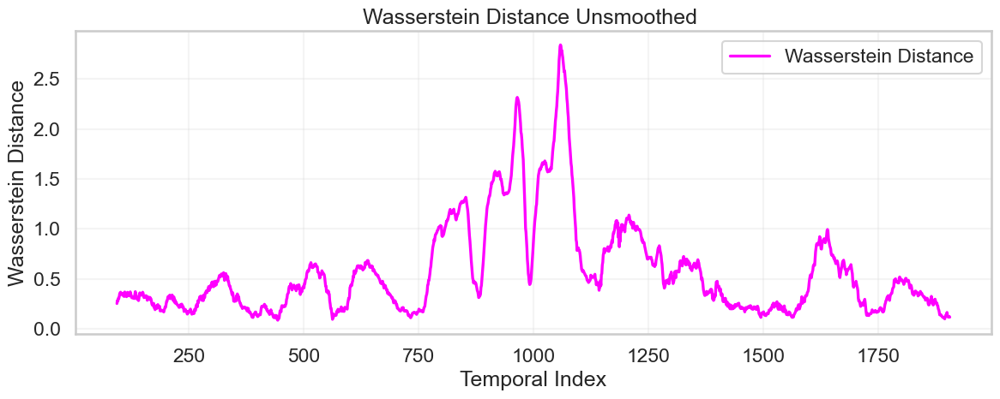

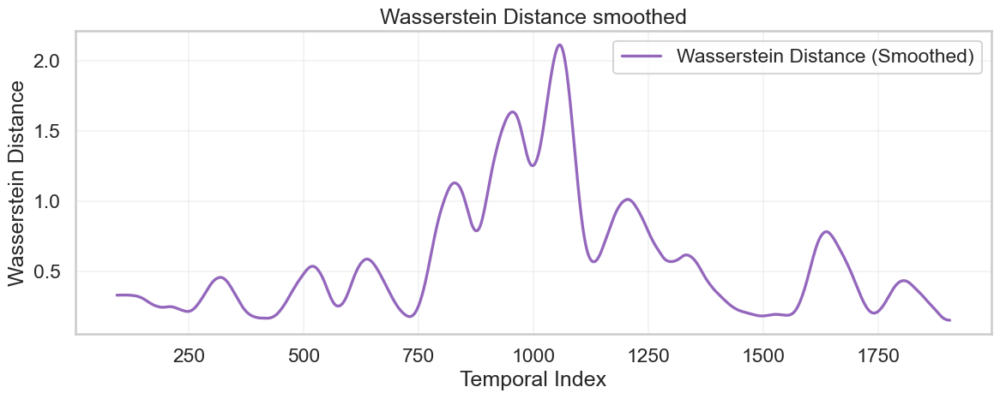

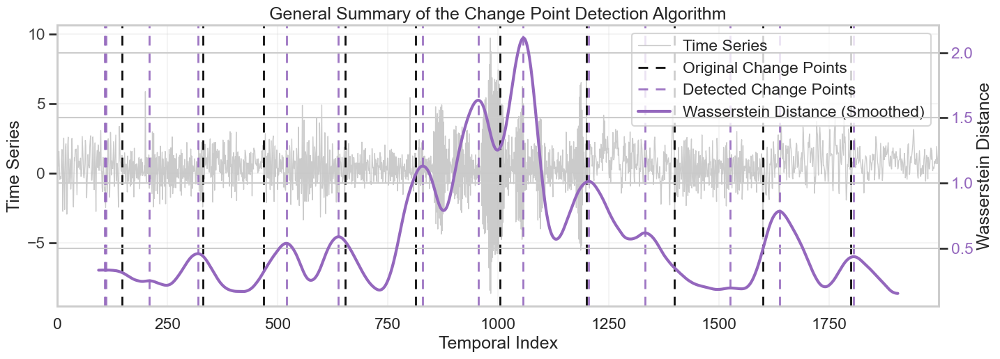

1

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 11.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 11.0000

Dispersion of Cost
──────────────────
    Execution Time              : 20.9330 s
    Best Window                 : 152

Dispersion of Cost
──────────────────
    Execution Time              : 20.9330 s
    Best Window                 : 152

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 152

Selección final
─

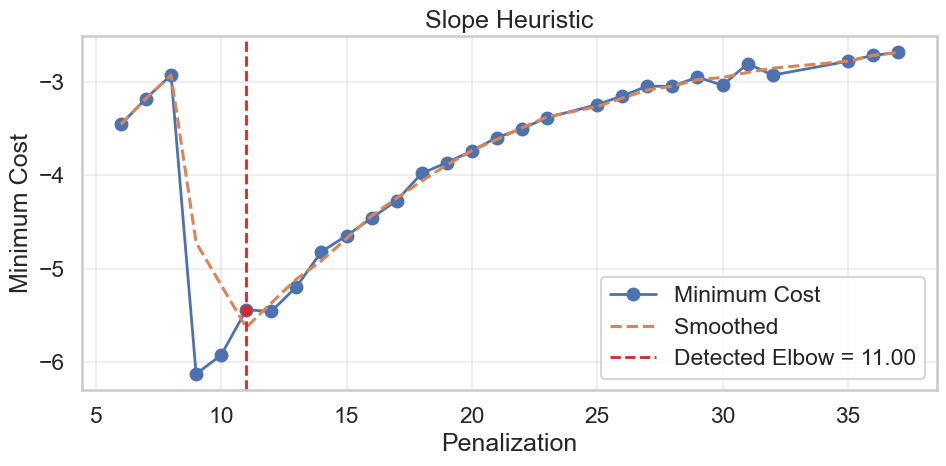

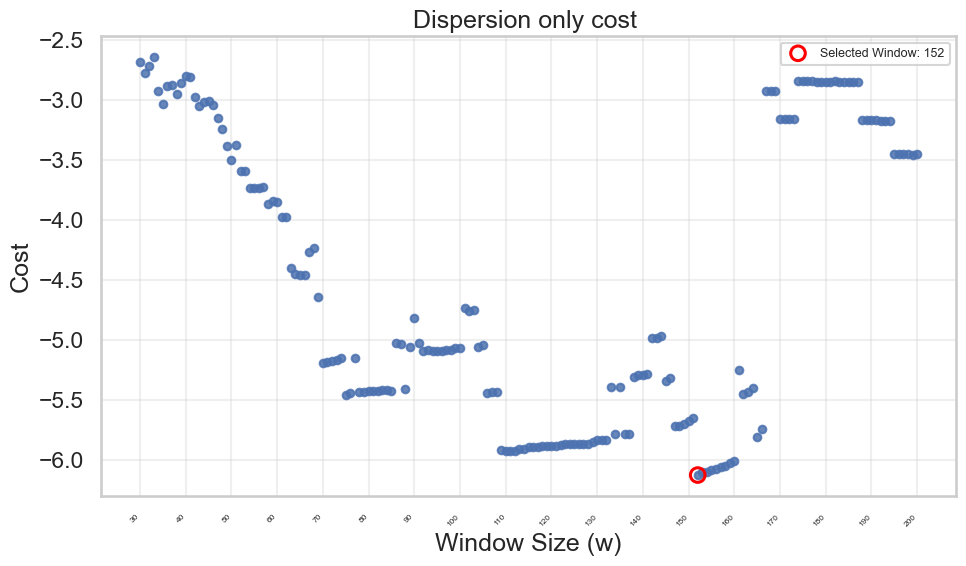

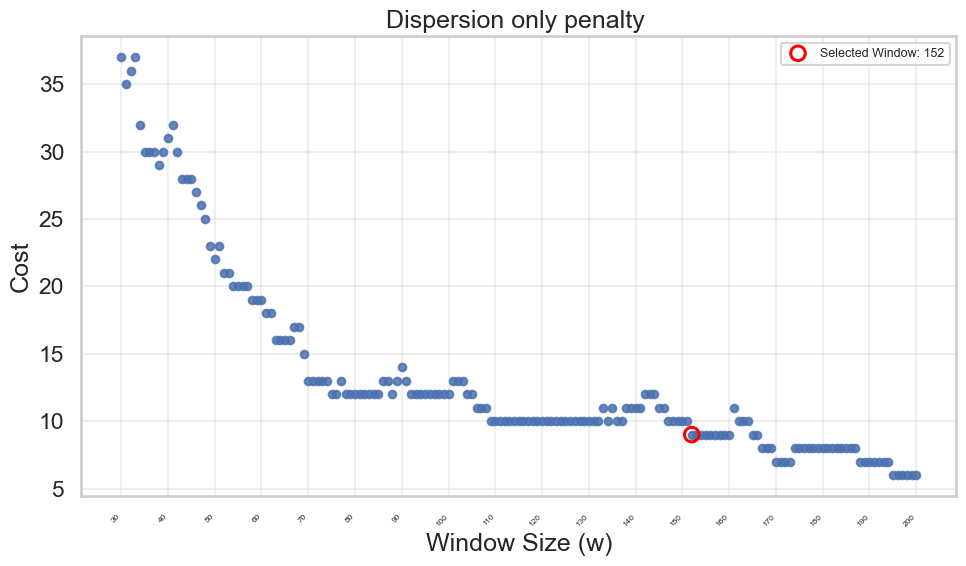

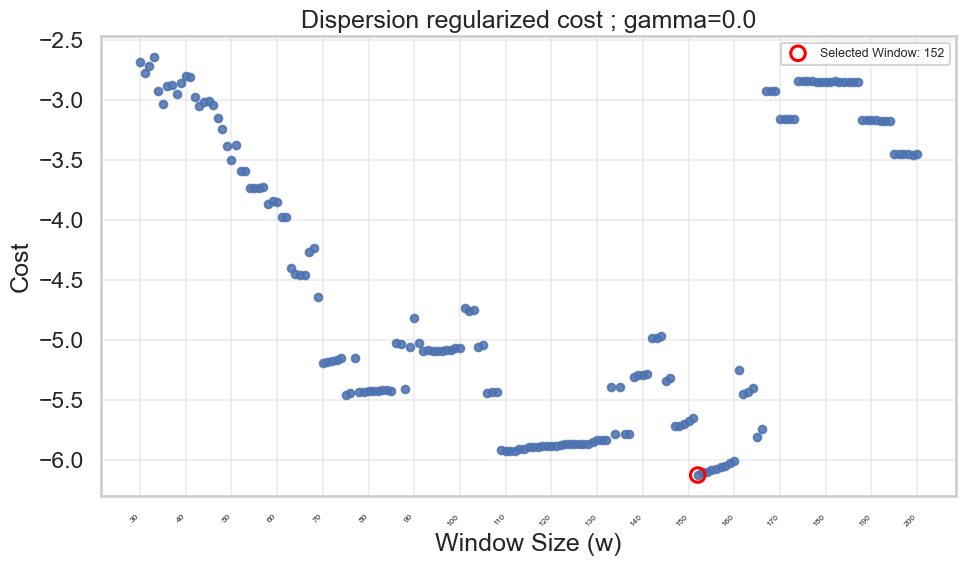

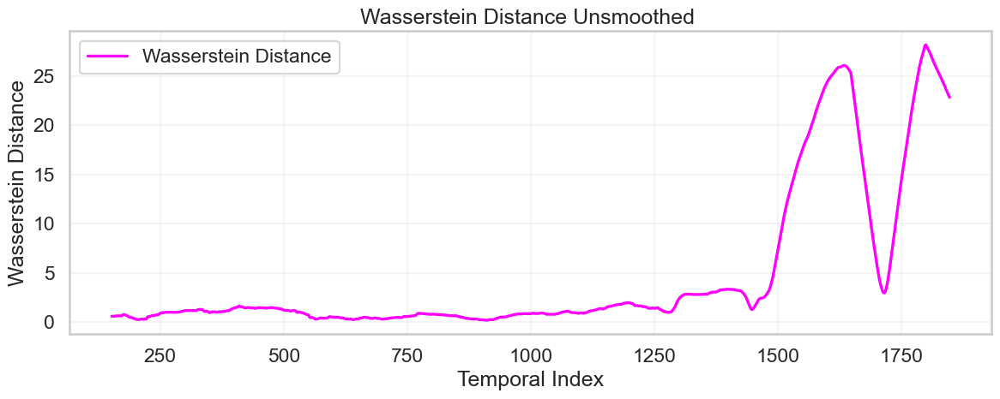

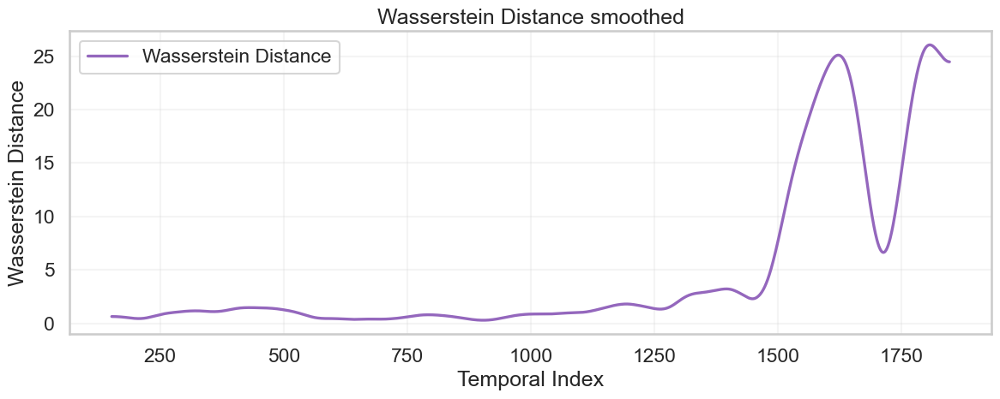

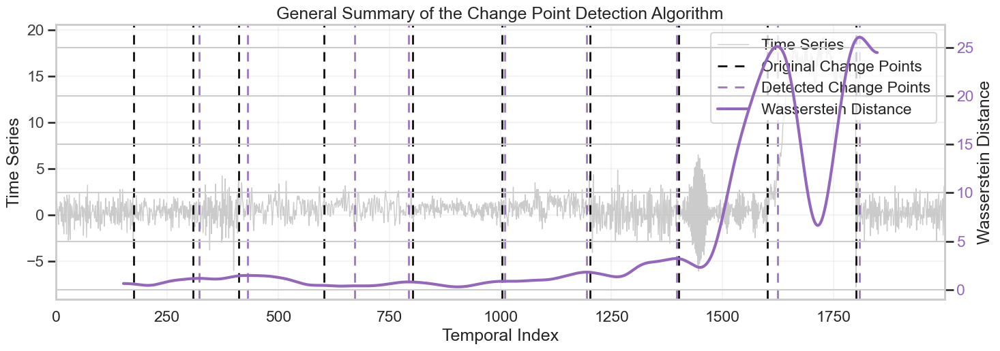


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.7524 s
    Best Window                 : 160

Dispersion of Cost
──────────────────
    Execution Time              : 14.7524 s
    Best Window                 : 160

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 160

Selección final
─────

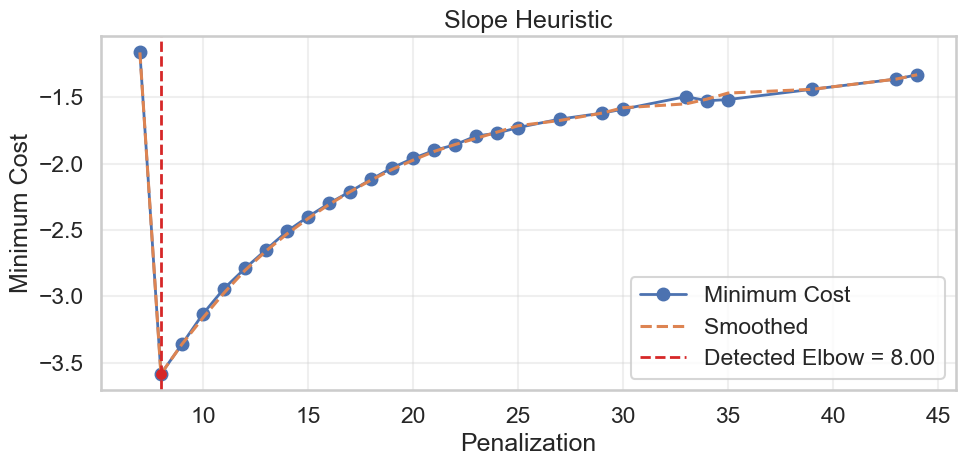

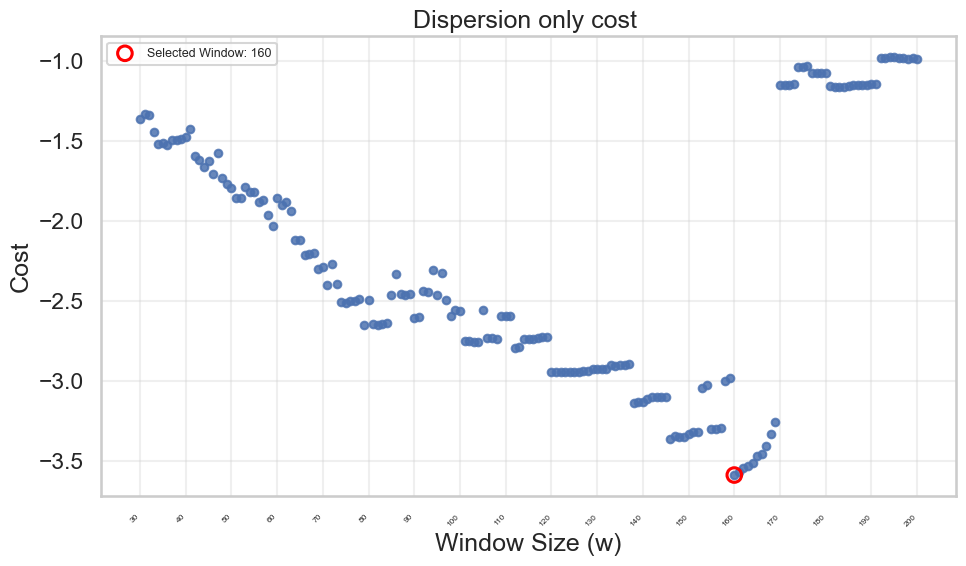

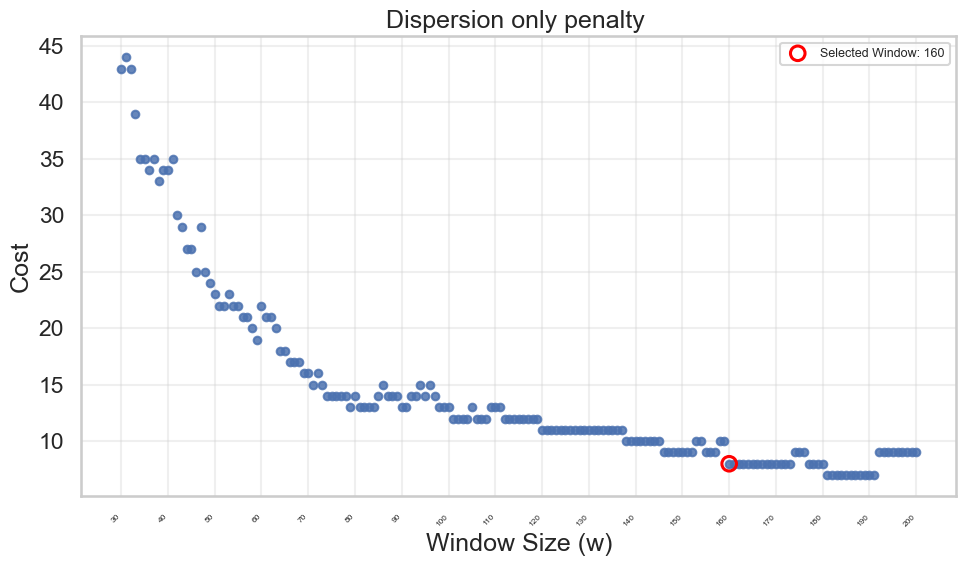

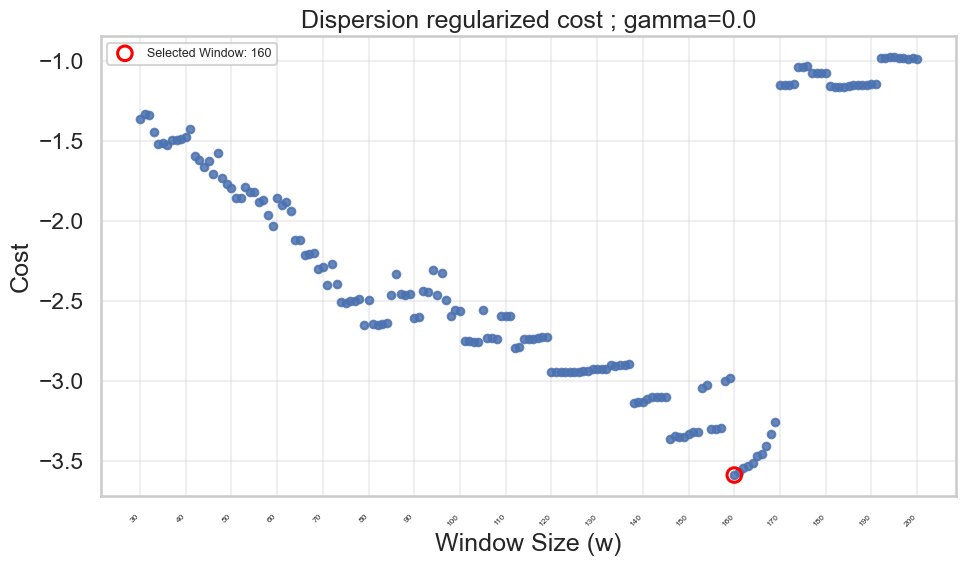

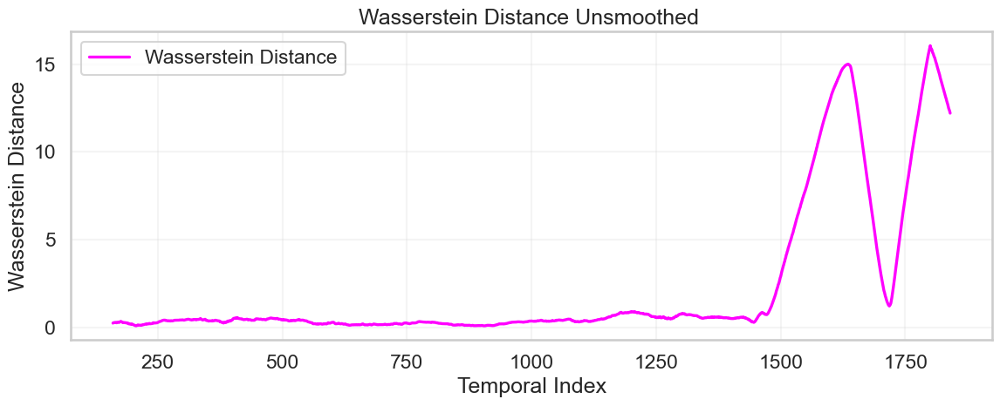

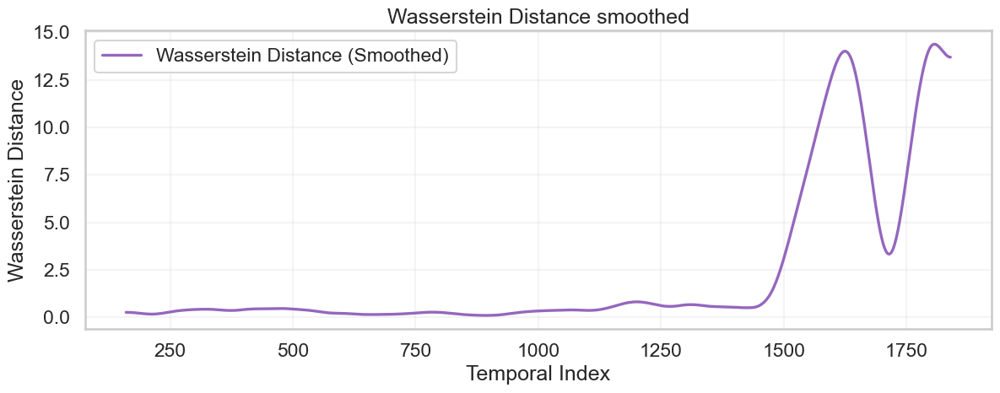

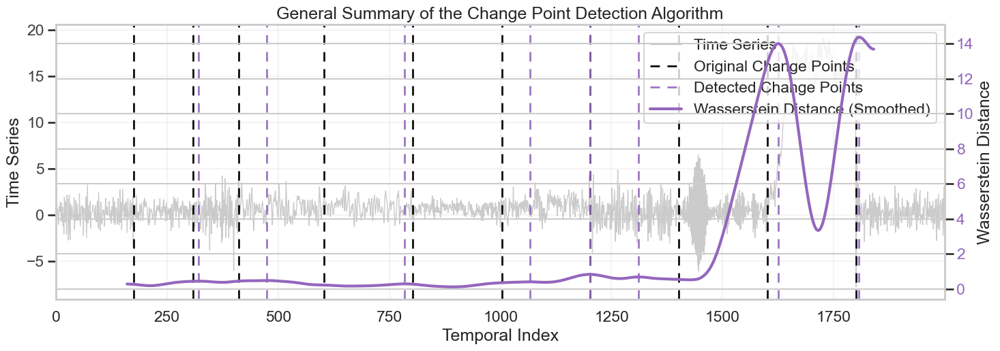

2

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Dispersion of Cost
──────────────────
    Execution Time              : 20.7162 s
    Best Window                 : 200

Dispersion of Cost
──────────────────
    Execution Time              : 20.7162 s
    Best Window                 : 200

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 200

Selección final
─

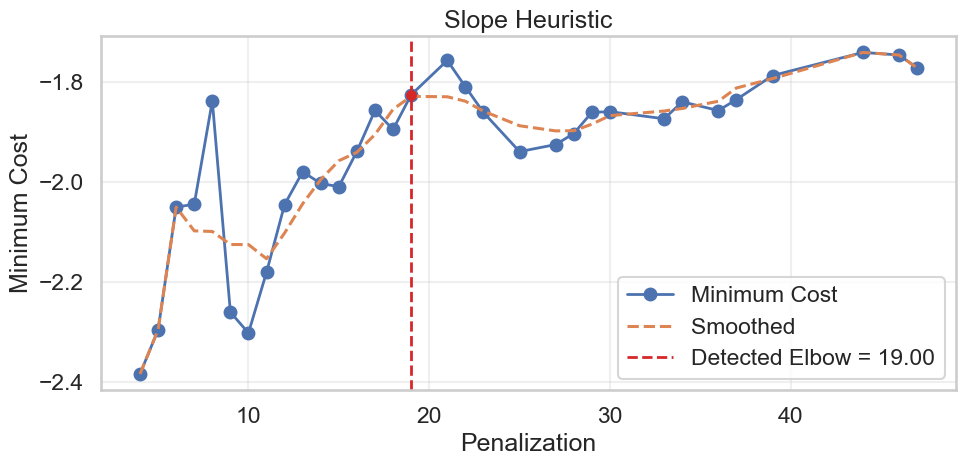

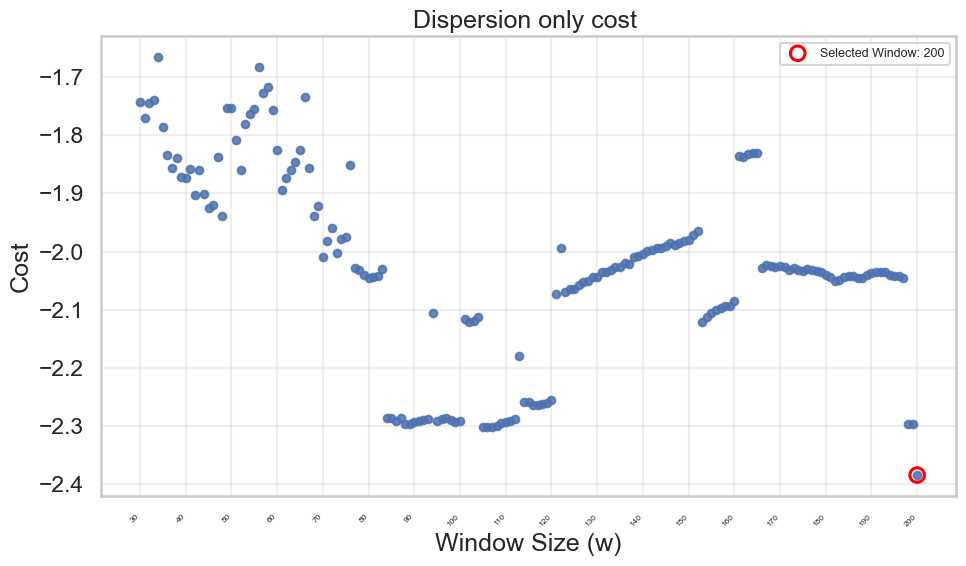

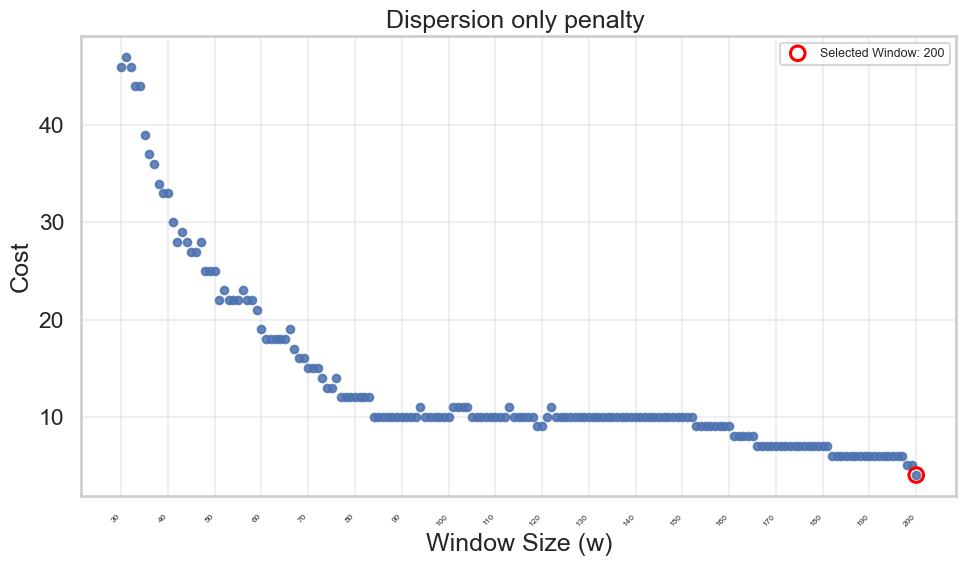

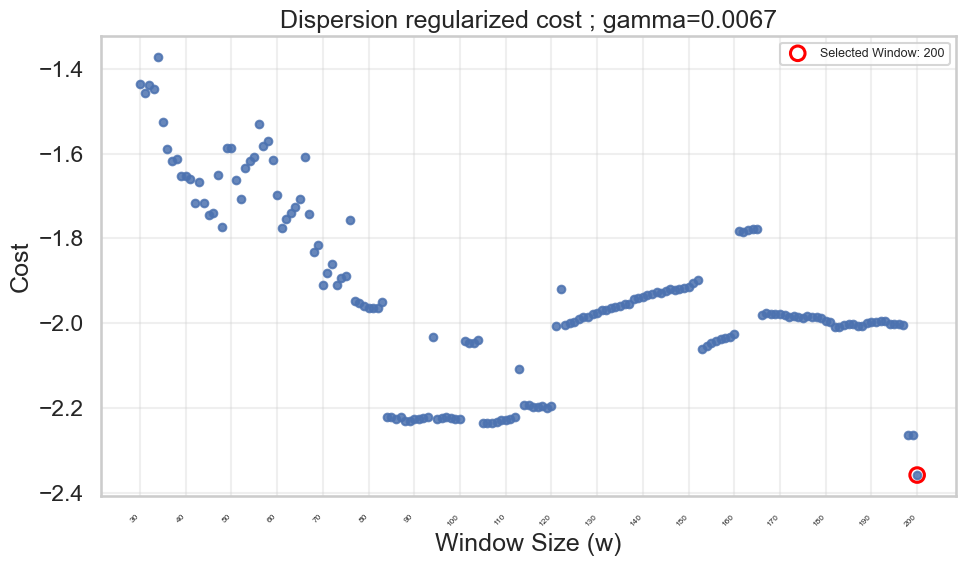

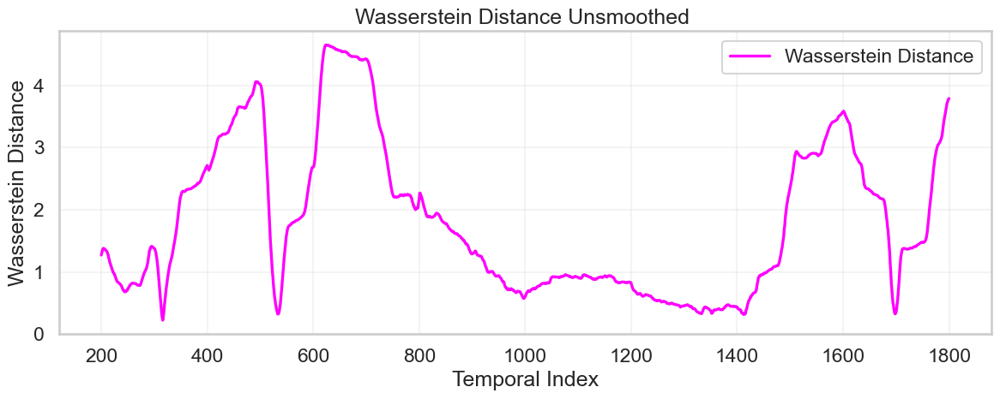

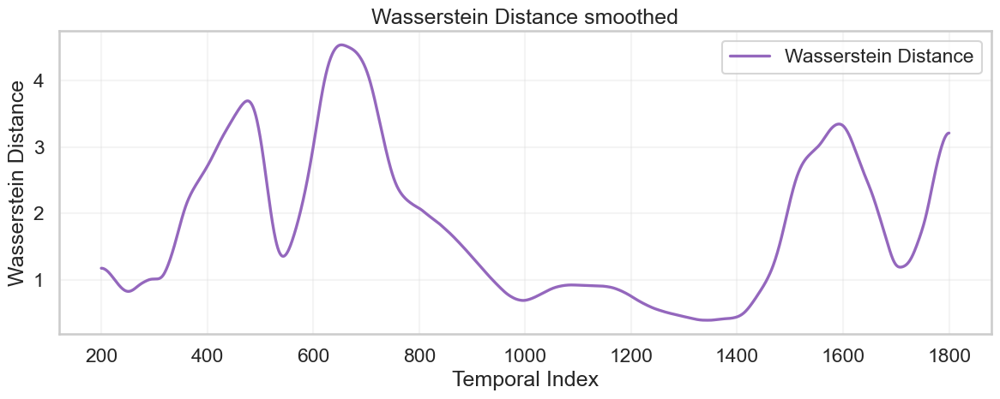

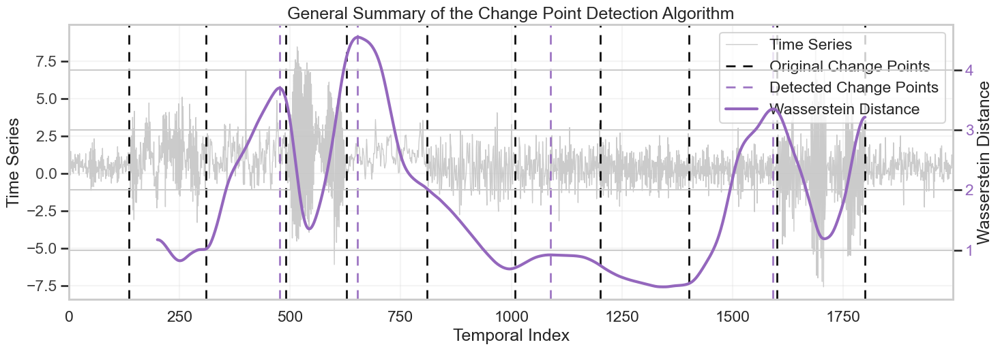


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.5713 s
    Best Window                 : 115

Dispersion of Cost
──────────────────
    Execution Time              : 14.5713 s
    Best Window                 : 115

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 115

Selección final
─────

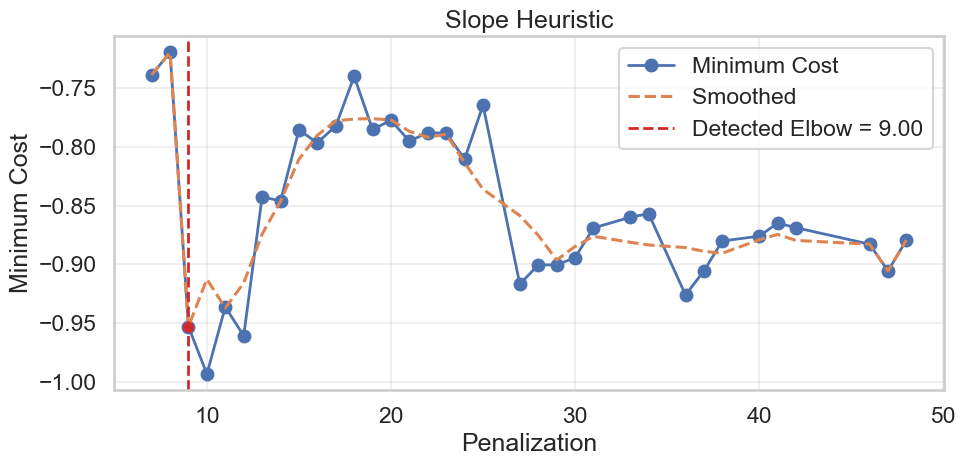

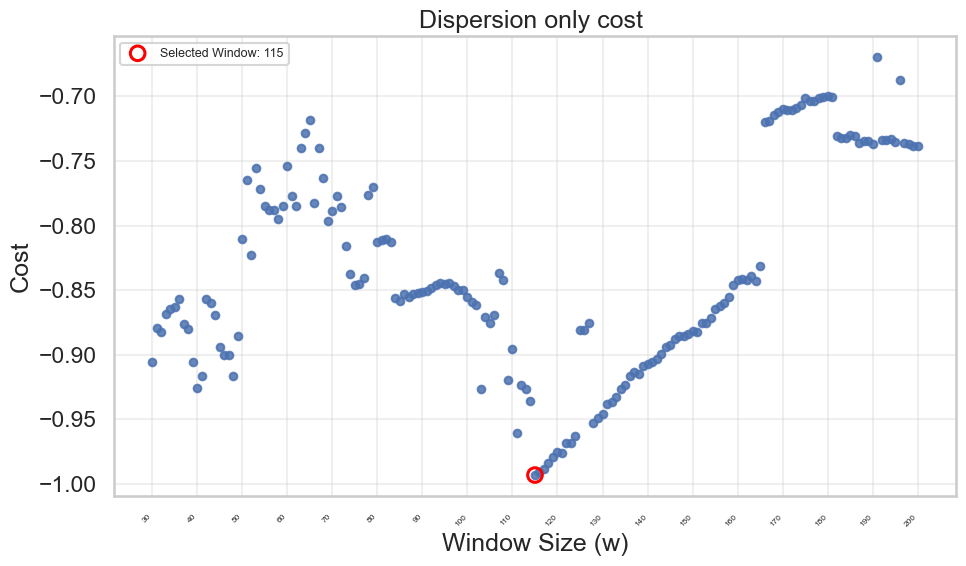

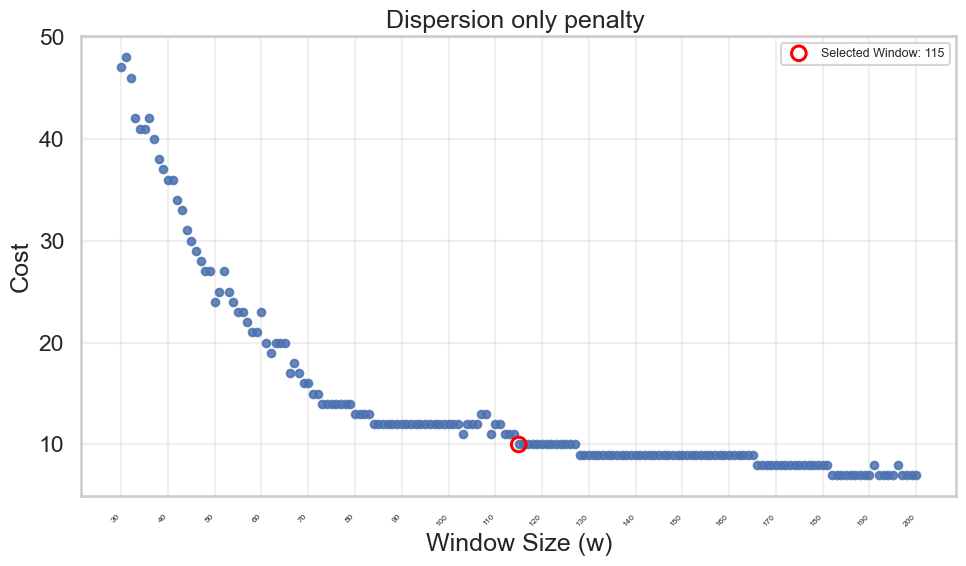

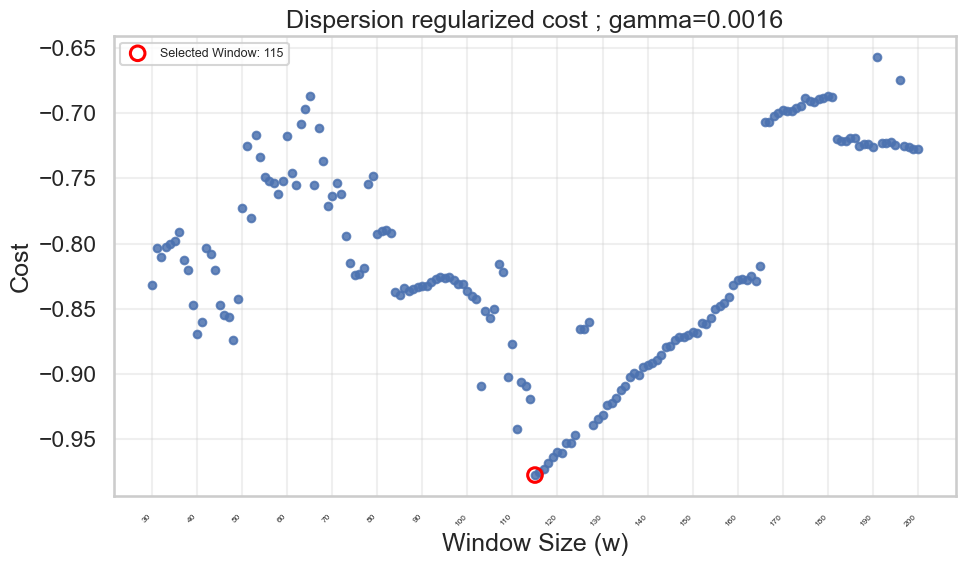

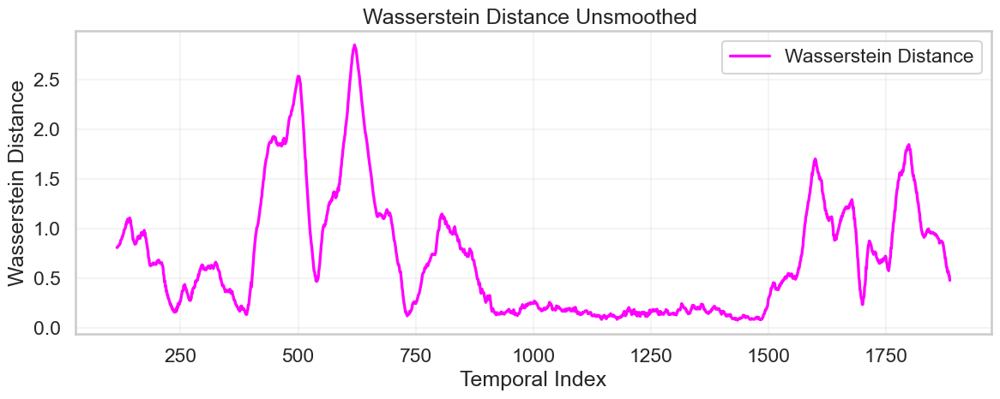

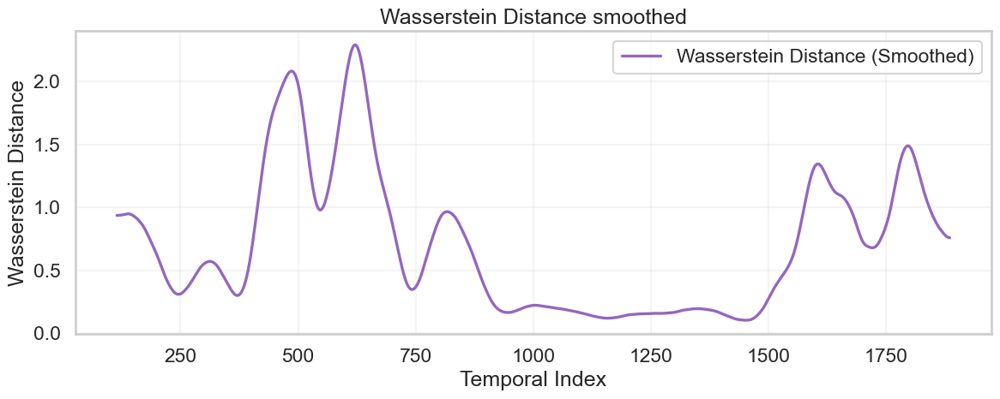

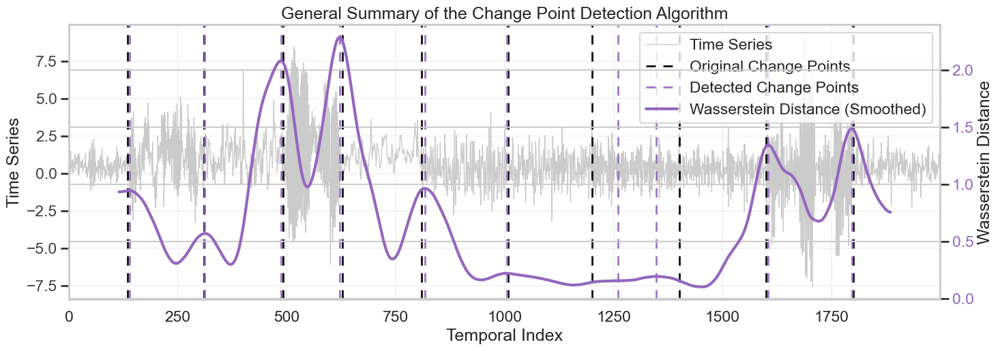

3

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Dispersion of Cost
──────────────────
    Execution Time              : 21.0190 s
    Best Window                 : 193

Dispersion of Cost
──────────────────
    Execution Time              : 21.0190 s
    Best Window                 : 193

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 193

Selección final
─

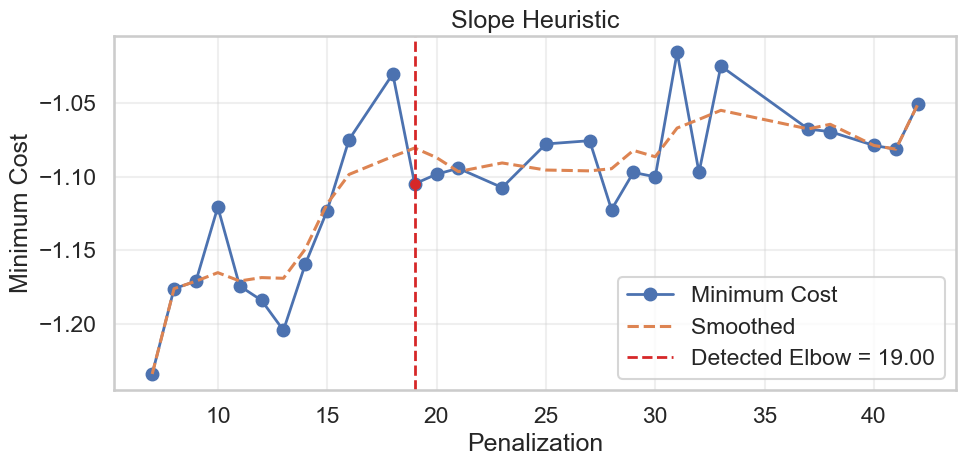

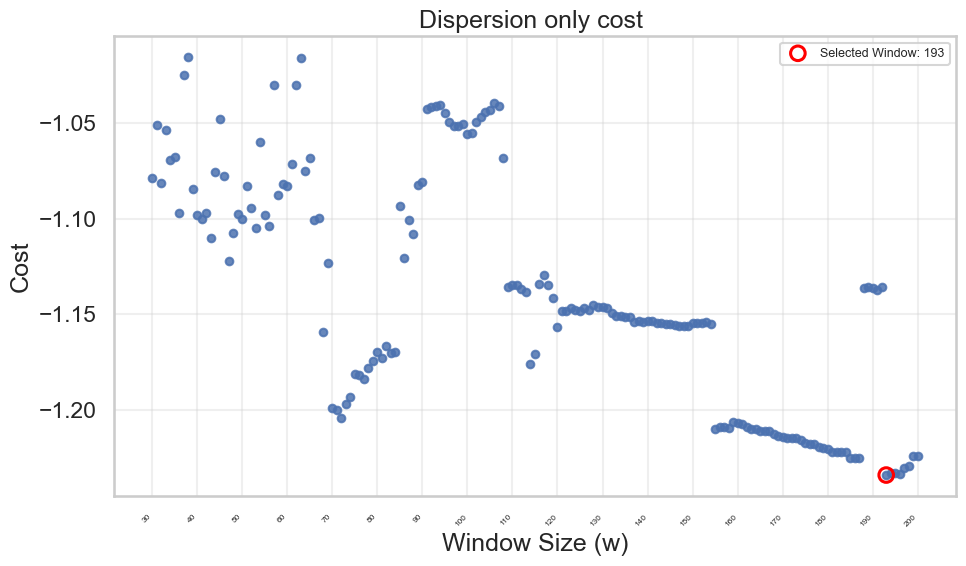

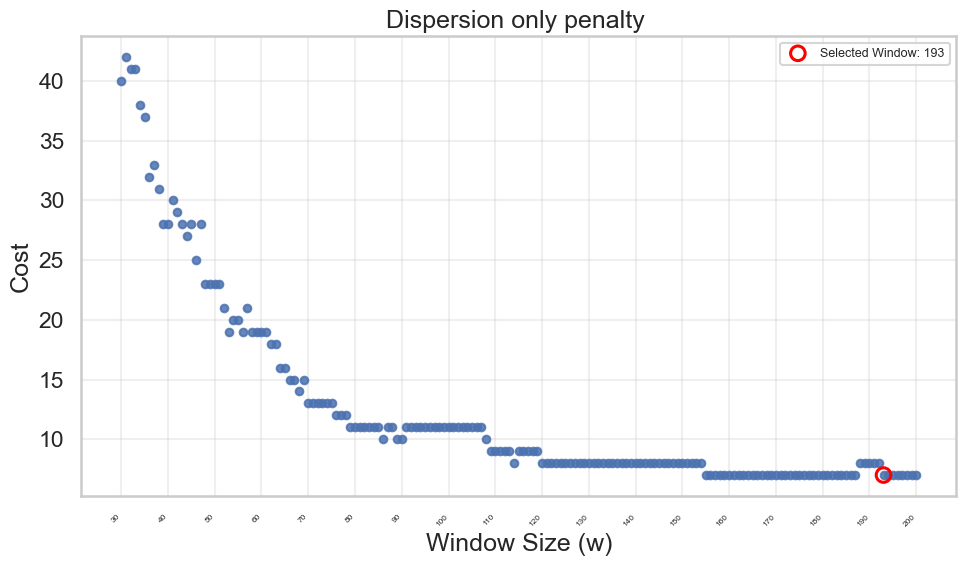

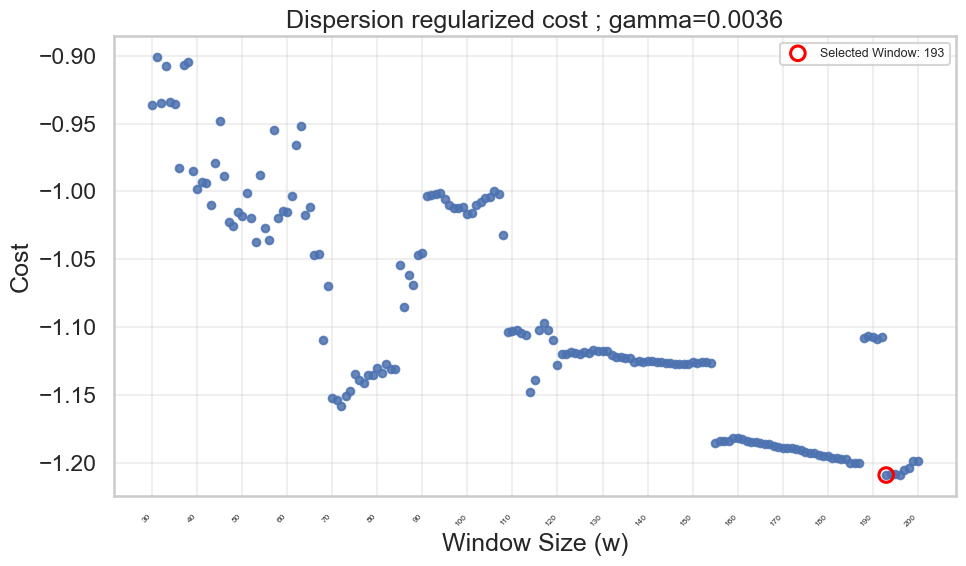

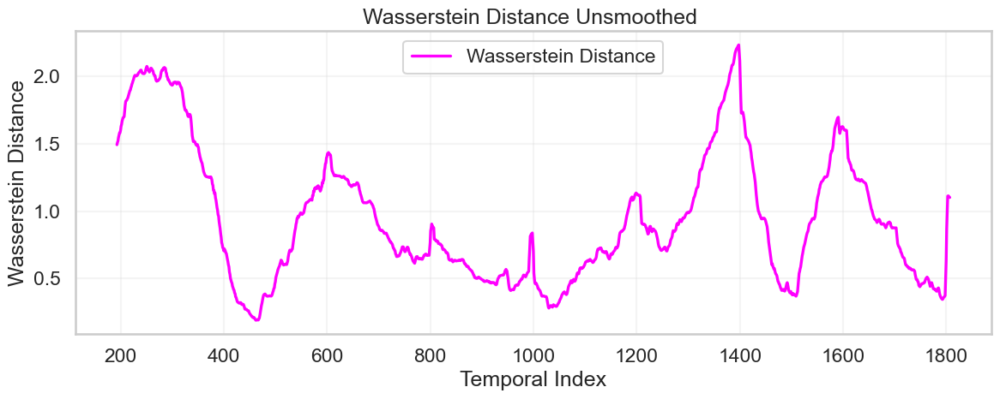

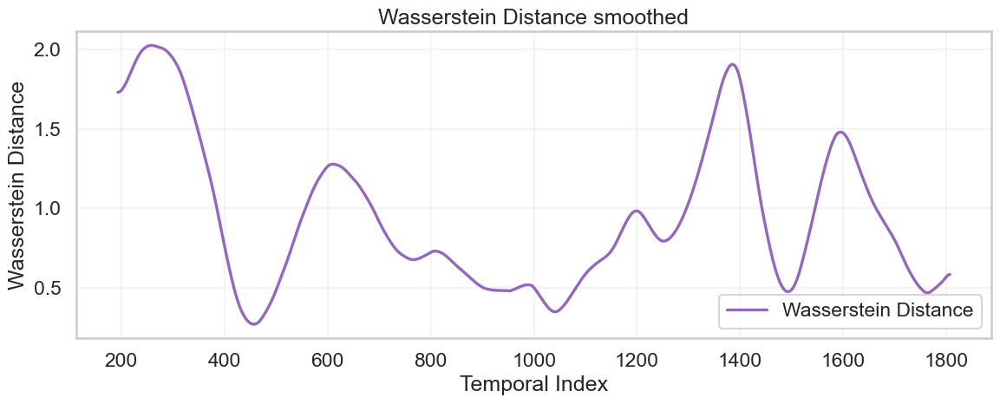

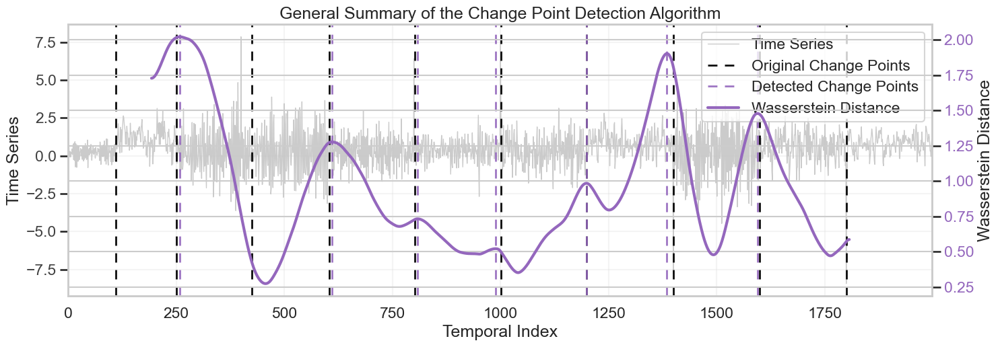


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 14.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 14.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.5377 s
    Best Window                 : 92

Dispersion of Cost
──────────────────
    Execution Time              : 14.5377 s
    Best Window                 : 92

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 92

Selección final
──────

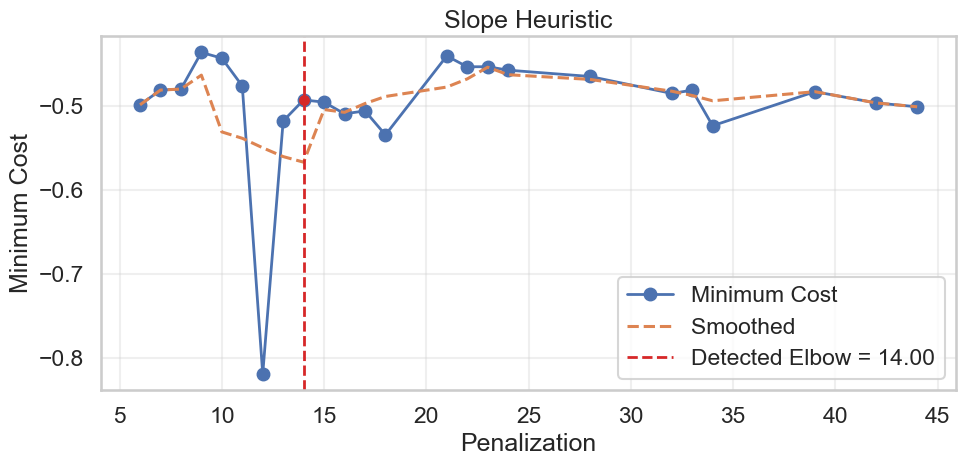

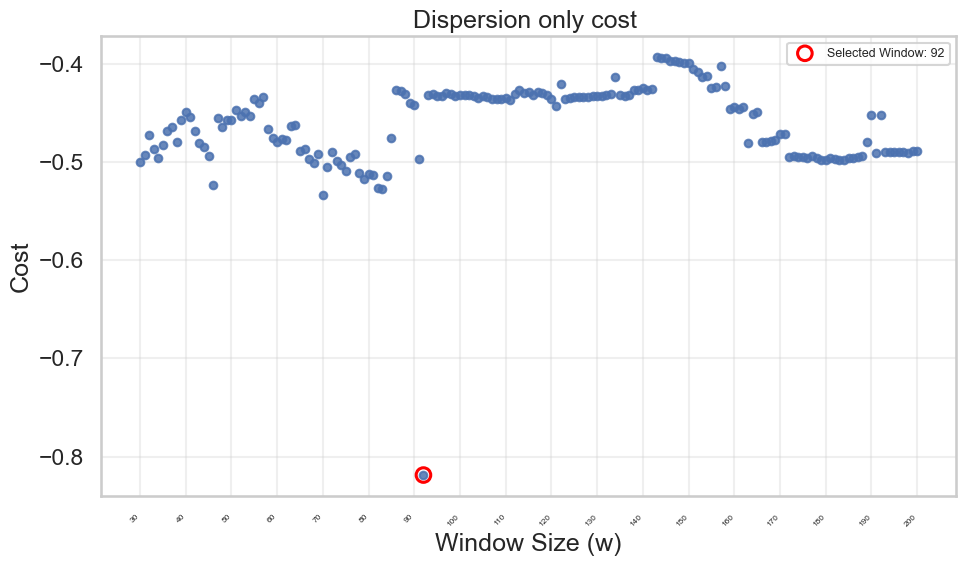

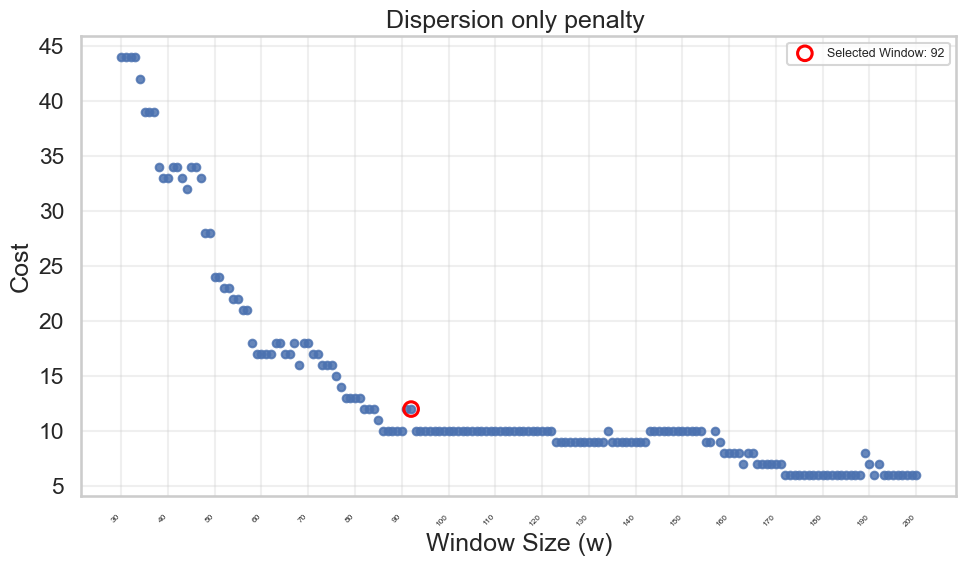

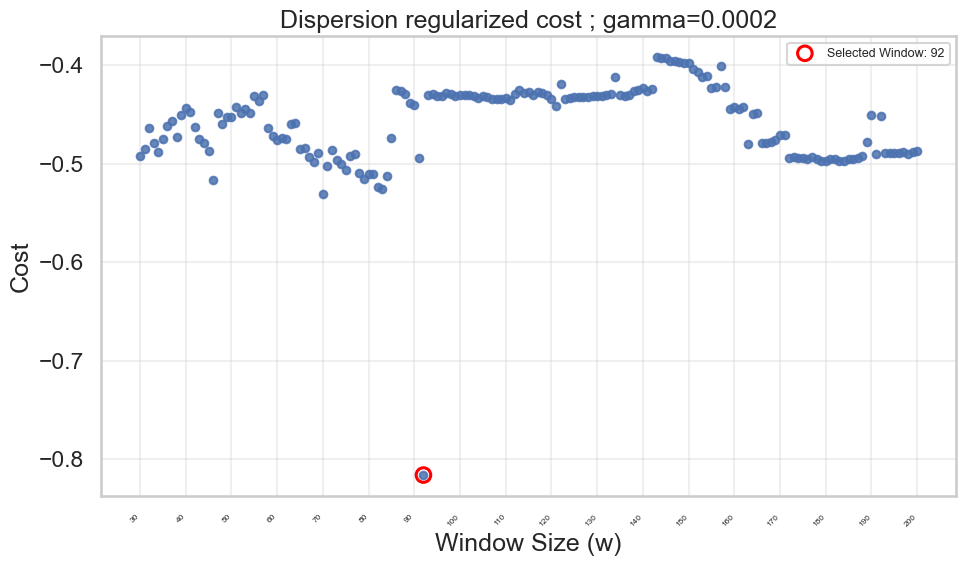

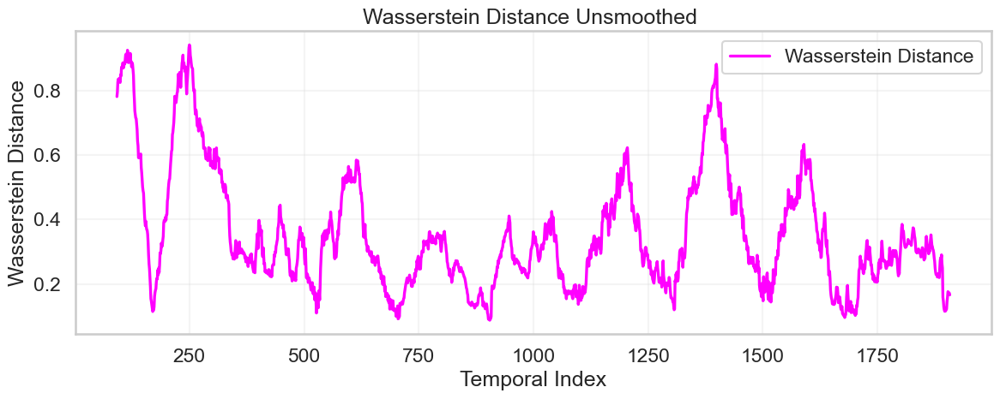

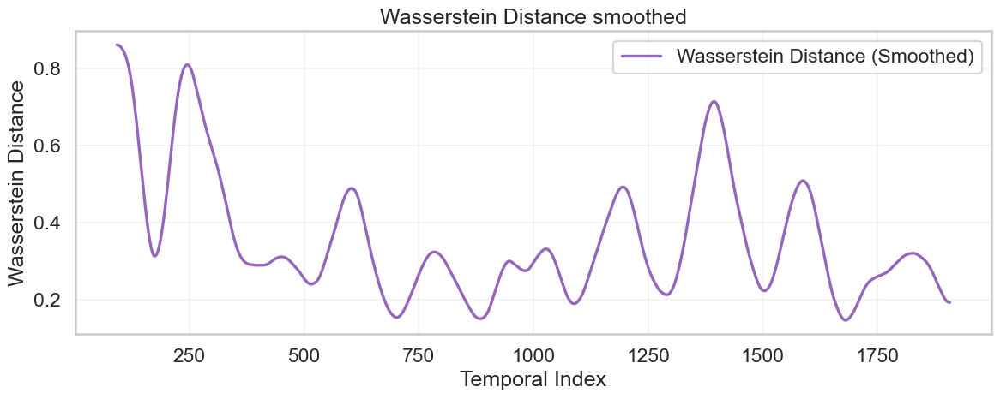

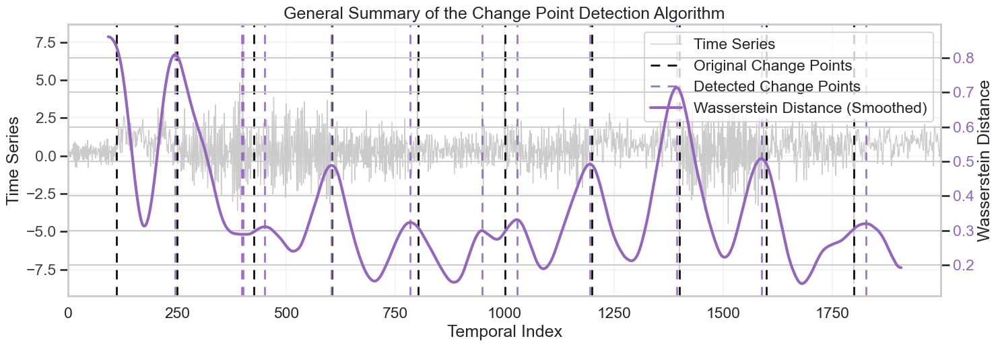

4

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 11.0000

Selección final
───────────────
    Ventana óptima              : 130
    Retardo óptimo              : 1
    Penalización mínima         : 0
    Gamma final                 : 0.0000
    Tiempo de búsqueda          : 20.8230
    [OK] Optimización finalizada

════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie      

In [23]:
metricas_ar2_rf_gauss_opt = []
metricas_ar2_rf_emp_opt = []



for i in range(200):
    print(i)
    ar2_rf, cps_ar2_rf, outliers_ar2_rf = ar2_noise(
                T = 2000,
                n_segmentos = 11,
                min_seg = 100,
                max_seg = 200,
                random_phi = True,
                base_mean = 0.5,
                random_mean = False,
                base_std = 0.5,
                random_std = True,
                std_range = (0.3, 1.2),
                seed = 1234+i
            )

    if i <= 3:
        visualization={
                                                                            "summary": True,
                                                                            "raw_distance": True,
                                                                            "smooth_distance": True,
                                                                            "cost": True,
                                                                            "slope": True,
                                                                        }
    else:
        visualization={
                                                                            "summary": False,
                                                                            "raw_distance": False,
                                                                            "smooth_distance": False,
                                                                            "cost": False,
                                                                            "slope": False,
                                                                        }
    
    metricas_ar2_rf_gauss_opt.append(
                                            best_params_sh(
                                                                ar2_rf,
                                                                cps_ar2_rf,
                                                                penal=True,
                                                                path='',
                                                                mean_gauss=True,
                                                                name=f"AR2_{i+1} Rezagos Fluctuantes",
                                                                modo="Gaussiano",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 30,
                                                                max_w = 200,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                visualization=visualization,
                                                                save_fig=False,
                                                                temporal_comp=True,
                                                                max_bandwidth=True,
                                                                prominence_ratio=0)[0]
                                        )
    

    metricas_ar2_rf_emp_opt.append(
                                        best_params_sh(
                                                            ar2_rf,
                                                            cps_ar2_rf,
                                                            penal=True,
                                                            path='',
                                                            name=f"AR2_{i+1} Rezagos Fluctuantes",
                                                            modo="Empírico",
                                                            given=False,
                                                            thr_dist=20,
                                                            min_w = 30,
                                                            max_w = 200,
                                                            smooth_distances=True,
                                                            visualization=visualization,
                                                            save_fig=False,
                                                            temporal_comp=True,
                                                            max_bandwidth=True, 
                                                            prominence_ratio=0)[0]
        )


### 6.2.2. Gráficas y Resultados Promedio

In [18]:
lists_metrics_ar2_rf = []
windows = [30, 50, 80, 100]
prominence_ratio = 0.05
for w in windows:
    print(f'WINDOW SIZE: {w}')
    if w >= 80:
        prominence_ratio=0
    lists_metrics_ar2_rf.append(experiment_ar2_rf_temporal_dependence(w=w, delta=20, prominence_ratio=prominence_ratio))

WINDOW SIZE: 30
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
WINDOW SIZE: 50
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95


In [ ]:
for metricas, w in zip(lists_metrics_ar2_rf, windows):
    exportar_excel(metricas, f"Resultados_Series_Simuladas/AR(2)_Altering_auto-correlation/Tables/ar2_rf_metrics_window_{w}.xlsx", ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"])

WINDOW SIZE: 30


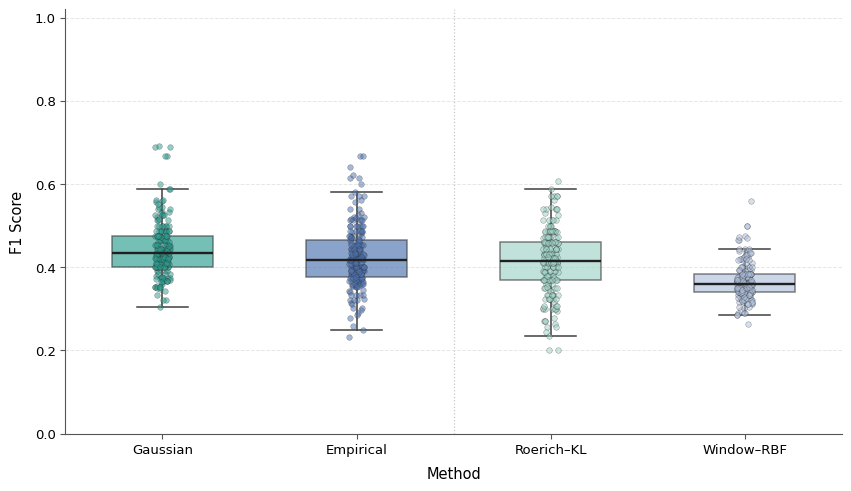

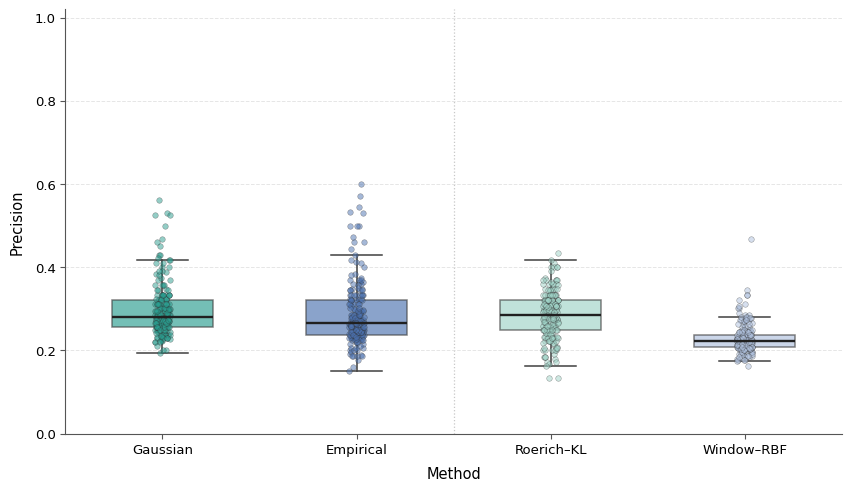

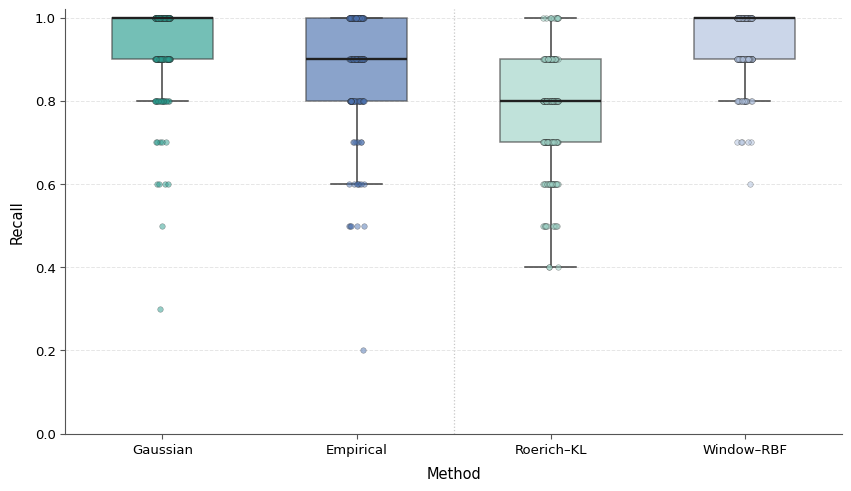

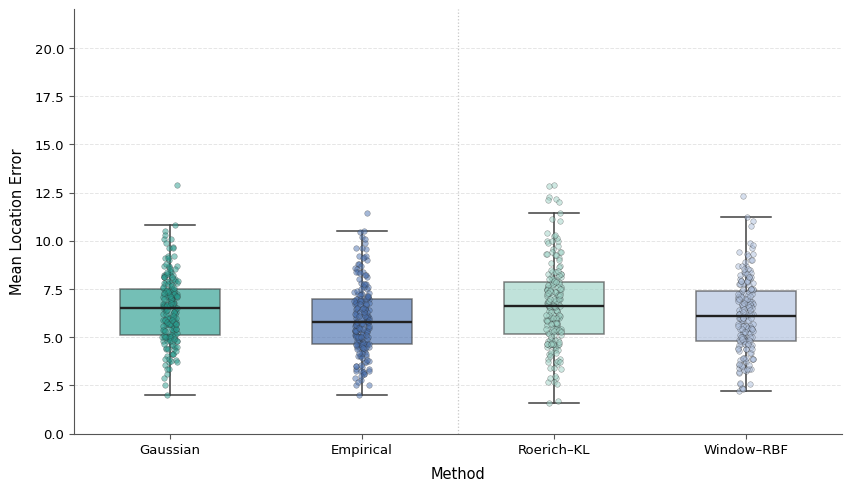

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.297659,0.9270,0.445075,6.467173
1,Empirical,0.286203,0.8935,0.424406,5.925244
2,Roerich-KL,0.285099,0.7625,0.414427,6.657536
3,Window-RBF,0.228630,0.9395,0.365941,6.101284


WINDOW SIZE: 50


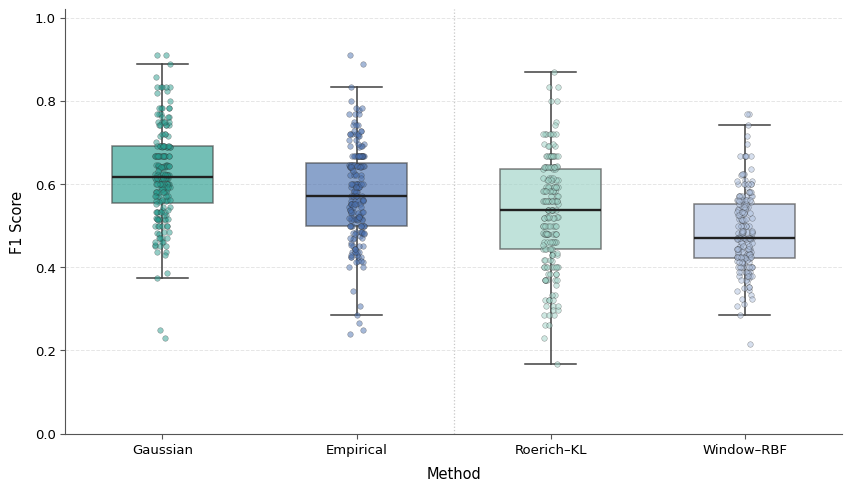

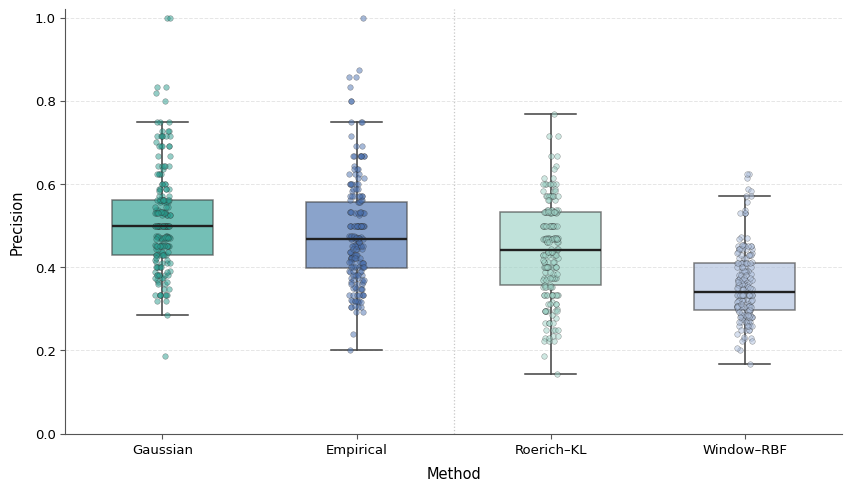

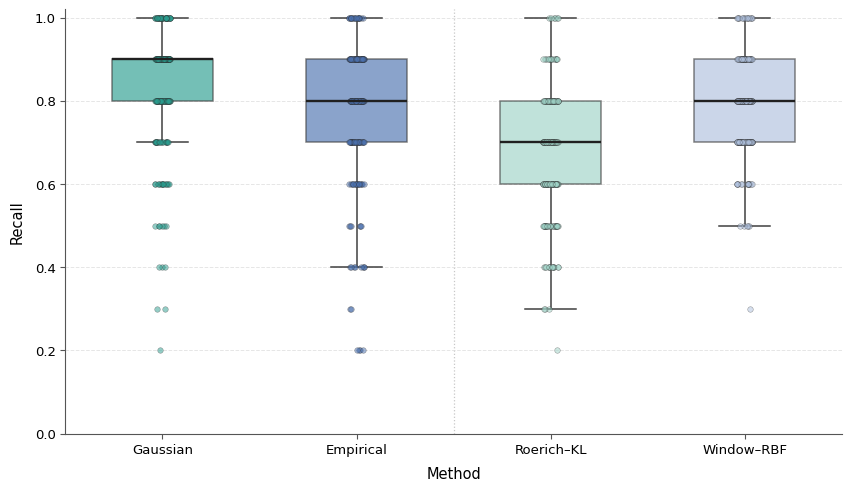

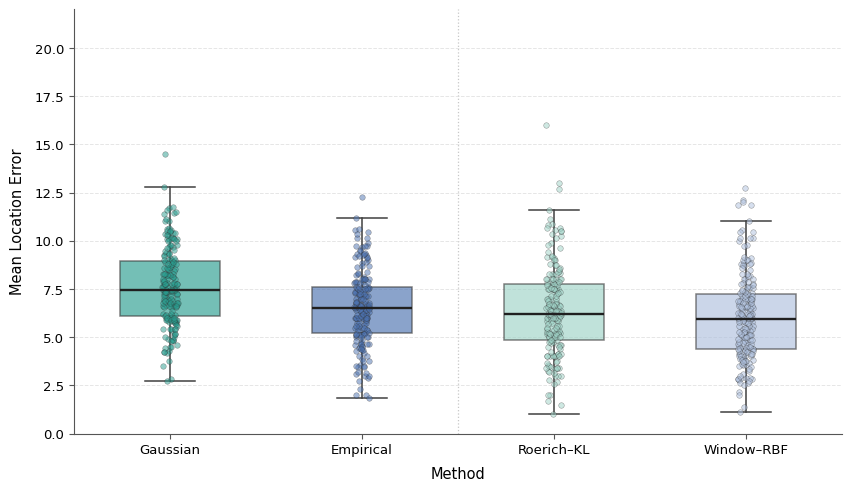

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.513904,0.8255,0.621198,7.614544
1,Empirical,0.482782,0.7700,0.575484,6.515788
2,Roerich-KL,0.440106,0.6685,0.529408,6.374756
3,Window-RBF,0.356367,0.7865,0.486858,6.025946


WINDOW SIZE: 80


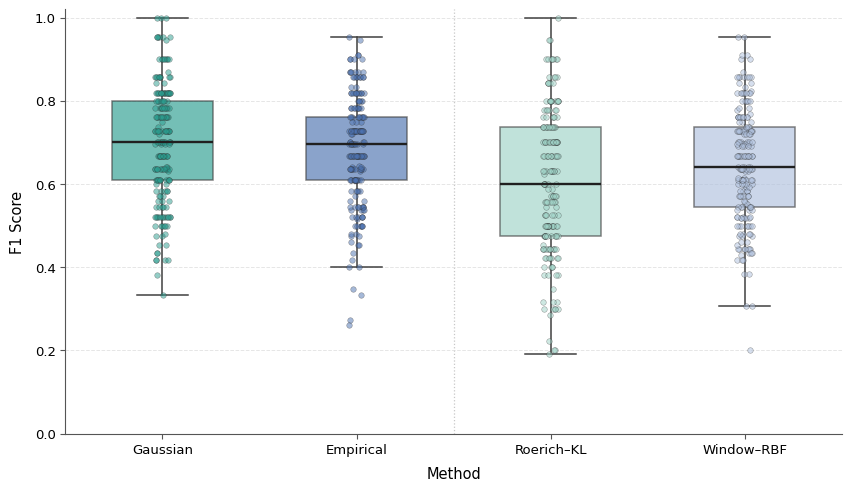

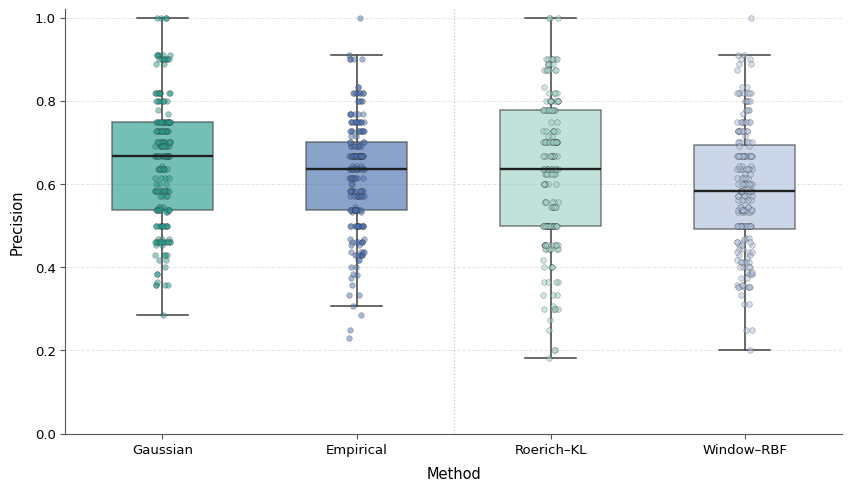

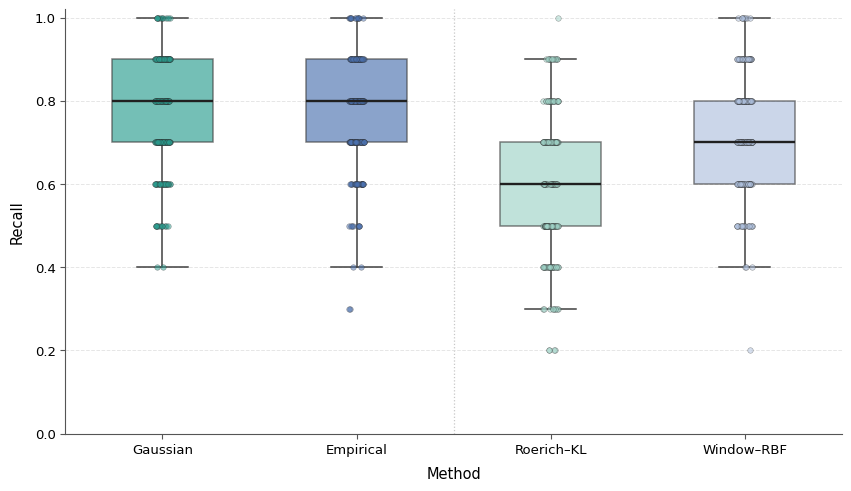

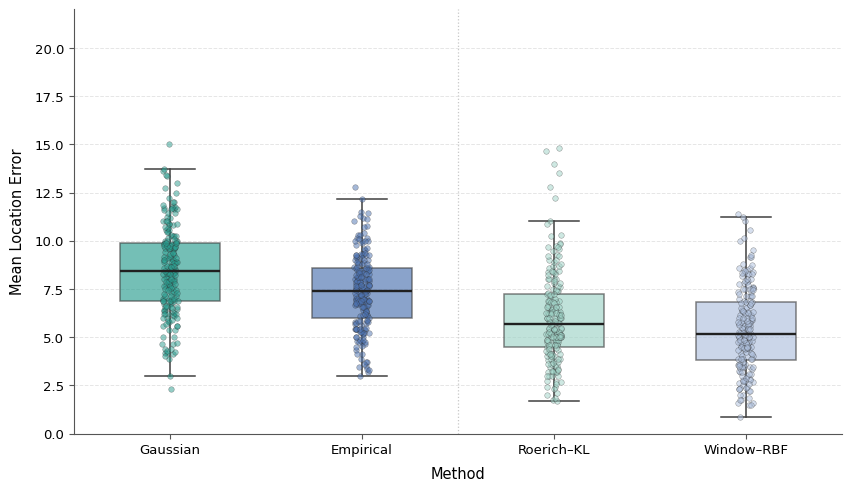

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.650615,0.7595,0.698393,8.427278
1,Empirical,0.616209,0.7595,0.677956,7.350155
2,Roerich-KL,0.618882,0.5970,0.605800,6.005181
3,Window-RBF,0.586421,0.7270,0.643649,5.379992


WINDOW SIZE: 100


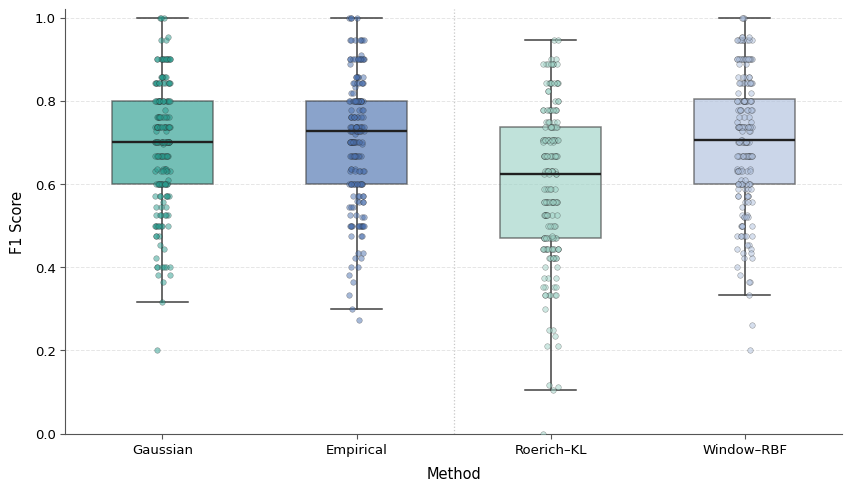

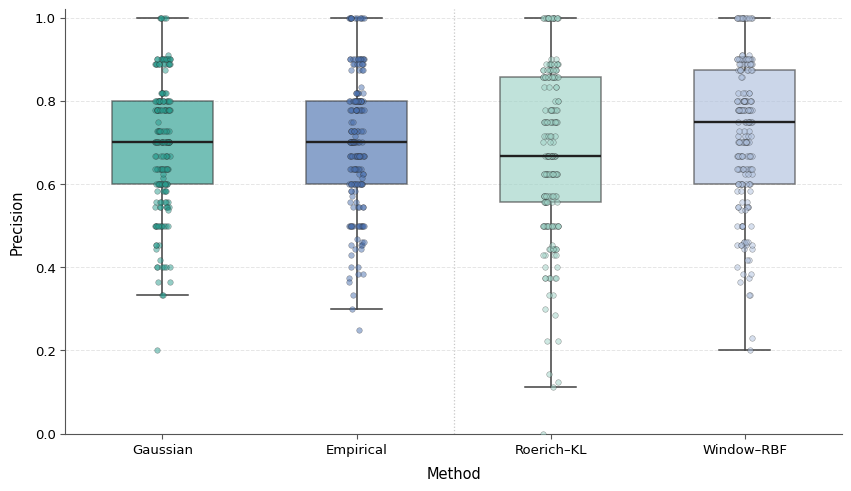

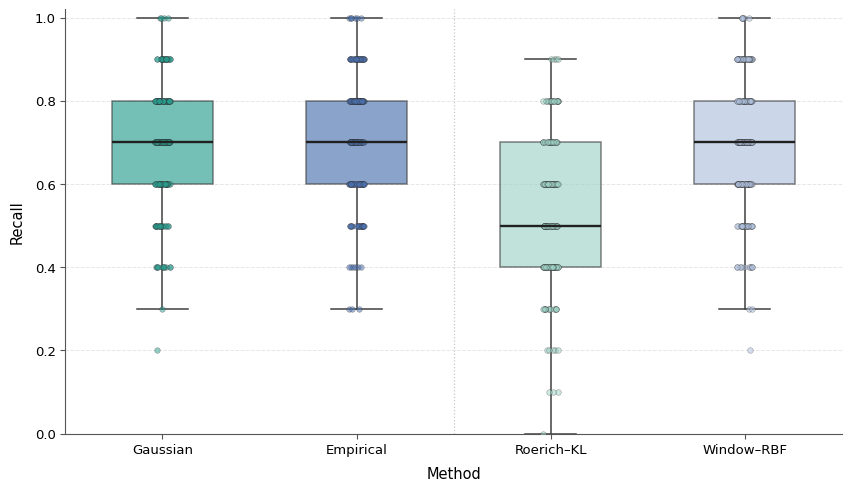

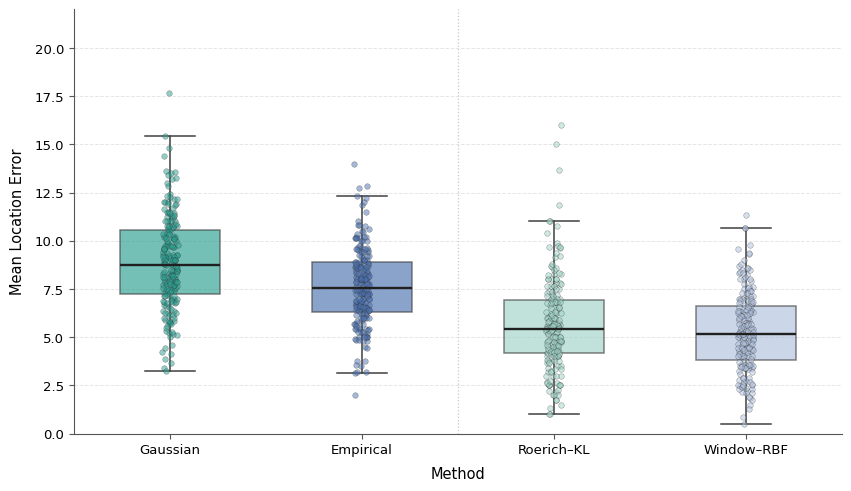

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.693070,0.6955,0.692905,8.853409
1,Empirical,0.698764,0.7125,0.703157,7.609617
2,Roerich-KL,0.678638,0.5390,0.597964,5.642739
3,Window-RBF,0.720758,0.6945,0.703738,5.271401


In [48]:
for w in [30, 50, 80, 100]:
    print("=" * 60)
    print(f"WINDOW SIZE: {w}")
    print("=" * 60)
    ruta_ar2_rf = f"Resultados_Series_Simuladas/AR(2)_Altering_auto-correlation/Tables/ar2_rf_metrics_window_{w}.xlsx"

    hojas = pd.read_excel(ruta_ar2_rf, sheet_name=None)

    listas = [df.to_dict(orient="records") for df in hojas.values()]

    lista_gauss, lista_emp, lista_roerich, lista_window_rbf = listas

    nombres_boxplot = [
                        "Gaussian",
                        "Empirical",
                        "Roerich–KL",
                        "Window–RBF"
                    ]

    metrics_names = ['F1 Score', 'Precision', 'Recall', 'Mean Location Error']
    for n in metrics_names:
        ylim = (0, 1.02)
        name = n
        if n == 'Mean Location Error':
            ylim = (0, 22)
            name = "MLE"
        path_fig = f"Resultados_Series_Simuladas/AR(2)_Altering_auto-correlation/Graphics/Window {w}/{name}_AR2_rf_w{w}.png"
        fig, ax = plot_boxplots(
                                datos=[
                                    [m[n] for m in lista_gauss],
                                    [m[n] for m in lista_emp],
                                    [m[n] for m in lista_roerich],
                                    [m[n] for m in lista_window_rbf]
                                ],
                                nombres=nombres_boxplot,
                                ylabel=n,
                                xlabel="Method",
                                ylim=ylim,
                                save_path = path_fig
                            )
    ruta_avg_ar2_rf = f"Resultados_Series_Simuladas/AR(2)_Altering_auto-correlation/Tables/ar2_rf_metrics_avg_window_{w}.xlsx"
    average_table = generar_tabla_desde_diccionarios(
                                                            [lista_gauss, lista_emp, lista_roerich, lista_window_rbf],
                                                            ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                            ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                            )
    display(average_table)
    average_table.to_excel(ruta_avg_ar2_rf, index=False)

# 7. Datos Reales

## Funciones Auxiliares

In [61]:
import math
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def plot_change_points_by_method(
    serie,
    reference_change_points,
    detected_change_points,
    method_names,
    title="Change-point detection comparison",
    ncols=2,
    figsize=None,
    index_base=0,
    ylabel="Value",
    xlabel="Temporal index",
    series_color="#455A64",
    reference_color="#202020",
    method_colors=None,
    series_linewidth=0.8,
    series_alpha=0.9,
    reference_linewidth=1.2,
    detected_linewidth=1.3,
    show_count=True,
    save_path=None,
    dpi=300,
    show=True
):
    """
    Grafica una serie temporal, sus puntos de cambio de referencia
    y las detecciones obtenidas por varios métodos.

    Parameters
    ----------
    serie : array-like
        Serie temporal univariada.

    reference_change_points : array-like
        Puntos de cambio de referencia.

    detected_change_points : list of array-like
        Lista en la que cada elemento contiene los puntos detectados
        por un método.

    method_names : list of str
        Nombres asociados a los métodos, en el mismo orden que
        detected_change_points.

    title : str
        Título general de la figura.

    ncols : int
        Número de columnas para los paneles de los métodos.

    figsize : tuple or None
        Tamaño global de la figura. Si es None, se determina
        automáticamente.

    index_base : {0, 1}
        Indica si los índices de los puntos de cambio comienzan
        en cero o en uno.

    save_path : str or None
        Ruta para guardar la figura. Si es None, no se guarda.

    Returns
    -------
    fig : matplotlib.figure.Figure
        Figura creada.

    axes : dict
        Diccionario con el eje de referencia y los ejes de los métodos.
    """

    # ---------------------------------------------------------
    # Validación de la serie
    # ---------------------------------------------------------
    serie = np.asarray(
        serie,
        dtype=np.float64
    ).ravel()

    if serie.size == 0:
        raise ValueError("La serie de tiempo está vacía.")

    if index_base not in (0, 1):
        raise ValueError("index_base debe ser 0 o 1.")

    if len(detected_change_points) != len(method_names):
        raise ValueError(
            "La cantidad de conjuntos de puntos detectados debe "
            "coincidir con la cantidad de nombres de métodos."
        )

    if len(method_names) == 0:
        raise ValueError(
            "Debe proporcionarse al menos un método."
        )

    ncols = int(ncols)

    if ncols < 1:
        raise ValueError("ncols debe ser mayor o igual que uno.")

    n = serie.size
    temporal_index = np.arange(
        index_base,
        index_base + n
    )

    # ---------------------------------------------------------
    # Limpieza de los puntos de cambio
    # ---------------------------------------------------------
    def clean_change_points(points, name):

        if points is None:
            return np.array([], dtype=int)

        points = np.asarray(points).ravel()

        if points.size == 0:
            return np.array([], dtype=int)

        try:
            points = points.astype(np.float64)
        except (TypeError, ValueError) as error:
            raise ValueError(
                f"Los puntos de cambio de '{name}' "
                "deben ser numéricos."
            ) from error

        finite_mask = np.isfinite(points)

        if not np.all(finite_mask):
            warnings.warn(
                f"Se eliminaron valores no finitos de '{name}'."
            )
            points = points[finite_mask]

        if not np.allclose(points, np.rint(points)):
            raise ValueError(
                f"Los puntos de cambio de '{name}' "
                "deben ser índices enteros."
            )

        points = np.unique(
            np.rint(points).astype(int)
        )

        lower_bound = index_base
        upper_bound = index_base + n - 1

        valid_mask = (
            (points >= lower_bound)
            & (points <= upper_bound)
        )

        if not np.all(valid_mask):
            warnings.warn(
                f"Se omitieron puntos de cambio de '{name}' "
                "que estaban fuera del intervalo de la serie."
            )

        return points[valid_mask]

    reference_change_points = clean_change_points(
        reference_change_points,
        "Reference"
    )

    cleaned_detections = [
        clean_change_points(points, name)
        for points, name in zip(
            detected_change_points,
            method_names
        )
    ]

    # ---------------------------------------------------------
    # Colores aptos para publicación y distinguibles
    # ---------------------------------------------------------
    if method_colors is None:
        method_colors = [
            "#0072B2",  # azul
            "#D55E00",  # naranja oscuro
            "#009E73",  # verde
            "#CC79A7",  # púrpura
            "#E69F00",  # amarillo oscuro
            "#56B4E9",  # azul claro
            "#7A5195",
            "#5F6B6D"
        ]

    if len(method_colors) < len(method_names):
        repetitions = math.ceil(
            len(method_names) / len(method_colors)
        )
        method_colors = (
            method_colors * repetitions
        )

    # ---------------------------------------------------------
    # Distribución de los paneles
    # ---------------------------------------------------------
    number_methods = len(method_names)
    method_rows = math.ceil(number_methods / ncols)
    total_rows = method_rows + 1

    if figsize is None:
        figsize = (
            6.2 * ncols,
            2.5 + 2.7 * method_rows
        )

    fig = plt.figure(
        figsize=figsize,
        constrained_layout=True
    )

    grid = fig.add_gridspec(
        total_rows,
        ncols,
        height_ratios=[1.05] + [1.0] * method_rows
    )

    reference_ax = fig.add_subplot(
        grid[0, :]
    )

    # ---------------------------------------------------------
    # Funciones auxiliares
    # ---------------------------------------------------------
    def plot_series(ax):
        ax.plot(
            temporal_index,
            serie,
            color=series_color,
            linewidth=series_linewidth,
            alpha=series_alpha,
            rasterized=True,
            zorder=1
        )

        # Elimina completamente las líneas verticales de la cuadrícula.
        ax.grid(
            False,
            axis="x",
            which="both"
        )

        # Conserva solamente la cuadrícula horizontal.
        ax.grid(
            True,
            axis="y",
            which="major",
            linestyle="--",
            linewidth=0.7,
            alpha=0.25
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.margins(x=0)

    def add_vertical_lines(
        ax,
        points,
        color,
        linestyle,
        linewidth
    ):
        for point in points:
            ax.axvline(
                point,
                color=color,
                linestyle=linestyle,
                linewidth=linewidth,
                alpha=0.9,
                zorder=2
            )

    # ---------------------------------------------------------
    # Panel superior: referencias
    # ---------------------------------------------------------
    plot_series(reference_ax)

    add_vertical_lines(
        reference_ax,
        reference_change_points,
        reference_color,
        ":",
        reference_linewidth
    )

    reference_ax.set_title(
        "Original series and reference change points",
        fontsize=11,
        fontweight="semibold"
    )

    reference_ax.legend(
        handles=[
            Line2D(
                [0],
                [0],
                color=reference_color,
                linestyle=":",
                linewidth=reference_linewidth,
                label="Reference change points"
            )
        ],
        loc="upper right",
        fontsize=8,
        frameon=True
    )

    reference_ax.tick_params(
        axis="x",
        labelbottom=False
    )

    # ---------------------------------------------------------
    # Paneles de los métodos
    # ---------------------------------------------------------
    method_axes = []

    for method_index, (
        name,
        points,
        color
    ) in enumerate(
        zip(
            method_names,
            cleaned_detections,
            method_colors
        )
    ):
        row = 1 + method_index // ncols
        column = method_index % ncols

        ax = fig.add_subplot(
            grid[row, column],
            sharex=reference_ax,
            sharey=reference_ax
        )

        method_axes.append(ax)
        plot_series(ax)

        add_vertical_lines(
            ax,
            reference_change_points,
            reference_color,
            ":",
            reference_linewidth
        )

        add_vertical_lines(
            ax,
            points,
            color,
            "--",
            detected_linewidth
        )

        if show_count:
            panel_title = (
                f"{name} (detected: {len(points)})"
            )
        else:
            panel_title = str(name)

        ax.set_title(
            panel_title,
            fontsize=10.5,
            fontweight="semibold"
        )

        ax.legend(
            handles=[
                Line2D(
                    [0],
                    [0],
                    color=reference_color,
                    linestyle=":",
                    linewidth=reference_linewidth,
                    label="Reference"
                ),
                Line2D(
                    [0],
                    [0],
                    color=color,
                    linestyle="--",
                    linewidth=detected_linewidth,
                    label="Detected"
                )
            ],
            loc="upper right",
            fontsize=7.5,
            frameon=True
        )

        # Solo se muestran etiquetas del eje horizontal
        # en la última fila.
        if row < total_rows - 1:
            ax.tick_params(
                axis="x",
                labelbottom=False
            )

    fig.suptitle(
        title,
        fontsize=14,
        fontweight="semibold"
    )

    fig.supxlabel(
        xlabel,
        fontsize=11
    )

    fig.supylabel(
        ylabel,
        fontsize=11
    )

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight",
            facecolor="white"
        )

    if show:
        plt.show()

    return fig, {
        "reference": reference_ax,
        "methods": method_axes
    }

## 7.1. BabyECG

### 7.1.1. Carga y Visualización

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

baby_data = pd.read_csv("Real Data/BabyECG.csv")

serie_baby_ecg = baby_data["Heart_rate"].to_numpy(
    dtype=float
)

sleep_state = baby_data["Sleep_state"].to_numpy(
    dtype=int
)

print(baby_data.head())
print("Longitud:", len(serie_baby_ecg))

   Index  Time_seconds  Heart_rate  Sleep_state
0      1             0         129            2
1      2            16         130            2
2      3            32         123            2
3      4            48         126            2
4      5            64         125            2
Longitud: 2048


In [24]:
change_points_sleep = (
    np.flatnonzero(
        np.diff(sleep_state) != 0
    )
    + 1
)

print(change_points_sleep)
print(
    "Número de transiciones:",
    len(change_points_sleep)
)

[  10   34  295  415  439  475  488  510  520  649  774  902  969 1136
 1149 1250 1271 1412 1429 1458 1567 1676 1765 1788 1797 1839 1845 1929
 1942]
Número de transiciones: 29


In [25]:
import numpy as np

inicio = 100
numero_cps_eliminados = 2

serie_baby_ecg_model = serie_baby_ecg[inicio:].copy()
sleep_state_model = sleep_state[inicio:].copy()

change_points_model = (
    np.asarray(
        change_points_sleep,
        dtype=int
    )[numero_cps_eliminados:]
    - inicio
)

change_points_model = change_points_model[
    (change_points_model > 0)
    & (
        change_points_model
        < len(serie_baby_ecg_model)
    )
]


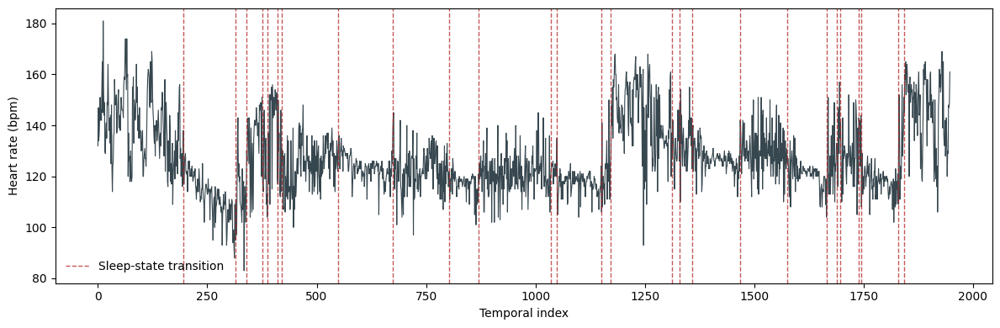

In [26]:
fig, ax = plt.subplots(
    figsize=(12, 4)
)

ax.plot(
    serie_baby_ecg_model,
    color="#37474F",
    linewidth=0.8
)

for i, cp in enumerate(change_points_model):
    ax.axvline(
        cp,
        color="#B22222",
        linestyle="--",
        linewidth=1,
        alpha=0.75,
        label=(
            "Sleep-state transition"
            if i == 0
            else None
        )
    )

ax.set_xlabel("Temporal index")
ax.set_ylabel("Heart rate (bpm)")
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

### 7.1.2. Resultados


════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 1948
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 28.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 28.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.3381 s
    Best Window                 : 58

Dispersion of Cost
──────────────────
    Execution Time              : 14.3381 s
    Best Window                 : 58

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 58

Selección final
──────

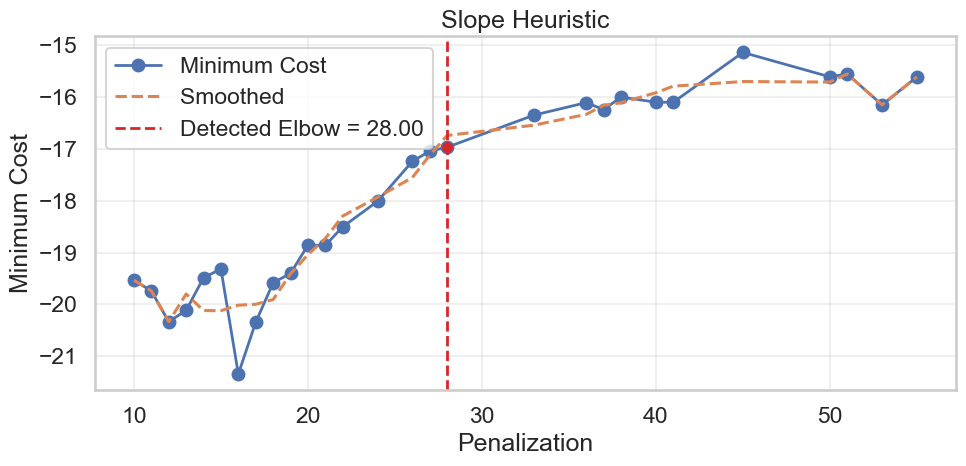

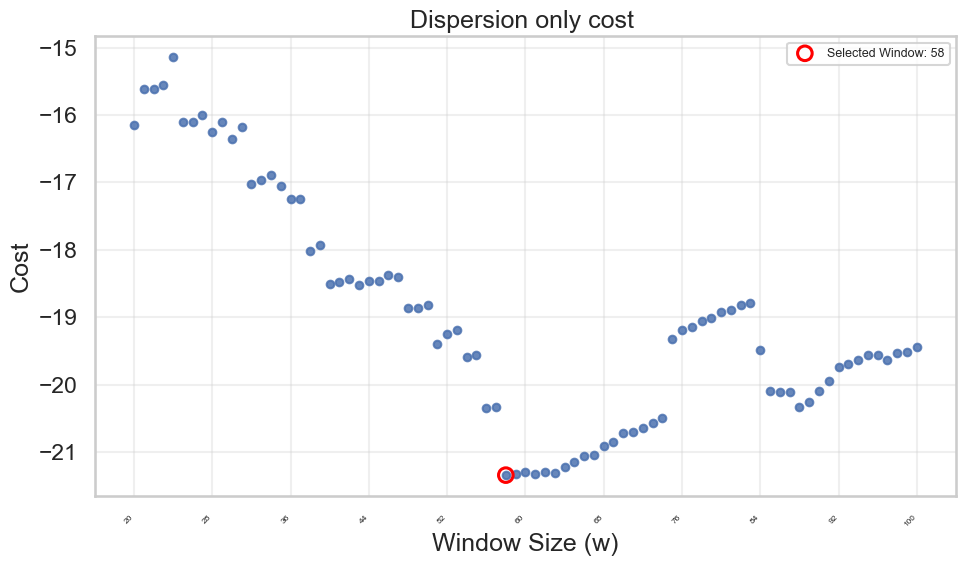

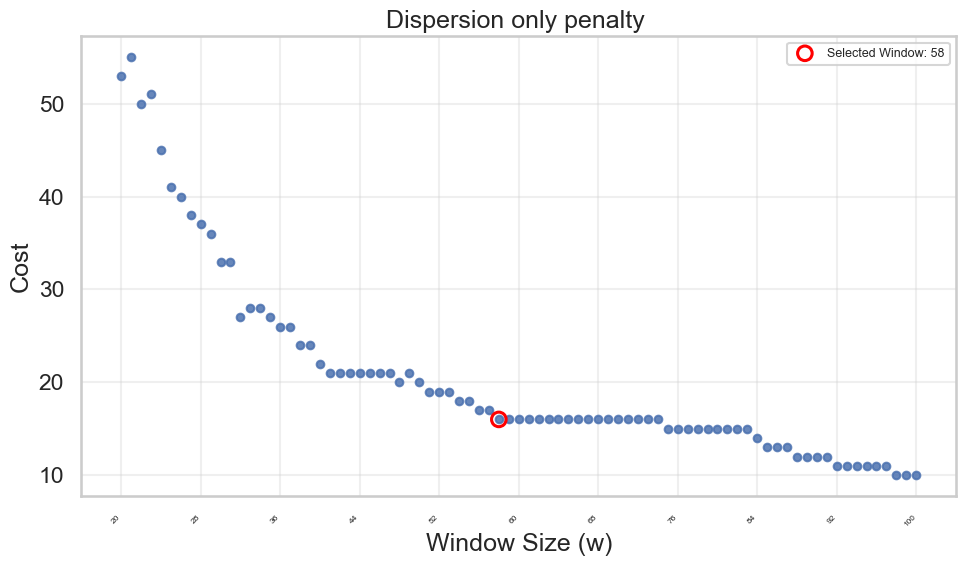

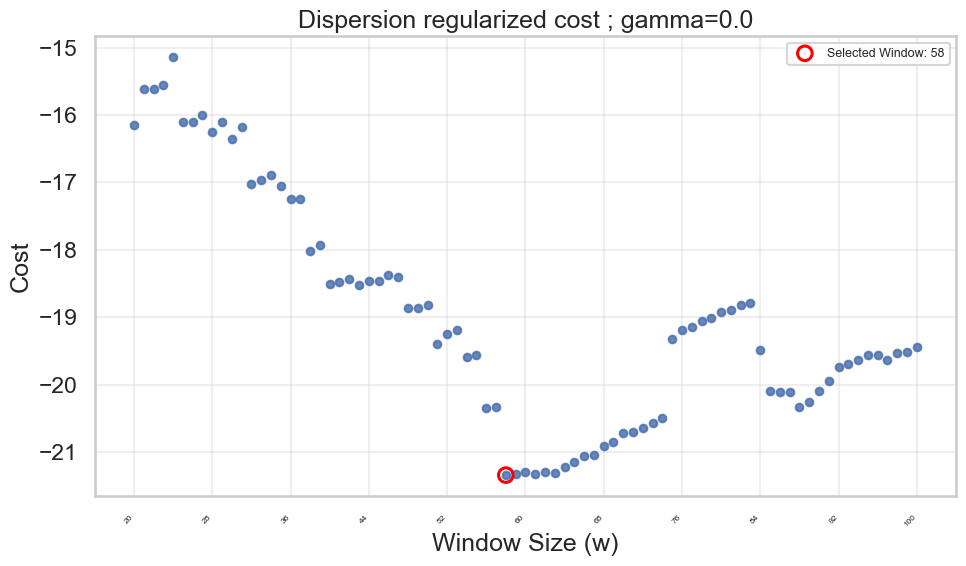

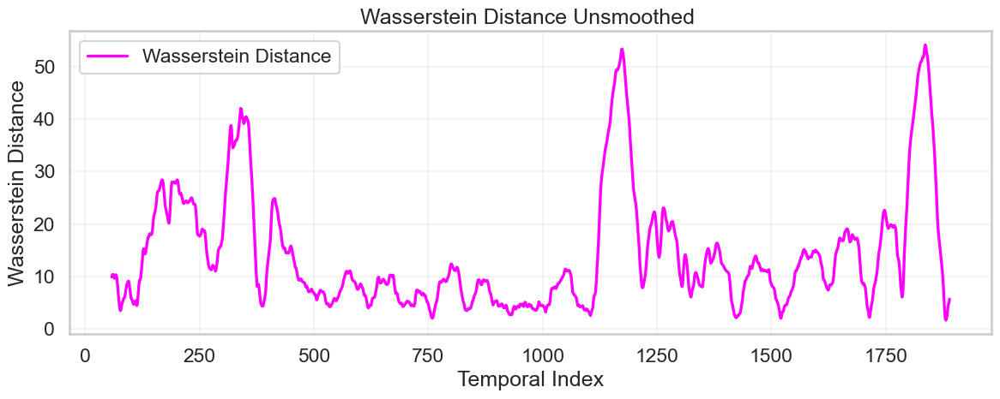

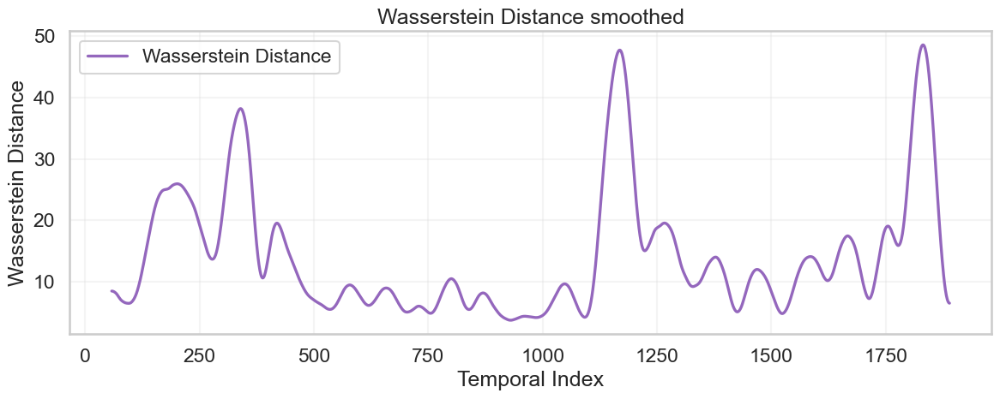

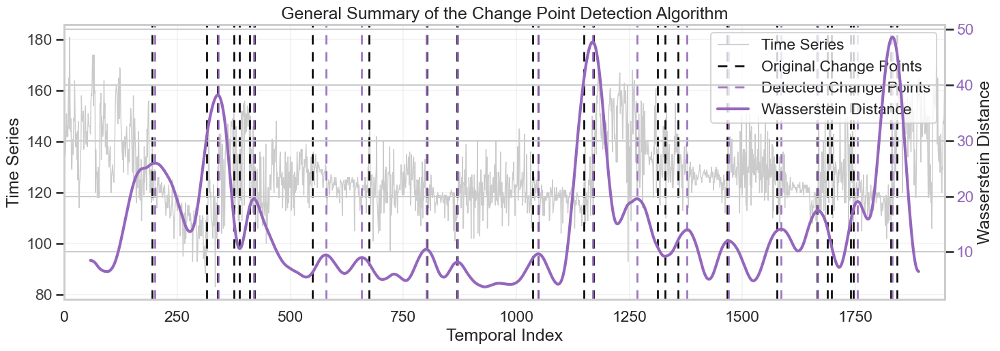

In [27]:
metrics_babyecg_gauss_opt = best_params_sh(
                                                                serie_baby_ecg_model,
                                                                change_points_model,
                                                                penal=True,
                                                                path='',
                                                                name=f"BabyECG",
                                                                modo="Gaussiano",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 20,
                                                                max_w = 100,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                save_fig=False,
                                                                visualization={
                                                                    "summary": True,
                                                                    "raw_distance": True,
                                                                    "smooth_distance": True,
                                                                    "cost": True,
                                                                    "slope": True,
                                                                },
                                                                temporal_comp=True)[0]


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 1948
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 25.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 25.0000

Dispersion of Cost
──────────────────
    Execution Time              : 13.6033 s
    Best Window                 : 59

Dispersion of Cost
──────────────────
    Execution Time              : 13.6033 s
    Best Window                 : 59

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 59

Selección final
──────

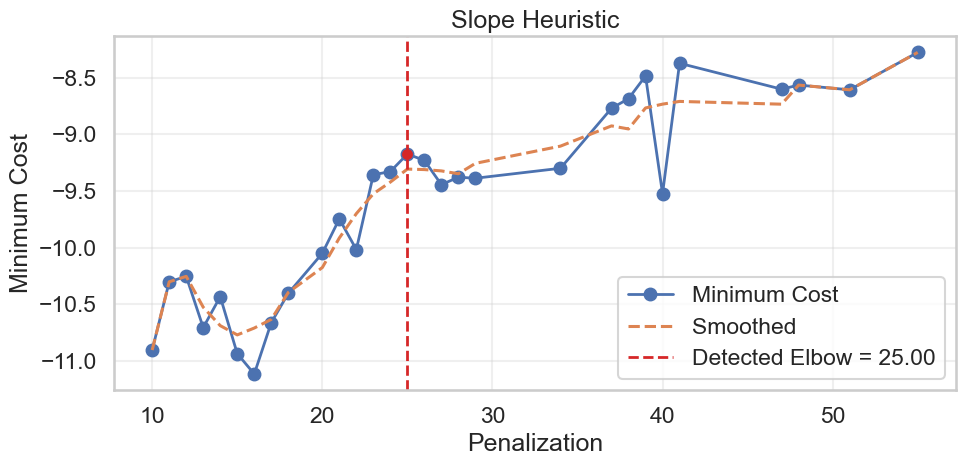

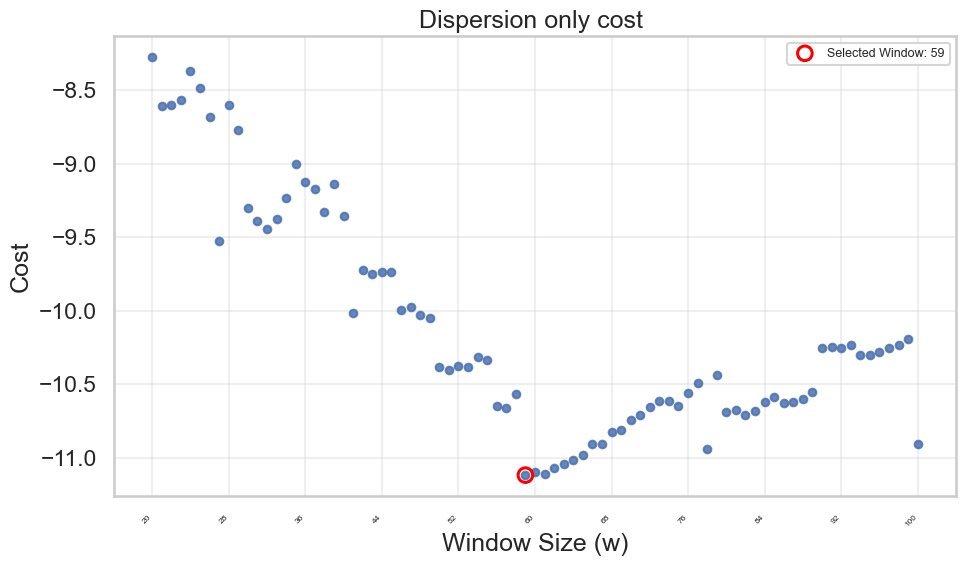

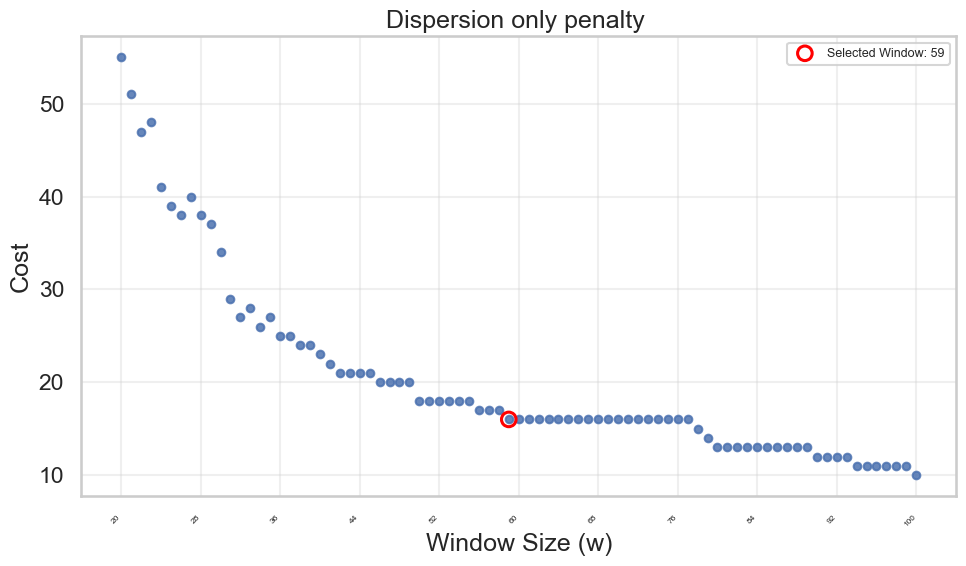

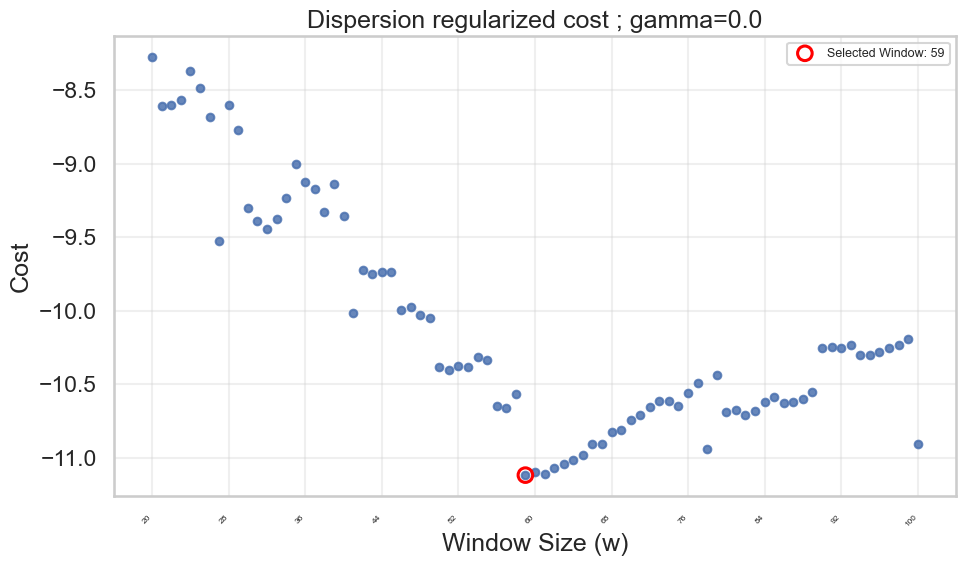

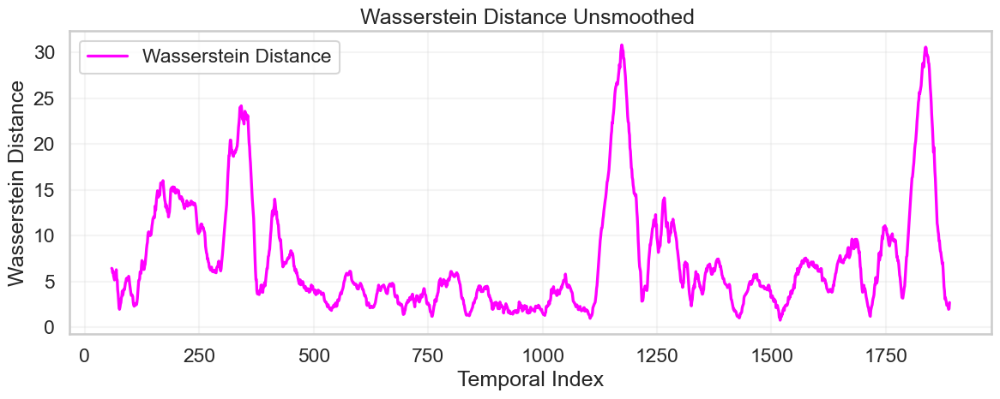

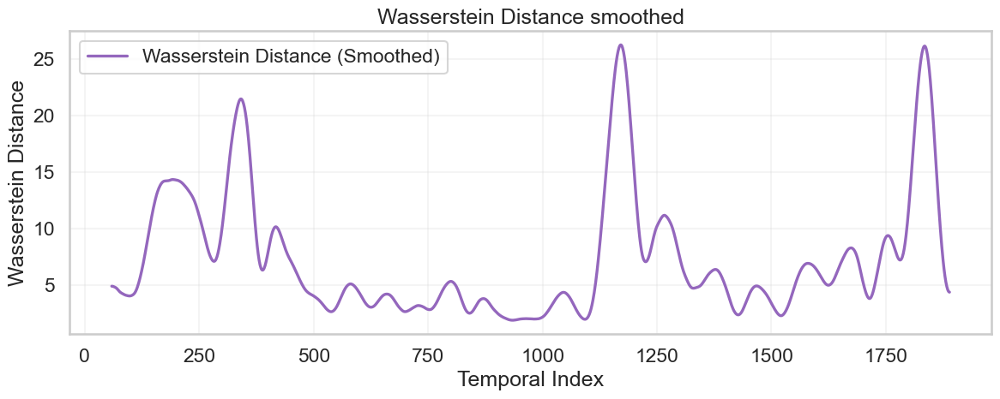

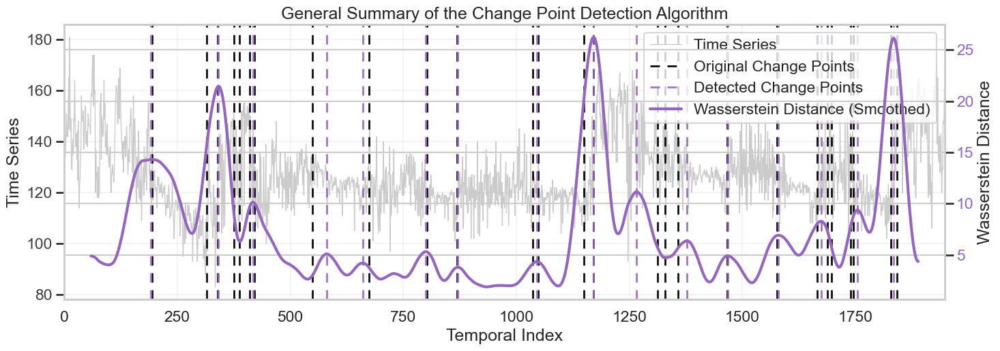

In [28]:
metrics_babyecg_emp_opt = best_params_sh(
                                                                serie_baby_ecg_model,
                                                                change_points_model,
                                                                penal=True,
                                                                path='',
                                                                name=f"BabyECG",
                                                                modo="Empírico",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 20,
                                                                max_w = 100,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                save_fig=False,
                                                                visualization={
                                                                    "summary": True,
                                                                    "raw_distance": True,
                                                                    "smooth_distance": True,
                                                                    "cost": True,
                                                                    "slope": True,
                                                                },
                                                                temporal_comp=True)[0]

In [29]:
puntos_cambio_roerich_babyecg = detectar_cambios_roerich(
                                serie_baby_ecg_model,
                                window_size=50,
                                seed=42,
                                periods=10
                            )

metrics_babyecg_roerich = metrics(change_points_model, puntos_cambio_roerich_babyecg, 20, len(serie_baby_ecg_model))[0]

In [30]:
puntos_cambio_window_rbf_babyecg = detectar_window_rbf(
                                serie_baby_ecg_model,
                                window=50
                            )

metrics_babyecg_window_rbf = metrics(change_points_model, puntos_cambio_window_rbf_babyecg, 20, len(serie_baby_ecg_model))[0]

In [36]:
w=50
cpd_gauss_babyecg_fw = CPD(serie_baby_ecg_model, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
distancias_gauss_babyecg_fw = cpd_gauss_babyecg_fw.distancias()
cps_detect_gauss_babyecg_fw = detect(distancias_gauss_babyecg_fw, w)
metrics_babyecg_gauss_fw = metrics(change_points_model, cps_detect_gauss_babyecg_fw, 20, len(serie_baby_ecg_model))[0]

w_gauss_opt = 58
cpd_gauss_babyecg_opt = CPD(serie_baby_ecg_model, window=w_gauss_opt, t=1, medias=True, smooth=True, temporal_comp=True)
distancias_babyecg_opt = cpd_gauss_babyecg_opt.distancias()
cps_detect_gauss_babyecg_opt = detect(distancias_babyecg_opt, w_gauss_opt)


In [37]:
cpd_emp_babyecg = EmpiricalCPD(serie_baby_ecg_model, window=w, smooth=True)
distancias_babyecg_emp = cpd_emp_babyecg.distancias()
cps_detect_emp_babyecg_fw = detect(distancias_babyecg_emp, w)
metrics_babyecg_emp_fw = metrics(change_points_model, cps_detect_emp_babyecg_fw, 20, len(serie_baby_ecg_model))[0]

w_emp_opt = 59
cpd_emp_babyecg_opt = EmpiricalCPD(serie_baby_ecg_model, window=w_emp_opt, smooth=True)
distancias_babyecg_emp_opt = cpd_emp_babyecg_opt.distancias()
cps_detect_emp_babyecg_opt = detect(distancias_babyecg_emp_opt, w_emp_opt)

In [35]:
generar_tabla_desde_diccionarios(
    [[metrics_babyecg_gauss_opt], [metrics_babyecg_emp_opt], 
     [metrics_babyecg_gauss_fw], [metrics_babyecg_emp_fw], 
     [metrics_babyecg_roerich], [metrics_babyecg_window_rbf]],
    ["Gauss-Opt", "Empirical-Opt", 
     "Gauss-FW", "Empirical-FW", 
     "Roerich-KL", "Window-RBF"],
    ["Precision", "Recall", "F1 Score", "Mean Location Error"]
)

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss-Opt,0.875000,0.518519,0.651163,5.428571
1,Empirical-Opt,0.875000,0.518519,0.651163,5.500000
2,Gauss-FW,0.700000,0.518519,0.595745,6.357143
3,Empirical-FW,0.777778,0.518519,0.622222,7.214286
4,Roerich-KL,0.666667,0.370370,0.476190,6.200000
5,Window-RBF,0.454545,0.370370,0.408163,2.400000


In [40]:
cpd_gauss_babyecg_opt

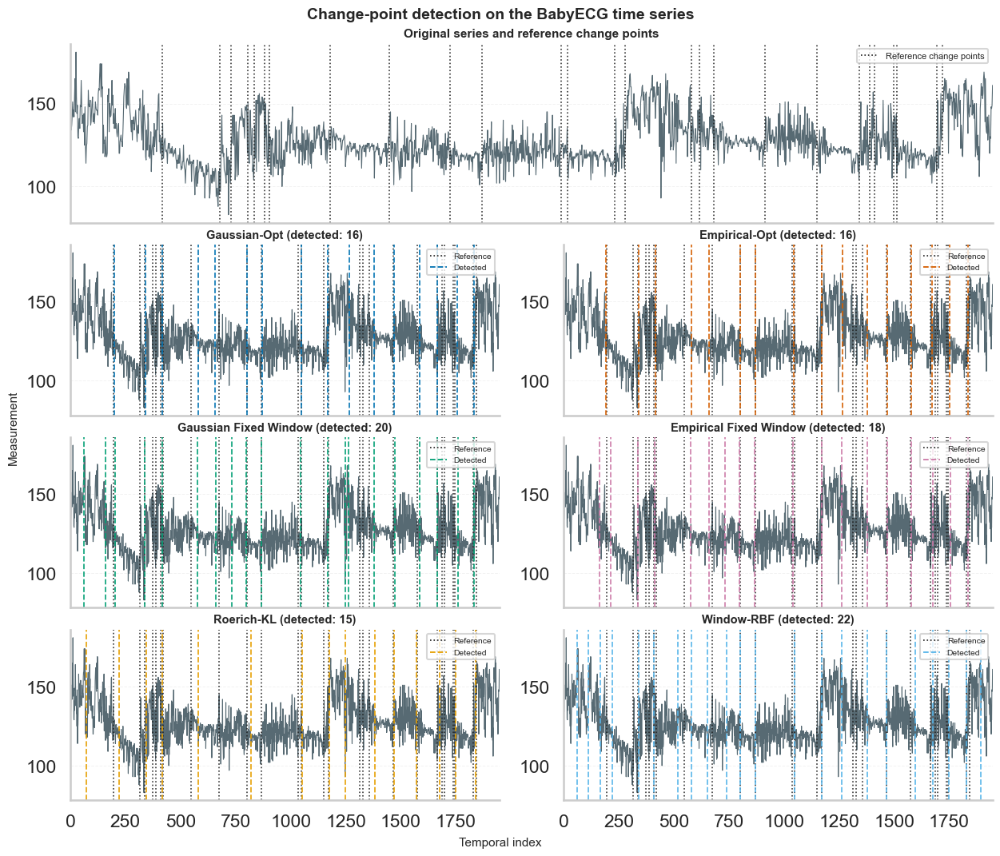

In [44]:
detected_cps = [
    cps_detect_gauss_babyecg_opt,
    cps_detect_emp_babyecg_opt,
    cps_detect_gauss_babyecg_fw,
    cps_detect_emp_babyecg_fw,
    puntos_cambio_roerich_babyecg,
    puntos_cambio_window_rbf_babyecg
]

method_names = [
    "Gaussian-Opt",
    "Empirical-Opt",
    "Gaussian Fixed Window",
    "Empirical Fixed Window",
    "Roerich-KL",
    "Window-RBF"
]

fig, axes = plot_change_points_by_method(
    serie=serie_baby_ecg_model,
    reference_change_points=change_points_model,
    detected_change_points=detected_cps,
    method_names=method_names,
    title="Change-point detection on the BabyECG time series",
    ylabel="Measurement",
    index_base=0
)

## 7.2. Well-Log

### 7.2.1. Carga y Visualización

In [49]:
import json
import numpy as np
from pathlib import Path


carpeta = Path("Real Data/Well_log")

# Serie original de 4050 observaciones
serie_well_log = np.loadtxt(
    carpeta / "well_log_original.txt",
    dtype=np.float64
)

# Versión reducida de TCPD
with open(
    carpeta / "well_log_tcpd.json",
    "r",
    encoding="utf-8"
) as archivo:

    datos_tcpd = json.load(archivo)

serie_well_log_tcpd = np.asarray(
    datos_tcpd["series"][0]["raw"],
    dtype=np.float64
)

print("Longitud original:", len(serie_well_log))
print("Longitud TCPD:", len(serie_well_log_tcpd))

Longitud original: 4050
Longitud TCPD: 675


In [50]:
with open(
    carpeta / "annotations.json",
    "r",
    encoding="utf-8"
) as archivo:

    todas_las_anotaciones = json.load(archivo)

anotaciones_well_log = todas_las_anotaciones[
    "well_log"
]

for anotador, puntos in anotaciones_well_log.items():
    print(
        f"Anotador {anotador}: "
        f"{len(puntos)} puntos -> {puntos}"
    )

Anotador 6: 11 puntos -> [179, 255, 281, 311, 343, 402, 413, 422, 432, 462, 464]
Anotador 7: 9 puntos -> [179, 255, 281, 312, 343, 402, 412, 422, 432]
Anotador 8: 9 puntos -> [179, 255, 282, 312, 343, 402, 413, 422, 432]
Anotador 12: 2 puntos -> [177, 467]
Anotador 13: 17 puntos -> [4, 179, 255, 281, 311, 344, 402, 412, 422, 432, 462, 464, 521, 526, 620, 643, 661]


In [51]:
cps_well_log = np.array(anotaciones_well_log['13'][1:])

In [52]:
factor_submuestreo = 6

change_points_well_log = (
    factor_submuestreo
    * cps_well_log
).astype(int)

print(change_points_well_log.tolist())

[1074, 1530, 1686, 1866, 2064, 2412, 2472, 2532, 2592, 2772, 2784, 3126, 3156, 3720, 3858, 3966]


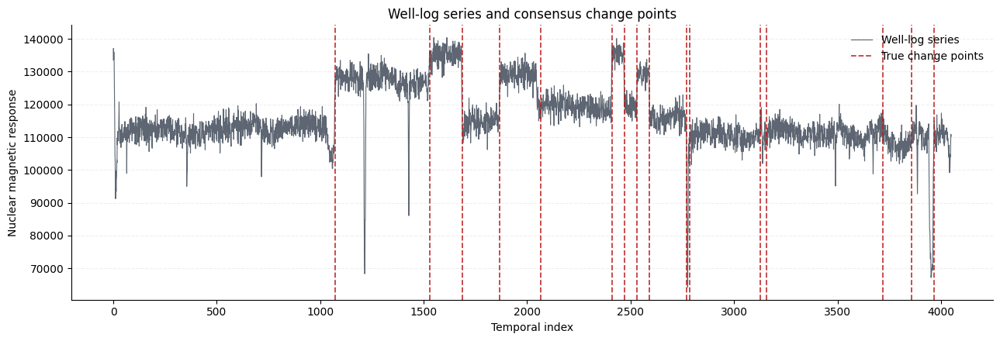

In [53]:
import matplotlib.pyplot as plt

def graficar_well_log(serie, true_cps, detect_cps=None):
    fig, ax = plt.subplots(
        figsize=(13, 4.5)
    )

    ax.plot(
        serie,
        color="#4B5563",
        linewidth=0.8,
        alpha=0.9,
        label="Well-log series"
    )

    for i, cp in enumerate(true_cps):
        ax.axvline(
            cp,
            color="#B91C1C",
            linestyle="--",
            linewidth=1.3,
            alpha=0.85,
            label=(
                "True change points"
                if i == 0
                else None
            )
        )

    if detect_cps != None:
        for i, cp in enumerate(detect_cps):
            ax.axvline(
                cp,
                color="blue",
                linestyle="--",
                linewidth=1.3,
                alpha=0.85,
                label=(
                    "Detected change points"
                    if i == 0
                    else None
                )
            )

    ax.set_xlabel("Temporal index")
    ax.set_ylabel("Nuclear magnetic response")
    ax.set_title(
        "Well-log series and consensus change points"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        frameon=False,
        loc="upper right"
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.2
    )

    plt.tight_layout()
    plt.show()

graficar_well_log(serie_well_log, change_points_well_log)

### 7.2.2. Resultados

#### Resultados por Método


════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 4050
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 18.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 18.0000

Dispersion of Cost
──────────────────
    Execution Time              : 37.4186 s
    Best Window                 : 189

Dispersion of Cost
──────────────────
    Execution Time              : 37.4186 s
    Best Window                 : 189

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 189

Selección final
───

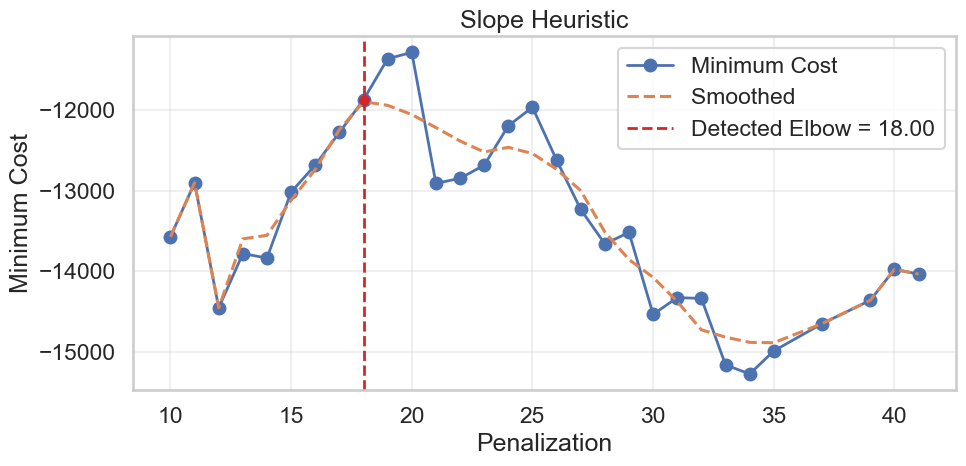

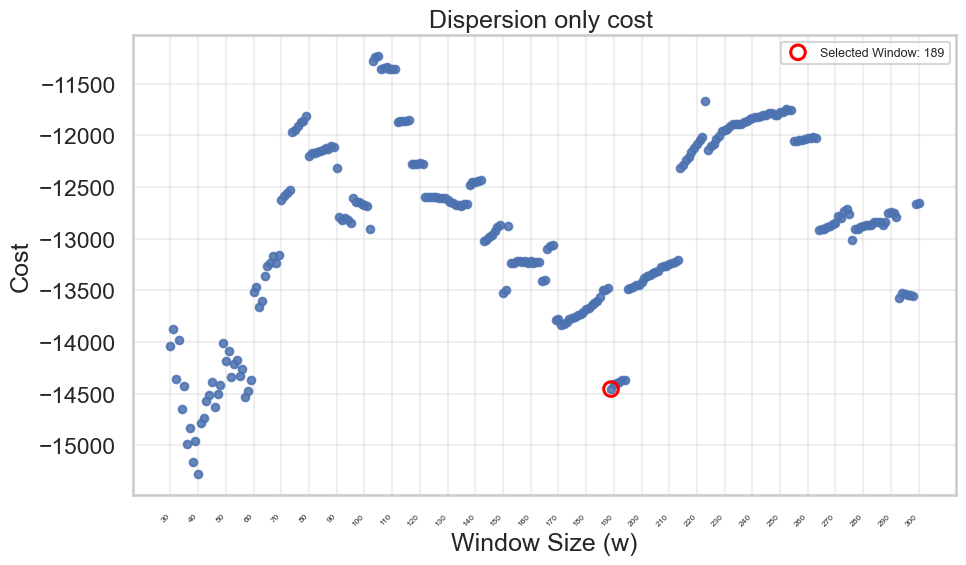

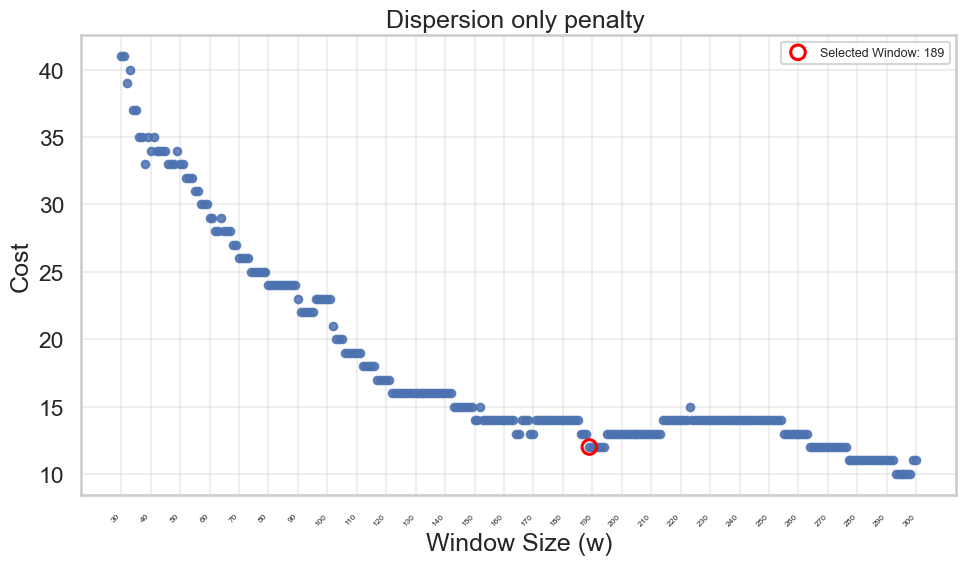

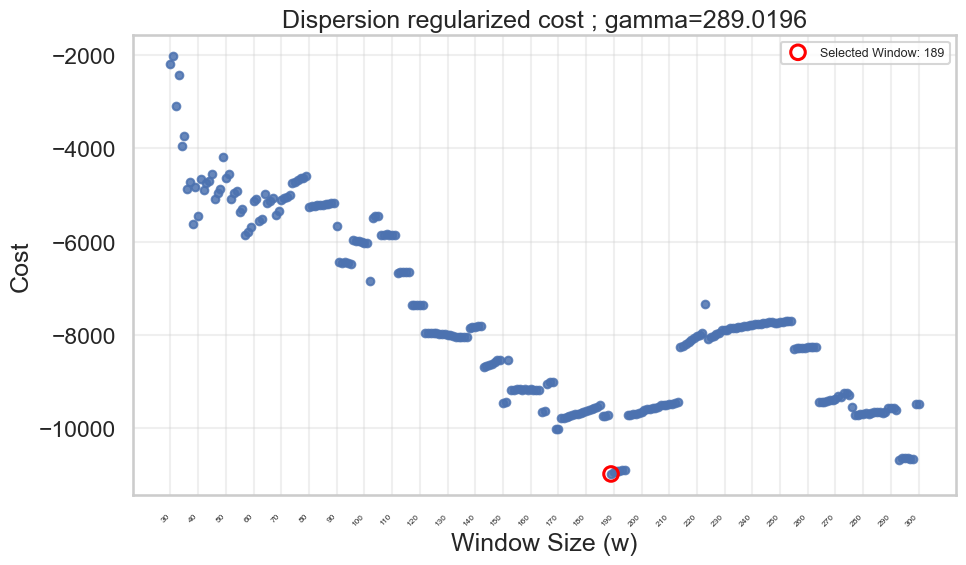

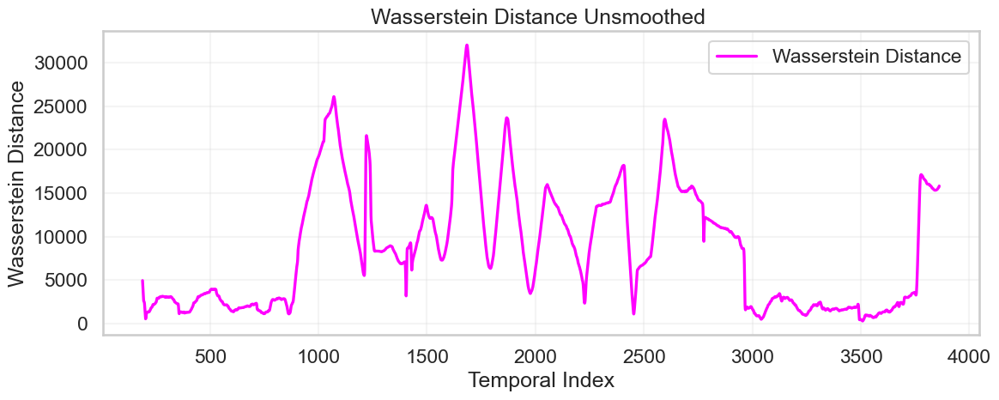

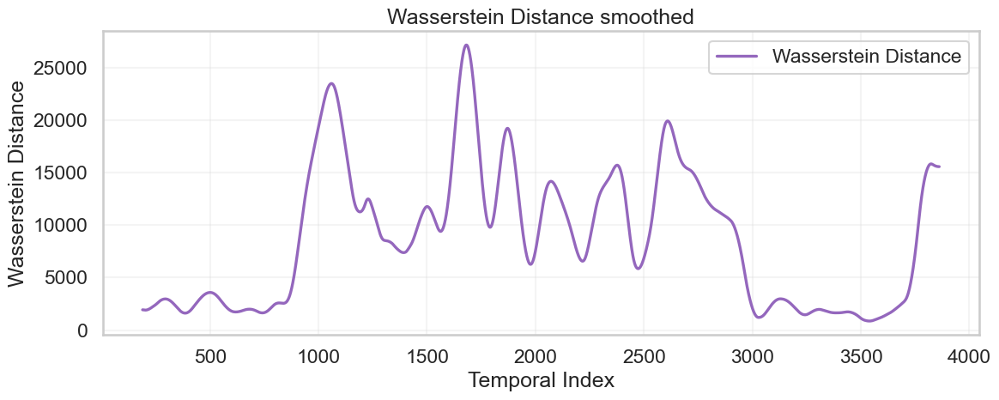

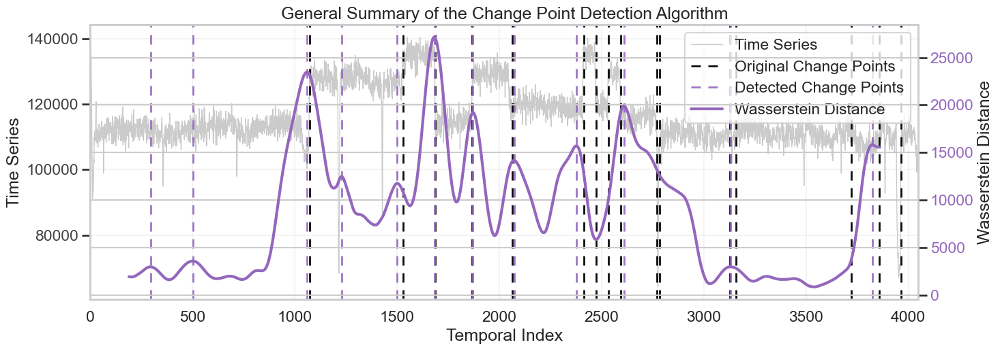

In [54]:
metrics_well_log_gauss_opt = best_params_sh(
                                                                serie_well_log,
                                                                change_points_well_log,
                                                                penal=True,
                                                                path='',
                                                                name=f"Well_Log",
                                                                modo="Gaussiano",
                                                                given=False,
                                                                thr_dist=30,
                                                                min_w = 30,
                                                                max_w = 300,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                save_fig=False,
                                                                visualization={
                                                                    "summary": True,
                                                                    "raw_distance": True,
                                                                    "smooth_distance": True,
                                                                    "cost": True,
                                                                    "slope": True,
                                                                },
                                                                temporal_comp=True,
                                                                max_bandwidth=True)[0]


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 4050
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 21.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 21.0000

Dispersion of Cost
──────────────────
    Execution Time              : 20.1884 s
    Best Window                 : 295

Dispersion of Cost
──────────────────
    Execution Time              : 20.1884 s
    Best Window                 : 295

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 295

Selección final
───

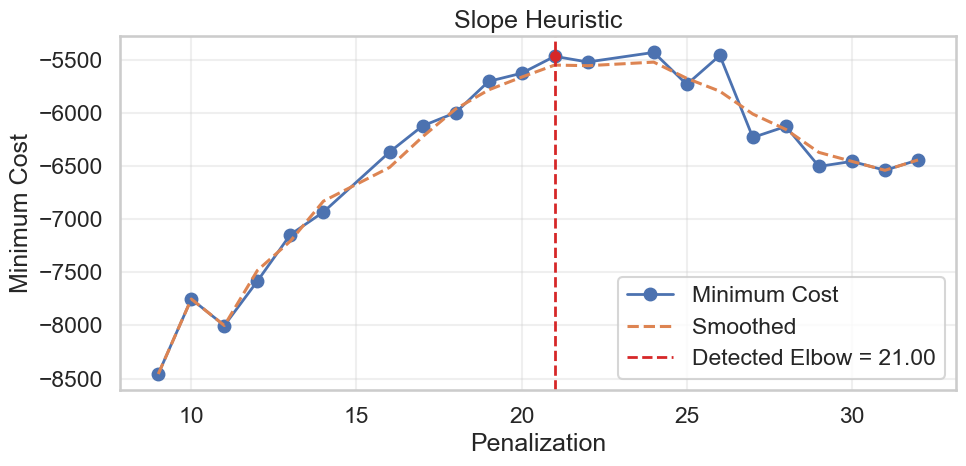

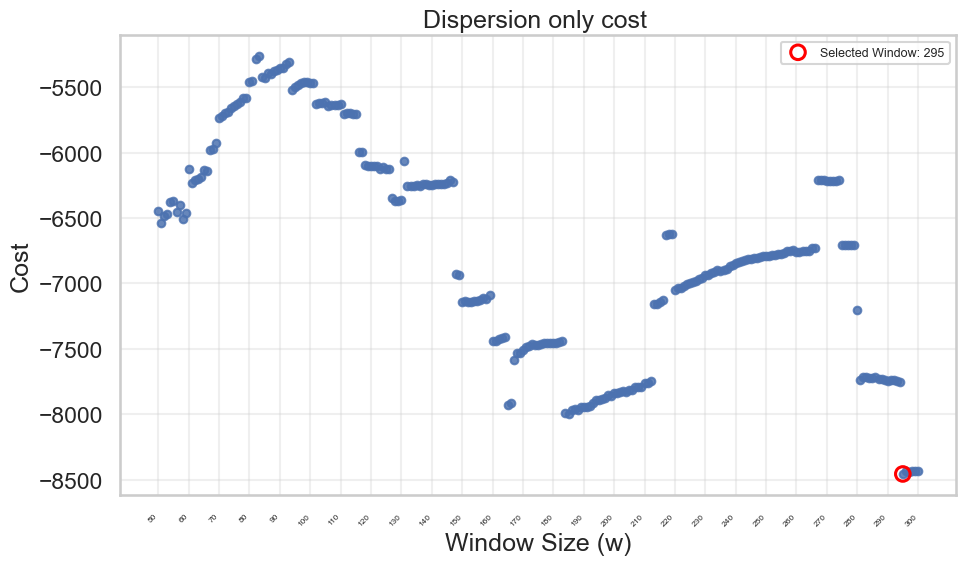

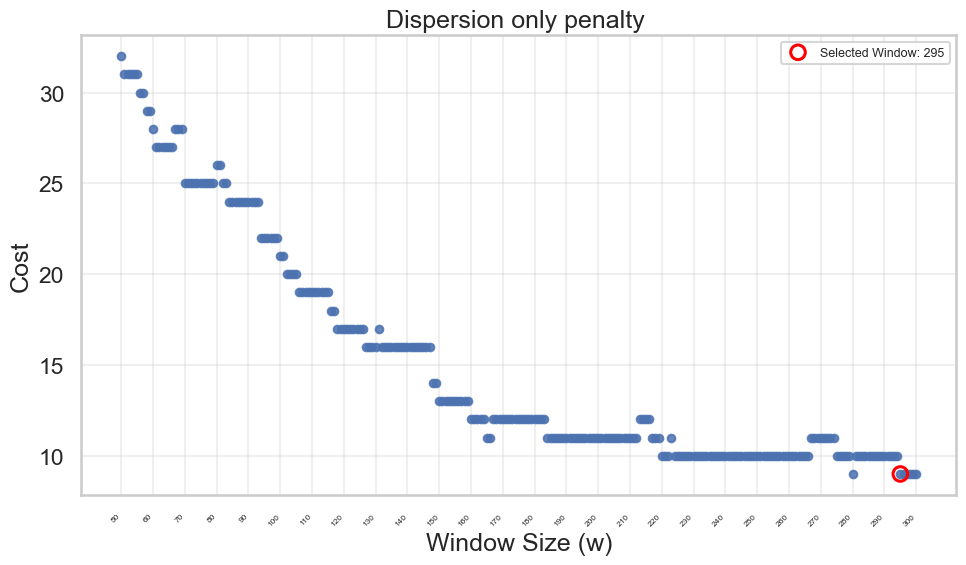

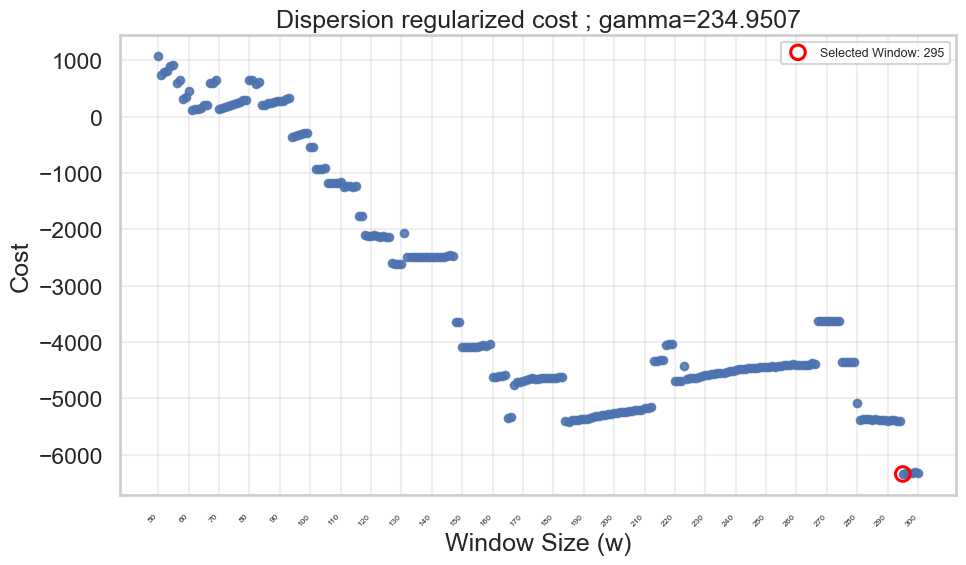

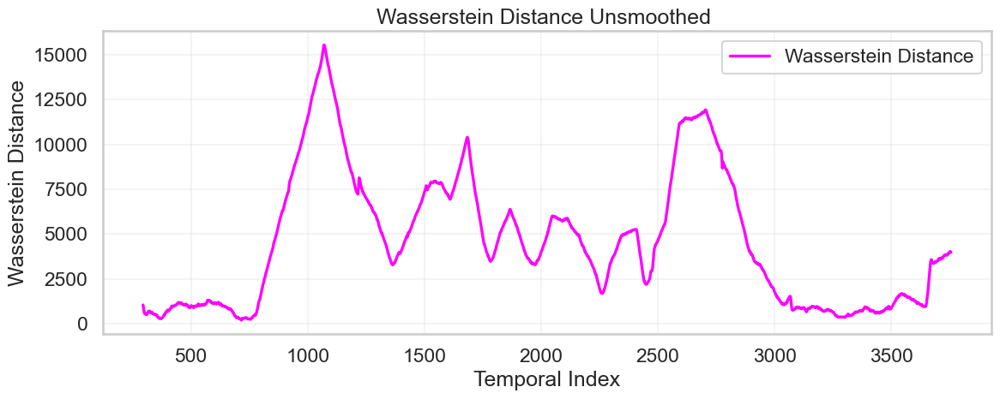

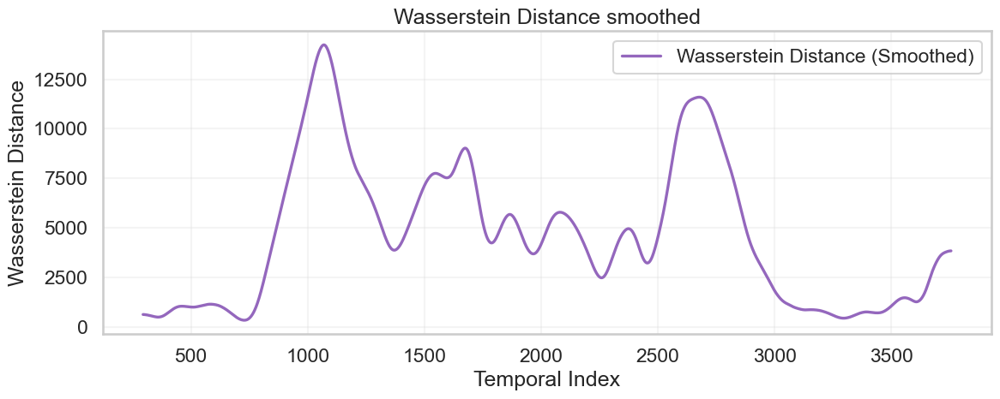

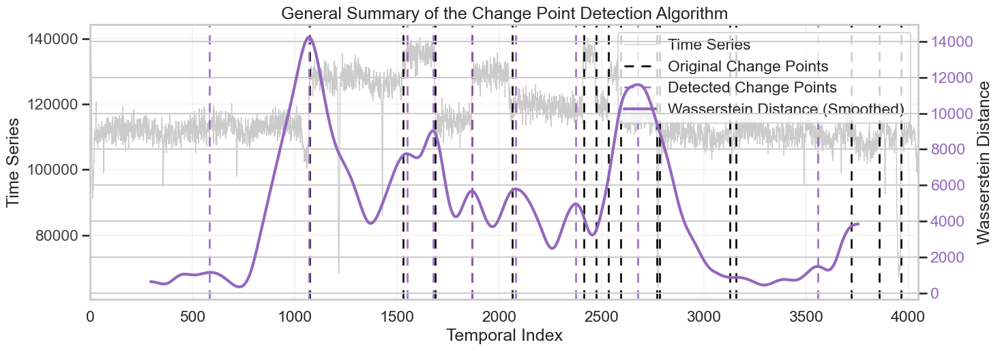

In [55]:
metrics_well_log_emp_opt = best_params_sh(
                                                                serie_well_log,
                                                                change_points_well_log,
                                                                penal=True,
                                                                path='',
                                                                name=f"Well_log",
                                                                modo="Empírico",
                                                                given=False,
                                                                thr_dist=30,
                                                                min_w = 50,
                                                                max_w = 300,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                save_fig=False,
                                                                visualization={
                                                                    "summary": True,
                                                                    "raw_distance": True,
                                                                    "smooth_distance": True,
                                                                    "cost": True,
                                                                    "slope": True,
                                                                },
                                                                temporal_comp=True,
                                                                max_bandwidth=True)[0]

In [56]:
puntos_cambio_roerich_well_log = detectar_cambios_roerich(
                                serie_well_log,
                                window_size=50,
                                seed=42,
                                periods=3
                            )

metrics_well_log_roerich = metrics(change_points_well_log, puntos_cambio_roerich_well_log, 30, len(serie_well_log))[0]

In [57]:
puntos_cambio_window_rbf_well_log = detectar_window_rbf(
                                serie_well_log,
                                window=50
                            )

metrics_well_log_window_rbf = metrics(change_points_well_log, puntos_cambio_window_rbf_well_log, 30, len(serie_well_log))[0]

In [58]:
w=50

cpd_gauss_well_log = CPD(serie_well_log, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
distancias_well_log = cpd_gauss_well_log.distancias()
cps_detect_gauss_well_log_fw = detect(distancias_well_log, w)
metrics_well_log_gauss_fw = metrics(change_points_well_log, cps_detect_gauss_well_log_fw, 30, len(serie_well_log))[0]

w_gauss_opt = 40
cpd_gauss_well_log_opt = CPD(serie_well_log, window=w_gauss_opt, t=1, medias=True, smooth=True, temporal_comp=True)
distancias_well_log_opt = cpd_gauss_well_log_opt.distancias()
cps_detect_gauss_well_log_opt = detect(distancias_well_log_opt, w_gauss_opt)

In [59]:
cpd_emp_well_log = EmpiricalCPD(serie_well_log, window=w, smooth=True)
distancias_well_log_emp = cpd_emp_well_log.distancias()
cps_detect_emp_well_log_fw = detect(distancias_well_log_emp, w)
metrics_well_log_emp_fw = metrics(change_points_well_log, cps_detect_emp_well_log_fw, 30, len(serie_well_log))[0]

w_emp_opt = 295
cpd_emp_well_log_opt = EmpiricalCPD(serie_well_log, window=w_emp_opt, smooth=True)
distancias_well_log_emp_opt = cpd_emp_well_log_opt.distancias()
cps_detect_emp_well_log_opt = detect(distancias_well_log_emp_opt, w_emp_opt)

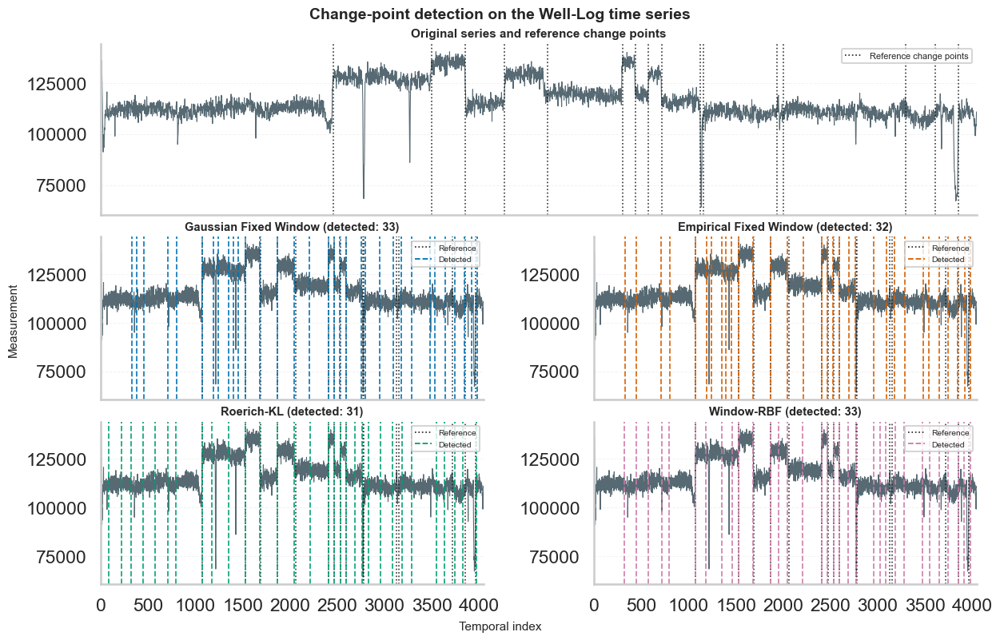

In [65]:
detected_cps = [
    cps_detect_gauss_well_log_fw,
    cps_detect_emp_well_log_fw,
    puntos_cambio_roerich_well_log,
    puntos_cambio_window_rbf_well_log
]

method_names = [
    "Gaussian Fixed Window",
    "Empirical Fixed Window",
    "Roerich-KL",
    "Window-RBF"
]

fig, axes = plot_change_points_by_method(
    serie=serie_well_log,
    reference_change_points=change_points_well_log,
    detected_change_points=detected_cps,
    method_names=method_names,
    title="Change-point detection on the Well-Log time series",
    ylabel="Measurement",
    index_base=0
)

#### Tabla Promedios

In [63]:
avg_table = generar_tabla_desde_diccionarios(
                                            [[metrics_well_log_gauss_fw], [metrics_well_log_emp_fw], 
                                            [metrics_well_log_roerich], [metrics_well_log_window_rbf]],
                                            ["Gauss-FW", "Empirical-FW", 
                                            "Roerich-KL", "Window-RBF"],
                                            ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                        )

avg_table

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss-FW,0.484848,1.000,0.653061,10.312500
1,Empirical-FW,0.437500,0.875,0.583333,7.857143
2,Roerich-KL,0.451613,0.875,0.595745,8.714286
3,Window-RBF,0.424242,0.875,0.571429,7.714286


In [64]:
ruta_log_well = f"Resultados_Datos_Reales/Resultados_log_well/log_well_metrics.xlsx"

avg_table.to_excel(ruta_log_well, index=False)